In [1]:
import pandas as pd

# Read the original CSV file
df = pd.read_csv(
    "Data_SA_Coober Pedy - Hot Dry Summer, Cool Winter_2023-2024_partial.csv"
)

# Display the first 5 rows
display(df.head())


,timestamp,irradiance_W/m^2,temperature_C,solar_output_kW,commercial_forecasted_solar_output_kW,load_kW,spot_price_AUD/kWh,tariff_import_flat_AUD/kWh,tariff_export_flat_AUD/kWh,tariff_import_tou_AUD/kWh,tariff_export_tou_AUD/kWh
0,2023-01-01 00:00:00,0.0,26.8,0.0,NaN,0.43,0.08292,0.3,0.05,0.15,0.05
1,2023-01-01 00:05:00,0.0,26.7,0.0,NaN,0.29,0.12757,0.3,0.05,0.15,0.05
2,2023-01-01 00:10:00,0.0,26.7,0.0,NaN,0.29,0.12285,0.3,0.05,0.15,0.05
3,2023-01-01 00:15:00,0.0,26.6,0.0,NaN,0.31,0.11114,0.3,0.05,0.15,0.05
4,2023-01-01 00:20:00,0.0,26.6,0.0,NaN,0.36,0.11025,0.3,0.05,0.15,0.05


In [2]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nColumn information:")
df.info()


Dataset shape: (210528, 11)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 11 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   timestamp                              210528 non-null  object 
 1   irradiance_W/m^2                       209480 non-null  float64
 2   temperature_C                          209480 non-null  float64
 3   solar_output_kW                        104407 non-null  float64
 4   commercial_forecasted_solar_output_kW  105408 non-null  float64
 5   load_kW                                209480 non-null  float64
 6   spot_price_AUD/kWh                     105120 non-null  float64
 7   tariff_import_flat_AUD/kWh             210528 non-null  float64
 8   tariff_export_flat_AUD/kWh             210528 non-null  float64
 9   tariff_import_tou_AUD/kWh              210528 non-null  float64
 10  tariff_

In [3]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Check time range
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

# Check records by year
print("\nRecords by year:")
print(df["timestamp"].dt.year.value_counts().sort_index())

# Check sampling intervals
print("\nSampling intervals:")
print(df["timestamp"].diff().value_counts().head())


Start: 2023-01-01 00:00:00
End: 2024-12-31 23:55:00

Records by year:
timestamp
2023    105120
2024    105408
Name: count, dtype: int64

Sampling intervals:
timestamp
0 days 00:05:00    210527
Name: count, dtype: int64


In [4]:
# Check duplicate timestamps
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

# Check missing timestamps
expected_time = pd.date_range(
    start=df["timestamp"].min(),
    end=df["timestamp"].max(),
    freq="5min"
)

missing_time = expected_time.difference(df["timestamp"])

print("Missing timestamps:", len(missing_time))


Duplicate timestamps: 0
Missing timestamps: 0


In [5]:
# Check missing values
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing (%)": missing_percent.round(2)
})

display(missing_summary)


,Missing Count,Missing (%)
timestamp,0,0.00
irradiance_W/m^2,1048,0.50
temperature_C,1048,0.50
solar_output_kW,106121,50.41
commercial_forecasted_solar_output_kW,105120,49.93
load_kW,1048,0.50
spot_price_AUD/kWh,105408,50.07
tariff_import_flat_AUD/kWh,0,0.00
tariff_export_flat_AUD/kWh,0,0.00
tariff_import_tou_AUD/kWh,0,0.00


In [6]:
# Check missing values by year
missing_by_year = df.groupby(df["timestamp"].dt.year).apply(
    lambda x: x.isna().sum()
)

display(missing_by_year)


,timestamp,irradiance_W/m^2,temperature_C,solar_output_kW,commercial_forecasted_solar_output_kW,load_kW,spot_price_AUD/kWh,tariff_import_flat_AUD/kWh,tariff_export_flat_AUD/kWh,tariff_import_tou_AUD/kWh,tariff_export_tou_AUD/kWh
timestamp,,,,,,,,,,,
2023,0,713,713,713,105120,713,0,0,0,0,0
2024,0,335,335,105408,0,335,105408,0,0,0,0


In [7]:
# Identify consecutive missing periods
missing = df["load_kW"].isna()
groups = (missing != missing.shift()).cumsum()

missing_periods = (
    df[missing]
    .groupby(groups[missing])
    .agg(
        Start=("timestamp", "min"),
        End=("timestamp", "max"),
        Records=("timestamp", "size")
    )
)

missing_periods["Duration (min)"] = missing_periods["Records"] * 5

print("Number of missing periods:", len(missing_periods))
display(missing_periods.sort_values("Records", ascending=False).head(10))


Number of missing periods: 28


,Start,End,Records,Duration (min)
load_kW,,,,
16,2023-06-09 03:00:00,2023-06-10 02:55:00,288,1440
34,2023-11-19 23:05:00,2023-11-20 04:15:00,63,315
44,2024-03-09 12:50:00,2024-03-09 17:50:00,61,305
54,2024-11-29 10:00:00,2024-11-29 14:40:00,57,285
48,2024-06-05 23:05:00,2024-06-06 03:20:00,52,260
10,2023-03-23 01:05:00,2023-03-23 05:05:00,49,245
28,2023-10-16 13:50:00,2023-10-16 17:50:00,49,245
56,2024-12-19 17:40:00,2024-12-19 21:40:00,49,245
30,2023-11-04 22:30:00,2023-11-05 00:25:00,24,120


In [8]:
# Check basic data ranges
columns = [
    "irradiance_W/m^2",
    "temperature_C",
    "solar_output_kW",
    "commercial_forecasted_solar_output_kW",
    "load_kW",
    "spot_price_AUD/kWh"
]

display(df[columns].describe().round(2))


,irradiance_W/m^2,temperature_C,solar_output_kW,commercial_forecasted_solar_output_kW,load_kW,spot_price_AUD/kWh
count,209480.00,209480.00,104407.00,105408.00,209480.00,105120.00
mean,246.86,21.61,1.92,1.95,1.09,0.08
std,327.90,8.78,2.58,2.56,1.06,0.40
min,0.00,-0.60,0.00,0.00,0.15,-1.00
25%,0.00,14.80,0.00,0.00,0.45,0.00
50%,24.00,21.20,0.20,0.19,0.63,0.06
75%,487.00,28.00,3.72,3.89,1.12,0.12
max,1121.00,45.20,11.54,8.80,6.37,16.60


In [9]:
# Check potentially invalid values
invalid_checks = {
    "Negative irradiance": (df["irradiance_W/m^2"] < 0).sum(),
    "Negative PV": (df["solar_output_kW"] < 0).sum(),
    "Negative PV forecast": (df["commercial_forecasted_solar_output_kW"] < 0).sum(),
    "Negative load": (df["load_kW"] < 0).sum(),
    "Temperature below -20 C": (df["temperature_C"] < -20).sum(),
    "Temperature above 60 C": (df["temperature_C"] > 60).sum(),
    "PV output when irradiance is zero": (
        (df["irradiance_W/m^2"] == 0) &
        (df["solar_output_kW"] > 0.1)
    ).sum()
}

display(pd.Series(invalid_checks, name="Count"))

Negative irradiance                  0
Negative PV                          0
Negative PV forecast                 0
Negative load                        0
Temperature below -20 C              0
Temperature above 60 C               0
PV output when irradiance is zero    0
Name: Count, dtype: int64

In [10]:
# Check wholesale price distribution
price = df["spot_price_AUD/kWh"].dropna()

price_checks = {
    "Negative price": (price < 0).sum(),
    "Zero price": (price == 0).sum(),
    "Price above 1 AUD/kWh": (price > 1).sum(),
    "Price above 5 AUD/kWh": (price > 5).sum(),
    "Price above 10 AUD/kWh": (price > 10).sum()
}

display(pd.Series(price_checks, name="Count"))


Negative price            25929
Zero price                  718
Price above 1 AUD/kWh       228
Price above 5 AUD/kWh        93
Price above 10 AUD/kWh       58
Name: Count, dtype: int64

In [11]:
# Check Flat and ToU tariff values
tariff_columns = [
    "tariff_import_flat_AUD/kWh",
    "tariff_export_flat_AUD/kWh",
    "tariff_import_tou_AUD/kWh",
    "tariff_export_tou_AUD/kWh"
]

for col in tariff_columns:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())



tariff_import_flat_AUD/kWh
tariff_import_flat_AUD/kWh
0.3    210528
Name: count, dtype: int64

tariff_export_flat_AUD/kWh
tariff_export_flat_AUD/kWh
0.05    210528
Name: count, dtype: int64

tariff_import_tou_AUD/kWh
tariff_import_tou_AUD/kWh
0.15     70176
0.25    105264
0.40     35088
Name: count, dtype: int64

tariff_export_tou_AUD/kWh
tariff_export_tou_AUD/kWh
0.05    210528
Name: count, dtype: int64


In [12]:
# Check ToU tariff by hour
df["hour"] = df["timestamp"].dt.hour

tou_by_hour = pd.crosstab(
    df["hour"],
    df["tariff_import_tou_AUD/kWh"]
)

display(tou_by_hour)


tariff_import_tou_AUD/kWh,0.15,0.25,0.40
hour,,,
0,8772,0,0
1,8772,0,0
2,8772,0,0
3,8772,0,0
4,8772,0,0
5,8772,0,0
6,8772,0,0
7,0,8772,0
8,0,8772,0


In [13]:
# Check whether missing values occur together
check_cols = [
    "irradiance_W/m^2",
    "temperature_C",
    "load_kW"
]

missing_pattern = df[check_cols].isna()

print("Rows with all three values missing:",
      missing_pattern.all(axis=1).sum())

print("Rows with only some values missing:",
      (missing_pattern.any(axis=1) &
       ~missing_pattern.all(axis=1)).sum())


Rows with all three values missing: 1048
Rows with only some values missing: 0


In [14]:
# Create a copy for data cleaning
df_clean = df.copy()

# Save original missing-value locations
missing_mask = df_clean["load_kW"].isna()

print("Original records:", len(df))
print("Cleaning copy records:", len(df_clean))
print("Missing records to process:", missing_mask.sum())


Original records: 210528
Cleaning copy records: 210528
Missing records to process: 1048


In [15]:
# Classify missing periods by duration
short_periods = missing_periods[missing_periods["Records"] <= 3]
long_periods = missing_periods[missing_periods["Records"] > 3]

print("Short missing periods (<= 15 min):", len(short_periods))
print("Long missing periods (> 15 min):", len(long_periods))

print("Records in short periods:", short_periods["Records"].sum())
print("Records in long periods:", long_periods["Records"].sum())


Short missing periods (<= 15 min): 0
Long missing periods (> 15 min): 28
Records in short periods: 0
Records in long periods: 1048


In [16]:
# Fill missing load using similar historical time periods
time = df_clean["timestamp"]

load_reference = df_clean.groupby([
    time.dt.year,
    time.dt.month,
    time.dt.dayofweek,
    time.dt.hour,
    time.dt.minute
])["load_kW"].transform("median")

df_clean["load_kW"] = df_clean["load_kW"].fillna(load_reference)

print("Remaining missing Load:", df_clean["load_kW"].isna().sum())
print("Filled Load records:",
      missing_mask.sum() - df_clean["load_kW"].isna().sum())


Remaining missing Load: 0
Filled Load records: 1048


In [17]:
# Read historical weather data from Open-Meteo
weather = pd.read_csv(
    "open-meteo-29.00S134.75E220m.csv",
    skiprows=3
)

# Convert time to datetime
weather["time"] = pd.to_datetime(weather["time"])

# Display first 5 rows
display(weather.head())


,time,temperature_2m (°C),shortwave_radiation (W/m²)
0,2023-01-01 00:00:00,30.3,0.0
1,2023-01-01 01:00:00,29.6,0.0
2,2023-01-01 02:00:00,28.1,0.0
3,2023-01-01 03:00:00,27.7,0.0
4,2023-01-01 04:00:00,26.8,0.0


In [18]:
# Match hourly weather data with original measurements
temp_compare = df[
    (df["timestamp"].dt.minute == 0) &
    df["temperature_C"].notna()
][["timestamp", "temperature_C"]].merge(
    weather[["time", "temperature_2m (°C)"]],
    left_on="timestamp",
    right_on="time",
    how="inner"
)

# Calculate temperature differences
temp_compare["Error"] = (
    temp_compare["temperature_2m (°C)"] -
    temp_compare["temperature_C"]
)

print("Matched records:", len(temp_compare))
print("MAE (°C):", round(temp_compare["Error"].abs().mean(), 2))
print("Mean Bias (°C):", round(temp_compare["Error"].mean(), 2))

display(temp_compare.head())


Matched records: 17455
MAE (°C): 1.22
Mean Bias (°C): -0.2


,timestamp,temperature_C,time,temperature_2m (°C),Error
0,2023-01-01 00:00:00,26.8,2023-01-01 00:00:00,30.3,3.5
1,2023-01-01 01:00:00,26.1,2023-01-01 01:00:00,29.6,3.5
2,2023-01-01 02:00:00,25.5,2023-01-01 02:00:00,28.1,2.6
3,2023-01-01 03:00:00,25.1,2023-01-01 03:00:00,27.7,2.6
4,2023-01-01 04:00:00,24.7,2023-01-01 04:00:00,26.8,2.1


In [19]:
# Test possible time offsets (-6 to +6 hours)
offset_results = []

for offset in range(-6, 7):
    shifted_weather = weather[["time", "temperature_2m (°C)"]].copy()
    shifted_weather["time"] += pd.Timedelta(hours=offset)

    comparison = temp_compare[["timestamp", "temperature_C"]].merge(
        shifted_weather,
        left_on="timestamp",
        right_on="time",
        how="inner"
    )

    error = comparison["temperature_2m (°C)"] - comparison["temperature_C"]

    offset_results.append({
        "Offset (hours)": offset,
        "MAE (°C)": round(error.abs().mean(), 3),
        "Matched": len(comparison)
    })

offset_df = pd.DataFrame(offset_results)
display(offset_df)

print("\nLowest MAE:")
display(offset_df.loc[[offset_df["MAE (°C)"].idxmin()]])


,Offset (hours),MAE (°C),Matched
0,-6,5.281,17449
1,-5,4.429,17450
2,-4,3.500,17451
3,-3,2.523,17452
4,-2,1.546,17453
5,-1,0.814,17454
6,0,1.222,17455
7,1,2.133,17454
8,2,3.109,17453
9,3,4.047,17452



Lowest MAE:


,Offset (hours),MAE (°C),Matched
5,-1,0.814,17454


In [20]:
# Compare temperature offsets by season
offset_season_results = []

for period, months in {
    "Daylight Saving": [1, 2, 3, 11, 12],
    "Standard Time": [5, 6, 7, 8, 9]
}.items():
    for offset in range(-3, 4):
        shifted = weather[["time", "temperature_2m (°C)"]].copy()
        shifted["time"] += pd.Timedelta(hours=offset)

        comparison = temp_compare[
            temp_compare["timestamp"].dt.month.isin(months)
        ][["timestamp", "temperature_C"]].merge(
            shifted,
            left_on="timestamp",
            right_on="time",
            how="inner"
        )

        error = comparison["temperature_2m (°C)"] - comparison["temperature_C"]

        offset_season_results.append({
            "Period": period,
            "Offset (hours)": offset,
            "MAE (°C)": round(error.abs().mean(), 3)
        })

display(pd.DataFrame(offset_season_results).pivot(
    index="Offset (hours)",
    columns="Period",
    values="MAE (°C)"
))


Period,Daylight Saving,Standard Time
Offset (hours),,
-3,2.563,2.488
-2,1.567,1.551
-1,0.867,0.792
0,1.315,1.130
1,2.257,1.981
2,3.262,2.906
3,4.228,3.803


In [21]:
import numpy as np

# Prepare Open-Meteo temperature data
weather_temp = weather[["time", "temperature_2m (°C)"]].copy()

# Apply the selected -1 hour offset
weather_temp["time"] -= pd.Timedelta(hours=1)

# Convert hourly temperature to 5-minute resolution
weather_5min = (
    weather_temp
    .set_index("time")["temperature_2m (°C)"]
    .resample("5min")
    .interpolate(method="time")
)

print("Weather data prepared:", len(weather_5min))


Weather data prepared: 210517


In [22]:
# Select test periods matching the actual missing periods
test_periods = []
available = df["temperature_C"].notna().copy()

for _, period in missing_periods.iterrows():
    n = int(period["Records"])
    month = period["Start"].month
    year = period["Start"].year

    candidates = df.index[
        (df["timestamp"].dt.year == year) &
        (df["timestamp"].dt.month == month) &
        (df["timestamp"].dt.hour == period["Start"].hour) &
        (df["timestamp"].dt.minute == period["Start"].minute)
    ]

    for start in candidates:
        end = start + n
        if end <= len(df) and available.iloc[start:end].all():
            test_periods.extend(range(start, end))
            available.iloc[start:end] = False
            break

test_periods = sorted(test_periods)

print("Actual missing records:", missing_mask.sum())
print("Selected test records:", len(test_periods))
print("Selected test periods:", len(set(test_periods)) > 0)



Actual missing records: 1048
Selected test records: 1048
Selected test periods: True


In [23]:
# Hide selected test temperatures
simulation = df[["timestamp", "temperature_C"]].copy()
simulation.loc[test_periods, "temperature_C"] = np.nan

# Estimate temperatures using historical median
t = simulation["timestamp"]

median_values = simulation.groupby([
    t.dt.year, t.dt.month, t.dt.dayofweek,
    t.dt.hour, t.dt.minute
])["temperature_C"].transform("median")

# Compare estimates with actual measurements
simulation_results = df.loc[
    test_periods, ["timestamp", "temperature_C"]
].copy()

simulation_results["Median"] = median_values.loc[test_periods].values
simulation_results["OpenMeteo"] = weather_5min.reindex(
    simulation_results["timestamp"]
).values

print("Test records:", len(simulation_results))
print("\nMissing estimates:")
print(simulation_results[["Median", "OpenMeteo"]].isna().sum())


Test records: 1048

Missing estimates:
Median       0
OpenMeteo    0
dtype: int64


In [24]:
# Calculate errors for both methods
comparison_results = []

for method in ["Median", "OpenMeteo"]:
    error = simulation_results[method] - simulation_results["temperature_C"]

    comparison_results.append({
        "Method": method,
        "MAE (°C)": round(error.abs().mean(), 3),
        "RMSE (°C)": round(np.sqrt((error ** 2).mean()), 3),
        "Mean Bias (°C)": round(error.mean(), 3)
    })

display(pd.DataFrame(comparison_results))


,Method,MAE (°C),RMSE (°C),Mean Bias (°C)
0,Median,4.642,5.419,-2.599
1,OpenMeteo,0.947,1.331,-0.301


In [25]:
# Save the original missing-temperature locations
temp_missing = df["temperature_C"].isna()

# Fill only missing temperatures using Open-Meteo
df_clean.loc[temp_missing, "temperature_C"] = (
    weather_5min.reindex(
        df_clean.loc[temp_missing, "timestamp"]
    ).values
)

# Check the results
print("Original missing temperatures:", temp_missing.sum())
print("Remaining missing temperatures:",
      df_clean["temperature_C"].isna().sum())

print("Original measurements unchanged:",
      df_clean.loc[~temp_missing, "temperature_C"].equals(
          df.loc[~temp_missing, "temperature_C"]
      ))


Original missing temperatures: 1048
Remaining missing temperatures: 0
Original measurements unchanged: True


In [26]:
# Compare measured and external irradiance
irr_compare = df[
    (df["timestamp"].dt.minute == 0) &
    df["irradiance_W/m^2"].notna()
][["timestamp", "irradiance_W/m^2"]].merge(
    weather[["time", "shortwave_radiation (W/m²)"]],
    left_on="timestamp",
    right_on="time",
    how="inner"
)

# Calculate errors
irr_error = (
    irr_compare["shortwave_radiation (W/m²)"] -
    irr_compare["irradiance_W/m^2"]
)

print("Matched records:", len(irr_compare))
print("MAE (W/m²):", round(irr_error.abs().mean(), 2))
print("Mean Bias (W/m²):", round(irr_error.mean(), 2))


Matched records: 17455
MAE (W/m²): 72.19
Mean Bias (W/m²): -6.39


In [27]:
# Test irradiance time offsets
irr_offset_results = []

for offset in range(-6, 7):
    shifted = weather[["time", "shortwave_radiation (W/m²)"]].copy()
    shifted["time"] += pd.Timedelta(hours=offset)

    comparison = irr_compare[
        ["timestamp", "irradiance_W/m^2"]
    ].merge(
        shifted,
        left_on="timestamp",
        right_on="time",
        how="inner"
    )

    error = (
        comparison["shortwave_radiation (W/m²)"] -
        comparison["irradiance_W/m^2"]
    )

    irr_offset_results.append({
        "Offset (hours)": offset,
        "MAE (W/m²)": round(error.abs().mean(), 2)
    })

irr_offset_df = pd.DataFrame(irr_offset_results)

display(irr_offset_df)

print("\nLowest MAE:")
display(irr_offset_df.loc[
    [irr_offset_df["MAE (W/m²)"].idxmin()]
])


,Offset (hours),MAE (W/m²)
0,-6,308.98
1,-5,256.72
2,-4,197.89
3,-3,136.11
4,-2,71.97
5,-1,17.45
6,0,72.19
7,1,135.87
8,2,197.42
9,3,256.51



Lowest MAE:


,Offset (hours),MAE (W/m²)
5,-1,17.45


In [28]:
# Create a copy for irradiance testing
irr_test = df[["timestamp", "irradiance_W/m^2"]].copy()

# Hide the same 1,048 records selected in Group 25
irr_test.loc[test_periods, "irradiance_W/m^2"] = np.nan

# Save actual irradiance for validation
irr_actual = df.loc[
    test_periods, ["timestamp", "irradiance_W/m^2"]
].copy()

print("Test records:", len(irr_actual))
print("Simulated missing values:",
      irr_test["irradiance_W/m^2"].isna().sum())
print("Actual values available:",
      irr_actual["irradiance_W/m^2"].notna().sum())


Test records: 1048
Simulated missing values: 2096
Actual values available: 1048


In [29]:
# Estimate irradiance using historical median
t = irr_test["timestamp"]

irr_median = irr_test.groupby([
    t.dt.year, t.dt.month, t.dt.dayofweek,
    t.dt.hour, t.dt.minute
])["irradiance_W/m^2"].transform("median")

# Prepare Open-Meteo irradiance at 5-minute intervals
irr_weather = weather[["time", "shortwave_radiation (W/m²)"]].copy()
irr_weather["time"] -= pd.Timedelta(hours=1)

irr_5min = (
    irr_weather.set_index("time")["shortwave_radiation (W/m²)"]
    .resample("5min")
    .interpolate(method="time")
)

# Save both estimates
irr_actual["Median"] = irr_median.loc[test_periods].values
irr_actual["OpenMeteo"] = irr_5min.reindex(
    irr_actual["timestamp"]
).values

print("Missing estimates:")
print(irr_actual[["Median", "OpenMeteo"]].isna().sum())


Missing estimates:
Median       0
OpenMeteo    0
dtype: int64


In [30]:
# Calculate irradiance estimation errors
irr_results = []

for method in ["Median", "OpenMeteo"]:
    error = irr_actual[method] - irr_actual["irradiance_W/m^2"]

    irr_results.append({
        "Method": method,
        "MAE (W/m²)": round(error.abs().mean(), 2),
        "RMSE (W/m²)": round(np.sqrt((error ** 2).mean()), 2),
        "Mean Bias (W/m²)": round(error.mean(), 2)
    })

display(pd.DataFrame(irr_results))


,Method,MAE (W/m²),RMSE (W/m²),Mean Bias (W/m²)
0,Median,51.92,94.57,-7.19
1,OpenMeteo,12.00,25.51,-8.32


In [31]:
# Save original missing irradiance locations
irr_missing = df["irradiance_W/m^2"].isna()

# Fill missing irradiance using Open-Meteo
df_clean.loc[irr_missing, "irradiance_W/m^2"] = (
    irr_5min.reindex(
        df_clean.loc[irr_missing, "timestamp"]
    ).values
)

# Check the results
print("Original missing irradiance:", irr_missing.sum())
print("Remaining missing irradiance:",
      df_clean["irradiance_W/m^2"].isna().sum())

print("Original measurements unchanged:",
      df_clean.loc[~irr_missing, "irradiance_W/m^2"].equals(
          df.loc[~irr_missing, "irradiance_W/m^2"]
      ))


Original missing irradiance: 1048
Remaining missing irradiance: 0
Original measurements unchanged: True


In [32]:
# Check cleaned data quality
check_cols = ["load_kW", "temperature_C", "irradiance_W/m^2"]

quality_summary = pd.DataFrame({
    "Missing": df_clean[check_cols].isna().sum(),
    "Minimum": df_clean[check_cols].min(),
    "Maximum": df_clean[check_cols].max()
})

display(quality_summary)

# Check physical constraints
print("Negative load:", (df_clean["load_kW"] < 0).sum())
print("Negative irradiance:", (df_clean["irradiance_W/m^2"] < 0).sum())

# Verify original measurements were preserved
for col in check_cols:
    valid = df[col].notna()
    print(col, "unchanged:",
          df_clean.loc[valid, col].equals(df.loc[valid, col]))



,Missing,Minimum,Maximum
load_kW,0,0.15,6.37
temperature_C,0,-0.60,45.20
irradiance_W/m^2,0,0.00,1121.00


Negative load: 0
Negative irradiance: 0
load_kW unchanged: True
temperature_C unchanged: True
irradiance_W/m^2 unchanged: True


In [33]:
# Check remaining missing values in the cleaned dataset
remaining_missing = df_clean.isna().sum()

display(pd.DataFrame({
    "Missing Count": remaining_missing,
    "Missing (%)": (remaining_missing / len(df_clean) * 100).round(2)
}))

print("Total records:", len(df_clean))


,Missing Count,Missing (%)
timestamp,0,0.00
irradiance_W/m^2,0,0.00
temperature_C,0,0.00
solar_output_kW,106121,50.41
commercial_forecasted_solar_output_kW,105120,49.93
load_kW,0,0.00
spot_price_AUD/kWh,105408,50.07
tariff_import_flat_AUD/kWh,0,0.00
tariff_export_flat_AUD/kWh,0,0.00
tariff_import_tou_AUD/kWh,0,0.00


Total records: 210528


In [34]:

# Check missing measured PV records in 2023
pv_missing_2023 = (
    (df_clean["timestamp"].dt.year == 2023) &
    df_clean["solar_output_kW"].isna()
)

print("Missing PV records in 2023:", pv_missing_2023.sum())

# Check available weather data for these records
print("Available irradiance:",
      df_clean.loc[pv_missing_2023, "irradiance_W/m^2"].notna().sum())

print("Available temperature:",
      df_clean.loc[pv_missing_2023, "temperature_C"].notna().sum())

display(df_clean.loc[
    pv_missing_2023,
    ["timestamp", "irradiance_W/m^2", "temperature_C", "solar_output_kW"]
].head())


Missing PV records in 2023: 713
Available irradiance: 713
Available temperature: 713


,timestamp,irradiance_W/m^2,temperature_C,solar_output_kW
7379,2023-01-26 14:55:00,912.166667,38.425000,NaN
7380,2023-01-26 15:00:00,902.000000,38.400000,NaN
7381,2023-01-26 15:05:00,887.083333,38.433333,NaN
7382,2023-01-26 15:10:00,872.166667,38.466667,NaN
7383,2023-01-26 15:15:00,857.250000,38.500000,NaN


In [35]:
# Define the sampling interval
dt = 5 / 60  # hours

# Convert power (kW) to energy (kWh)
df_clean["load_kWh"] = df_clean["load_kW"] * dt
df_clean["solar_kWh"] = df_clean["solar_output_kW"] * dt

# Check conversion
print("Sampling interval:", dt, "hours")
print("Total load energy (kWh):", round(df_clean["load_kWh"].sum(), 2))
print("Measured PV energy (kWh):", round(df_clean["solar_kWh"].sum(), 2))


Sampling interval: 0.08333333333333333 hours
Total load energy (kWh): 19204.91
Measured PV energy (kWh): 16742.1


In [36]:
# Create hourly data for future BESS optimisation
df_hourly = df_clean.set_index("timestamp").resample("1h").agg({
    "load_kWh": "sum",
    "solar_kWh": lambda x: x.sum(min_count=1),
    "temperature_C": "mean",
    "irradiance_W/m^2": "mean"
})

# Convert hourly energy back to average power
df_hourly["load_kW"] = df_hourly["load_kWh"]
df_hourly["solar_kW"] = df_hourly["solar_kWh"]

print("Hourly records:", len(df_hourly))
display(df_hourly.head())


Hourly records: 17544


,load_kWh,solar_kWh,temperature_C,irradiance_W/m^2,load_kW,solar_kW
timestamp,,,,,,
2023-01-01 00:00:00,0.440000,0.0,26.475000,0.0,0.440000,0.0
2023-01-01 01:00:00,0.458333,0.0,25.825000,0.0,0.458333,0.0
2023-01-01 02:00:00,0.864167,0.0,25.316667,0.0,0.864167,0.0
2023-01-01 03:00:00,0.826667,0.0,24.916667,0.0,0.826667,0.0
2023-01-01 04:00:00,0.785833,0.0,24.466667,0.0,0.785833,0.0


In [37]:
# Restore hourly PV data
df_hourly["solar_kWh"] = (
    df_clean.set_index("timestamp")["solar_kWh"]
    .resample("1h").sum(min_count=1)
)
df_hourly["solar_kW"] = df_hourly["solar_kWh"]

# Check energy conservation
for col in ["load_kWh", "solar_kWh"]:
    difference = df_hourly[col].sum() - df_clean[col].sum()
    print(f"{col} difference (kWh): {difference:.6f}")
    assert np.isclose(difference, 0, atol=1e-6)


load_kWh difference (kWh): 0.000000
solar_kWh difference (kWh): 0.000000


In [38]:
# Count valid PV records per hour
pv_count = (
    df_clean.set_index("timestamp")["solar_output_kW"]
    .resample("1h").count()
)

df_hourly["PV_valid_records"] = pv_count
df_hourly["PV_complete"] = pv_count == 12

# Exclude incomplete hourly PV measurements
df_hourly.loc[
    ~df_hourly["PV_complete"],
    ["solar_kWh", "solar_kW"]
] = np.nan


In [39]:
# Summarise hourly PV data completeness by year
pv_availability = df_hourly.groupby(df_hourly.index.year)[
    "PV_complete"
].agg(["sum", "count"])

pv_availability.columns = [
    "Complete PV hours",
    "Total hours"
]

display(pv_availability)

print("Incomplete PV hours:",
      (~df_hourly["PV_complete"]).sum())


,Complete PV hours,Total hours
timestamp,,
2023,8683,8760
2024,0,8784


Incomplete PV hours: 8861


In [40]:
# Calculate annual household electricity consumption
annual_load = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["load_kWh"].sum()

# Display annual results
print("Annual household electricity consumption (kWh):")
display(annual_load.round(2))


Annual household electricity consumption (kWh):


timestamp
2023    9597.81
2024    9607.10
Name: load_kWh, dtype: float64

In [41]:
# Calculate monthly household electricity consumption
monthly_load = df_clean.groupby(
    [df_clean["timestamp"].dt.year,
     df_clean["timestamp"].dt.month]
)["load_kWh"].sum().unstack(0)

# Display monthly results
print("Monthly household electricity consumption (kWh):")
display(monthly_load.round(2))


Monthly household electricity consumption (kWh):


timestamp,2023,2024
timestamp,,
1,592.35,593.56
2,598.91,616.13
3,653.73,649.17
4,525.41,525.41
5,1007.27,1005.98
6,1176.58,1176.79
7,1203.45,1203.03
8,1178.31,1178.31
9,723.40,722.94


In [42]:
# Calculate average load for each hour of the day
daily_load_profile = df_hourly.groupby(
    [df_hourly.index.year, df_hourly.index.hour]
)["load_kWh"].mean().unstack(0)

# Display typical daily load profile
print("Average hourly electricity consumption (kWh):")
display(daily_load_profile.round(3))


Average hourly electricity consumption (kWh):


timestamp,2023,2024
timestamp,,
0,0.655,0.654
1,0.634,0.632
2,0.655,0.656
3,0.649,0.654
4,0.656,0.656
5,0.662,0.661
6,0.699,0.699
7,1.173,1.172
8,1.279,1.273


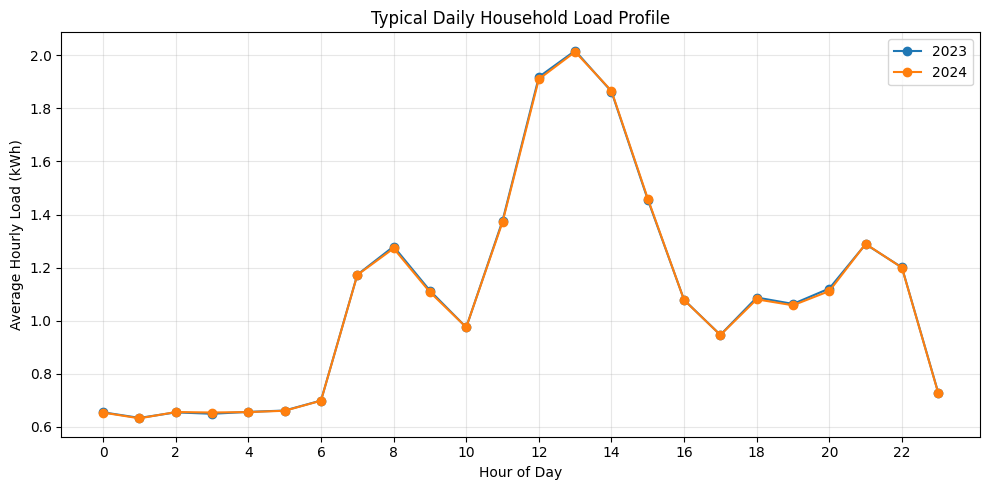

In [43]:
# Plot typical daily load profiles

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(daily_load_profile.index, daily_load_profile[2023],
         label="2023", marker="o")
plt.plot(daily_load_profile.index, daily_load_profile[2024],
         label="2024", marker="o")

# Format the figure
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Load (kWh)")
plt.title("Typical Daily Household Load Profile")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [44]:
# Identify daytime and nighttime periods
df_clean["load_period"] = df_clean["timestamp"].dt.hour.map(
    lambda h: "Daytime" if 6 <= h < 18 else "Nighttime"
)

# Calculate annual daytime and nighttime consumption
day_night_load = df_clean.groupby(
    [df_clean["timestamp"].dt.year, "load_period"]
)["load_kWh"].sum().unstack()

# Display results
print("Annual daytime and nighttime electricity consumption (kWh):")
display(day_night_load.round(2))


Annual daytime and nighttime electricity consumption (kWh):


load_period,Daytime,Nighttime
timestamp,,
2023,5802.09,3795.72
2024,5808.59,3798.51


In [45]:
# Calculate average nighttime electricity consumption
nighttime_daily_load = day_night_load["Nighttime"] / pd.Series({
    2023: 365,
    2024: 366
})

# Display results
print("Average nighttime electricity consumption (kWh/night):")
display(nighttime_daily_load.round(2))


Average nighttime electricity consumption (kWh/night):


timestamp
2023    10.40
2024    10.38
dtype: float64

In [46]:
# Calculate annual peak load
peak_load = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["load_kW"].max()

# Display peak load results
print("Annual peak household demand (kW):")
display(peak_load.round(2))


Annual peak household demand (kW):


timestamp
2023    6.37
2024    6.37
Name: load_kW, dtype: float64

In [47]:
# Find the timestamp of annual peak load
peak_load_times = df_clean.loc[
    df_clean.groupby(
        df_clean["timestamp"].dt.year
    )["load_kW"].idxmax(),
    ["timestamp", "load_kW"]
]

# Display results
print("Annual peak load timestamps:")
display(peak_load_times.reset_index(drop=True))


Annual peak load timestamps:


,timestamp,load_kW
0,2023-08-06 08:45:00,6.37
1,2024-08-06 08:45:00,6.37


In [48]:
# Calculate annual load statistics
load_variability = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["load_kW"].agg(["mean", "std", "median", "max"])

# Calculate high load percentiles
load_variability["P95"] = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["load_kW"].quantile(0.95)

# Display results
print("Household load variability (kW):")
display(load_variability.round(2))


Household load variability (kW):


,mean,std,median,max,P95
timestamp,,,,,
2023,1.10,1.06,0.63,6.37,3.57
2024,1.09,1.06,0.63,6.37,3.57


In [49]:
# Classify missing PV records using irradiance
pv_missing_data = df_clean.loc[
    pv_missing_2023,
    ["timestamp", "irradiance_W/m^2"]
].copy()

pv_missing_data["Period"] = np.where(
    pv_missing_data["irradiance_W/m^2"] > 20,
    "Daytime",
    "Low irradiance"
)

# Display missing PV distribution
print("Missing PV records by period:")
display(pv_missing_data["Period"].value_counts())

print("Maximum irradiance during missing PV records:",
      round(pv_missing_data["irradiance_W/m^2"].max(), 2),
      "W/m²")




Missing PV records by period:


Period
Low irradiance    392
Daytime           321
Name: count, dtype: int64

Maximum irradiance during missing PV records: 916.33 W/m²


In [50]:
# Select valid PV and irradiance measurements
pv_valid = df_clean.loc[
    (df_clean["timestamp"].dt.year == 2023) &
    df_clean["solar_output_kW"].notna() &
    (df_clean["irradiance_W/m^2"] > 20),
    ["solar_output_kW", "irradiance_W/m^2"]
].copy()

# Calculate PV power per unit irradiance
pv_valid["pv_ratio"] = (
    pv_valid["solar_output_kW"] /
    pv_valid["irradiance_W/m^2"]
)

# Display ratio statistics
print("PV power-to-irradiance ratio (kW per W/m²):")
display(pv_valid["pv_ratio"].describe().round(4))


PV power-to-irradiance ratio (kW per W/m²):


count    52731.0000
mean         0.0078
std          0.0013
min          0.0017
25%          0.0074
50%          0.0080
75%          0.0086
max          0.0120
Name: pv_ratio, dtype: float64

In [51]:
# Select measurements with sufficient irradiance
pv_fit = pv_valid[
    pv_valid["irradiance_W/m^2"] > 200
]

# Calculate robust PV estimation coefficient
pv_coefficient = pv_fit["pv_ratio"].median()

# Display results
print("PV estimation coefficient (kW per W/m²):",
      round(pv_coefficient, 6))
print("Number of measurements used:", len(pv_fit))


PV estimation coefficient (kW per W/m²): 0.007924
Number of measurements used: 40065


In [52]:
# Estimate PV power using irradiance
pv_fit = pv_fit.copy()
pv_fit["pv_estimated_kW"] = (
    pv_fit["irradiance_W/m^2"] * pv_coefficient
)

# Calculate estimation errors
pv_mae = (
    pv_fit["solar_output_kW"] - pv_fit["pv_estimated_kW"]
).abs().mean()

pv_rmse = np.sqrt(
    ((pv_fit["solar_output_kW"] - pv_fit["pv_estimated_kW"]) ** 2).mean()
)

# Display results
print("PV estimation MAE (kW):", round(pv_mae, 3))
print("PV estimation RMSE (kW):", round(pv_rmse, 3))


PV estimation MAE (kW): 0.528
PV estimation RMSE (kW): 0.854


In [53]:
# Select independent low-irradiance samples
pv_test = pv_valid[
    pv_valid["irradiance_W/m^2"] <= 200
].copy()

# Estimate PV power
pv_test["pv_estimated_kW"] = (
    pv_test["irradiance_W/m^2"] * pv_coefficient
)

# Calculate validation errors
pv_test_mae = (
    pv_test["solar_output_kW"] - pv_test["pv_estimated_kW"]
).abs().mean()

pv_test_rmse = np.sqrt(
    ((pv_test["solar_output_kW"] - pv_test["pv_estimated_kW"]) ** 2).mean()
)

# Display results
print("Low-irradiance validation samples:", len(pv_test))
print("Validation MAE (kW):", round(pv_test_mae, 3))
print("Validation RMSE (kW):", round(pv_test_rmse, 3))


Low-irradiance validation samples: 12666
Validation MAE (kW): 0.085
Validation RMSE (kW): 0.144


In [54]:
# Split high-irradiance measurements into training and test sets
pv_train = pv_fit.iloc[::2].copy()
pv_high_test = pv_fit.iloc[1::2].copy()

# Calculate coefficient from training samples only
pv_coefficient_validated = pv_train["pv_ratio"].median()

# Estimate PV power on test samples
pv_high_test["pv_estimated_kW"] = (
    pv_high_test["irradiance_W/m^2"] * pv_coefficient_validated
)

# Calculate validation errors
pv_high_mae = (
    pv_high_test["solar_output_kW"] - pv_high_test["pv_estimated_kW"]
).abs().mean()

pv_high_rmse = np.sqrt(
    ((pv_high_test["solar_output_kW"] - pv_high_test["pv_estimated_kW"]) ** 2).mean()
)

# Display results
print("High-irradiance validation samples:", len(pv_high_test))
print("Validation MAE (kW):", round(pv_high_mae, 3))
print("Validation RMSE (kW):", round(pv_high_rmse, 3))


High-irradiance validation samples: 20032
Validation MAE (kW): 0.53
Validation RMSE (kW): 0.861


In [55]:
# Identify missing PV records in 2023
pv_missing_mask = (
    (df_clean["timestamp"].dt.year == 2023) &
    df_clean["solar_output_kW"].isna()
)

# Identify consecutive missing periods
pv_gap_id = pv_missing_mask.ne(
    pv_missing_mask.shift()
).cumsum()

# Calculate missing period durations
pv_gaps = df_clean.loc[pv_missing_mask].groupby(
    pv_gap_id[pv_missing_mask]
).agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    records=("timestamp", "count")
)

pv_gaps["duration_min"] = pv_gaps["records"] * 5

# Display results
print("Consecutive PV missing periods:")
display(pv_gaps)


Consecutive PV missing periods:


,start,end,records,duration_min
2,2023-01-26 14:55:00,2023-01-26 16:20:00,18,90
4,2023-01-29 12:55:00,2023-01-29 14:15:00,17,85
6,2023-03-10 05:20:00,2023-03-10 06:15:00,12,60
8,2023-03-15 14:30:00,2023-03-15 16:00:00,19,95
10,2023-03-23 01:05:00,2023-03-23 05:05:00,49,245
12,2023-05-20 02:50:00,2023-05-20 04:40:00,23,115
14,2023-05-22 10:25:00,2023-05-22 11:40:00,16,80
16,2023-06-09 03:00:00,2023-06-10 02:55:00,288,1440
18,2023-06-12 22:40:00,2023-06-13 00:35:00,24,120
20,2023-07-09 16:20:00,2023-07-09 18:00:00,21,105


In [56]:
# Calculate daytime missing records for each gap
pv_gap_daytime = df_clean.loc[pv_missing_mask].groupby(
    pv_gap_id[pv_missing_mask]
)["irradiance_W/m^2"].agg(
    daytime_records=lambda x: (x > 20).sum(),
    max_irradiance="max"
)

# Combine with missing gap information
pv_gap_summary = pv_gaps.join(pv_gap_daytime)

# Display results
print("PV missing gaps with daytime information:")
display(pv_gap_summary.round(2))


PV missing gaps with daytime information:


,start,end,records,duration_min,daytime_records,max_irradiance
2,2023-01-26 14:55:00,2023-01-26 16:20:00,18,90,18,912.17
4,2023-01-29 12:55:00,2023-01-29 14:15:00,17,85,17,463.00
6,2023-03-10 05:20:00,2023-03-10 06:15:00,12,60,0,18.25
8,2023-03-15 14:30:00,2023-03-15 16:00:00,19,95,19,827.00
10,2023-03-23 01:05:00,2023-03-23 05:05:00,49,245,0,0.00
12,2023-05-20 02:50:00,2023-05-20 04:40:00,23,115,0,0.00
14,2023-05-22 10:25:00,2023-05-22 11:40:00,16,80,16,567.33
16,2023-06-09 03:00:00,2023-06-10 02:55:00,288,1440,122,573.00
18,2023-06-12 22:40:00,2023-06-13 00:35:00,24,120,0,0.00
20,2023-07-09 16:20:00,2023-07-09 18:00:00,21,105,17,171.67


In [57]:
# Calculate irradiance variability during missing periods
pv_gap_irradiance = df_clean.loc[
    pv_missing_mask &
    (df_clean["irradiance_W/m^2"] > 20)
].groupby(
    pv_gap_id
)["irradiance_W/m^2"].agg(["mean", "std", "min", "max"])

# Display results
print("Irradiance variability during daytime PV gaps:")
display(pv_gap_irradiance.round(2))


Irradiance variability during daytime PV gaps:


,mean,std,min,max
2,788.01,82.01,650.00,912.17
4,328.90,88.63,222.00,463.00
8,711.50,79.74,578.00,827.00
14,506.44,43.20,431.25,567.33
16,304.01,179.19,21.00,573.00
20,85.47,47.09,25.00,171.67
22,549.75,55.71,462.67,634.33
24,282.50,93.42,134.50,430.50
28,557.95,243.97,127.67,916.33
32,549.00,62.03,427.33,639.00


In [58]:
# Get recorded PV power by timestamp
pv_power_series = df_clean.set_index(
    "timestamp"
)["solar_output_kW"]

# Check PV power before and after each missing period
pv_gap_boundaries = pv_gaps[["start", "end"]].copy()

pv_gap_boundaries["before_kW"] = pv_power_series.reindex(
    pv_gap_boundaries["start"] - pd.Timedelta(minutes=5)
).to_numpy()

pv_gap_boundaries["after_kW"] = pv_power_series.reindex(
    pv_gap_boundaries["end"] + pd.Timedelta(minutes=5)
).to_numpy()

# Display results
print("PV power before and after missing periods:")
display(pv_gap_boundaries.round(2))


PV power before and after missing periods:


,start,end,before_kW,after_kW
2,2023-01-26 14:55:00,2023-01-26 16:20:00,7.29,4.38
4,2023-01-29 12:55:00,2023-01-29 14:15:00,2.75,1.93
6,2023-03-10 05:20:00,2023-03-10 06:15:00,0.00,0.22
8,2023-03-15 14:30:00,2023-03-15 16:00:00,5.45,3.48
10,2023-03-23 01:05:00,2023-03-23 05:05:00,0.00,0.00
12,2023-05-20 02:50:00,2023-05-20 04:40:00,0.00,0.00
14,2023-05-22 10:25:00,2023-05-22 11:40:00,4.09,5.19
16,2023-06-09 03:00:00,2023-06-10 02:55:00,0.00,0.00
18,2023-06-12 22:40:00,2023-06-13 00:35:00,0.00,0.00
20,2023-07-09 16:20:00,2023-07-09 18:00:00,1.81,0.02


In [59]:
# Select short PV gaps suitable for interpolation
pv_interp_gaps = [2, 4, 8, 14, 22, 32]

# Generate linear interpolation candidates
pv_interp_series = df_clean["solar_output_kW"].interpolate(
    method="linear",
    limit_area="inside"
)

# Select only the chosen missing periods
pv_interp_mask = (
    pv_missing_mask &
    pv_gap_id.isin(pv_interp_gaps)
)

pv_interp_candidates = df_clean.loc[
    pv_interp_mask, ["timestamp", "irradiance_W/m^2"]
].copy()

pv_interp_candidates["estimated_PV_kW"] = (
    pv_interp_series.loc[pv_interp_mask]
)

# Display results
print("PV interpolation candidate records:", len(pv_interp_candidates))
display(pv_interp_candidates.head(10).round(2))


PV interpolation candidate records: 104


,timestamp,irradiance_W/m^2,estimated_PV_kW
7379,2023-01-26 14:55:00,912.17,7.14
7380,2023-01-26 15:00:00,902.00,6.98
7381,2023-01-26 15:05:00,887.08,6.83
7382,2023-01-26 15:10:00,872.17,6.68
7383,2023-01-26 15:15:00,857.25,6.52
7384,2023-01-26 15:20:00,842.33,6.37
7385,2023-01-26 15:25:00,827.42,6.22
7386,2023-01-26 15:30:00,812.50,6.06
7387,2023-01-26 15:35:00,797.58,5.91
7388,2023-01-26 15:40:00,782.67,5.76


In [60]:
# Calculate irradiance-based reference values
pv_interp_candidates["reference_PV_kW"] = (
    pv_interp_candidates["irradiance_W/m^2"] * pv_coefficient
)

# Compare interpolation with irradiance estimates
pv_interp_candidates["difference_kW"] = (
    pv_interp_candidates["estimated_PV_kW"] -
    pv_interp_candidates["reference_PV_kW"]
)

# Summarise interpolation candidates
pv_interp_check = pv_interp_candidates.groupby(
    pv_gap_id.loc[pv_interp_mask]
)[["estimated_PV_kW", "reference_PV_kW", "difference_kW"]].agg(
    ["mean", "min", "max"]
)

# Display results
print("PV interpolation candidate comparison (kW):")
display(pv_interp_check.round(2))


PV interpolation candidate comparison (kW):


estimated_PV_kW             reference_PV_kW             difference_kW  \
              mean   min   max            mean   min   max          mean   
2             5.84  4.53  7.14            6.24  5.15  7.23         -0.41   
4             2.34  1.98  2.70            2.61  1.76  3.67         -0.27   
8             4.47  3.58  5.35            5.64  4.58  6.55         -1.17   
14            4.64  4.15  5.13            4.01  3.42  4.50          0.63   
22            4.46  3.66  5.26            4.36  3.67  5.03          0.10   
32            4.64  3.19  6.09            4.35  3.39  5.06          0.29   

                
     min   max  
2  -0.62 -0.09  
4  -1.01  0.35  
8  -1.29 -1.00  
14  0.57  0.74  
22 -0.00  0.23  
32 -0.20  1.03

In [61]:
# Select a complete 90-minute PV period
pv_validation = df_clean.loc[
    (df_clean["timestamp"] >= "2023-01-25 14:30:00") &
    (df_clean["timestamp"] <= "2023-01-25 16:10:00"),
    ["timestamp", "solar_output_kW"]
].copy()

# Check availability of validation measurements
print("Validation records:", len(pv_validation))
print("Missing PV measurements:",
      pv_validation["solar_output_kW"].isna().sum())

# Display results
display(pv_validation.head().round(2))


Validation records: 21
Missing PV measurements: 0


,timestamp,solar_output_kW
7086,2023-01-25 14:30:00,6.77
7087,2023-01-25 14:35:00,5.26
7088,2023-01-25 14:40:00,8.42
7089,2023-01-25 14:45:00,8.37
7090,2023-01-25 14:50:00,7.24


In [62]:
# Create a copy for interpolation testing
pv_validation_test = pv_validation.copy()

# Simulate missing PV measurements
pv_validation_test.loc[
    pv_validation_test.index[1:-1],
    "solar_output_kW"
] = np.nan

# Estimate missing PV using linear interpolation
pv_validation_test["interpolated_kW"] = (
    pv_validation_test["solar_output_kW"].interpolate(
        method="linear"
    )
)

# Compare estimated and actual PV power
pv_validation_test["actual_kW"] = pv_validation["solar_output_kW"]

# Display results
print("PV interpolation test results:")
display(pv_validation_test.round(2))


PV interpolation test results:


,timestamp,solar_output_kW,interpolated_kW,actual_kW
7086,2023-01-25 14:30:00,6.77,6.77,6.77
7087,2023-01-25 14:35:00,NaN,6.73,5.26
7088,2023-01-25 14:40:00,NaN,6.70,8.42
7089,2023-01-25 14:45:00,NaN,6.66,8.37
7090,2023-01-25 14:50:00,NaN,6.62,7.24
7091,2023-01-25 14:55:00,NaN,6.59,5.73
7092,2023-01-25 15:00:00,NaN,6.55,7.23
7093,2023-01-25 15:05:00,NaN,6.51,6.13
7094,2023-01-25 15:10:00,NaN,6.48,7.40
7095,2023-01-25 15:15:00,NaN,6.44,6.44


In [63]:
# Select simulated missing records
pv_validation_missing = pv_validation_test.iloc[1:-1]

# Calculate interpolation errors
pv_interp_mae = (
    pv_validation_missing["actual_kW"] -
    pv_validation_missing["interpolated_kW"]
).abs().mean()

pv_interp_rmse = np.sqrt(
    ((pv_validation_missing["actual_kW"] -
      pv_validation_missing["interpolated_kW"]) ** 2).mean()
)

# Display results
print("PV interpolation validation samples:", len(pv_validation_missing))
print("Interpolation MAE (kW):", round(pv_interp_mae, 3))
print("Interpolation RMSE (kW):", round(pv_interp_rmse, 3))


PV interpolation validation samples: 19
Interpolation MAE (kW): 0.649
Interpolation RMSE (kW): 0.811


In [64]:
# Get irradiance for validation records
pv_validation_missing = pv_validation_missing.copy()

pv_validation_missing["irradiance_W/m^2"] = df_clean.loc[
    pv_validation_missing.index, "irradiance_W/m^2"
]

# Estimate PV power using irradiance
pv_validation_missing["irradiance_estimated_kW"] = (
    pv_validation_missing["irradiance_W/m^2"] * pv_coefficient
)

# Compare estimation errors
pv_method_comparison = pd.DataFrame({
    "Method": ["Linear interpolation", "Irradiance estimation"],
    "MAE_kW": [
        pv_interp_mae,
        (pv_validation_missing["actual_kW"] -
         pv_validation_missing["irradiance_estimated_kW"]).abs().mean()
    ],
    "RMSE_kW": [
        pv_interp_rmse,
        np.sqrt(((pv_validation_missing["actual_kW"] -
                  pv_validation_missing["irradiance_estimated_kW"]) ** 2).mean())
    ]
})

# Display results
print("PV estimation method comparison:")
display(pv_method_comparison.round(3))


PV estimation method comparison:


,Method,MAE_kW,RMSE_kW
0,Linear interpolation,0.649,0.811
1,Irradiance estimation,0.619,0.828


In [65]:

# Define PV missing data filling methods
pv_filling_plan = pv_gaps[["start", "end", "records"]].copy()

pv_filling_plan["method"] = "Irradiance estimation"

# Select gaps for linear interpolation
pv_filling_plan.loc[
    pv_filling_plan.index.isin([2, 4, 8, 14, 22, 32]),
    "method"
] = "Linear interpolation"

# Select nighttime gaps
pv_filling_plan.loc[
    pv_filling_plan.index.isin([10, 12, 18, 26, 30, 34]),
    "method"
] = "Zero PV"

# Display results
print("PV missing data filling plan:")
display(pv_filling_plan)


PV missing data filling plan:


,start,end,records,method
2,2023-01-26 14:55:00,2023-01-26 16:20:00,18,Linear interpolation
4,2023-01-29 12:55:00,2023-01-29 14:15:00,17,Linear interpolation
6,2023-03-10 05:20:00,2023-03-10 06:15:00,12,Irradiance estimation
8,2023-03-15 14:30:00,2023-03-15 16:00:00,19,Linear interpolation
10,2023-03-23 01:05:00,2023-03-23 05:05:00,49,Zero PV
12,2023-05-20 02:50:00,2023-05-20 04:40:00,23,Zero PV
14,2023-05-22 10:25:00,2023-05-22 11:40:00,16,Linear interpolation
16,2023-06-09 03:00:00,2023-06-10 02:55:00,288,Irradiance estimation
18,2023-06-12 22:40:00,2023-06-13 00:35:00,24,Zero PV
20,2023-07-09 16:20:00,2023-07-09 18:00:00,21,Irradiance estimation


In [66]:
# Create a separate column for completed PV data
df_clean["solar_filled_kW"] = df_clean["solar_output_kW"].copy()

# Assign filling methods to missing records
pv_fill_method = pv_gap_id.map(pv_filling_plan["method"])

# Fill missing PV using linear interpolation
interp_mask = pv_missing_mask & (pv_fill_method == "Linear interpolation")
df_clean.loc[interp_mask, "solar_filled_kW"] = pv_interp_series.loc[interp_mask]

# Fill missing PV using irradiance estimation
irr_mask = pv_missing_mask & (pv_fill_method == "Irradiance estimation")
df_clean.loc[irr_mask, "solar_filled_kW"] = (
    df_clean.loc[irr_mask, "irradiance_W/m^2"] * pv_coefficient
).clip(lower=0)

# Fill confirmed nighttime missing PV with zero
zero_mask = pv_missing_mask & (pv_fill_method == "Zero PV")
df_clean.loc[zero_mask, "solar_filled_kW"] = 0.0

# Display filling results
print("Linear interpolation:", interp_mask.sum())
print("Irradiance estimation:", irr_mask.sum())
print("Zero PV:", zero_mask.sum())
print("Total filled records:",
      df_clean.loc[pv_missing_mask, "solar_filled_kW"].notna().sum())


Linear interpolation: 104
Irradiance estimation: 404
Zero PV: 205
Total filled records: 713


In [67]:
# Select completed 2023 PV data
pv_2023_filled = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    "solar_filled_kW"
]

# Check missing and invalid values
pv_filling_check = pd.Series({
    "Remaining missing values": pv_2023_filled.isna().sum(),
    "Negative PV values": (pv_2023_filled < 0).sum(),
    "Minimum PV power (kW)": pv_2023_filled.min(),
    "Maximum PV power (kW)": pv_2023_filled.max(),
    "Modified original measurements": (
        df_clean.loc[~pv_missing_mask & (df_clean["timestamp"].dt.year == 2023),
                     "solar_filled_kW"] !=
        df_clean.loc[~pv_missing_mask & (df_clean["timestamp"].dt.year == 2023),
                     "solar_output_kW"]
    ).sum()
})

# Display results
print("PV filling validation:")
display(pv_filling_check.round(2))


PV filling validation:


Remaining missing values           0.00
Negative PV values                 0.00
Minimum PV power (kW)              0.00
Maximum PV power (kW)             11.54
Modified original measurements     0.00
dtype: float64

In [68]:
# Calculate PV generation before and after filling
pv_energy_comparison = pd.Series({
    "Before filling (kWh)": (
        df_clean.loc[df_clean["timestamp"].dt.year == 2023,
                     "solar_output_kW"].sum() / 12
    ),
    "After filling (kWh)": (
        df_clean.loc[df_clean["timestamp"].dt.year == 2023,
                     "solar_filled_kW"].sum() / 12
    )
})

# Calculate additional PV generation
pv_added_energy = (
    pv_energy_comparison["After filling (kWh)"] -
    pv_energy_comparison["Before filling (kWh)"]
)

# Display results
print("2023 PV generation before and after filling:")
display(pv_energy_comparison.round(2))
print("Estimated additional PV generation (kWh):",
      round(pv_added_energy, 2))


2023 PV generation before and after filling:


Before filling (kWh)    16742.10
After filling (kWh)     16827.63
dtype: float64

Estimated additional PV generation (kWh): 85.53


In [69]:
# Update five-minute PV energy using completed data
df_clean["solar_kWh"] = (
    df_clean["solar_filled_kW"] / 12
)

# Check updated annual PV energy
annual_pv_updated = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["solar_kWh"].agg(["sum", "count"])

# Display results
print("Updated annual PV generation (kWh):")
display(annual_pv_updated.round(2))


Updated annual PV generation (kWh):


,sum,count
timestamp,,
2023,16827.63,105120
2024,0.00,0


In [70]:
# Calculate hourly PV generation from completed five-minute data
hourly_pv_updated = df_clean.set_index(
    "timestamp"
)["solar_kWh"].resample("h").sum(min_count=1)

# Update hourly PV energy
df_hourly["solar_kWh"] = hourly_pv_updated.reindex(
    df_hourly.index
)

# Check energy conservation
pv_hourly_check = pd.Series({
    "Five-minute PV energy (kWh)": (
        df_clean.loc[df_clean["timestamp"].dt.year == 2023,
                     "solar_kWh"].sum()
    ),
    "Hourly PV energy (kWh)": (
        df_hourly.loc[df_hourly.index.year == 2023,
                      "solar_kWh"].sum()
    )
})

# Display results
print("2023 PV energy conservation check:")
display(pv_hourly_check.round(2))


2023 PV energy conservation check:


Five-minute PV energy (kWh)    16827.63
Hourly PV energy (kWh)         16827.63
dtype: float64

In [71]:
# Check hourly PV data completeness
pv_hourly_completeness = df_hourly.groupby(
    df_hourly.index.year
)["solar_kWh"].agg(
    ["count", "size"]
)

# Calculate missing hourly records
pv_hourly_completeness["missing"] = (
    pv_hourly_completeness["size"] -
    pv_hourly_completeness["count"]
)

# Display results
print("Hourly PV data completeness:")
display(pv_hourly_completeness)


Hourly PV data completeness:


,count,size,missing
timestamp,,,
2023,8760,8760,0
2024,0,8784,8784


In [72]:
# Calculate monthly PV generation for 2023
monthly_pv = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023
].groupby(
    df_clean["timestamp"].dt.month
)["solar_kWh"].sum()

# Display monthly results
print("2023 monthly PV generation (kWh):")
display(monthly_pv.round(2))


2023 monthly PV generation (kWh):


timestamp
1     1751.74
2     1609.70
3     1502.39
4     1150.98
5     1033.69
6      750.96
7      928.30
8     1144.11
9     1459.58
10    1804.79
11    1783.50
12    1907.90
Name: solar_kWh, dtype: float64

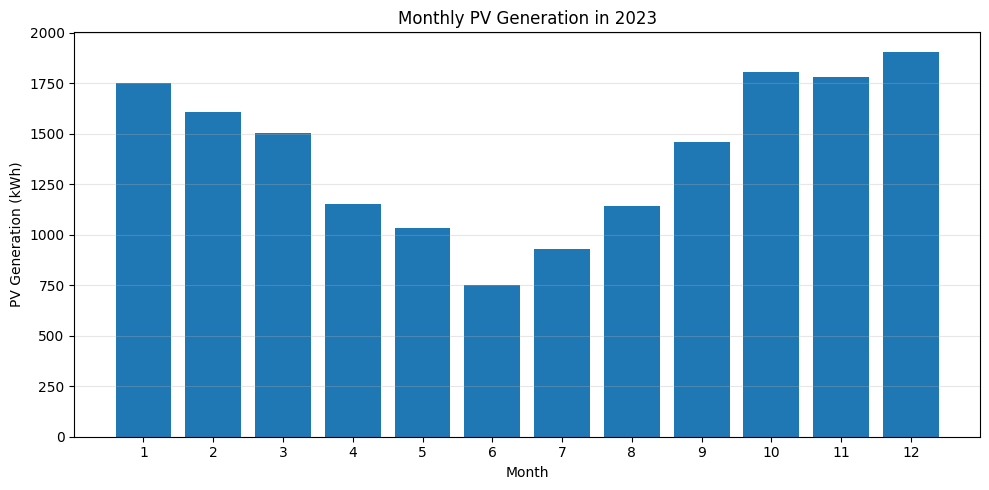

In [73]:
# Plot monthly PV generation
plt.figure(figsize=(10, 5))
plt.bar(monthly_pv.index, monthly_pv.values)

# Format the figure
plt.xlabel("Month")
plt.ylabel("PV Generation (kWh)")
plt.title("Monthly PV Generation in 2023")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [74]:
# Calculate average hourly PV generation for 2023
daily_pv_profile = df_hourly.loc[
    df_hourly.index.year == 2023
].groupby(
    df_hourly.loc[df_hourly.index.year == 2023].index.hour
)["solar_kWh"].mean()

# Display results
print("2023 typical daily PV generation (kWh):")
display(daily_pv_profile.round(2))


2023 typical daily PV generation (kWh):


timestamp
0     0.00
1     0.00
2     0.00
3     0.00
4     0.00
5     0.05
6     0.40
7     1.34
8     2.75
9     4.15
10    5.28
11    5.98
12    6.21
13    5.96
14    5.24
15    4.15
16    2.75
17    1.37
18    0.42
19    0.05
20    0.00
21    0.00
22    0.00
23    0.00
Name: solar_kWh, dtype: float64

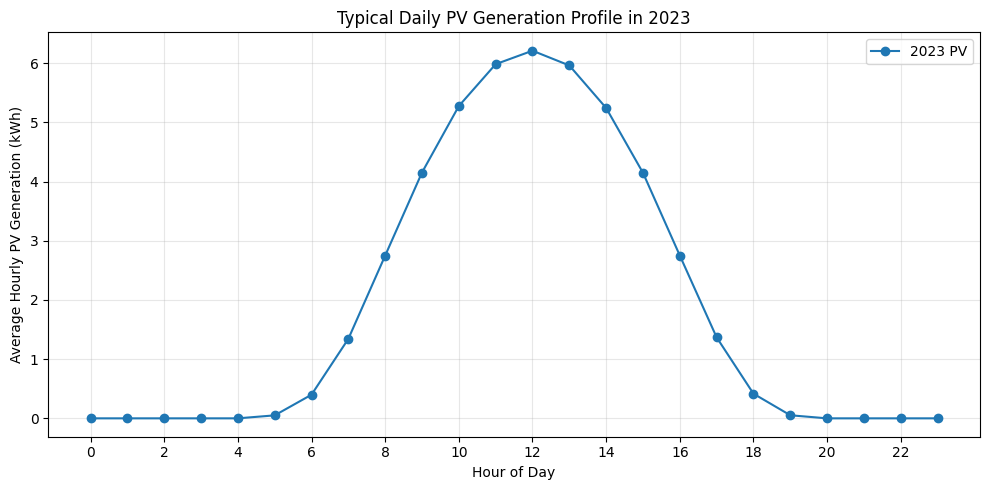

In [75]:
# Plot typical daily PV generation
plt.figure(figsize=(10, 5))
plt.plot(daily_pv_profile.index, daily_pv_profile.values,
         marker="o", label="2023 PV")

# Format the figure
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly PV Generation (kWh)")
plt.title("Typical Daily PV Generation Profile in 2023")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [76]:
# Select 2023 PV and irradiance data
pv_irradiance_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["solar_output_kW", "irradiance_W/m^2"]
].dropna()

# Calculate correlation
pv_irradiance_corr = pv_irradiance_data[
    "solar_output_kW"
].corr(
    pv_irradiance_data["irradiance_W/m^2"]
)

# Display results
print("Correlation between irradiance and PV power:",
      round(pv_irradiance_corr, 4))


Correlation between irradiance and PV power: 0.9793


In [77]:
# Select valid daytime PV and temperature data
pv_temperature_data = df_clean.loc[
    (df_clean["timestamp"].dt.year == 2023) &
    (df_clean["irradiance_W/m^2"] > 200),
    ["solar_output_kW", "temperature_C",
     "irradiance_W/m^2"]
].dropna()

# Calculate irradiance-normalised PV output
pv_temperature_data["pv_normalised"] = (
    pv_temperature_data["solar_output_kW"] /
    pv_temperature_data["irradiance_W/m^2"]
)

# Calculate temperature correlation
pv_temperature_corr = pv_temperature_data[
    "pv_normalised"
].corr(pv_temperature_data["temperature_C"])

# Display results
print("Correlation between temperature and normalised PV output:",
      round(pv_temperature_corr, 4))


Correlation between temperature and normalised PV output: -0.2126


In [78]:
# Calculate maximum PV output in 2023
pv_peak_power = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    "solar_output_kW"
].max()

# Find the timestamp of maximum PV output
pv_peak_record = df_clean.loc[
    df_clean["solar_output_kW"].idxmax(),
    ["timestamp", "solar_output_kW"]
]

# Display results
print("Maximum recorded PV power (kW):",
      round(pv_peak_power, 2))
print("PV peak record:")
display(pv_peak_record)


Maximum recorded PV power (kW): 11.54
PV peak record:


timestamp          2023-12-21 12:10:00
solar_output_kW                  11.54
Name: 102098, dtype: object

In [79]:
# Select recorded PV power in 2023
pv_power_2023 = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    "solar_output_kW"
].dropna()

# Calculate duration above different power levels
pv_high_power = pd.Series({
    "Above 50% of peak (hours)": (
        (pv_power_2023 >= pv_peak_power * 0.5).sum() * 5 / 60
    ),
    "Above 75% of peak (hours)": (
        (pv_power_2023 >= pv_peak_power * 0.75).sum() * 5 / 60
    ),
    "Above 90% of peak (hours)": (
        (pv_power_2023 >= pv_peak_power * 0.9).sum() * 5 / 60
    )
})

# Display results
print("2023 PV high-power generation duration:")
display(pv_high_power.round(2))


2023 PV high-power generation duration:


Above 50% of peak (hours)    1079.08
Above 75% of peak (hours)      85.08
Above 90% of peak (hours)       1.42
dtype: float64

In [80]:
# Identify high PV output records
pv_high_output_records = df_clean.loc[
    (df_clean["timestamp"].dt.year == 2023) &
    (df_clean["solar_output_kW"] >= pv_peak_power * 0.9),
    ["timestamp", "solar_output_kW",
     "irradiance_W/m^2", "temperature_C"]
].copy()

# Display high-output records
print("PV records above 90% of maximum power:")
display(pv_high_output_records.round(2))


PV records above 90% of maximum power:


,timestamp,solar_output_kW,irradiance_W/m^2,temperature_C
1303,2023-01-05 12:35:00,10.39,1107.0,30.6
5343,2023-01-19 13:15:00,10.49,1090.0,28.2
5345,2023-01-19 13:25:00,10.82,1081.0,28.2
10228,2023-02-05 12:20:00,11.15,1073.0,29.5
82523,2023-10-14 12:55:00,10.39,979.0,27.7
85678,2023-10-25 11:50:00,10.66,1043.0,20.6
85977,2023-10-26 12:45:00,10.66,1065.0,20.6
85982,2023-10-26 13:10:00,10.83,1045.0,21.0
96637,2023-12-02 13:05:00,10.47,1070.0,31.3
100088,2023-12-14 12:40:00,10.60,1075.0,29.3


In [81]:
# Select recorded PV data in 2023
pv_change_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "solar_output_kW", "irradiance_W/m^2"]
].copy()

# Calculate five-minute PV power changes
pv_change_data["power_change_kW"] = (
    pv_change_data["solar_output_kW"].diff().abs()
)

# Identify large power changes
pv_large_changes = pv_change_data.loc[
    pv_change_data["power_change_kW"] > 5
]

# Display results
print("PV power changes above 5 kW within 5 minutes:",
      len(pv_large_changes))
display(pv_large_changes.head(10).round(2))


PV power changes above 5 kW within 5 minutes: 213


,timestamp,solar_output_kW,irradiance_W/m^2,power_change_kW
152,2023-01-01 12:40:00,8.31,1057.0,5.27
729,2023-01-03 12:45:00,3.96,1078.0,5.27
993,2023-01-04 10:45:00,9.57,978.0,6.74
1000,2023-01-04 11:20:00,8.93,1038.0,5.87
1304,2023-01-05 12:40:00,4.05,1108.0,6.34
1305,2023-01-05 12:45:00,9.36,1108.0,5.31
1594,2023-01-06 12:50:00,2.73,1111.0,5.55
1595,2023-01-06 12:55:00,8.39,1111.0,5.66
1597,2023-01-06 13:05:00,9.43,1107.0,5.03
1878,2023-01-07 12:30:00,3.06,1095.0,5.44


In [82]:
# Calculate five-minute irradiance changes
pv_change_data["irradiance_change"] = (
    pv_change_data["irradiance_W/m^2"].diff().abs()
)

# Select large PV power changes
pv_change_check = pv_change_data.loc[
    pv_change_data["power_change_kW"] > 5,
    ["timestamp", "power_change_kW", "irradiance_change"]
].copy()

# Display results
print("PV power and irradiance changes:")
display(pv_change_check.describe().round(2))


PV power and irradiance changes:


,timestamp,power_change_kW,irradiance_change
count,213,213.00,213.00
mean,2023-08-08 15:45:40.845070336,5.65,5.75
min,2023-01-01 12:40:00,5.01,0.00
25%,2023-02-21 12:55:00,5.21,1.00
50%,2023-10-20 10:50:00,5.52,5.00
75%,2023-12-02 10:10:00,5.98,8.00
max,2023-12-31 14:15:00,7.63,17.00
std,NaN,0.52,4.31


In [83]:
# Calculate signed PV power changes
pv_change_data["signed_change_kW"] = (
    pv_change_data["solar_output_kW"].diff()
)

# Classify large power changes
pv_change_direction = pv_change_data.loc[
    pv_change_data["power_change_kW"] > 5
].copy()

pv_change_direction["direction"] = np.where(
    pv_change_direction["signed_change_kW"] > 0,
    "Increase", "Decrease"
)

# Display results
print("Direction of large PV power changes:")
display(pv_change_direction["direction"].value_counts())


Direction of large PV power changes:


direction
Increase    111
Decrease    102
Name: count, dtype: int64

In [84]:
# Identify large PV power drops
pv_drop_mask = pv_change_data["signed_change_kW"] < -5

# Check power recovery in the next five minutes
pv_recovery_mask = (
    pv_change_data["signed_change_kW"].shift(-1) > 5
)

# Select rapid drop and recovery events
pv_drop_recovery = pv_change_data.loc[
    pv_drop_mask & pv_recovery_mask,
    ["timestamp", "solar_output_kW",
     "irradiance_W/m^2", "signed_change_kW"]
].copy()

# Display results
print("Rapid PV drop and recovery events:", len(pv_drop_recovery))
display(pv_drop_recovery.head(10).round(2))


Rapid PV drop and recovery events: 50


,timestamp,solar_output_kW,irradiance_W/m^2,signed_change_kW
1304,2023-01-05 12:40:00,4.05,1108.0,-6.34
1594,2023-01-06 12:50:00,2.73,1111.0,-5.55
1878,2023-01-07 12:30:00,3.06,1095.0,-5.44
6203,2023-01-22 12:55:00,3.33,1090.0,-5.54
6486,2023-01-23 12:30:00,2.47,1071.0,-6.29
6772,2023-01-24 12:20:00,2.88,1068.0,-5.12
9095,2023-02-01 13:55:00,2.45,1024.0,-6.99
9362,2023-02-02 12:10:00,2.41,1004.0,-6.56
10245,2023-02-05 13:45:00,2.14,1046.0,-6.30
11394,2023-02-09 13:30:00,3.30,1032.0,-5.98


In [85]:
# Select the first rapid PV drop and recovery event
pv_event_time = pv_drop_recovery.iloc[0]["timestamp"]

# Extract measurements around the event
pv_event_data = df_clean.loc[
    (df_clean["timestamp"] >= pv_event_time - pd.Timedelta(minutes=15)) &
    (df_clean["timestamp"] <= pv_event_time + pd.Timedelta(minutes=15)),
    ["timestamp", "solar_output_kW",
     "irradiance_W/m^2", "temperature_C"]
].copy()

# Display results
print("PV measurements around the first rapid drop event:")
display(pv_event_data.round(2))


PV measurements around the first rapid drop event:


,timestamp,solar_output_kW,irradiance_W/m^2,temperature_C
1301,2023-01-05 12:25:00,8.86,1106.0,30.5
1302,2023-01-05 12:30:00,9.32,1106.0,30.6
1303,2023-01-05 12:35:00,10.39,1107.0,30.6
1304,2023-01-05 12:40:00,4.05,1108.0,30.7
1305,2023-01-05 12:45:00,9.36,1108.0,30.8
1306,2023-01-05 12:50:00,9.12,1109.0,30.9
1307,2023-01-05 12:55:00,9.15,1109.0,31.0


In [86]:
# Identify rapid PV drop and recovery records
pv_event_indices = pv_drop_recovery.index

# Estimate reference power from neighbouring measurements
pv_event_reference = (
    df_clean["solar_output_kW"].shift(1) +
    df_clean["solar_output_kW"].shift(-1)
) / 2

# Calculate potential energy difference
pv_event_energy_difference = (
    pv_event_reference.loc[pv_event_indices] -
    df_clean.loc[pv_event_indices, "solar_output_kW"]
).clip(lower=0) / 12

# Display results
print("Rapid PV drop events:", len(pv_event_indices))
print("Potential energy difference (kWh):",
      round(pv_event_energy_difference.sum(), 2))


Rapid PV drop events: 50
Potential energy difference (kWh): 24.1


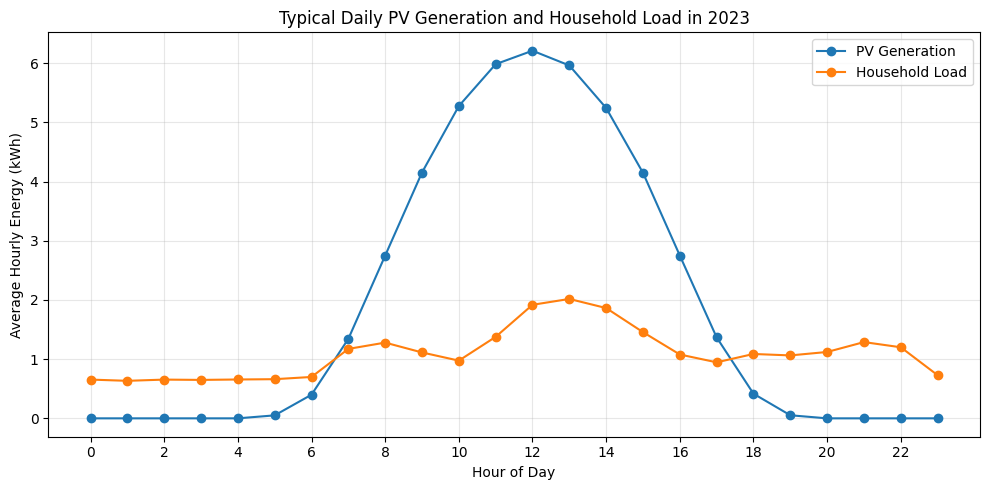

In [87]:
# Select 2023 typical daily load and PV profiles
typical_load_2023 = daily_load_profile[2023]
typical_pv_2023 = daily_pv_profile

# Plot PV generation and household load
plt.figure(figsize=(10, 5))
plt.plot(typical_pv_2023.index, typical_pv_2023.values,
         label="PV Generation", marker="o")
plt.plot(typical_load_2023.index, typical_load_2023.values,
         label="Household Load", marker="o")

# Format the figure
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Energy (kWh)")
plt.title("Typical Daily PV Generation and Household Load in 2023")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("PV_and_Load_2023.png", dpi=300, bbox_inches="tight")
plt.show()

In [88]:
# Select 2023 five-minute energy data
pv_self_consumption_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "solar_kWh", "load_kWh"]
].copy()

# Calculate direct PV self-consumption
pv_self_consumption_data["pv_self_used_kWh"] = (
    pv_self_consumption_data[
        ["solar_kWh", "load_kWh"]
    ].min(axis=1)
)

# Display results
print("2023 direct PV self-consumption (kWh):",
      round(pv_self_consumption_data["pv_self_used_kWh"].sum(), 2))


2023 direct PV self-consumption (kWh): 5023.42


In [89]:
# Calculate annual PV self-consumption rate
pv_self_consumption_rate = (
    pv_self_consumption_data["pv_self_used_kWh"].sum() /
    pv_self_consumption_data["solar_kWh"].sum()
) * 100

# Display results
print("2023 PV self-consumption rate (%):",
      round(pv_self_consumption_rate, 2))


2023 PV self-consumption rate (%): 29.85


In [90]:
# Calculate five-minute PV surplus
pv_self_consumption_data["pv_surplus_kWh"] = (
    pv_self_consumption_data["solar_kWh"] -
    pv_self_consumption_data["load_kWh"]
).clip(lower=0)

# Calculate annual PV surplus
annual_pv_surplus = pv_self_consumption_data["pv_surplus_kWh"].sum()

# Display results
print("2023 annual PV surplus (kWh):",
      round(annual_pv_surplus, 2))


2023 annual PV surplus (kWh): 11804.21


In [91]:
# Calculate five-minute grid import
pv_self_consumption_data["grid_import_kWh"] = (
    pv_self_consumption_data["load_kWh"] -
    pv_self_consumption_data["solar_kWh"]
).clip(lower=0)

# Calculate annual grid import
annual_grid_import = pv_self_consumption_data["grid_import_kWh"].sum()

# Display results
print("2023 annual grid import without BESS (kWh):",
      round(annual_grid_import, 2))


2023 annual grid import without BESS (kWh): 4574.39


In [92]:
# Calculate five-minute grid export
pv_self_consumption_data["grid_export_kWh"] = (
    pv_self_consumption_data["pv_surplus_kWh"]
)

# Calculate annual grid export
annual_grid_export = pv_self_consumption_data["grid_export_kWh"].sum()

# Display results
print("2023 annual grid export without BESS (kWh):",
      round(annual_grid_export, 2))


2023 annual grid export without BESS (kWh): 11804.21


In [93]:
# Calculate annual energy totals
pv_total = pv_self_consumption_data["solar_kWh"].sum()
load_total = pv_self_consumption_data["load_kWh"].sum()
pv_self_used = pv_self_consumption_data["pv_self_used_kWh"].sum()

# Check PV and load energy balances
energy_balance_check = pd.Series({
    "PV balance error (kWh)": (
        pv_total - pv_self_used - annual_grid_export
    ),
    "Load balance error (kWh)": (
        load_total - pv_self_used - annual_grid_import
    )
})

# Display results
print("2023 annual energy balance check:")
display(energy_balance_check.round(6))


2023 annual energy balance check:


PV balance error (kWh)     -0.0
Load balance error (kWh)    0.0
dtype: float64

In [94]:
# Calculate monthly PV surplus
monthly_pv_surplus = pv_self_consumption_data.groupby(
    pv_self_consumption_data["timestamp"].dt.month
)["pv_surplus_kWh"].sum()

# Display results
print("2023 monthly PV surplus (kWh):")
display(monthly_pv_surplus.round(2))


2023 monthly PV surplus (kWh):


timestamp
1     1332.14
2     1182.14
3     1096.61
4      807.65
5      696.69
6      423.71
7      573.92
8      642.06
9     1013.98
10    1272.56
11    1331.48
12    1431.27
Name: pv_surplus_kWh, dtype: float64

In [95]:
# Calculate average PV surplus for each hour
daily_pv_surplus = pv_self_consumption_data.groupby(
    pv_self_consumption_data["timestamp"].dt.hour
)["pv_surplus_kWh"].sum() / 365

# Display results
print("2023 typical daily PV surplus by hour (kWh):")
display(daily_pv_surplus.round(2))


2023 typical daily PV surplus by hour (kWh):


timestamp
0     0.00
1     0.00
2     0.00
3     0.00
4     0.00
5     0.00
6     0.17
7     0.84
8     1.97
9     3.21
10    4.35
11    4.63
12    4.32
13    3.98
14    3.42
15    2.73
16    1.78
17    0.79
18    0.15
19    0.00
20    0.00
21    0.00
22    0.00
23    0.00
Name: pv_surplus_kWh, dtype: float64

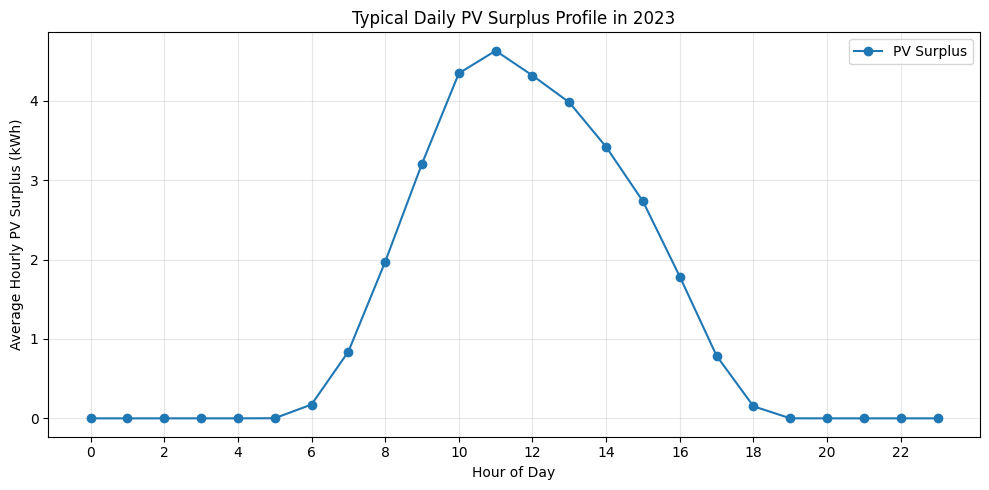

In [96]:
# Plot typical daily PV surplus
plt.figure(figsize=(10, 5))
plt.plot(daily_pv_surplus.index, daily_pv_surplus.values,
         marker="o", label="PV Surplus")

# Format the figure
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly PV Surplus (kWh)")
plt.title("Typical Daily PV Surplus Profile in 2023")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [97]:
# Calculate daily PV surplus
daily_pv_surplus_energy = pv_self_consumption_data.groupby(
    pv_self_consumption_data["timestamp"].dt.date
)["pv_surplus_kWh"].sum()

# Calculate daily surplus statistics
daily_pv_surplus_summary = daily_pv_surplus_energy.agg(
    ["mean", "median", "min", "max"]
)

# Display results
print("2023 daily PV surplus statistics (kWh/day):")
display(daily_pv_surplus_summary.round(2))


2023 daily PV surplus statistics (kWh/day):


mean      32.34
median    32.96
min        0.25
max       63.34
Name: pv_surplus_kWh, dtype: float64

In [98]:
# Calculate daily PV surplus percentiles
daily_pv_surplus_percentiles = daily_pv_surplus_energy.quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
)

# Display results
print("2023 daily PV surplus percentiles (kWh/day):")
display(daily_pv_surplus_percentiles.round(2))


2023 daily PV surplus percentiles (kWh/day):


0.10    14.42
0.25    21.38
0.50    32.96
0.75    42.30
0.90    50.26
Name: pv_surplus_kWh, dtype: float64

In [99]:
# Calculate five-minute PV surplus power
pv_surplus_power = (
    pv_self_consumption_data["pv_surplus_kWh"] * 12
)

# Calculate surplus power statistics
pv_surplus_power_summary = pv_surplus_power.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

# Display results
print("2023 PV surplus power percentiles (kW):")
display(pv_surplus_power_summary.round(2))
print("Maximum PV surplus power (kW):",
      round(pv_surplus_power.max(), 2))


2023 PV surplus power percentiles (kW):


0.50    0.00
0.75    2.48
0.90    4.68
0.95    5.79
0.99    7.54
Name: pv_surplus_kWh, dtype: float64

Maximum PV surplus power (kW): 11.07


In [100]:
# Define candidate battery charging powers
charging_power_options = [2, 3, 5, 7, 10]

# Calculate usable PV surplus under each power limit
pv_charging_potential = pd.Series({
    power: (
        pv_surplus_power.clip(upper=power).sum() / 12
    )
    for power in charging_power_options
})

# Display results
print("2023 PV surplus available under charging power limits (kWh):")
display(pv_charging_potential.round(2))


2023 PV surplus available under charging power limits (kWh):


2      6172.54
3      8350.03
5     10884.80
7     11682.40
10    11804.09
dtype: float64

In [101]:
# Calculate PV surplus utilisation rate
pv_charging_utilisation = (
    pv_charging_potential / annual_pv_surplus * 100
)

# Display results
print("2023 PV surplus utilisation by charging power (%):")
display(pv_charging_utilisation.round(2))


2023 PV surplus utilisation by charging power (%):


2      52.29
3      70.74
5      92.21
7      98.97
10    100.00
dtype: float64

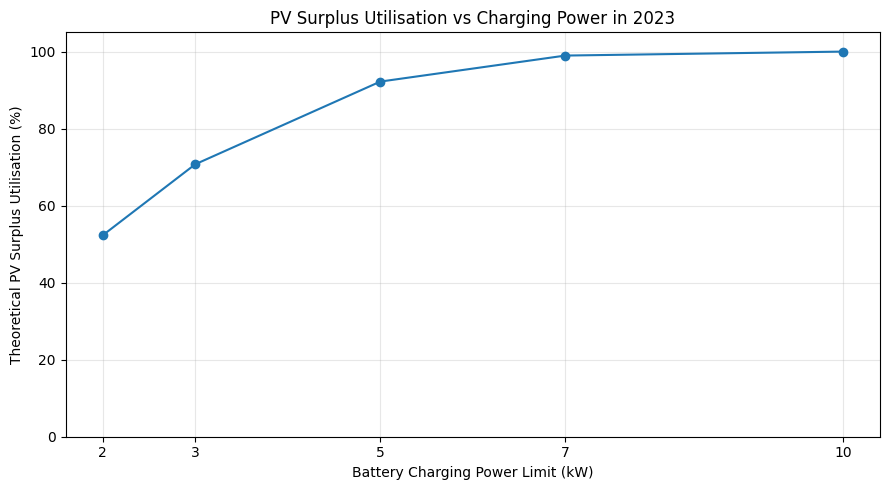

In [102]:
# Plot PV surplus utilisation by charging power
plt.figure(figsize=(9, 5))
plt.plot(pv_charging_utilisation.index,
         pv_charging_utilisation.values,
         marker="o")

# Format the figure
plt.xlabel("Battery Charging Power Limit (kW)")
plt.ylabel("Theoretical PV Surplus Utilisation (%)")
plt.title("PV Surplus Utilisation vs Charging Power in 2023")
plt.xticks(charging_power_options)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [103]:
# Identify five-minute periods with PV surplus
pv_surplus_available = (
    pv_self_consumption_data["pv_surplus_kWh"] > 0
)

# Calculate annual PV surplus availability
pv_surplus_hours = pv_surplus_available.sum() / 12

# Display results
print("2023 hours with available PV surplus:",
      round(pv_surplus_hours, 2))
print("Percentage of annual time with PV surplus (%):",
      round(pv_surplus_available.mean() * 100, 2))


2023 hours with available PV surplus: 3716.67
Percentage of annual time with PV surplus (%): 42.43


In [104]:
# Calculate daily hours with available PV surplus
daily_pv_surplus_hours = pv_surplus_available.groupby(
    pv_self_consumption_data["timestamp"].dt.date
).sum() / 12

# Calculate daily availability statistics
daily_pv_surplus_hours_summary = daily_pv_surplus_hours.agg(
    ["mean", "median", "min", "max"]
)

# Display results
print("2023 daily PV surplus availability (hours/day):")
display(daily_pv_surplus_hours_summary.round(2))


2023 daily PV surplus availability (hours/day):


mean      10.18
median    10.75
min        1.58
max       13.25
Name: pv_surplus_kWh, dtype: float64

In [105]:
# Calculate PV surplus exceeding each charging power limit
pv_power_limited_energy = (
    annual_pv_surplus - pv_charging_potential
)

# Display results
print("2023 PV surplus exceeding charging power limits (kWh):")
display(pv_power_limited_energy.round(2))


2023 PV surplus exceeding charging power limits (kWh):


2     5631.67
3     3454.18
5      919.41
7      121.81
10       0.12
dtype: float64

In [106]:
# Calculate additional PV energy between charging power options
pv_charging_increment = pv_charging_potential.diff()

# Display results
print("Additional PV charging potential compared with previous power option (kWh):")
display(pv_charging_increment.round(2))


Additional PV charging potential compared with previous power option (kWh):


2         NaN
3     2177.49
5     2534.77
7      797.60
10     121.69
dtype: float64

In [107]:
# Calculate average daily PV surplus for each month
monthly_daily_pv_surplus = (
    daily_pv_surplus_energy.groupby(
        pd.to_datetime(daily_pv_surplus_energy.index).month
    ).mean()
)

# Display results
print("2023 monthly average daily PV surplus (kWh/day):")
display(monthly_daily_pv_surplus.round(2))


2023 monthly average daily PV surplus (kWh/day):


timestamp
1     42.97
2     42.22
3     35.37
4     26.92
5     22.47
6     14.12
7     18.51
8     20.71
9     33.80
10    41.05
11    44.38
12    46.17
Name: pv_surplus_kWh, dtype: float64

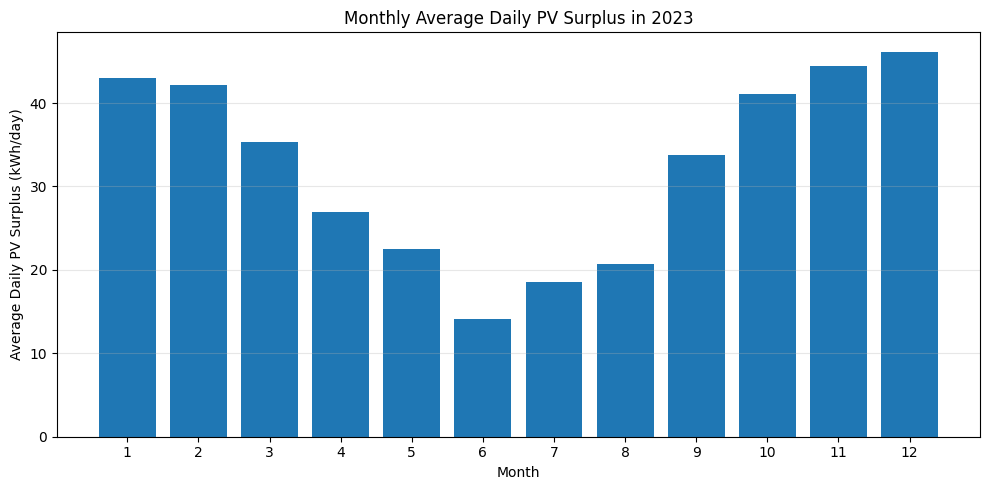

In [108]:
# Plot monthly average daily PV surplus
plt.figure(figsize=(10, 5))
plt.bar(monthly_daily_pv_surplus.index,
        monthly_daily_pv_surplus.values)

# Format the figure
plt.xlabel("Month")
plt.ylabel("Average Daily PV Surplus (kWh/day)")
plt.title("Monthly Average Daily PV Surplus in 2023")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [109]:
# Summarise annual PV and load indicators
pv_load_summary = pd.Series({
    "PV generation (kWh)": pv_total,
    "Household load (kWh)": load_total,
    "Direct PV self-consumption (kWh)": pv_self_used,
    "PV self-consumption rate (%)": pv_self_consumption_rate,
    "PV surplus (kWh)": annual_pv_surplus,
    "Grid import without BESS (kWh)": annual_grid_import,
    "Grid export without BESS (kWh)": annual_grid_export
})

# Display results
print("2023 PV and household load summary:")
display(pv_load_summary.round(2))


2023 PV and household load summary:


PV generation (kWh)                 16827.63
Household load (kWh)                 9597.81
Direct PV self-consumption (kWh)     5023.42
PV self-consumption rate (%)           29.85
PV surplus (kWh)                    11804.21
Grid import without BESS (kWh)       4574.39
Grid export without BESS (kWh)      11804.21
dtype: float64

In [110]:
# Identify available electricity price columns
price_columns = [
    col for col in df_clean.columns
    if "price" in col.lower() or "rrp" in col.lower()
]

# Display results
print("Available electricity price columns:")
display(price_columns)


Available electricity price columns:


['spot_price_AUD/kWh']

In [111]:
# Select 2023 wholesale electricity prices
spot_price_2023 = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    "spot_price_AUD/kWh"
].dropna()

# Calculate wholesale price statistics
spot_price_summary = spot_price_2023.agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Display results
print("2023 wholesale electricity price statistics (AUD/kWh):")
display(spot_price_summary.round(4))


2023 wholesale electricity price statistics (AUD/kWh):


count     105120.0000
mean           0.0801
median         0.0591
std            0.3967
min           -0.9990
max           16.6000
Name: spot_price_AUD/kWh, dtype: float64

In [112]:
# Identify negative wholesale price records
negative_price_mask = spot_price_2023 < 0

# Calculate negative price statistics
negative_price_count = negative_price_mask.sum()
negative_price_hours = negative_price_count / 12
negative_price_percentage = negative_price_mask.mean() * 100

# Display results
print("2023 negative wholesale price records:", negative_price_count)
print("2023 negative wholesale price hours:",
      round(negative_price_hours, 2))
print("Percentage of negative price records (%):",
      round(negative_price_percentage, 2))


2023 negative wholesale price records: 25929
2023 negative wholesale price hours: 2160.75
Percentage of negative price records (%): 24.67


In [113]:
# Calculate wholesale price percentiles
spot_price_percentiles = spot_price_2023.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

# Define high wholesale price thresholds
high_price_thresholds = [0.20, 0.50, 1.00, 5.00]

# Calculate high-price frequency and duration
high_price_summary = pd.DataFrame({
    "Records": [
        (spot_price_2023 >= threshold).sum()
        for threshold in high_price_thresholds
    ],
    "Hours": [
        (spot_price_2023 >= threshold).sum() / 12
        for threshold in high_price_thresholds
    ],
    "Percentage (%)": [
        (spot_price_2023 >= threshold).mean() * 100
        for threshold in high_price_thresholds
    ]
}, index=high_price_thresholds)

# Display results
print("2023 wholesale price percentiles (AUD/kWh):")
display(spot_price_percentiles.round(4))

print("2023 high wholesale price statistics:")
display(high_price_summary.round(2))


2023 wholesale price percentiles (AUD/kWh):


0.01   -0.1000
0.05   -0.0575
0.10   -0.0508
0.25    0.0000
0.50    0.0591
0.75    0.1151
0.90    0.1799
0.95    0.2822
0.99    0.3800
Name: spot_price_AUD/kWh, dtype: float64

2023 high wholesale price statistics:


,Records,Hours,Percentage (%)
0.2,8949,745.75,8.51
0.5,612,51.00,0.58
1.0,229,19.08,0.22
5.0,93,7.75,0.09


In [114]:
# Select 2023 wholesale price data
monthly_price_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "spot_price_AUD/kWh"]
].copy()

# Calculate monthly wholesale price statistics
monthly_price_summary = monthly_price_data.groupby(
    monthly_price_data["timestamp"].dt.month
)["spot_price_AUD/kWh"].agg(["mean", "median", "min", "max"])

# Calculate monthly negative and high-price hours
monthly_price_summary["Negative hours"] = (
    monthly_price_data["spot_price_AUD/kWh"].lt(0)
    .groupby(monthly_price_data["timestamp"].dt.month).sum() / 12
)

monthly_price_summary["High-price hours (>=0.50)"] = (
    monthly_price_data["spot_price_AUD/kWh"].ge(0.50)
    .groupby(monthly_price_data["timestamp"].dt.month).sum() / 12
)

# Display results
print("2023 monthly wholesale electricity price statistics:")
display(monthly_price_summary.round(3))


2023 monthly wholesale electricity price statistics:


,mean,median,min,max,Negative hours,High-price hours (>=0.50)
timestamp,,,,,,
1,0.057,0.069,-0.998,12.523,212.417,3.667
2,0.097,0.080,-0.489,15.500,180.000,9.833
3,0.065,0.083,-0.982,1.005,178.833,0.167
4,0.085,0.087,-0.620,9.900,129.833,0.833
5,0.198,0.165,-0.115,15.500,67.583,10.833
6,0.086,0.061,-0.984,12.922,154.000,5.583
7,0.073,0.061,-0.972,4.093,167.667,0.750
8,0.160,0.065,-0.200,16.600,143.667,15.833
9,0.041,0.031,-0.999,9.909,222.500,1.167


In [115]:
# Calculate hourly wholesale price statistics
hourly_price_summary = monthly_price_data.groupby(
    monthly_price_data["timestamp"].dt.hour
)["spot_price_AUD/kWh"].agg(["mean", "median"])

# Calculate negative price percentage by hour
hourly_price_summary["Negative price (%)"] = (
    monthly_price_data["spot_price_AUD/kWh"].lt(0)
    .groupby(monthly_price_data["timestamp"].dt.hour).mean() * 100
)

# Calculate high-price percentage by hour
hourly_price_summary["High price >=0.50 (%)"] = (
    monthly_price_data["spot_price_AUD/kWh"].ge(0.50)
    .groupby(monthly_price_data["timestamp"].dt.hour).mean() * 100
)

# Display results
print("2023 hourly wholesale electricity price statistics:")
display(hourly_price_summary.round(3))


2023 hourly wholesale electricity price statistics:


,mean,median,Negative price (%),High price >=0.50 (%)
timestamp,,,,
0,0.095,0.084,8.927,0.320
1,0.080,0.074,10.297,0.228
2,0.071,0.064,12.808,0.137
3,0.062,0.058,14.018,0.068
4,0.066,0.062,13.836,0.137
5,0.079,0.074,11.279,0.228
6,0.116,0.081,10.822,0.708
7,0.127,0.063,18.493,1.210
8,0.082,0.036,29.886,0.616


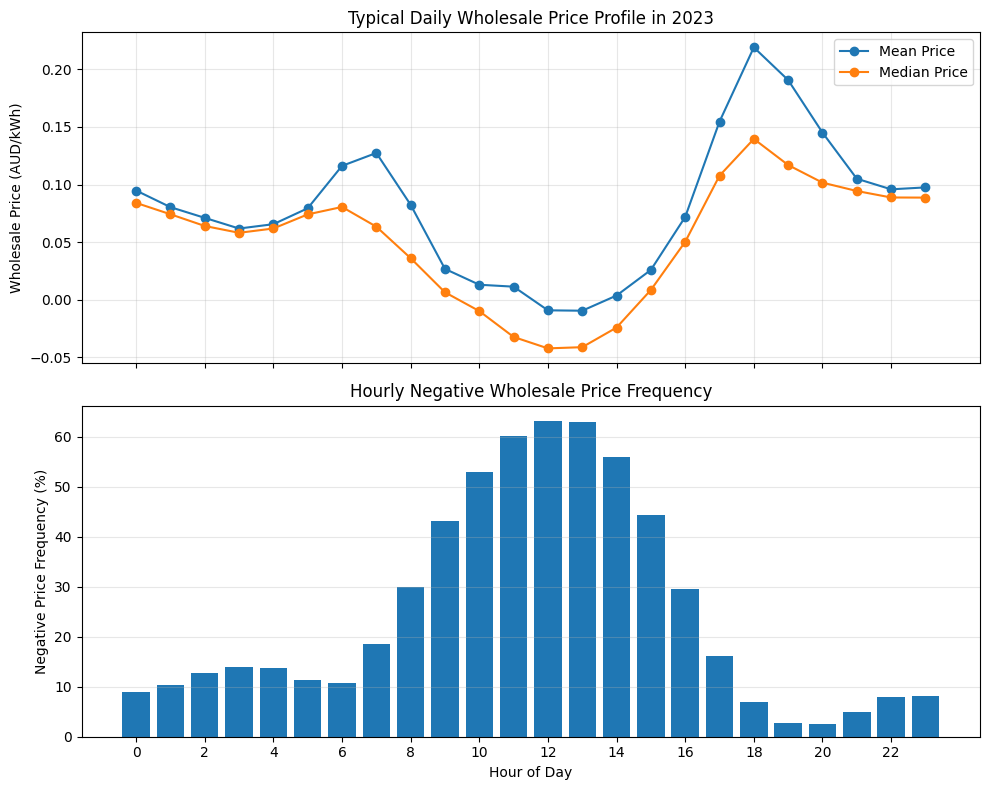

In [116]:
# Create two plots for hourly wholesale price patterns
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot average and median wholesale prices
axes[0].plot(hourly_price_summary.index,
             hourly_price_summary["mean"],
             marker="o", label="Mean Price")
axes[0].plot(hourly_price_summary.index,
             hourly_price_summary["median"],
             marker="o", label="Median Price")

axes[0].set_ylabel("Wholesale Price (AUD/kWh)")
axes[0].set_title("Typical Daily Wholesale Price Profile in 2023")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot negative price frequency
axes[1].bar(hourly_price_summary.index,
            hourly_price_summary["Negative price (%)"])

axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Negative Price Frequency (%)")
axes[1].set_title("Hourly Negative Wholesale Price Frequency")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [117]:
# Select 2023 timestamps and wholesale prices
price_event_data = monthly_price_data.sort_values(
    "timestamp"
).copy()

# Define price event conditions
price_event_conditions = {
    "Negative price": price_event_data["spot_price_AUD/kWh"] < 0,
    "High price >=0.50": price_event_data["spot_price_AUD/kWh"] >= 0.50
}

# Calculate consecutive price event statistics
price_event_results = []

for event_name, condition in price_event_conditions.items():

    # Identify consecutive event groups
    event_groups = condition.ne(condition.shift()).cumsum()

    # Calculate duration of each event
    event_durations = (
        condition[condition]
        .groupby(event_groups[condition])
        .size() * 5 / 60
    )

    price_event_results.append({
        "Event type": event_name,
        "Number of events": len(event_durations),
        "Total hours": event_durations.sum(),
        "Mean duration (hours)": event_durations.mean(),
        "Median duration (hours)": event_durations.median(),
        "Maximum duration (hours)": event_durations.max()
    })

# Display results
price_event_summary = pd.DataFrame(price_event_results)

print("2023 consecutive wholesale price event statistics:")
display(price_event_summary.round(2))


2023 consecutive wholesale price event statistics:


,Event type,Number of events,Total hours,Mean duration (hours),Median duration (hours),Maximum duration (hours)
0,Negative price,2011,2160.75,1.07,0.17,16.67
1,High price >=0.50,227,51.00,0.22,0.08,3.42


In [118]:
# Select 2023 PV surplus and wholesale price data
pv_price_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "solar_kWh", "load_kWh",
     "spot_price_AUD/kWh"]
].copy()

# Calculate five-minute PV surplus
pv_price_data["pv_surplus_kWh"] = (
    pv_price_data["solar_kWh"] -
    pv_price_data["load_kWh"]
).clip(lower=0)

# Define wholesale price conditions
pv_price_data["price_period"] = np.select(
    [
        pv_price_data["spot_price_AUD/kWh"] < 0,
        pv_price_data["spot_price_AUD/kWh"] >= 0.50
    ],
    ["Negative price", "High price"],
    default="Other"
)

# Summarise PV surplus for each price period
pv_price_summary = pv_price_data.groupby(
    "price_period"
).agg(
    Records=("pv_surplus_kWh", "size"),
    PV_surplus_kWh=("pv_surplus_kWh", "sum")
)

# Calculate time and PV surplus percentage
pv_price_summary["Hours"] = pv_price_summary["Records"] / 12

pv_price_summary["PV surplus share (%)"] = (
    pv_price_summary["PV_surplus_kWh"] /
    pv_price_data["pv_surplus_kWh"].sum() * 100
)

# Display results
print("2023 PV surplus by wholesale price period:")
display(pv_price_summary.round(2))


2023 PV surplus by wholesale price period:


,Records,PV_surplus_kWh,Hours,PV surplus share (%)
price_period,,,,
High price,612,39.30,51.00,0.33
Negative price,25929,6814.67,2160.75,57.73
Other,78579,4950.24,6548.25,41.94


In [119]:
# Calculate grid import without BESS
pv_price_data["grid_import_kWh"] = (
    pv_price_data["load_kWh"] -
    pv_price_data["solar_kWh"]
).clip(lower=0)

# Summarise grid import by wholesale price period
grid_price_summary = pv_price_data.groupby(
    "price_period"
).agg(
    Records=("grid_import_kWh", "size"),
    Grid_import_kWh=("grid_import_kWh", "sum")
)

# Calculate grid import percentage
grid_price_summary["Grid import share (%)"] = (
    grid_price_summary["Grid_import_kWh"] /
    pv_price_data["grid_import_kWh"].sum() * 100
)

# Calculate average grid import per five-minute interval
grid_price_summary["Average import (kWh/interval)"] = (
    grid_price_summary["Grid_import_kWh"] /
    grid_price_summary["Records"]
)

# Check total grid import
print("2023 grid import by wholesale price period:")
display(grid_price_summary.round(3))

print("Total grid import (kWh):",
      round(grid_price_summary["Grid_import_kWh"].sum(), 2))


2023 grid import by wholesale price period:


,Records,Grid_import_kWh,Grid import share (%),Average import (kWh/interval)
price_period,,,,
High price,612,48.121,1.052,0.079
Negative price,25929,410.024,8.963,0.016
Other,78579,4116.245,89.985,0.052


Total grid import (kWh): 4574.39


In [120]:
# Calculate wholesale value of grid imports and exports
pv_price_data["import_cost_AUD"] = (
    pv_price_data["grid_import_kWh"] *
    pv_price_data["spot_price_AUD/kWh"]
)

pv_price_data["export_value_AUD"] = (
    pv_price_data["pv_surplus_kWh"] *
    pv_price_data["spot_price_AUD/kWh"]
)

# Summarise wholesale energy values by price period
wholesale_cost_summary = pv_price_data.groupby(
    "price_period"
).agg(
    Import_kWh=("grid_import_kWh", "sum"),
    Export_kWh=("pv_surplus_kWh", "sum"),
    Import_cost_AUD=("import_cost_AUD", "sum"),
    Export_value_AUD=("export_value_AUD", "sum")
)

# Calculate net wholesale energy cost
wholesale_cost_summary["Net_cost_AUD"] = (
    wholesale_cost_summary["Import_cost_AUD"] -
    wholesale_cost_summary["Export_value_AUD"]
)

# Calculate annual totals
wholesale_cost_total = wholesale_cost_summary.sum()

# Display results
print("2023 wholesale energy value by price period:")
display(wholesale_cost_summary.round(2))

print("2023 annual wholesale energy value summary:")
display(wholesale_cost_total.round(2))


2023 wholesale energy value by price period:


,Import_kWh,Export_kWh,Import_cost_AUD,Export_value_AUD,Net_cost_AUD
price_period,,,,,
High price,48.12,39.30,186.34,89.46,96.87
Negative price,410.02,6814.67,-14.14,-389.70,375.56
Other,4116.24,4950.24,520.96,333.91,187.05


2023 annual wholesale energy value summary:


Import_kWh           4574.39
Export_kWh          11804.21
Import_cost_AUD       693.16
Export_value_AUD       33.67
Net_cost_AUD          659.49
dtype: float64

In [121]:
# Calculate energy-weighted wholesale prices by period
weighted_price_summary = wholesale_cost_summary[
    ["Import_kWh", "Export_kWh"]
].copy()

weighted_price_summary["Import weighted price (AUD/kWh)"] = (
    wholesale_cost_summary["Import_cost_AUD"] /
    wholesale_cost_summary["Import_kWh"].replace(0, np.nan)
)

weighted_price_summary["Export weighted price (AUD/kWh)"] = (
    wholesale_cost_summary["Export_value_AUD"] /
    wholesale_cost_summary["Export_kWh"].replace(0, np.nan)
)

# Calculate annual energy-weighted prices
annual_weighted_prices = pd.Series({
    "Time-average spot price (AUD/kWh)": spot_price_2023.mean(),
    "Import-weighted price (AUD/kWh)": (
        wholesale_cost_total["Import_cost_AUD"] /
        wholesale_cost_total["Import_kWh"]
    ),
    "Export-weighted price (AUD/kWh)": (
        wholesale_cost_total["Export_value_AUD"] /
        wholesale_cost_total["Export_kWh"]
    )
})

# Display results
print("2023 energy-weighted wholesale prices by period:")
display(weighted_price_summary.round(4))

print("2023 annual weighted wholesale price comparison:")
display(annual_weighted_prices.round(4))


2023 energy-weighted wholesale prices by period:


,Import_kWh,Export_kWh,Import weighted price (AUD/kWh),Export weighted price (AUD/kWh)
price_period,,,,
High price,48.1208,39.3008,3.8723,2.2764
Negative price,410.0241,6814.6710,-0.0345,-0.0572
Other,4116.2447,4950.2381,0.1266,0.0675


2023 annual weighted wholesale price comparison:


Time-average spot price (AUD/kWh)    0.0801
Import-weighted price (AUD/kWh)      0.1515
Export-weighted price (AUD/kWh)      0.0029
dtype: float64

In [122]:
# Calculate daily wholesale price statistics
daily_price_summary = monthly_price_data.groupby(
    monthly_price_data["timestamp"].dt.date
)["spot_price_AUD/kWh"].agg(["mean", "min", "max", "std"])

# Calculate daily price spread
daily_price_summary["price_spread"] = (
    daily_price_summary["max"] - daily_price_summary["min"]
)

# Calculate summary statistics for daily price variation
daily_price_volatility = daily_price_summary[
    ["mean", "std", "price_spread"]
].agg(["mean", "median", "min", "max"])

# Calculate days with both negative and high prices
daily_price_opportunities = pd.Series({
    "Days with negative prices": (
        daily_price_summary["min"] < 0
    ).sum(),
    "Days with prices >= 0.50 AUD/kWh": (
        daily_price_summary["max"] >= 0.50
    ).sum(),
    "Days with both conditions": (
        (daily_price_summary["min"] < 0) &
        (daily_price_summary["max"] >= 0.50)
    ).sum()
})

# Display results
print("2023 daily wholesale price variation (AUD/kWh):")
display(daily_price_volatility.round(3))

print("2023 daily price opportunity statistics:")
display(daily_price_opportunities)


2023 daily wholesale price variation (AUD/kWh):


,mean,std,price_spread
mean,0.080,0.149,1.271
median,0.059,0.073,0.395
min,-0.082,0.024,0.106
max,1.606,3.808,17.459


2023 daily price opportunity statistics:


Days with negative prices           324
Days with prices >= 0.50 AUD/kWh     80
Days with both conditions            64
dtype: int64

In [123]:
# Calculate five-minute PV surplus and grid import power
pv_price_data["pv_surplus_kW"] = (
    pv_price_data["pv_surplus_kWh"] * 12
)

pv_price_data["grid_import_kW"] = (
    pv_price_data["grid_import_kWh"] * 12
)

# Calculate correlations with wholesale price
price_correlation_summary = pd.Series({
    "PV surplus vs spot price": (
        pv_price_data["pv_surplus_kW"].corr(
            pv_price_data["spot_price_AUD/kWh"]
        )
    ),
    "Grid import vs spot price": (
        pv_price_data["grid_import_kW"].corr(
            pv_price_data["spot_price_AUD/kWh"]
        )
    ),
    "PV generation vs spot price": (
        pv_price_data["solar_kWh"].corr(
            pv_price_data["spot_price_AUD/kWh"]
        )
    )
})

# Display results
print("2023 Pearson correlations with wholesale electricity price:")
display(price_correlation_summary.round(4))


2023 Pearson correlations with wholesale electricity price:


PV surplus vs spot price      -0.1277
Grid import vs spot price      0.1067
PV generation vs spot price   -0.1321
dtype: float64

In [124]:
# Summarise key wholesale price indicators
wholesale_price_final_summary = pd.Series({
    "Mean spot price (AUD/kWh)": spot_price_2023.mean(),
    "Median spot price (AUD/kWh)": spot_price_2023.median(),
    "Minimum spot price (AUD/kWh)": spot_price_2023.min(),
    "Maximum spot price (AUD/kWh)": spot_price_2023.max(),
    "Negative price hours": negative_price_hours,
    "Negative price percentage (%)": negative_price_percentage,
    "High price hours (>=0.50 AUD/kWh)": (
        high_price_summary.loc[0.50, "Hours"]
    ),
    "Import-weighted price (AUD/kWh)": (
        annual_weighted_prices["Import-weighted price (AUD/kWh)"]
    ),
    "Export-weighted price (AUD/kWh)": (
        annual_weighted_prices["Export-weighted price (AUD/kWh)"]
    ),
    "PV surplus during negative prices (kWh)": (
        pv_price_summary.loc["Negative price", "PV_surplus_kWh"]
    ),
    "Grid import during high prices (kWh)": (
        grid_price_summary.loc["High price", "Grid_import_kWh"]
    ),
    "Wholesale net energy cost (AUD)": (
        wholesale_cost_total["Net_cost_AUD"]
    )
})

# Display results
print("2023 wholesale electricity price analysis summary:")
display(wholesale_price_final_summary.round(3))


2023 wholesale electricity price analysis summary:


Mean spot price (AUD/kWh)                     0.080
Median spot price (AUD/kWh)                   0.059
Minimum spot price (AUD/kWh)                 -0.999
Maximum spot price (AUD/kWh)                 16.600
Negative price hours                       2160.750
Negative price percentage (%)                24.666
High price hours (>=0.50 AUD/kWh)            51.000
Import-weighted price (AUD/kWh)               0.152
Export-weighted price (AUD/kWh)               0.003
PV surplus during negative prices (kWh)    6814.671
Grid import during high prices (kWh)         48.121
Wholesale net energy cost (AUD)             659.487
dtype: float64

In [125]:
# Define electricity tariff scenarios
tariff_scenarios = pd.DataFrame({
    "Tariff": ["Flat", "TOU", "Spot"],
    "Import pricing": [
        "Fixed rate",
        "Time-dependent rates",
        "Wholesale spot price"
    ],
    "Export pricing": [
        "Fixed feed-in tariff",
        "Fixed feed-in tariff",
        "Wholesale spot price"
    ],
    "Import rate (AUD/kWh)": [
        np.nan, np.nan, np.nan
    ],
    "Feed-in tariff (AUD/kWh)": [
        np.nan, np.nan, np.nan
    ]
})

# Display results
print("Electricity tariff scenarios for BESS optimisation:")
display(tariff_scenarios)


Electricity tariff scenarios for BESS optimisation:


,Tariff,Import pricing,Export pricing,Import rate (AUD/kWh),Feed-in tariff (AUD/kWh)
0,Flat,Fixed rate,Fixed feed-in tariff,NaN,NaN
1,TOU,Time-dependent rates,Fixed feed-in tariff,NaN,NaN
2,Spot,Wholesale spot price,Wholesale spot price,NaN,NaN


In [126]:
# Define assumed tariff parameters (AUD/kWh)
flat_import_rate = 0.25
flat_export_rate = 0.05

tou_offpeak_rate = 0.15
tou_shoulder_rate = 0.25
tou_peak_rate = 0.40
tou_export_rate = 0.05

# Define assumed TOU periods
# Peak: 17:00–21:00
# Off-peak: 22:00–07:00
# Shoulder: all remaining hours
tou_peak_hours = [17, 18, 19, 20]
tou_offpeak_hours = list(range(0, 7)) + [22, 23]

# Spot tariff assumptions
# Wholesale spot price is used as the reference price.
spot_import_markup = 0.00
spot_export_adjustment = 0.00

# Update tariff scenario table
tariff_scenarios.loc[0, "Import rate (AUD/kWh)"] = flat_import_rate
tariff_scenarios.loc[0, "Feed-in tariff (AUD/kWh)"] = flat_export_rate

tariff_scenarios.loc[1, "Import rate (AUD/kWh)"] = np.nan
tariff_scenarios.loc[1, "Feed-in tariff (AUD/kWh)"] = tou_export_rate

tariff_scenarios.loc[2, "Import rate (AUD/kWh)"] = np.nan
tariff_scenarios.loc[2, "Feed-in tariff (AUD/kWh)"] = np.nan

# Display tariff assumptions
print("Electricity tariff assumptions:")
display(tariff_scenarios)

print("TOU peak hours:", tou_peak_hours)
print("TOU off-peak hours:", tou_offpeak_hours)


Electricity tariff assumptions:


,Tariff,Import pricing,Export pricing,Import rate (AUD/kWh),Feed-in tariff (AUD/kWh)
0,Flat,Fixed rate,Fixed feed-in tariff,0.25,0.05
1,TOU,Time-dependent rates,Fixed feed-in tariff,NaN,0.05
2,Spot,Wholesale spot price,Wholesale spot price,NaN,NaN


TOU peak hours: [17, 18, 19, 20]
TOU off-peak hours: [0, 1, 2, 3, 4, 5, 6, 22, 23]


In [127]:
# Select 2023 timestamps and wholesale prices
tariff_data = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "spot_price_AUD/kWh"]
].copy()

# Flat tariff
tariff_data["flat_import_AUD/kWh"] = flat_import_rate
tariff_data["flat_export_AUD/kWh"] = flat_export_rate

# TOU tariff
hours = tariff_data["timestamp"].dt.hour

tariff_data["tou_import_AUD/kWh"] = np.select(
    [
        hours.isin(tou_peak_hours),
        hours.isin(tou_offpeak_hours)
    ],
    [tou_peak_rate, tou_offpeak_rate],
    default=tou_shoulder_rate
)

tariff_data["tou_export_AUD/kWh"] = tou_export_rate

# Spot tariff
tariff_data["spot_import_AUD/kWh"] = (
    tariff_data["spot_price_AUD/kWh"] + spot_import_markup
)

tariff_data["spot_export_AUD/kWh"] = (
    tariff_data["spot_price_AUD/kWh"] + spot_export_adjustment
)

# Check tariff data
print("2023 tariff time-series records:", len(tariff_data))
print("Missing tariff values:")
display(tariff_data.isna().sum())

print("First five tariff records:")
display(tariff_data.head().round(4))


2023 tariff time-series records: 105120
Missing tariff values:


timestamp              0
spot_price_AUD/kWh     0
flat_import_AUD/kWh    0
flat_export_AUD/kWh    0
tou_import_AUD/kWh     0
tou_export_AUD/kWh     0
spot_import_AUD/kWh    0
spot_export_AUD/kWh    0
dtype: int64

First five tariff records:


,timestamp,spot_price_AUD/kWh,flat_import_AUD/kWh,flat_export_AUD/kWh,tou_import_AUD/kWh,tou_export_AUD/kWh,spot_import_AUD/kWh,spot_export_AUD/kWh
0,2023-01-01 00:00:00,0.0829,0.25,0.05,0.15,0.05,0.0829,0.0829
1,2023-01-01 00:05:00,0.1276,0.25,0.05,0.15,0.05,0.1276,0.1276
2,2023-01-01 00:10:00,0.1228,0.25,0.05,0.15,0.05,0.1228,0.1228
3,2023-01-01 00:15:00,0.1111,0.25,0.05,0.15,0.05,0.1111,0.1111
4,2023-01-01 00:20:00,0.1102,0.25,0.05,0.15,0.05,0.1102,0.1102


In [128]:
# Check TOU tariff distribution
tou_rate_summary = tariff_data.groupby(
    "tou_import_AUD/kWh"
).size().to_frame("Records")

tou_rate_summary["Hours"] = (
    tou_rate_summary["Records"] / 12
)

tou_rate_summary["Percentage (%)"] = (
    tou_rate_summary["Records"] / len(tariff_data) * 100
)

# Check import and export tariff ranges
tariff_columns = [
    "flat_import_AUD/kWh",
    "flat_export_AUD/kWh",
    "tou_import_AUD/kWh",
    "tou_export_AUD/kWh",
    "spot_import_AUD/kWh",
    "spot_export_AUD/kWh"
]

tariff_range_summary = tariff_data[tariff_columns].agg(
    ["min", "mean", "max"]
).T

# Check timestamp completeness
tariff_validation = pd.Series({
    "Total records": len(tariff_data),
    "Duplicate timestamps": tariff_data["timestamp"].duplicated().sum(),
    "Missing tariff values": tariff_data[tariff_columns].isna().sum().sum(),
    "TOU unique import rates": tariff_data["tou_import_AUD/kWh"].nunique()
})

# Display results
print("2023 TOU tariff distribution:")
display(tou_rate_summary.round(2))

print("Tariff price ranges (AUD/kWh):")
display(tariff_range_summary.round(4))

print("Tariff time-series validation:")
display(tariff_validation)


2023 TOU tariff distribution:


,Records,Hours,Percentage (%)
tou_import_AUD/kWh,,,
0.15,39420,3285.0,37.50
0.25,48180,4015.0,45.83
0.40,17520,1460.0,16.67


Tariff price ranges (AUD/kWh):


,min,mean,max
flat_import_AUD/kWh,0.250,0.2500,0.25
flat_export_AUD/kWh,0.050,0.0500,0.05
tou_import_AUD/kWh,0.150,0.2375,0.40
tou_export_AUD/kWh,0.050,0.0500,0.05
spot_import_AUD/kWh,-0.999,0.0801,16.60
spot_export_AUD/kWh,-0.999,0.0801,16.60


Tariff time-series validation:


Total records              105120
Duplicate timestamps            0
Missing tariff values           0
TOU unique import rates         3
dtype: int64

In [129]:
# Prepare 2023 energy and tariff data
baseline_data = tariff_data.merge(
    pv_self_consumption_data[
        ["timestamp", "grid_import_kWh", "grid_export_kWh"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Define tariff scenarios
tariff_names = ["flat", "tou", "spot"]

# Calculate annual costs for each tariff
baseline_results = []

for tariff in tariff_names:
    import_cost = (
        baseline_data["grid_import_kWh"] *
        baseline_data[f"{tariff}_import_AUD/kWh"]
    ).sum()

    export_revenue = (
        baseline_data["grid_export_kWh"] *
        baseline_data[f"{tariff}_export_AUD/kWh"]
    ).sum()

    baseline_results.append({
        "Tariff": tariff.capitalize(),
        "Import cost (AUD)": import_cost,
        "Export revenue (AUD)": export_revenue,
        "Net energy cost (AUD)": import_cost - export_revenue
    })

# Display results
baseline_cost_summary = pd.DataFrame(
    baseline_results
).set_index("Tariff")

print("2023 annual electricity costs without BESS:")
display(baseline_cost_summary.round(2))

# Check aligned energy records
print("Missing energy records after tariff alignment:")
display(
    baseline_data[["grid_import_kWh", "grid_export_kWh"]]
    .isna().sum()
)


2023 annual electricity costs without BESS:


,Import cost (AUD),Export revenue (AUD),Net energy cost (AUD)
Tariff,,,
Flat,1143.60,590.21,553.39
Tou,1096.79,590.21,506.57
Spot,693.16,33.67,659.49


Missing energy records after tariff alignment:


grid_import_kWh    0
grid_export_kWh    0
dtype: int64

In [130]:
# Create monthly baseline cost data
monthly_baseline_data = baseline_data.copy()
monthly_baseline_data["month"] = monthly_baseline_data["timestamp"].dt.month

# Calculate five-minute import costs and export revenues
for tariff in tariff_names:
    monthly_baseline_data[f"{tariff}_import_cost"] = (
        monthly_baseline_data["grid_import_kWh"] *
        monthly_baseline_data[f"{tariff}_import_AUD/kWh"]
    )

    monthly_baseline_data[f"{tariff}_export_revenue"] = (
        monthly_baseline_data["grid_export_kWh"] *
        monthly_baseline_data[f"{tariff}_export_AUD/kWh"]
    )

    monthly_baseline_data[f"{tariff}_net_cost"] = (
        monthly_baseline_data[f"{tariff}_import_cost"] -
        monthly_baseline_data[f"{tariff}_export_revenue"]
    )

# Summarise monthly net costs
monthly_baseline_costs = monthly_baseline_data.groupby("month")[
    [f"{tariff}_net_cost" for tariff in tariff_names]
].sum()

monthly_baseline_costs.columns = ["Flat", "TOU", "Spot"]

# Check annual consistency
annual_monthly_check = monthly_baseline_costs.sum()

# Display results
print("2023 monthly electricity costs without BESS (AUD):")
display(monthly_baseline_costs.round(2))

print("Annual costs calculated from monthly totals (AUD):")
display(annual_monthly_check.round(2))


2023 monthly electricity costs without BESS (AUD):


,Flat,TOU,Spot
month,,,
1,-23.42,-31.53,18.29
2,-16.27,-21.94,9.00
3,7.16,3.25,26.14
4,5.14,-2.81,6.77
5,132.73,123.78,53.42
6,191.15,204.39,107.07
7,183.57,187.46,86.84
8,136.96,135.12,194.54
9,18.75,10.40,57.25


Annual costs calculated from monthly totals (AUD):


Flat    553.39
TOU     506.57
Spot    659.49
dtype: float64

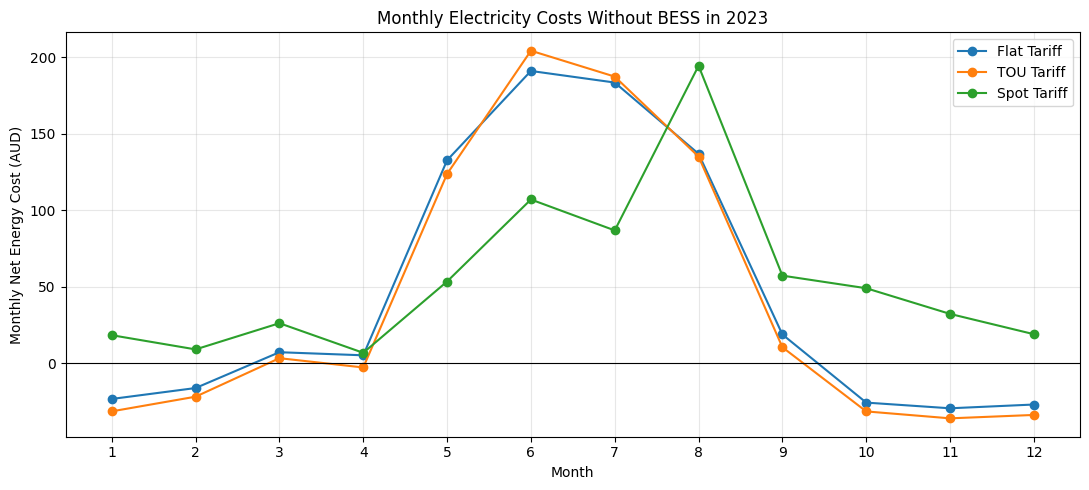

In [131]:
# Plot monthly electricity costs for three tariff scenarios
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_baseline_costs.index,
    monthly_baseline_costs["Flat"],
    marker="o",
    label="Flat Tariff"
)

plt.plot(
    monthly_baseline_costs.index,
    monthly_baseline_costs["TOU"],
    marker="o",
    label="TOU Tariff"
)

plt.plot(
    monthly_baseline_costs.index,
    monthly_baseline_costs["Spot"],
    marker="o",
    label="Spot Tariff"
)

# Format the figure
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Month")
plt.ylabel("Monthly Net Energy Cost (AUD)")
plt.title("Monthly Electricity Costs Without BESS in 2023")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [132]:
# Compare annual costs against Flat tariff
annual_tariff_comparison = baseline_cost_summary[
    ["Net energy cost (AUD)"]
].copy()

flat_baseline_cost = baseline_cost_summary.loc[
    "Flat", "Net energy cost (AUD)"
]

annual_tariff_comparison["Difference vs Flat (AUD)"] = (
    annual_tariff_comparison["Net energy cost (AUD)"] -
    flat_baseline_cost
)

annual_tariff_comparison["Difference vs Flat (%)"] = (
    annual_tariff_comparison["Difference vs Flat (AUD)"] /
    flat_baseline_cost * 100
)

# Identify the lowest-cost tariff for each month
monthly_best_tariff = monthly_baseline_costs.idxmin(axis=1)

# Count months with the lowest cost for each tariff
best_tariff_months = monthly_best_tariff.value_counts().reindex(
    ["Flat", "TOU", "Spot"], fill_value=0
)

# Display results
print("2023 annual tariff cost comparison:")
display(annual_tariff_comparison.round(2))

print("Number of months with the lowest net cost:")
display(best_tariff_months)

print("Lowest-cost tariff for each month:")
display(monthly_best_tariff)


2023 annual tariff cost comparison:


,Net energy cost (AUD),Difference vs Flat (AUD),Difference vs Flat (%)
Tariff,,,
Flat,553.39,0.00,0.00
Tou,506.57,-46.81,-8.46
Spot,659.49,106.10,19.17


Number of months with the lowest net cost:


Flat    0
TOU     9
Spot    3
Name: count, dtype: int64

Lowest-cost tariff for each month:


month
1      TOU
2      TOU
3      TOU
4      TOU
5     Spot
6     Spot
7     Spot
8      TOU
9      TOU
10     TOU
11     TOU
12     TOU
dtype: object

In [133]:
# Prepare five-minute input data for BESS optimisation
optimisation_input_2023 = baseline_data[
    [
        "timestamp",
        "grid_import_kWh",
        "grid_export_kWh",
        "flat_import_AUD/kWh",
        "flat_export_AUD/kWh",
        "tou_import_AUD/kWh",
        "tou_export_AUD/kWh",
        "spot_import_AUD/kWh",
        "spot_export_AUD/kWh"
    ]
].copy()

# Add original PV generation and household load
optimisation_input_2023 = optimisation_input_2023.merge(
    df_clean.loc[
        df_clean["timestamp"].dt.year == 2023,
        ["timestamp", "solar_kWh", "load_kWh"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Convert five-minute energy into average power
optimisation_input_2023["pv_kW"] = (
    optimisation_input_2023["solar_kWh"] * 12
)

optimisation_input_2023["load_kW"] = (
    optimisation_input_2023["load_kWh"] * 12
)

# Validate input data
input_validation = pd.Series({
    "Total records": len(optimisation_input_2023),
    "Duplicate timestamps": (
        optimisation_input_2023["timestamp"].duplicated().sum()
    ),
    "Missing values": optimisation_input_2023.isna().sum().sum(),
    "PV energy (kWh)": optimisation_input_2023["solar_kWh"].sum(),
    "Load energy (kWh)": optimisation_input_2023["load_kWh"].sum(),
    "Grid import without BESS (kWh)": (
        optimisation_input_2023["grid_import_kWh"].sum()
    ),
    "Grid export without BESS (kWh)": (
        optimisation_input_2023["grid_export_kWh"].sum()
    )
})

# Display results
print("2023 BESS optimisation input validation:")
display(input_validation.round(2))

print("First five optimisation input records:")
display(optimisation_input_2023.head().round(3))


2023 BESS optimisation input validation:


Total records                     105120.00
Duplicate timestamps                   0.00
Missing values                         0.00
PV energy (kWh)                    16827.63
Load energy (kWh)                   9597.81
Grid import without BESS (kWh)      4574.39
Grid export without BESS (kWh)     11804.21
dtype: float64

First five optimisation input records:


,timestamp,grid_import_kWh,grid_export_kWh,flat_import_AUD/kWh,flat_export_AUD/kWh,tou_import_AUD/kWh,tou_export_AUD/kWh,spot_import_AUD/kWh,spot_export_AUD/kWh,solar_kWh,load_kWh,pv_kW,load_kW
0,2023-01-01 00:00:00,0.036,0.0,0.25,0.05,0.15,0.05,0.083,0.083,0.0,0.036,0.0,0.43
1,2023-01-01 00:05:00,0.024,0.0,0.25,0.05,0.15,0.05,0.128,0.128,0.0,0.024,0.0,0.29
2,2023-01-01 00:10:00,0.024,0.0,0.25,0.05,0.15,0.05,0.123,0.123,0.0,0.024,0.0,0.29
3,2023-01-01 00:15:00,0.026,0.0,0.25,0.05,0.15,0.05,0.111,0.111,0.0,0.026,0.0,0.31
4,2023-01-01 00:20:00,0.030,0.0,0.25,0.05,0.15,0.05,0.110,0.110,0.0,0.030,0.0,0.36


In [134]:
# Select 2024 data
data_2024 = df_clean.loc[
    df_clean["timestamp"].dt.year == 2024
].copy()

# Check data completeness for each column
data_2024_completeness = pd.DataFrame({
    "Available records": data_2024.notna().sum(),
    "Missing records": data_2024.isna().sum(),
    "Completeness (%)": (
        data_2024.notna().mean() * 100
    )
})

# Check timestamps
timestamp_check_2024 = pd.Series({
    "Total records": len(data_2024),
    "Expected records": 366 * 24 * 12,
    "Duplicate timestamps": (
        data_2024["timestamp"].duplicated().sum()
    ),
    "First timestamp": data_2024["timestamp"].min(),
    "Last timestamp": data_2024["timestamp"].max()
})

# Display results
print("2024 timestamp validation:")
display(timestamp_check_2024)

print("2024 data completeness by column:")
display(data_2024_completeness.round(2))


2024 timestamp validation:


Total records                        105408
Expected records                     105408
Duplicate timestamps                      0
First timestamp         2024-01-01 00:00:00
Last timestamp          2024-12-31 23:55:00
dtype: object

2024 data completeness by column:


,Available records,Missing records,Completeness (%)
timestamp,105408,0,100.0
irradiance_W/m^2,105408,0,100.0
temperature_C,105408,0,100.0
solar_output_kW,0,105408,0.0
commercial_forecasted_solar_output_kW,105408,0,100.0
load_kW,105408,0,100.0
spot_price_AUD/kWh,0,105408,0.0
tariff_import_flat_AUD/kWh,105408,0,100.0
tariff_export_flat_AUD/kWh,105408,0,100.0
tariff_import_tou_AUD/kWh,105408,0,100.0


In [135]:
# Select 2024 commercial PV forecast
forecast_2024 = data_2024[
    ["timestamp", "commercial_forecasted_solar_output_kW",
     "irradiance_W/m^2", "temperature_C"]
].copy()

# Calculate forecast statistics
commercial_forecast_summary = pd.Series({
    "Total records": len(forecast_2024),
    "Missing forecast values": (
        forecast_2024["commercial_forecasted_solar_output_kW"].isna().sum()
    ),
    "Negative forecast values": (
        (forecast_2024["commercial_forecasted_solar_output_kW"] < 0).sum()
    ),
    "Zero forecast values": (
        (forecast_2024["commercial_forecasted_solar_output_kW"] == 0).sum()
    ),
    "Maximum forecast power (kW)": (
        forecast_2024["commercial_forecasted_solar_output_kW"].max()
    ),
    "Mean forecast power (kW)": (
        forecast_2024["commercial_forecasted_solar_output_kW"].mean()
    ),
    "Estimated annual PV energy (kWh)": (
        forecast_2024["commercial_forecasted_solar_output_kW"].sum() / 12
    ),
    "Forecast vs irradiance correlation": (
        forecast_2024["commercial_forecasted_solar_output_kW"].corr(
            forecast_2024["irradiance_W/m^2"]
        )
    )
})

# Display results
print("2024 commercial PV forecast validation:")
display(commercial_forecast_summary.round(3))


2024 commercial PV forecast validation:


Total records                         105408.000
Missing forecast values                    0.000
Negative forecast values                   0.000
Zero forecast values                   46379.000
Maximum forecast power (kW)                8.800
Mean forecast power (kW)                   1.945
Estimated annual PV energy (kWh)       17088.410
Forecast vs irradiance correlation         0.999
dtype: float64

In [136]:
# Select daytime records with positive irradiance
forecast_daytime = forecast_2024.loc[
    forecast_2024["irradiance_W/m^2"] > 200
].copy()

# Calculate forecast-to-irradiance ratio
forecast_daytime["forecast_ratio"] = (
    forecast_daytime["commercial_forecasted_solar_output_kW"] /
    forecast_daytime["irradiance_W/m^2"]
)

# Summarise the ratio
forecast_ratio_summary = forecast_daytime["forecast_ratio"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Group irradiance into ranges
irradiance_bins = [200, 400, 600, 800, 1000, np.inf]
irradiance_labels = [
    "200-400", "400-600", "600-800",
    "800-1000", ">1000"
]

forecast_daytime["irradiance_range"] = pd.cut(
    forecast_daytime["irradiance_W/m^2"],
    bins=irradiance_bins,
    labels=irradiance_labels,
    include_lowest=True
)

# Calculate average forecast power by irradiance range
forecast_irradiance_summary = forecast_daytime.groupby(
    "irradiance_range", observed=True
).agg(
    Records=("commercial_forecasted_solar_output_kW", "size"),
    Mean_forecast_kW=("commercial_forecasted_solar_output_kW", "mean"),
    Mean_irradiance=("irradiance_W/m^2", "mean"),
    Mean_ratio=("forecast_ratio", "mean")
)

# Display results
print("2024 commercial forecast-to-irradiance ratio:")
display(forecast_ratio_summary.round(5))

print("2024 commercial PV forecast by irradiance range:")
display(forecast_irradiance_summary.round(4))


2024 commercial forecast-to-irradiance ratio:


count     40269.00000
mean          0.00797
median        0.00798
std           0.00028
min           0.00680
max           0.00906
Name: forecast_ratio, dtype: float64

2024 commercial PV forecast by irradiance range:


,Records,Mean_forecast_kW,Mean_irradiance,Mean_ratio
irradiance_range,,,,
200-400,9806,2.4168,298.7902,0.0081
400-600,10355,4.0590,503.9844,0.0081
600-800,9920,5.5279,694.9605,0.0080
800-1000,7500,6.9674,896.7090,0.0078
>1000,2688,8.0799,1045.3646,0.0077


In [137]:
# Calculate monthly measured PV generation for 2023
monthly_pv_2023 = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023
].groupby(
    df_clean.loc[
        df_clean["timestamp"].dt.year == 2023,
        "timestamp"
    ].dt.month
)["solar_kWh"].sum()

# Calculate monthly commercial PV forecast for 2024
monthly_forecast_2024 = forecast_2024.groupby(
    forecast_2024["timestamp"].dt.month
)["commercial_forecasted_solar_output_kW"].sum() / 12

# Combine monthly results
monthly_pv_comparison = pd.DataFrame({
    "2023 measured PV (kWh)": monthly_pv_2023,
    "2024 commercial forecast (kWh)": monthly_forecast_2024
})

# Calculate monthly differences
monthly_pv_comparison["Difference (kWh)"] = (
    monthly_pv_comparison["2024 commercial forecast (kWh)"] -
    monthly_pv_comparison["2023 measured PV (kWh)"]
)

monthly_pv_comparison["Difference (%)"] = (
    monthly_pv_comparison["Difference (kWh)"] /
    monthly_pv_comparison["2023 measured PV (kWh)"] * 100
)

# Calculate annual comparison
annual_pv_comparison = monthly_pv_comparison[
    ["2023 measured PV (kWh)", "2024 commercial forecast (kWh)"]
].sum()

# Display results
print("Monthly PV generation comparison:")
display(monthly_pv_comparison.round(2))

print("Annual PV generation comparison:")
display(annual_pv_comparison.round(2))


Monthly PV generation comparison:


,2023 measured PV (kWh),2024 commercial forecast (kWh),Difference (kWh),Difference (%)
timestamp,,,,
1,1751.74,1883.57,131.83,7.53
2,1609.70,1755.26,145.55,9.04
3,1502.39,1397.60,-104.79,-6.97
4,1150.98,1307.20,156.21,13.57
5,1033.69,1060.47,26.78,2.59
6,750.96,773.65,22.69,3.02
7,928.30,949.92,21.61,2.33
8,1144.11,1190.63,46.53,4.07
9,1459.58,1409.51,-50.06,-3.43


Annual PV generation comparison:


2023 measured PV (kWh)            16827.63
2024 commercial forecast (kWh)    17088.41
dtype: float64

In [138]:
# Calculate annual household load for 2023 and 2024
annual_load_comparison = df_clean.groupby(
    df_clean["timestamp"].dt.year
)["load_kWh"].sum()

# Calculate monthly load for both years
monthly_load_comparison = df_clean.groupby(
    [
        df_clean["timestamp"].dt.year,
        df_clean["timestamp"].dt.month
    ]
)["load_kWh"].sum().unstack(level=0)

monthly_load_comparison.columns = [
    f"{year} load (kWh)"
    for year in monthly_load_comparison.columns
]

# Calculate monthly differences
monthly_load_comparison["Difference (kWh)"] = (
    monthly_load_comparison["2024 load (kWh)"] -
    monthly_load_comparison["2023 load (kWh)"]
)

monthly_load_comparison["Difference (%)"] = (
    monthly_load_comparison["Difference (kWh)"] /
    monthly_load_comparison["2023 load (kWh)"] * 100
)

# Calculate annual percentage change
annual_load_change = (
    (annual_load_comparison.loc[2024] -
     annual_load_comparison.loc[2023]) /
    annual_load_comparison.loc[2023] * 100
)

# Display results
print("Annual household load comparison (kWh):")
display(annual_load_comparison.round(2))

print("Annual load change (%):", round(annual_load_change, 2))

print("Monthly household load comparison:")
display(monthly_load_comparison.round(2))


Annual household load comparison (kWh):


timestamp
2023    9597.81
2024    9607.10
Name: load_kWh, dtype: float64

Annual load change (%): 0.1
Monthly household load comparison:


,2023 load (kWh),2024 load (kWh),Difference (kWh),Difference (%)
timestamp,,,,
1,592.35,593.56,1.21,0.20
2,598.91,616.13,17.22,2.88
3,653.73,649.17,-4.57,-0.70
4,525.41,525.41,0.00,0.00
5,1007.27,1005.98,-1.29,-0.13
6,1176.58,1176.79,0.21,0.02
7,1203.45,1203.03,-0.42,-0.04
8,1178.31,1178.31,0.00,0.00
9,723.40,722.94,-0.46,-0.06


In [139]:
# Prepare load data for both years
load_profile_compare = df_clean.loc[
    df_clean["timestamp"].dt.year.isin([2023, 2024]),
    ["timestamp", "load_kW"]
].copy()

# Create matching calendar fields
load_profile_compare["year"] = load_profile_compare["timestamp"].dt.year
load_profile_compare["month"] = load_profile_compare["timestamp"].dt.month
load_profile_compare["day"] = load_profile_compare["timestamp"].dt.day
load_profile_compare["hour"] = load_profile_compare["timestamp"].dt.hour
load_profile_compare["minute"] = load_profile_compare["timestamp"].dt.minute

# Match identical calendar times across both years
load_year_comparison = load_profile_compare.pivot(
    index=["month", "day", "hour", "minute"],
    columns="year",
    values="load_kW"
).dropna(subset=[2023, 2024])

# Calculate differences
load_year_comparison["Difference_kW"] = (
    load_year_comparison[2024] - load_year_comparison[2023]
)

# Calculate similarity statistics
load_similarity_summary = pd.Series({
    "Matched five-minute records": len(load_year_comparison),
    "Exact matching records": (
        load_year_comparison["Difference_kW"] == 0
    ).sum(),
    "Exact matching percentage (%)": (
        (load_year_comparison["Difference_kW"] == 0).mean() * 100
    ),
    "Mean absolute difference (kW)": (
        load_year_comparison["Difference_kW"].abs().mean()
    ),
    "Maximum absolute difference (kW)": (
        load_year_comparison["Difference_kW"].abs().max()
    ),
    "Pearson correlation": (
        load_year_comparison[2023].corr(load_year_comparison[2024])
    )
})

# Display results
print("2023–2024 household load similarity:")
display(load_similarity_summary.round(4))

print("First five matched load records:")
display(load_year_comparison.head().round(3))


2023–2024 household load similarity:


Matched five-minute records         105120.0000
Exact matching records              104129.0000
Exact matching percentage (%)           99.0573
Mean absolute difference (kW)            0.0044
Maximum absolute difference (kW)         4.1950
Pearson correlation                      0.9971
dtype: float64

First five matched load records:


year                   2023  2024  Difference_kW
month day hour minute                           
1     1   0    0       0.43  0.43            0.0
               5       0.29  0.29            0.0
               10      0.29  0.29            0.0
               15      0.31  0.31            0.0
               20      0.36  0.36            0.0

In [140]:
# Prepare 2024 forecast PV and household load data
pv_load_2024 = data_2024[
    [
        "timestamp",
        "commercial_forecasted_solar_output_kW",
        "load_kW"
    ]
].copy()

# Convert five-minute power to energy
pv_load_2024["pv_forecast_kWh"] = (
    pv_load_2024["commercial_forecasted_solar_output_kW"] / 12
)

pv_load_2024["load_kWh"] = (
    pv_load_2024["load_kW"] / 12
)

# Calculate direct PV self-consumption
pv_load_2024["pv_self_used_kWh"] = pv_load_2024[
    ["pv_forecast_kWh", "load_kWh"]
].min(axis=1)

# Calculate PV surplus and grid import without BESS
pv_load_2024["pv_surplus_kWh"] = (
    pv_load_2024["pv_forecast_kWh"] -
    pv_load_2024["pv_self_used_kWh"]
)

pv_load_2024["grid_import_kWh"] = (
    pv_load_2024["load_kWh"] -
    pv_load_2024["pv_self_used_kWh"]
)

# Summarise annual energy balance
energy_summary_2024 = pd.Series({
    "Forecast PV generation (kWh)": pv_load_2024["pv_forecast_kWh"].sum(),
    "Household load (kWh)": pv_load_2024["load_kWh"].sum(),
    "Direct PV self-consumption (kWh)": pv_load_2024["pv_self_used_kWh"].sum(),
    "PV surplus without BESS (kWh)": pv_load_2024["pv_surplus_kWh"].sum(),
    "Grid import without BESS (kWh)": pv_load_2024["grid_import_kWh"].sum()
})

# Check energy balances
energy_balance_2024 = pd.Series({
    "PV balance error (kWh)": (
        energy_summary_2024["Forecast PV generation (kWh)"] -
        energy_summary_2024["Direct PV self-consumption (kWh)"] -
        energy_summary_2024["PV surplus without BESS (kWh)"]
    ),
    "Load balance error (kWh)": (
        energy_summary_2024["Household load (kWh)"] -
        energy_summary_2024["Direct PV self-consumption (kWh)"] -
        energy_summary_2024["Grid import without BESS (kWh)"]
    )
})

# Display results
print("2024 forecast-based energy balance:")
display(energy_summary_2024.round(2))

print("2024 energy balance validation:")
display(energy_balance_2024.round(6))


2024 forecast-based energy balance:


Forecast PV generation (kWh)        17088.41
Household load (kWh)                 9607.10
Direct PV self-consumption (kWh)     5070.46
PV surplus without BESS (kWh)       12017.95
Grid import without BESS (kWh)       4536.64
dtype: float64

2024 energy balance validation:


PV balance error (kWh)     -0.0
Load balance error (kWh)    0.0
dtype: float64

In [141]:
# Select 2024 tariff data
tariff_2024 = data_2024[
    [
        "timestamp",
        "tariff_import_flat_AUD/kWh",
        "tariff_export_flat_AUD/kWh",
        "tariff_import_tou_AUD/kWh",
        "tariff_export_tou_AUD/kWh"
    ]
].copy()

# Merge tariffs with forecast-based energy data
baseline_2024 = pv_load_2024.merge(
    tariff_2024,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Calculate annual energy costs for each tariff
baseline_results_2024 = []

for tariff in ["flat", "tou"]:

    import_cost = (
        baseline_2024["grid_import_kWh"] *
        baseline_2024[f"tariff_import_{tariff}_AUD/kWh"]
    ).sum()

    export_revenue = (
        baseline_2024["pv_surplus_kWh"] *
        baseline_2024[f"tariff_export_{tariff}_AUD/kWh"]
    ).sum()

    baseline_results_2024.append({
        "Tariff": tariff.upper(),
        "Import cost (AUD)": import_cost,
        "Export revenue (AUD)": export_revenue,
        "Net energy cost (AUD)": import_cost - export_revenue
    })

# Create annual summary
baseline_cost_2024 = pd.DataFrame(
    baseline_results_2024
).set_index("Tariff")

# Validate tariff alignment
tariff_check_2024 = pd.Series({
    "Total records": len(baseline_2024),
    "Duplicate timestamps": baseline_2024["timestamp"].duplicated().sum(),
    "Missing values": baseline_2024.isna().sum().sum()
})

# Display results
print("2024 forecast-based baseline electricity costs:")
display(baseline_cost_2024.round(2))

print("2024 baseline data validation:")
display(tariff_check_2024)


2024 forecast-based baseline electricity costs:


,Import cost (AUD),Export revenue (AUD),Net energy cost (AUD)
Tariff,,,
FLAT,1360.99,600.9,760.10
TOU,1201.76,600.9,600.86


2024 baseline data validation:


Total records           105408
Duplicate timestamps         0
Missing values               0
dtype: int64

In [142]:
# Compare annual baseline costs for 2023 and 2024
two_year_baseline = pd.DataFrame({
    "2023 net cost (AUD)": baseline_cost_summary.loc[
        ["Flat", "Tou"], "Net energy cost (AUD)"
    ].values,
    "2024 net cost (AUD)": baseline_cost_2024.loc[
        ["FLAT", "TOU"], "Net energy cost (AUD)"
    ].values
}, index=["Flat", "TOU"])

# Calculate cost differences
two_year_baseline["Difference (AUD)"] = (
    two_year_baseline["2024 net cost (AUD)"] -
    two_year_baseline["2023 net cost (AUD)"]
)

two_year_baseline["Difference (%)"] = (
    two_year_baseline["Difference (AUD)"] /
    two_year_baseline["2023 net cost (AUD)"] * 100
)

# Compare tariff rates between the two years
tariff_columns_2023 = [
    "flat_import_AUD/kWh",
    "flat_export_AUD/kWh",
    "tou_import_AUD/kWh",
    "tou_export_AUD/kWh"
]

tariff_columns_2024 = [
    "tariff_import_flat_AUD/kWh",
    "tariff_export_flat_AUD/kWh",
    "tariff_import_tou_AUD/kWh",
    "tariff_export_tou_AUD/kWh"
]

tariff_rate_comparison = pd.DataFrame({
    "2023 mean (AUD/kWh)": (
        tariff_data[tariff_columns_2023].mean().values
    ),
    "2024 mean (AUD/kWh)": (
        data_2024[tariff_columns_2024].mean().values
    )
}, index=[
    "Flat import", "Flat export",
    "TOU import", "TOU export"
])

# Display results
print("2023–2024 baseline cost comparison:")
display(two_year_baseline.round(2))

print("2023–2024 tariff rate comparison:")
display(tariff_rate_comparison.round(4))


2023–2024 baseline cost comparison:


,2023 net cost (AUD),2024 net cost (AUD),Difference (AUD),Difference (%)
Flat,553.39,760.10,206.71,37.35
TOU,506.57,600.86,94.29,18.61


2023–2024 tariff rate comparison:


,2023 mean (AUD/kWh),2024 mean (AUD/kWh)
Flat import,0.2500,0.3000
Flat export,0.0500,0.0500
TOU import,0.2375,0.2417
TOU export,0.0500,0.0500


In [143]:
# Identify unique TOU rates for both years
tou_rates_2023 = sorted(
    tariff_data["tou_import_AUD/kWh"].unique()
)

tou_rates_2024 = sorted(
    data_2024["tariff_import_tou_AUD/kWh"].unique()
)

# Calculate the most common TOU rate for each hour
tou_hourly_2023 = tariff_data.groupby(
    tariff_data["timestamp"].dt.hour
)["tou_import_AUD/kWh"].agg(
    lambda x: x.mode().iloc[0]
)

tou_hourly_2024 = data_2024.groupby(
    data_2024["timestamp"].dt.hour
)["tariff_import_tou_AUD/kWh"].agg(
    lambda x: x.mode().iloc[0]
)

# Compare hourly rates
tou_hourly_comparison = pd.DataFrame({
    "2023 TOU (AUD/kWh)": tou_hourly_2023,
    "2024 TOU (AUD/kWh)": tou_hourly_2024
})

tou_hourly_comparison["Difference (AUD/kWh)"] = (
    tou_hourly_comparison["2024 TOU (AUD/kWh)"] -
    tou_hourly_comparison["2023 TOU (AUD/kWh)"]
)

# Calculate record distribution for 2024 TOU rates
tou_2024_distribution = data_2024.groupby(
    "tariff_import_tou_AUD/kWh"
).size().to_frame("Records")

tou_2024_distribution["Hours"] = (
    tou_2024_distribution["Records"] / 12
)

tou_2024_distribution["Percentage (%)"] = (
    tou_2024_distribution["Records"] / len(data_2024) * 100
)

# Display results
print("2023 TOU rates:", tou_rates_2023)
print("2024 TOU rates:", tou_rates_2024)

print("Hourly TOU tariff comparison:")
display(tou_hourly_comparison.round(3))

print("2024 TOU tariff distribution:")
display(tou_2024_distribution.round(2))


2023 TOU rates: [np.float64(0.15), np.float64(0.25), np.float64(0.4)]
2024 TOU rates: [np.float64(0.15), np.float64(0.25), np.float64(0.4)]
Hourly TOU tariff comparison:


,2023 TOU (AUD/kWh),2024 TOU (AUD/kWh),Difference (AUD/kWh)
timestamp,,,
0,0.15,0.15,0.00
1,0.15,0.15,0.00
2,0.15,0.15,0.00
3,0.15,0.15,0.00
4,0.15,0.15,0.00
5,0.15,0.15,0.00
6,0.15,0.15,0.00
7,0.25,0.25,0.00
8,0.25,0.25,0.00


2024 TOU tariff distribution:


,Records,Hours,Percentage (%)
tariff_import_tou_AUD/kWh,,,
0.15,35136,2928.0,33.33
0.25,52704,4392.0,50.00
0.40,17568,1464.0,16.67


In [144]:
# Prepare 2023 optimisation data
input_2023 = optimisation_input_2023[
    [
        "timestamp", "pv_kW", "load_kW",
        "flat_import_AUD/kWh", "flat_export_AUD/kWh",
        "tou_import_AUD/kWh", "tou_export_AUD/kWh",
        "spot_import_AUD/kWh", "spot_export_AUD/kWh"
    ]
].copy()

input_2023["pv_source"] = "Measured"

# Prepare 2024 optimisation data
input_2024 = baseline_2024[
    [
        "timestamp",
        "commercial_forecasted_solar_output_kW",
        "load_kW",
        "tariff_import_flat_AUD/kWh",
        "tariff_export_flat_AUD/kWh",
        "tariff_import_tou_AUD/kWh",
        "tariff_export_tou_AUD/kWh"
    ]
].copy()

input_2024.columns = [
    "timestamp", "pv_kW", "load_kW",
    "flat_import_AUD/kWh", "flat_export_AUD/kWh",
    "tou_import_AUD/kWh", "tou_export_AUD/kWh"
]

input_2024["spot_import_AUD/kWh"] = np.nan
input_2024["spot_export_AUD/kWh"] = np.nan
input_2024["pv_source"] = "Commercial forecast"

# Combine two years
optimisation_input = pd.concat(
    [input_2023, input_2024],
    ignore_index=True
).sort_values("timestamp").reset_index(drop=True)

# Add five-minute energy values
optimisation_input["pv_kWh"] = optimisation_input["pv_kW"] / 12
optimisation_input["load_kWh"] = optimisation_input["load_kW"] / 12

# Check annual records and energy totals
optimisation_input_summary = optimisation_input.groupby(
    optimisation_input["timestamp"].dt.year
).agg(
    Records=("timestamp", "size"),
    PV_kWh=("pv_kWh", "sum"),
    Load_kWh=("load_kWh", "sum")
)

# Check completeness of shared optimisation columns
shared_columns = [
    "timestamp", "pv_kW", "load_kW",
    "flat_import_AUD/kWh", "flat_export_AUD/kWh",
    "tou_import_AUD/kWh", "tou_export_AUD/kWh"
]

input_check = pd.Series({
    "Total records": len(optimisation_input),
    "Duplicate timestamps": optimisation_input["timestamp"].duplicated().sum(),
    "Missing shared input values": (
        optimisation_input[shared_columns].isna().sum().sum()
    )
})

# Display results
print("Two-year BESS optimisation input summary:")
display(optimisation_input_summary.round(2))

print("Combined input validation:")
display(input_check)

print("PV data sources:")
display(optimisation_input["pv_source"].value_counts())


Two-year BESS optimisation input summary:


,Records,PV_kWh,Load_kWh
timestamp,,,
2023,105120,16827.63,9597.81
2024,105408,17088.41,9607.10


Combined input validation:


Total records                  210528
Duplicate timestamps                0
Missing shared input values         0
dtype: int64

PV data sources:


pv_source
Commercial forecast    105408
Measured               105120
Name: count, dtype: int64

In [145]:
# Check five-minute timestamp continuity
time_difference = optimisation_input["timestamp"].diff()

# Check power and tariff ranges
power_range_summary = optimisation_input[
    ["pv_kW", "load_kW"]
].agg(["min", "mean", "max"]).T

# Check input validity
input_final_validation = pd.Series({
    "Total records": len(optimisation_input),
    "Incorrect time intervals": (
        (time_difference.dropna() != pd.Timedelta(minutes=5)).sum()
    ),
    "Negative PV power records": (
        (optimisation_input["pv_kW"] < 0).sum()
    ),
    "Negative load power records": (
        (optimisation_input["load_kW"] < 0).sum()
    ),
    "Missing Flat tariff values": (
        optimisation_input[
            ["flat_import_AUD/kWh", "flat_export_AUD/kWh"]
        ].isna().sum().sum()
    ),
    "Missing TOU tariff values": (
        optimisation_input[
            ["tou_import_AUD/kWh", "tou_export_AUD/kWh"]
        ].isna().sum().sum()
    ),
    "Missing Spot tariff values": (
        optimisation_input[
            ["spot_import_AUD/kWh", "spot_export_AUD/kWh"]
        ].isna().sum().sum()
    )
})

# Display results
print("BESS optimisation input power ranges (kW):")
display(power_range_summary.round(3))

print("Final optimisation input validation:")
display(input_final_validation)


BESS optimisation input power ranges (kW):


,min,mean,max
pv_kW,0.00,1.933,11.54
load_kW,0.15,1.095,6.37


Final optimisation input validation:


Total records                  210528
Incorrect time intervals            0
Negative PV power records           0
Negative load power records         0
Missing Flat tariff values          0
Missing TOU tariff values           0
Missing Spot tariff values     210816
dtype: int64

In [146]:
# Define initial AC-coupled BESS parameters
bess_parameters = {
    "capacity_kWh": 10.0,
    "max_charge_kW": 5.0,
    "max_discharge_kW": 5.0,
    "soc_min": 0.10,
    "soc_max": 0.90,
    "soc_initial": 0.50,
    "charge_efficiency": 0.95,
    "discharge_efficiency": 0.95,
    "time_step_hours": 5 / 60,
    "topology": "AC-coupled"
}

# Calculate derived battery parameters
bess_capacity = bess_parameters["capacity_kWh"]

bess_min_energy = (
    bess_capacity * bess_parameters["soc_min"]
)

bess_max_energy = (
    bess_capacity * bess_parameters["soc_max"]
)

bess_initial_energy = (
    bess_capacity * bess_parameters["soc_initial"]
)

bess_usable_energy = bess_max_energy - bess_min_energy

bess_round_trip_efficiency = (
    bess_parameters["charge_efficiency"] *
    bess_parameters["discharge_efficiency"]
)

bess_max_charge_energy = (
    bess_parameters["max_charge_kW"] *
    bess_parameters["time_step_hours"]
)

bess_max_discharge_energy = (
    bess_parameters["max_discharge_kW"] *
    bess_parameters["time_step_hours"]
)

# Summarise battery operating limits
bess_limit_summary = pd.Series({
    "Nominal capacity (kWh)": bess_capacity,
    "Minimum stored energy (kWh)": bess_min_energy,
    "Maximum stored energy (kWh)": bess_max_energy,
    "Initial stored energy (kWh)": bess_initial_energy,
    "Usable energy (kWh)": bess_usable_energy,
    "Round-trip efficiency (%)": (
        bess_round_trip_efficiency * 100
    ),
    "Maximum charging energy per step (kWh)": (
        bess_max_charge_energy
    ),
    "Maximum discharging energy per step (kWh)": (
        bess_max_discharge_energy
    )
})

# Validate parameter assumptions
bess_parameter_check = pd.Series({
    "Valid SOC limits": (
        0 <= bess_parameters["soc_min"] <
        bess_parameters["soc_initial"] <
        bess_parameters["soc_max"] <= 1
    ),
    "Valid efficiencies": (
        0 < bess_parameters["charge_efficiency"] <= 1 and
        0 < bess_parameters["discharge_efficiency"] <= 1
    ),
    "Positive battery capacity": bess_capacity > 0,
    "Positive power limits": (
        bess_parameters["max_charge_kW"] > 0 and
        bess_parameters["max_discharge_kW"] > 0
    )
})

# Display results
print("Initial BESS operating parameters:")
display(bess_limit_summary.round(4))

print("BESS parameter validation:")
display(bess_parameter_check)


Initial BESS operating parameters:


Nominal capacity (kWh)                       10.0000
Minimum stored energy (kWh)                   1.0000
Maximum stored energy (kWh)                   9.0000
Initial stored energy (kWh)                   5.0000
Usable energy (kWh)                           8.0000
Round-trip efficiency (%)                    90.2500
Maximum charging energy per step (kWh)        0.4167
Maximum discharging energy per step (kWh)     0.4167
dtype: float64

BESS parameter validation:


Valid SOC limits             True
Valid efficiencies           True
Positive battery capacity    True
Positive power limits        True
dtype: bool

In [147]:
# Define BESS SOC update function
def update_bess_energy(
    current_energy,
    charge_energy,
    discharge_energy,
    parameters
):
    # Read battery parameters
    capacity = parameters["capacity_kWh"]
    eta_charge = parameters["charge_efficiency"]
    eta_discharge = parameters["discharge_efficiency"]
    dt = parameters["time_step_hours"]

    minimum_energy = capacity * parameters["soc_min"]
    maximum_energy = capacity * parameters["soc_max"]

    maximum_charge = parameters["max_charge_kW"] * dt
    maximum_discharge = parameters["max_discharge_kW"] * dt

    # Check current energy
    if not minimum_energy <= current_energy <= maximum_energy:
        raise ValueError("Current battery energy is outside SOC limits.")

    # Check non-negative energy
    if charge_energy < 0 or discharge_energy < 0:
        raise ValueError("Charge and discharge energy must be non-negative.")

    # Check charging and discharging power limits
    if charge_energy > maximum_charge + 1e-9:
        raise ValueError("Charging power exceeds the battery limit.")

    if discharge_energy > maximum_discharge + 1e-9:
        raise ValueError("Discharging power exceeds the battery limit.")

    # Prevent simultaneous charging and discharging
    if charge_energy > 0 and discharge_energy > 0:
        raise ValueError("Simultaneous charging and discharging is not allowed.")

    # Calculate updated stored energy
    next_energy = (
        current_energy
        + charge_energy * eta_charge
        - discharge_energy / eta_discharge
    )

    # Check SOC limits
    if not minimum_energy - 1e-9 <= next_energy <= maximum_energy + 1e-9:
        raise ValueError("Updated battery energy exceeds SOC limits.")

    return next_energy


# Test BESS energy update under different operating conditions
bess_test_cases = [
    ("Idle", 5.0, 0.0, 0.0),
    ("Charging", 5.0, 0.4, 0.0),
    ("Discharging", 5.0, 0.0, 0.4),
    ("Charge near SOC maximum", 8.9, 0.4, 0.0),
    ("Discharge near SOC minimum", 1.1, 0.0, 0.4),
    ("Simultaneous charge/discharge", 5.0, 0.2, 0.2)
]

bess_test_results = []

for name, initial_energy, charge, discharge in bess_test_cases:
    try:
        final_energy = update_bess_energy(
            initial_energy, charge, discharge, bess_parameters
        )
        status = "Valid"
    except ValueError:
        final_energy = np.nan
        status = "Rejected"

    bess_test_results.append({
        "Test": name,
        "Initial energy (kWh)": initial_energy,
        "Charge (kWh)": charge,
        "Discharge (kWh)": discharge,
        "Final energy (kWh)": final_energy,
        "Status": status
    })

# Display results
bess_soc_test_summary = pd.DataFrame(bess_test_results)

print("BESS SOC dynamics validation:")
display(bess_soc_test_summary.round(4))


BESS SOC dynamics validation:


,Test,Initial energy (kWh),Charge (kWh),Discharge (kWh),Final energy (kWh),Status
0,Idle,5.0,0.0,0.0,5.0000,Valid
1,Charging,5.0,0.4,0.0,5.3800,Valid
2,Discharging,5.0,0.0,0.4,4.5789,Valid
3,Charge near SOC maximum,8.9,0.4,0.0,NaN,Rejected
4,Discharge near SOC minimum,1.1,0.0,0.4,NaN,Rejected
5,Simultaneous charge/discharge,5.0,0.2,0.2,NaN,Rejected


In [148]:
# Define terminal SOC settings
bess_terminal_settings = {
    "mode": "cyclic",
    "target_soc": 0.50,
    "tolerance": 1e-6
}

# Define function to check terminal SOC constraints
def check_terminal_soc(
    initial_energy,
    final_energy,
    parameters,
    settings
):
    capacity = parameters["capacity_kWh"]
    target_energy = capacity * settings["target_soc"]
    tolerance = settings["tolerance"]
    mode = settings["mode"]

    if mode == "fixed":
        return abs(final_energy - target_energy) <= tolerance

    elif mode == "cyclic":
        return abs(final_energy - initial_energy) <= tolerance

    elif mode == "minimum":
        return final_energy >= target_energy - tolerance

    else:
        raise ValueError("Unknown terminal SOC mode.")


# Test terminal SOC constraints
terminal_test_cases = [
    ("Same initial and final SOC", 5.0, 5.0),
    ("Higher final SOC", 5.0, 6.0),
    ("Lower final SOC", 5.0, 4.0),
    ("Near-equal final SOC", 5.0, 5.0000005)
]

terminal_test_results = []

for name, initial_energy, final_energy in terminal_test_cases:
    result = {
        "Test": name,
        "Initial energy (kWh)": initial_energy,
        "Final energy (kWh)": final_energy
    }

    for mode in ["fixed", "cyclic", "minimum"]:
        settings = bess_terminal_settings.copy()
        settings["mode"] = mode

        result[mode.capitalize()] = check_terminal_soc(
            initial_energy,
            final_energy,
            bess_parameters,
            settings
        )

    terminal_test_results.append(result)

# Display results
terminal_soc_summary = pd.DataFrame(terminal_test_results)

print("BESS terminal SOC constraint validation:")
display(terminal_soc_summary)


BESS terminal SOC constraint validation:


,Test,Initial energy (kWh),Final energy (kWh),Fixed,Cyclic,Minimum
0,Same initial and final SOC,5.0,5.0,True,True,True
1,Higher final SOC,5.0,6.0,False,False,True
2,Lower final SOC,5.0,4.0,False,False,False
3,Near-equal final SOC,5.0,5.0,True,True,True


In [149]:
# Define grid connection and PV curtailment settings
grid_parameters = {
    "max_import_kW": 15.0,
    "max_export_kW": 10.0,
    "curtailment_allowed": True,
    "simultaneous_import_export": False
}

# Check AC-side power balance for one five-minute interval
def check_ac_power_balance(
    pv_power,
    load_power,
    battery_charge,
    battery_discharge,
    grid_import,
    grid_export,
    pv_curtailment,
    parameters,
    tolerance=1e-6
):
    # Check non-negative power values
    powers = [
        pv_power, load_power, battery_charge,
        battery_discharge, grid_import,
        grid_export, pv_curtailment
    ]

    if any(power < 0 for power in powers):
        return False

    # Check grid power limits
    if grid_import > parameters["max_import_kW"] + tolerance:
        return False

    if grid_export > parameters["max_export_kW"] + tolerance:
        return False

    # Check PV curtailment
    if pv_curtailment > pv_power + tolerance:
        return False

    if not parameters["curtailment_allowed"] and pv_curtailment > tolerance:
        return False

    # Prevent simultaneous grid import and export
    if not parameters["simultaneous_import_export"]:
        if grid_import > tolerance and grid_export > tolerance:
            return False

    # Check AC power balance
    supply = pv_power + grid_import + battery_discharge

    demand = (
        load_power + battery_charge +
        grid_export + pv_curtailment
    )

    return abs(supply - demand) <= tolerance


# Test power balance and grid constraints
grid_test_cases = [
    ("PV supplies load", 5, 3, 0, 0, 0, 2, 0),
    ("Battery charging", 5, 3, 2, 0, 0, 0, 0),
    ("Battery discharging", 1, 4, 0, 3, 0, 0, 0),
    ("PV curtailment", 12, 2, 0, 0, 0, 10, 0),
    ("Export limit exceeded", 12, 1, 0, 0, 0, 11, 0),
    ("Import and export together", 5, 3, 0, 0, 2, 4, 0),
    ("Incorrect power balance", 5, 3, 0, 0, 0, 1, 0)
]

grid_test_results = []

for case in grid_test_cases:
    name, pv, load, charge, discharge, imp, exp, curtail = case

    valid = check_ac_power_balance(
        pv, load, charge, discharge,
        imp, exp, curtail, grid_parameters
    )

    grid_test_results.append({
        "Test": name,
        "Valid": valid
    })

# Display results
grid_constraint_summary = pd.DataFrame(grid_test_results)

print("Grid and PV curtailment constraint validation:")
display(grid_constraint_summary)


Grid and PV curtailment constraint validation:


,Test,Valid
0,PV supplies load,True
1,Battery charging,True
2,Battery discharging,True
3,PV curtailment,True
4,Export limit exceeded,False
5,Import and export together,False
6,Incorrect power balance,False


In [150]:
# Test actual PV curtailment
curtailment_test = check_ac_power_balance(
    pv_power=12.0,
    load_power=1.0,
    battery_charge=0.0,
    battery_discharge=0.0,
    grid_import=0.0,
    grid_export=10.0,
    pv_curtailment=1.0,
    parameters=grid_parameters
)

# Define assumed temperature derating factors
def bess_temperature_factor(temperature):
    if temperature < 0:
        return 0.50
    elif temperature <= 40:
        return 1.00
    else:
        return 0.70


# Calculate temperature-dependent power limits
temperature_test_values = [-10, 0, 20, 40, 45]

temperature_power_results = []

for temperature in temperature_test_values:
    factor = bess_temperature_factor(temperature)

    temperature_power_results.append({
        "Temperature (C)": temperature,
        "Power factor": factor,
        "Max charge power (kW)": (
            bess_parameters["max_charge_kW"] * factor
        ),
        "Max discharge power (kW)": (
            bess_parameters["max_discharge_kW"] * factor
        )
    })

temperature_power_summary = pd.DataFrame(
    temperature_power_results
)

# Validate temperature factors and power limits
temperature_validation = pd.Series({
    "Actual PV curtailment test valid": curtailment_test,
    "All power factors between 0 and 1": (
        temperature_power_summary["Power factor"].between(0, 1).all()
    ),
    "Charging limits within rated power": (
        temperature_power_summary["Max charge power (kW)"].le(
            bess_parameters["max_charge_kW"]
        ).all()
    ),
    "Discharging limits within rated power": (
        temperature_power_summary["Max discharge power (kW)"].le(
            bess_parameters["max_discharge_kW"]
        ).all()
    )
})

# Display results
print("Temperature-dependent BESS power limits:")
display(temperature_power_summary.round(2))

print("PV curtailment and temperature constraint validation:")
display(temperature_validation)


Temperature-dependent BESS power limits:


,Temperature (C),Power factor,Max charge power (kW),Max discharge power (kW)
0,-10,0.5,2.5,2.5
1,0,1.0,5.0,5.0
2,20,1.0,5.0,5.0
3,40,1.0,5.0,5.0
4,45,0.7,3.5,3.5


PV curtailment and temperature constraint validation:


Actual PV curtailment test valid         True
All power factors between 0 and 1        True
Charging limits within rated power       True
Discharging limits within rated power    True
dtype: bool

In [151]:
# Define battery degradation assumptions
bess_degradation_parameters = {
    "replacement_cost_AUD": 5000.0,
    "cycle_life_EFC": 6000.0,
    "degradation_model": "linear_discharge_throughput"
}

# Calculate degradation cost parameters
degradation_cost_per_cycle = (
    bess_degradation_parameters["replacement_cost_AUD"] /
    bess_degradation_parameters["cycle_life_EFC"]
)

degradation_cost_per_internal_kWh = (
    degradation_cost_per_cycle / bess_usable_energy
)

degradation_cost_per_AC_kWh = (
    degradation_cost_per_internal_kWh /
    bess_parameters["discharge_efficiency"]
)

# Define degradation calculation function
def calculate_bess_degradation(
    discharge_energy_AC,
    parameters=bess_parameters
):
    # Convert AC discharge energy to internal battery energy
    internal_discharge_energy = (
        discharge_energy_AC /
        parameters["discharge_efficiency"]
    )

    # Calculate equivalent full cycles
    equivalent_cycles = (
        internal_discharge_energy / bess_usable_energy
    )

    # Calculate degradation cost
    degradation_cost = (
        equivalent_cycles * degradation_cost_per_cycle
    )

    return equivalent_cycles, degradation_cost


# Test degradation model with assumed AC discharge energy
degradation_test_values = [0, 2, 4, 8, 16]

degradation_test_results = []

for discharge_energy in degradation_test_values:
    cycles, cost = calculate_bess_degradation(discharge_energy)

    degradation_test_results.append({
        "AC discharge energy (kWh)": discharge_energy,
        "Equivalent full cycles": cycles,
        "Degradation cost (AUD)": cost
    })

# Display results
degradation_test_summary = pd.DataFrame(degradation_test_results)

degradation_parameter_summary = pd.Series({
    "Replacement cost (AUD)": (
        bess_degradation_parameters["replacement_cost_AUD"]
    ),
    "Cycle life (EFC)": (
        bess_degradation_parameters["cycle_life_EFC"]
    ),
    "Cost per EFC (AUD)": degradation_cost_per_cycle,
    "Cost per internal discharge kWh (AUD)": (
        degradation_cost_per_internal_kWh
    ),
    "Cost per AC discharge kWh (AUD)": (
        degradation_cost_per_AC_kWh
    )
})

print("BESS degradation cost parameters:")
display(degradation_parameter_summary.round(4))

print("BESS degradation model test:")
display(degradation_test_summary.round(4))


BESS degradation cost parameters:


Replacement cost (AUD)                   5000.0000
Cycle life (EFC)                         6000.0000
Cost per EFC (AUD)                          0.8333
Cost per internal discharge kWh (AUD)       0.1042
Cost per AC discharge kWh (AUD)             0.1096
dtype: float64

BESS degradation model test:


,AC discharge energy (kWh),Equivalent full cycles,Degradation cost (AUD)
0,0,0.0000,0.0000
1,2,0.2632,0.2193
2,4,0.5263,0.4386
3,8,1.0526,0.8772
4,16,2.1053,1.7544


In [152]:
# Define BESS operating cost calculation
def calculate_bess_operating_cost(
    grid_import_kWh,
    grid_export_kWh,
    battery_discharge_kWh,
    import_price,
    export_price,
    degradation_cost_per_kWh
):
    # Calculate grid import cost
    import_cost = (
        grid_import_kWh * import_price
    )

    # Calculate grid export revenue
    export_revenue = (
        grid_export_kWh * export_price
    )

    # Calculate battery degradation cost
    degradation_cost = (
        battery_discharge_kWh * degradation_cost_per_kWh
    )

    # Calculate total net operating cost
    net_cost = (
        import_cost - export_revenue + degradation_cost
    )

    return {
        "Import cost (AUD)": import_cost,
        "Export revenue (AUD)": export_revenue,
        "Degradation cost (AUD)": degradation_cost,
        "Net operating cost (AUD)": net_cost
    }


# Define test scenarios
objective_test_cases = [
    {
        "Scenario": "Grid import only",
        "Import_kWh": 2.0,
        "Export_kWh": 0.0,
        "Discharge_kWh": 0.0,
        "Import_price": 0.25,
        "Export_price": 0.05
    },
    {
        "Scenario": "PV export only",
        "Import_kWh": 0.0,
        "Export_kWh": 3.0,
        "Discharge_kWh": 0.0,
        "Import_price": 0.25,
        "Export_price": 0.05
    },
    {
        "Scenario": "Battery discharge",
        "Import_kWh": 1.0,
        "Export_kWh": 0.0,
        "Discharge_kWh": 2.0,
        "Import_price": 0.40,
        "Export_price": 0.05
    }
]

# Test objective function
objective_test_results = []

for case in objective_test_cases:

    result = calculate_bess_operating_cost(
        grid_import_kWh=case["Import_kWh"],
        grid_export_kWh=case["Export_kWh"],
        battery_discharge_kWh=case["Discharge_kWh"],
        import_price=case["Import_price"],
        export_price=case["Export_price"],
        degradation_cost_per_kWh=degradation_cost_per_AC_kWh
    )

    result["Scenario"] = case["Scenario"]
    objective_test_results.append(result)

# Create summary table
objective_test_summary = pd.DataFrame(
    objective_test_results
).set_index("Scenario")

# Display results
print("BESS economic objective function validation:")
display(objective_test_summary.round(4))


BESS economic objective function validation:


,Import cost (AUD),Export revenue (AUD),Degradation cost (AUD),Net operating cost (AUD)
Scenario,,,,
Grid import only,0.5,0.00,0.0000,0.5000
PV export only,0.0,0.15,0.0000,-0.1500
Battery discharge,0.4,0.00,0.2193,0.6193


In [153]:
# Check MILP optimisation environment
import sys
import pulp

# Display Python and PuLP versions
print("Python version:", sys.version.split()[0])
print("PuLP version:", pulp.__version__)

# Check available MILP solvers
available_solvers = pulp.listSolvers(onlyAvailable=True)

print("Available MILP solvers:")
display(available_solvers)

# Check CBC solver availability
cbc_solver = pulp.PULP_CBC_CMD()
cbc_available = bool(cbc_solver.available())

print("CBC solver available:", cbc_available)

# Test CBC solver with a simple optimisation problem
if cbc_available:
    test_model = pulp.LpProblem(
        "CBC_Test",
        pulp.LpMinimize
    )

    # Define a binary decision variable
    x = pulp.LpVariable(
        "x",
        cat="Binary"
    )

    # Define objective function and constraint
    test_model += x
    test_model += x >= 1

    # Solve the test problem
    test_model.solve(pulp.PULP_CBC_CMD(msg=False))

    print("Solver test status:",
          pulp.LpStatus[test_model.status])
    print("Test variable x:", pulp.value(x))

else:
    print("CBC solver is not available.")



Python version: 3.11.0
PuLP version: 3.3.2
Available MILP solvers:


['PULP_CBC_CMD']

CBC solver available: True
Solver test status: Optimal
Test variable x: 1.0


In [154]:
# Select a one-hour test period from 2023
milp_test_data = optimisation_input.loc[
    optimisation_input["timestamp"].dt.year == 2023
].head(12).copy().reset_index(drop=True)

# Define time indices
T = len(milp_test_data)
time_steps = range(T)
soc_steps = range(T + 1)

# Create MILP minimisation model
bess_milp = pulp.LpProblem(
    "BESS_Optimisation_Test",
    pulp.LpMinimize
)

# Define battery charging and discharging power (kW)
charge = pulp.LpVariable.dicts(
    "Charge", time_steps, lowBound=0
)

discharge = pulp.LpVariable.dicts(
    "Discharge", time_steps, lowBound=0
)

# Define battery stored energy (kWh)
soc_energy = pulp.LpVariable.dicts(
    "Stored_Energy",
    soc_steps,
    lowBound=bess_min_energy,
    upBound=bess_max_energy
)

# Define grid import and export power (kW)
grid_import = pulp.LpVariable.dicts(
    "Grid_Import", time_steps, lowBound=0
)

grid_export = pulp.LpVariable.dicts(
    "Grid_Export", time_steps, lowBound=0
)

# Define PV curtailment power (kW)
curtailment = pulp.LpVariable.dicts(
    "PV_Curtailment", time_steps, lowBound=0
)

# Define binary operating modes
battery_mode = pulp.LpVariable.dicts(
    "Battery_Mode", time_steps, cat="Binary"
)

grid_mode = pulp.LpVariable.dicts(
    "Grid_Mode", time_steps, cat="Binary"
)

# Summarise decision variables
variable_summary = pd.Series({
    "Time intervals": T,
    "Charge variables": len(charge),
    "Discharge variables": len(discharge),
    "SOC variables": len(soc_energy),
    "Grid import variables": len(grid_import),
    "Grid export variables": len(grid_export),
    "PV curtailment variables": len(curtailment),
    "Battery binary variables": len(battery_mode),
    "Grid binary variables": len(grid_mode)
})

# Display results
print("MILP decision variable summary:")
display(variable_summary)

print("MILP model name:", bess_milp.name)
print("Initial model constraints:", len(bess_milp.constraints))


MILP decision variable summary:


Time intervals              12
Charge variables            12
Discharge variables         12
SOC variables               13
Grid import variables       12
Grid export variables       12
PV curtailment variables    12
Battery binary variables    12
Grid binary variables       12
dtype: int64

MILP model name: BESS_Optimisation_Test
Initial model constraints: 0


In [155]:
# Define MILP operating parameters
dt = bess_parameters["time_step_hours"]
eta_charge = bess_parameters["charge_efficiency"]
eta_discharge = bess_parameters["discharge_efficiency"]

# Use rated power without temperature derating for this test
temperature_factor = 1.0

max_charge_power = (
    bess_parameters["max_charge_kW"] * temperature_factor
)

max_discharge_power = (
    bess_parameters["max_discharge_kW"] * temperature_factor
)

# Define initial and terminal SOC constraints
bess_milp += (
    soc_energy[0] == bess_initial_energy,
    "Initial_SOC"
)

bess_milp += (
    soc_energy[T] == soc_energy[0],
    "Terminal_Cyclic_SOC"
)

# Add operating constraints for each time interval
for t in time_steps:

    # Read PV generation and household load
    pv = float(milp_test_data.loc[t, "pv_kW"])
    load = float(milp_test_data.loc[t, "load_kW"])

    # Battery SOC dynamics
    bess_milp += (
        soc_energy[t + 1] ==
        soc_energy[t]
        + eta_charge * charge[t] * dt
        - discharge[t] * dt / eta_discharge,
        f"SOC_Balance_{t}"
    )

    # Battery charging and discharging limits
    bess_milp += (
        charge[t] <= max_charge_power * battery_mode[t],
        f"Charge_Limit_{t}"
    )

    bess_milp += (
        discharge[t] <= max_discharge_power * (1 - battery_mode[t]),
        f"Discharge_Limit_{t}"
    )

    # Grid import and export limits
    bess_milp += (
        grid_import[t] <=
        grid_parameters["max_import_kW"] * grid_mode[t],
        f"Grid_Import_Limit_{t}"
    )

    bess_milp += (
        grid_export[t] <=
        grid_parameters["max_export_kW"] * (1 - grid_mode[t]),
        f"Grid_Export_Limit_{t}"
    )

    # PV curtailment cannot exceed available PV
    bess_milp += (
        curtailment[t] <= pv,
        f"PV_Curtailment_Limit_{t}"
    )

    # AC-side power balance
    bess_milp += (
        pv + grid_import[t] + discharge[t] ==
        load + charge[t] + grid_export[t] + curtailment[t],
        f"AC_Power_Balance_{t}"
    )

# Summarise model constraints
constraint_summary = pd.Series({
    "Initial SOC constraints": 1,
    "Terminal SOC constraints": 1,
    "SOC balance constraints": T,
    "Battery power constraints": 2 * T,
    "Grid power constraints": 2 * T,
    "PV curtailment constraints": T,
    "AC power balance constraints": T,
    "Total constraints": len(bess_milp.constraints)
})

# Display results
print("MILP operating constraint summary:")
display(constraint_summary)

print("MILP model name:", bess_milp.name)


MILP operating constraint summary:


Initial SOC constraints          1
Terminal SOC constraints         1
SOC balance constraints         12
Battery power constraints       24
Grid power constraints          24
PV curtailment constraints      12
AC power balance constraints    12
Total constraints               86
dtype: int64

MILP model name: BESS_Optimisation_Test


In [156]:
# Select tariff for the MILP test
test_tariff = "flat"

# Define tariff column names
import_price_column = f"{test_tariff}_import_AUD/kWh"
export_price_column = f"{test_tariff}_export_AUD/kWh"

# Calculate total electricity import cost
milp_import_cost = pulp.lpSum(
    grid_import[t] *
    float(milp_test_data.loc[t, import_price_column]) * dt
    for t in time_steps
)

# Calculate total electricity export revenue
milp_export_revenue = pulp.lpSum(
    grid_export[t] *
    float(milp_test_data.loc[t, export_price_column]) * dt
    for t in time_steps
)

# Calculate battery degradation cost
milp_degradation_cost = pulp.lpSum(
    discharge[t] * dt * degradation_cost_per_AC_kWh
    for t in time_steps
)

# Add economic objective function
bess_milp += (
    milp_import_cost
    - milp_export_revenue
    + milp_degradation_cost,
    "Minimise_Net_Operating_Cost"
)

# Check objective function and model structure
milp_objective_summary = pd.Series({
    "Time intervals": T,
    "Tariff": test_tariff,
    "Degradation cost (AUD/AC kWh)": (
        degradation_cost_per_AC_kWh
    ),
    "Total constraints": len(bess_milp.constraints),
    "Model variables": len(bess_milp.variables()),
    "Objective defined": bess_milp.objective is not None
})

# Display results
print("MILP economic objective function summary:")
display(milp_objective_summary)


MILP economic objective function summary:


Time intervals                         12
Tariff                               flat
Degradation cost (AUD/AC kWh)    0.109649
Total constraints                      86
Model variables                        97
Objective defined                    True
dtype: object

In [157]:

# Solve MILP test model
solver = pulp.PULP_CBC_CMD(msg=False)
bess_milp.solve(solver)

solution_status = pulp.LpStatus[bess_milp.status]

print("MILP solution status:", solution_status)

# Extract results only if the solution is optimal
if solution_status == "Optimal":

    # Extract five-minute dispatch results
    milp_results = pd.DataFrame({
        "timestamp": milp_test_data["timestamp"],
        "pv_kW": milp_test_data["pv_kW"],
        "load_kW": milp_test_data["load_kW"],
        "charge_kW": [
            pulp.value(charge[t]) for t in time_steps
        ],
        "discharge_kW": [
            pulp.value(discharge[t]) for t in time_steps
        ],
        "grid_import_kW": [
            pulp.value(grid_import[t]) for t in time_steps
        ],
        "grid_export_kW": [
            pulp.value(grid_export[t]) for t in time_steps
        ],
        "curtailment_kW": [
            pulp.value(curtailment[t]) for t in time_steps
        ],
        "soc_kWh": [
            pulp.value(soc_energy[t + 1]) for t in time_steps
        ]
    })

    # Calculate AC-side power balance error
    milp_results["power_balance_error_kW"] = (
        milp_results["pv_kW"]
        + milp_results["grid_import_kW"]
        + milp_results["discharge_kW"]
        - milp_results["load_kW"]
        - milp_results["charge_kW"]
        - milp_results["grid_export_kW"]
        - milp_results["curtailment_kW"]
    )

    # Calculate baseline grid energy without BESS
    baseline_import_kWh = (
        milp_test_data["load_kW"]
        - milp_test_data["pv_kW"]
    ).clip(lower=0) * dt

    baseline_export_kWh = (
        milp_test_data["pv_kW"]
        - milp_test_data["load_kW"]
    ).clip(lower=0) * dt

    # Calculate baseline electricity cost without BESS
    baseline_test_cost = (
        (
            baseline_import_kWh *
            milp_test_data[import_price_column]
        ).sum()
        -
        (
            baseline_export_kWh *
            milp_test_data[export_price_column]
        ).sum()
    )

    # Calculate optimised electricity costs
    optimised_import_cost = pulp.value(milp_import_cost)
    optimised_export_revenue = pulp.value(milp_export_revenue)
    optimised_degradation_cost = pulp.value(milp_degradation_cost)

    # Calculate optimised net operating cost
    optimised_test_cost = pulp.value(bess_milp.objective)

    # Calculate operating cost savings
    test_savings = baseline_test_cost - optimised_test_cost

    # Validate SOC and operating constraints
    milp_solution_check = pd.Series({
        "Solver status": solution_status,
        "Initial SOC energy (kWh)": pulp.value(soc_energy[0]),
        "Final SOC energy (kWh)": pulp.value(soc_energy[T]),
        "Minimum SOC energy (kWh)": milp_results["soc_kWh"].min(),
        "Maximum SOC energy (kWh)": milp_results["soc_kWh"].max(),
        "Maximum power balance error (kW)": (
            milp_results["power_balance_error_kW"].abs().max()
        ),
        "Simultaneous charge/discharge records": (
            (
                (milp_results["charge_kW"] > 1e-6) &
                (milp_results["discharge_kW"] > 1e-6)
            ).sum()
        ),
        "Simultaneous grid import/export records": (
            (
                (milp_results["grid_import_kW"] > 1e-6) &
                (milp_results["grid_export_kW"] > 1e-6)
            ).sum()
        )
    })

    # Summarise economic results
    milp_cost_summary = pd.Series({
        "Baseline cost without BESS (AUD)": baseline_test_cost,
        "Optimised import cost (AUD)": optimised_import_cost,
        "Optimised export revenue (AUD)": optimised_export_revenue,
        "Battery degradation cost (AUD)": optimised_degradation_cost,
        "Optimised net operating cost (AUD)": optimised_test_cost,
        "Operating cost savings (AUD)": test_savings
    })

    # Display results
    print("MILP dispatch results:")
    display(milp_results.round(4))

    print("MILP solution validation:")
    display(milp_solution_check)

    print("MILP economic comparison:")
    display(milp_cost_summary.round(4))

else:
    print("No optimal solution was found.")
    print("Check model constraints and input data.")


MILP solution status: Optimal
MILP dispatch results:


,timestamp,pv_kW,load_kW,charge_kW,discharge_kW,grid_import_kW,grid_export_kW,curtailment_kW,soc_kWh,power_balance_error_kW
0,2023-01-01 00:00:00,0.0,0.43,0.0,0.0,0.43,0.0,0.0,5.0,0.0
1,2023-01-01 00:05:00,0.0,0.29,0.0,0.0,0.29,0.0,0.0,5.0,0.0
2,2023-01-01 00:10:00,0.0,0.29,0.0,0.0,0.29,0.0,0.0,5.0,0.0
3,2023-01-01 00:15:00,0.0,0.31,0.0,0.0,0.31,0.0,0.0,5.0,0.0
4,2023-01-01 00:20:00,0.0,0.36,0.0,0.0,0.36,0.0,0.0,5.0,0.0
5,2023-01-01 00:25:00,0.0,0.40,0.0,0.0,0.40,0.0,0.0,5.0,0.0
6,2023-01-01 00:30:00,0.0,0.43,0.0,0.0,0.43,0.0,0.0,5.0,0.0
7,2023-01-01 00:35:00,0.0,0.53,0.0,0.0,0.53,0.0,0.0,5.0,0.0
8,2023-01-01 00:40:00,0.0,0.33,0.0,0.0,0.33,0.0,0.0,5.0,0.0
9,2023-01-01 00:45:00,0.0,0.46,0.0,0.0,0.46,0.0,0.0,5.0,0.0


MILP solution validation:


Solver status                              Optimal
Initial SOC energy (kWh)                       5.0
Final SOC energy (kWh)                         5.0
Minimum SOC energy (kWh)                       5.0
Maximum SOC energy (kWh)                       5.0
Maximum power balance error (kW)               0.0
Simultaneous charge/discharge records            0
Simultaneous grid import/export records          0
dtype: object

MILP economic comparison:


Baseline cost without BESS (AUD)      0.11
Optimised import cost (AUD)           0.11
Optimised export revenue (AUD)        0.00
Battery degradation cost (AUD)        0.00
Optimised net operating cost (AUD)    0.11
Operating cost savings (AUD)          0.00
dtype: float64

In [158]:
# Define reusable daily BESS MILP optimisation function
def optimise_bess_day(day_data, tariff="tou"):

    # Prepare daily data
    data = day_data.copy().reset_index(drop=True)
    n = len(data)
    steps = range(n)

    # Read model parameters
    dt = bess_parameters["time_step_hours"]
    eta_c = bess_parameters["charge_efficiency"]
    eta_d = bess_parameters["discharge_efficiency"]

    max_charge = bess_parameters["max_charge_kW"]
    max_discharge = bess_parameters["max_discharge_kW"]

    max_import = grid_parameters["max_import_kW"]
    max_export = grid_parameters["max_export_kW"]

    # Define tariff columns
    import_col = f"{tariff}_import_AUD/kWh"
    export_col = f"{tariff}_export_AUD/kWh"

    # Create MILP model
    model = pulp.LpProblem(
        "Daily_BESS_Optimisation",
        pulp.LpMinimize
    )

    # Define decision variables
    ch = pulp.LpVariable.dicts(
        "Charge", steps, lowBound=0
    )
    dis = pulp.LpVariable.dicts(
        "Discharge", steps, lowBound=0
    )
    soc = pulp.LpVariable.dicts(
        "Stored_Energy", range(n + 1),
        lowBound=bess_min_energy,
        upBound=bess_max_energy
    )
    imp = pulp.LpVariable.dicts(
        "Grid_Import", steps, lowBound=0
    )
    exp = pulp.LpVariable.dicts(
        "Grid_Export", steps, lowBound=0
    )
    curt = pulp.LpVariable.dicts(
        "PV_Curtailment", steps, lowBound=0
    )
    b_mode = pulp.LpVariable.dicts(
        "Battery_Mode", steps, cat="Binary"
    )
    g_mode = pulp.LpVariable.dicts(
        "Grid_Mode", steps, cat="Binary"
    )

    # Initial and terminal SOC
    model += soc[0] == bess_initial_energy
    model += soc[n] == soc[0]

    # Add operating constraints
    for t in steps:
        pv = float(data.loc[t, "pv_kW"])
        load = float(data.loc[t, "load_kW"])

        # SOC balance
        model += (
            soc[t + 1] ==
            soc[t] + eta_c * ch[t] * dt
            - dis[t] * dt / eta_d
        )

        # Battery operating modes
        model += ch[t] <= max_charge * b_mode[t]
        model += dis[t] <= max_discharge * (1 - b_mode[t])

        # Grid operating modes
        model += imp[t] <= max_import * g_mode[t]
        model += exp[t] <= max_export * (1 - g_mode[t])

        # PV curtailment
        model += curt[t] <= pv

        # AC-side power balance
        model += (
            pv + imp[t] + dis[t] ==
            load + ch[t] + exp[t] + curt[t]
        )

    # Define economic objective function
    model += pulp.lpSum(
        (
            imp[t] * float(data.loc[t, import_col])
            - exp[t] * float(data.loc[t, export_col])
            + dis[t] * degradation_cost_per_AC_kWh
        ) * dt
        for t in steps
    )

    # Solve model
    model.solve(pulp.PULP_CBC_CMD(msg=False))

    status = pulp.LpStatus[model.status]

    if status != "Optimal":
        return status, None, None

    # Extract dispatch results
    results = data[["timestamp", "pv_kW", "load_kW"]].copy()

    results["charge_kW"] = [
        pulp.value(ch[t]) for t in steps
    ]
    results["discharge_kW"] = [
        pulp.value(dis[t]) for t in steps
    ]
    results["grid_import_kW"] = [
        pulp.value(imp[t]) for t in steps
    ]
    results["grid_export_kW"] = [
        pulp.value(exp[t]) for t in steps
    ]
    results["curtailment_kW"] = [
        pulp.value(curt[t]) for t in steps
    ]
    results["soc_kWh"] = [
        pulp.value(soc[t + 1]) for t in steps
    ]

    # Calculate baseline cost without BESS
    baseline_import = (
        data["load_kW"] - data["pv_kW"]
    ).clip(lower=0) * dt

    baseline_export = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt

    baseline_cost = (
        (baseline_import * data[import_col]).sum()
        - (baseline_export * data[export_col]).sum()
    )

    # Calculate optimised cost
    optimised_cost = pulp.value(model.objective)

    # Summarise economic results
    cost_summary = pd.Series({
        "Baseline cost (AUD)": baseline_cost,
        "Optimised cost (AUD)": optimised_cost,
        "Savings (AUD)": baseline_cost - optimised_cost
    })

    return status, results, cost_summary


# Select one complete day from 2023
test_day = optimisation_input.loc[
    optimisation_input["timestamp"].dt.date ==
    pd.Timestamp("2023-01-01").date()
].copy()

# Run 24-hour BESS optimisation under TOU tariff
daily_status, daily_results, daily_cost_summary = (
    optimise_bess_day(test_day, tariff="tou")
)

# Display results
print("24-hour MILP solution status:", daily_status)
print("Number of five-minute records:", len(test_day))

if daily_status == "Optimal":
    print("Daily BESS economic comparison:")
    display(daily_cost_summary.round(4))

    print("First five dispatch records:")
    display(daily_results.head().round(4))


24-hour MILP solution status: Optimal
Number of five-minute records: 288
Daily BESS economic comparison:


Baseline cost (AUD)    -1.0042
Optimised cost (AUD)   -1.2343
Savings (AUD)           0.2301
dtype: float64

First five dispatch records:


,timestamp,pv_kW,load_kW,charge_kW,discharge_kW,grid_import_kW,grid_export_kW,curtailment_kW,soc_kWh
0,2023-01-01 00:00:00,0.0,0.43,0.0,0.0,0.43,0.0,0.0,5.0
1,2023-01-01 00:05:00,0.0,0.29,0.0,0.0,0.29,0.0,0.0,5.0
2,2023-01-01 00:10:00,0.0,0.29,0.0,0.0,0.29,0.0,0.0,5.0
3,2023-01-01 00:15:00,0.0,0.31,0.0,0.0,0.31,0.0,0.0,5.0
4,2023-01-01 00:20:00,0.0,0.36,0.0,0.0,0.36,0.0,0.0,5.0


24-hour BESS operating constraint validation:


SOC within limits                       True
Initial and final SOC equal             True
Charging power within limit             True
Discharging power within limit          True
Grid import within limit                True
Grid export within limit                True
No simultaneous charging/discharging    True
No simultaneous grid import/export      True
AC power balance valid                  True
SOC balance valid                       True
dtype: bool

24-hour BESS energy summary:


PV generation (kWh)                 61.0433
Household load (kWh)                23.2192
Battery charging (kWh)               1.4192
Battery discharging (kWh)            1.2808
Grid import (kWh)                    5.0958
Grid export (kWh)                   42.7816
PV curtailment (kWh)                 0.0000
Minimum stored energy (kWh)          4.9842
Maximum stored energy (kWh)          6.3325
Maximum power balance error (kW)     0.0000
Maximum SOC balance error (kWh)      0.0000
dtype: float64

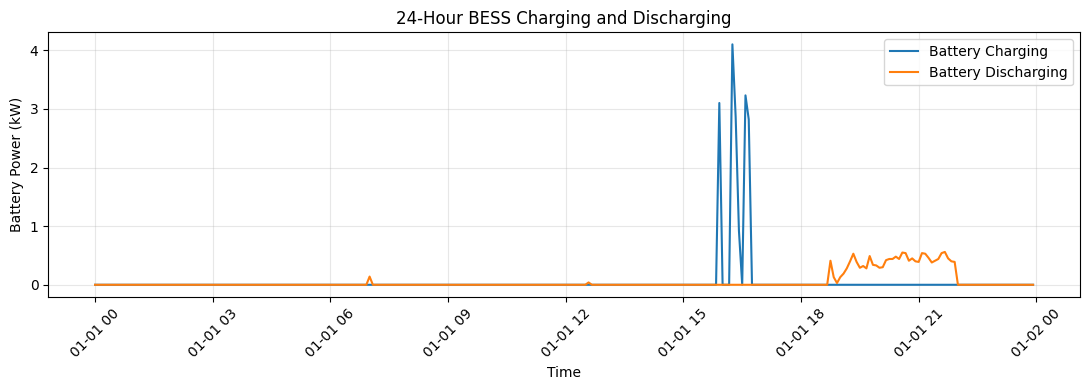

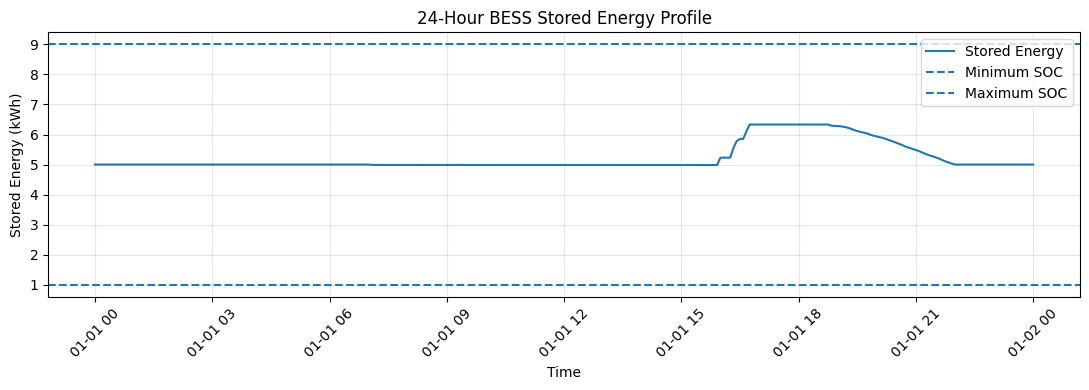

In [159]:
# Validate 24-hour BESS optimisation results
if daily_status == "Optimal":

    # Calculate AC-side power balance error
    daily_results["power_balance_error_kW"] = (
        daily_results["pv_kW"]
        + daily_results["grid_import_kW"]
        + daily_results["discharge_kW"]
        - daily_results["load_kW"]
        - daily_results["charge_kW"]
        - daily_results["grid_export_kW"]
        - daily_results["curtailment_kW"]
    )

    # Reconstruct stored energy from charging and discharging
    calculated_soc = (
        bess_initial_energy
        + (
            daily_results["charge_kW"]
            * bess_parameters["charge_efficiency"]
            - daily_results["discharge_kW"]
            / bess_parameters["discharge_efficiency"]
        ).cumsum() * dt
    )

    # Calculate SOC balance error
    daily_results["soc_error_kWh"] = (
        daily_results["soc_kWh"] - calculated_soc
    )

    # Validate operating constraints
    tolerance = 1e-5

    daily_validation = pd.Series({
        "SOC within limits": (
            daily_results["soc_kWh"].between(
                bess_min_energy - tolerance,
                bess_max_energy + tolerance
            ).all()
        ),
        "Initial and final SOC equal": (
            abs(
                daily_results["soc_kWh"].iloc[-1]
                - bess_initial_energy
            ) <= tolerance
        ),
        "Charging power within limit": (
            daily_results["charge_kW"].max()
            <= bess_parameters["max_charge_kW"] + tolerance
        ),
        "Discharging power within limit": (
            daily_results["discharge_kW"].max()
            <= bess_parameters["max_discharge_kW"] + tolerance
        ),
        "Grid import within limit": (
            daily_results["grid_import_kW"].max()
            <= grid_parameters["max_import_kW"] + tolerance
        ),
        "Grid export within limit": (
            daily_results["grid_export_kW"].max()
            <= grid_parameters["max_export_kW"] + tolerance
        ),
        "No simultaneous charging/discharging": (
            ~(
                (daily_results["charge_kW"] > tolerance)
                & (daily_results["discharge_kW"] > tolerance)
            )
        ).all(),
        "No simultaneous grid import/export": (
            ~(
                (daily_results["grid_import_kW"] > tolerance)
                & (daily_results["grid_export_kW"] > tolerance)
            )
        ).all(),
        "AC power balance valid": (
            daily_results["power_balance_error_kW"]
            .abs().max() <= tolerance
        ),
        "SOC balance valid": (
            daily_results["soc_error_kWh"]
            .abs().max() <= tolerance
        )
    })

    # Calculate daily energy totals
    daily_energy_summary = pd.Series({
        "PV generation (kWh)": (
            daily_results["pv_kW"].sum() * dt
        ),
        "Household load (kWh)": (
            daily_results["load_kW"].sum() * dt
        ),
        "Battery charging (kWh)": (
            daily_results["charge_kW"].sum() * dt
        ),
        "Battery discharging (kWh)": (
            daily_results["discharge_kW"].sum() * dt
        ),
        "Grid import (kWh)": (
            daily_results["grid_import_kW"].sum() * dt
        ),
        "Grid export (kWh)": (
            daily_results["grid_export_kW"].sum() * dt
        ),
        "PV curtailment (kWh)": (
            daily_results["curtailment_kW"].sum() * dt
        ),
        "Minimum stored energy (kWh)": (
            daily_results["soc_kWh"].min()
        ),
        "Maximum stored energy (kWh)": (
            daily_results["soc_kWh"].max()
        ),
        "Maximum power balance error (kW)": (
            daily_results["power_balance_error_kW"].abs().max()
        ),
        "Maximum SOC balance error (kWh)": (
            daily_results["soc_error_kWh"].abs().max()
        )
    })

    # Display validation results
    print("24-hour BESS operating constraint validation:")
    display(daily_validation)

    print("24-hour BESS energy summary:")
    display(daily_energy_summary.round(4))

    # Plot battery charging and discharging power
    plt.figure(figsize=(11, 4))

    plt.plot(
        daily_results["timestamp"],
        daily_results["charge_kW"],
        label="Battery Charging"
    )

    plt.plot(
        daily_results["timestamp"],
        daily_results["discharge_kW"],
        label="Battery Discharging"
    )

    plt.xlabel("Time")
    plt.ylabel("Battery Power (kW)")
    plt.title("24-Hour BESS Charging and Discharging")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot battery SOC profile
    soc_plot_times = pd.concat([
        pd.Series([daily_results["timestamp"].iloc[0]]),
        daily_results["timestamp"] + pd.Timedelta(hours=dt)
    ], ignore_index=True)

    soc_plot_values = [
        bess_initial_energy
    ] + daily_results["soc_kWh"].tolist()

    plt.figure(figsize=(11, 4))

    plt.plot(
        soc_plot_times,
        soc_plot_values,
        label="Stored Energy"
    )

    plt.axhline(
        bess_min_energy,
        linestyle="--",
        label="Minimum SOC"
    )

    plt.axhline(
        bess_max_energy,
        linestyle="--",
        label="Maximum SOC"
    )

    plt.xlabel("Time")
    plt.ylabel("Stored Energy (kWh)")
    plt.title("24-Hour BESS Stored Energy Profile")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No optimal daily solution available.")


In [160]:
# Define tariff scenarios for daily comparison
daily_tariffs = ["flat", "tou"]

daily_tariff_results = []
daily_dispatch_results = {}

# Optimise the same day under each tariff
for tariff in daily_tariffs:

    status, results, costs = optimise_bess_day(
        test_day,
        tariff=tariff
    )

    if status != "Optimal":
        print(f"{tariff.upper()} optimisation failed: {status}")
        continue

    # Store dispatch results
    daily_dispatch_results[tariff] = results.copy()

    # Calculate battery and grid energy totals
    charging_energy = results["charge_kW"].sum() * dt
    discharging_energy = results["discharge_kW"].sum() * dt

    grid_import_energy = results["grid_import_kW"].sum() * dt
    grid_export_energy = results["grid_export_kW"].sum() * dt

    curtailment_energy = results["curtailment_kW"].sum() * dt

    # Calculate equivalent full cycles
    equivalent_cycles = (
        discharging_energy /
        bess_parameters["discharge_efficiency"] /
        bess_usable_energy
    )

    # Store scenario summary
    daily_tariff_results.append({
        "Tariff": tariff.upper(),
        "Baseline cost (AUD)": costs["Baseline cost (AUD)"],
        "Optimised cost (AUD)": costs["Optimised cost (AUD)"],
        "Savings (AUD)": costs["Savings (AUD)"],
        "Charging (kWh)": charging_energy,
        "Discharging (kWh)": discharging_energy,
        "Grid import (kWh)": grid_import_energy,
        "Grid export (kWh)": grid_export_energy,
        "Curtailment (kWh)": curtailment_energy,
        "Equivalent full cycles": equivalent_cycles,
        "Minimum SOC (kWh)": results["soc_kWh"].min(),
        "Maximum SOC (kWh)": results["soc_kWh"].max()
    })

# Create comparison table
daily_tariff_comparison = pd.DataFrame(
    daily_tariff_results
).set_index("Tariff")

# Calculate savings difference between TOU and Flat
if {"FLAT", "TOU"}.issubset(daily_tariff_comparison.index):
    savings_difference = (
        daily_tariff_comparison.loc["TOU", "Savings (AUD)"]
        - daily_tariff_comparison.loc["FLAT", "Savings (AUD)"]
    )
else:
    savings_difference = np.nan

# Display results
print("2023-01-01 BESS optimisation comparison by tariff:")
display(daily_tariff_comparison.round(4))

print("TOU minus Flat BESS savings (AUD):",
      round(savings_difference, 4))


2023-01-01 BESS optimisation comparison by tariff:


,Baseline cost (AUD),Optimised cost (AUD),Savings (AUD),Charging (kWh),Discharging (kWh),Grid import (kWh),Grid export (kWh),Curtailment (kWh),Equivalent full cycles,Minimum SOC (kWh),Maximum SOC (kWh)
Tariff,,,,,,,,,,,
FLAT,-0.6159,-1.1239,0.5080,6.6260,5.9800,0.3967,37.5748,0.0,0.7868,1.0000,7.2632
TOU,-1.0042,-1.2343,0.2301,1.4192,1.2808,5.0958,42.7816,0.0,0.1685,4.9842,6.3325


TOU minus Flat BESS savings (AUD): -0.2779


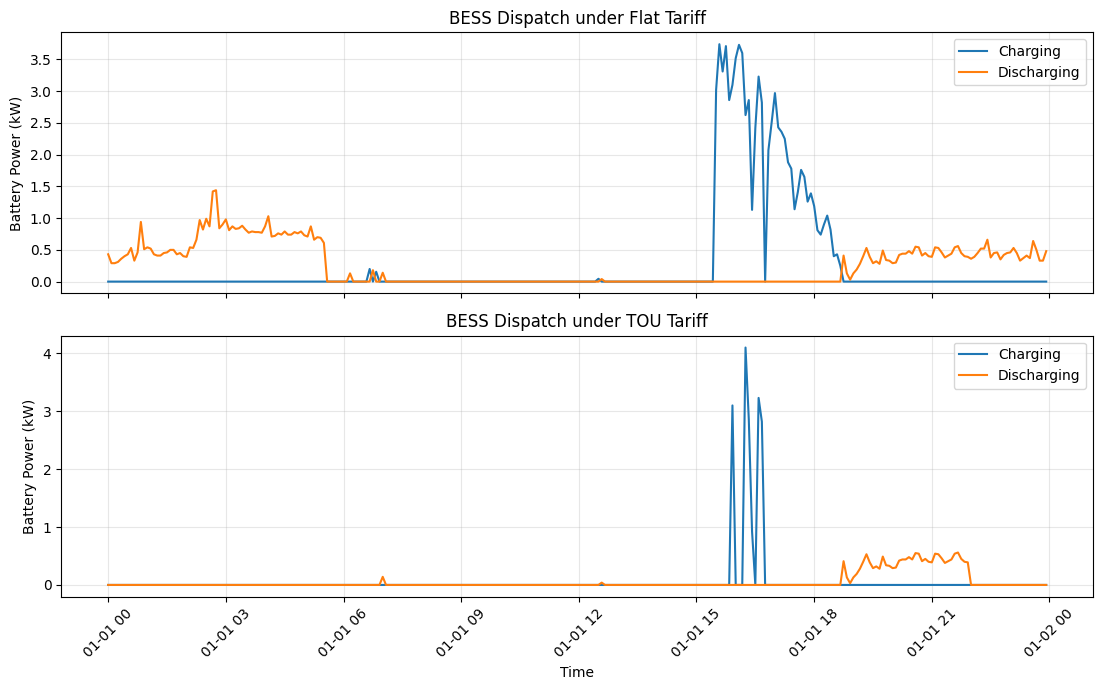

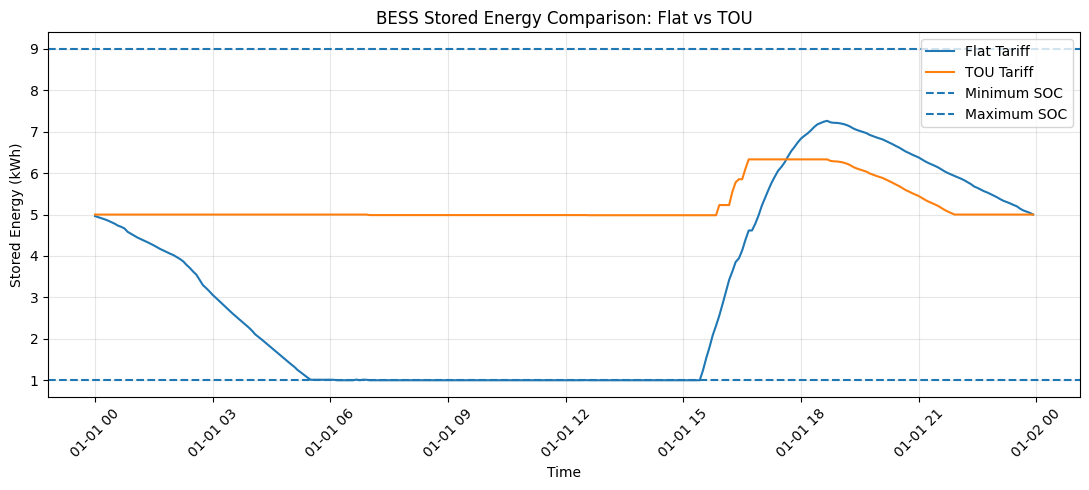

In [161]:
# Compare daily BESS dispatch under Flat and TOU tariffs
flat_results = daily_dispatch_results["flat"]
tou_results = daily_dispatch_results["tou"]

# Plot battery charging and discharging comparison
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Flat tariff
axes[0].plot(
    flat_results["timestamp"],
    flat_results["charge_kW"],
    label="Charging"
)
axes[0].plot(
    flat_results["timestamp"],
    flat_results["discharge_kW"],
    label="Discharging"
)
axes[0].set_title("BESS Dispatch under Flat Tariff")
axes[0].set_ylabel("Battery Power (kW)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# TOU tariff
axes[1].plot(
    tou_results["timestamp"],
    tou_results["charge_kW"],
    label="Charging"
)
axes[1].plot(
    tou_results["timestamp"],
    tou_results["discharge_kW"],
    label="Discharging"
)
axes[1].set_title("BESS Dispatch under TOU Tariff")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Battery Power (kW)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot stored energy comparison
plt.figure(figsize=(11, 5))

plt.plot(
    flat_results["timestamp"],
    flat_results["soc_kWh"],
    label="Flat Tariff"
)
plt.plot(
    tou_results["timestamp"],
    tou_results["soc_kWh"],
    label="TOU Tariff"
)

# Display SOC operating limits
plt.axhline(
    bess_min_energy,
    linestyle="--",
    label="Minimum SOC"
)
plt.axhline(
    bess_max_energy,
    linestyle="--",
    label="Maximum SOC"
)

plt.xlabel("Time")
plt.ylabel("Stored Energy (kWh)")
plt.title("BESS Stored Energy Comparison: Flat vs TOU")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [162]:
# Analyse BESS charging and discharging time patterns
dispatch_analysis_results = []
hourly_dispatch_results = {}

for tariff in ["flat", "tou"]:

    data = daily_dispatch_results[tariff].copy()

    # Calculate five-minute battery energy
    data["charge_kWh"] = data["charge_kW"] * dt
    data["discharge_kWh"] = data["discharge_kW"] * dt

    # Calculate PV surplus before battery operation
    data["available_pv_surplus_kWh"] = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt

    # Estimate PV-supported charging
    data["estimated_pv_charging_kWh"] = np.minimum(
        data["charge_kWh"],
        data["available_pv_surplus_kWh"]
    )

    # Estimate charging not covered by simultaneous PV surplus
    data["estimated_grid_charging_kWh"] = (
        data["charge_kWh"]
        - data["estimated_pv_charging_kWh"]
    )

    # Identify TOU peak hours
    data["peak_period"] = (
        data["timestamp"].dt.hour.isin(tou_peak_hours)
    )

    # Calculate discharge during peak hours
    peak_discharge = data.loc[
        data["peak_period"], "discharge_kWh"
    ].sum()

    total_discharge = data["discharge_kWh"].sum()

    # Calculate charging source estimates
    total_pv_charging = (
        data["estimated_pv_charging_kWh"].sum()
    )

    total_grid_charging = (
        data["estimated_grid_charging_kWh"].sum()
    )

    total_charging = data["charge_kWh"].sum()

    # Calculate PV charging percentage
    pv_charging_percentage = (
        total_pv_charging / total_charging * 100
        if total_charging > 0 else 0
    )

    # Calculate peak discharge percentage
    peak_discharge_percentage = (
        peak_discharge / total_discharge * 100
        if total_discharge > 0 else 0
    )

    # Store summary results
    dispatch_analysis_results.append({
        "Tariff": tariff.upper(),
        "Total charging (kWh)": total_charging,
        "Estimated PV charging (kWh)": total_pv_charging,
        "Estimated grid charging (kWh)": total_grid_charging,
        "PV charging share (%)": pv_charging_percentage,
        "Total discharging (kWh)": total_discharge,
        "Peak-period discharging (kWh)": peak_discharge,
        "Peak discharge share (%)": peak_discharge_percentage
    })

    # Calculate hourly battery charging and discharging
    hourly_dispatch = data.groupby(
        data["timestamp"].dt.hour
    )[["charge_kWh", "discharge_kWh"]].sum()

    hourly_dispatch_results[tariff] = hourly_dispatch

# Create comparison table
dispatch_analysis_summary = pd.DataFrame(
    dispatch_analysis_results
).set_index("Tariff")

# Display results
print("BESS charging source and peak discharge analysis:")
display(dispatch_analysis_summary.round(3))

print("Hourly battery dispatch under Flat tariff:")
display(hourly_dispatch_results["flat"].round(3))

print("Hourly battery dispatch under TOU tariff:")
display(hourly_dispatch_results["tou"].round(3))


BESS charging source and peak discharge analysis:


,Total charging (kWh),Estimated PV charging (kWh),Estimated grid charging (kWh),PV charging share (%),Total discharging (kWh),Peak-period discharging (kWh),Peak discharge share (%)
Tariff,,,,,,,
FLAT,6.626,6.626,0.0,100.0,5.980,0.808,13.517
TOU,1.419,1.419,0.0,100.0,1.281,0.808,63.110


Hourly battery dispatch under Flat tariff:


,charge_kWh,discharge_kWh
timestamp,,
0,0.000,0.440
1,0.000,0.458
2,0.000,0.864
3,0.000,0.827
4,0.000,0.786
5,0.000,0.414
6,0.030,0.026
7,0.000,0.012
8,0.000,0.000


Hourly battery dispatch under TOU tariff:


,charge_kWh,discharge_kWh
timestamp,,
0,0.000,0.000
1,0.000,0.000
2,0.000,0.000
3,0.000,0.000
4,0.000,0.000
5,0.000,0.000
6,0.000,0.000
7,0.000,0.012
8,0.000,0.000


In [163]:
# Calculate daily BESS economic cost breakdown
economic_breakdown_results = []

for tariff in ["flat", "tou"]:

    data = daily_dispatch_results[tariff]

    import_col = f"{tariff}_import_AUD/kWh"
    export_col = f"{tariff}_export_AUD/kWh"

    # Calculate optimised grid import cost
    import_cost = (
        data["grid_import_kW"].to_numpy()
        * test_day[import_col].to_numpy()
        * dt
    ).sum()

    # Calculate optimised grid export revenue
    export_revenue = (
        data["grid_export_kW"].to_numpy()
        * test_day[export_col].to_numpy()
        * dt
    ).sum()

    # Calculate battery degradation cost
    degradation_cost = (
        data["discharge_kW"].sum()
        * dt
        * degradation_cost_per_AC_kWh
    )

    # Calculate net operating cost
    net_cost = (
        import_cost - export_revenue + degradation_cost
    )

    # Compare with existing baseline results
    baseline_cost = daily_tariff_comparison.loc[
        tariff.upper(), "Baseline cost (AUD)"
    ]

    economic_breakdown_results.append({
        "Tariff": tariff.upper(),
        "Import cost (AUD)": import_cost,
        "Export revenue (AUD)": export_revenue,
        "Degradation cost (AUD)": degradation_cost,
        "Net operating cost (AUD)": net_cost,
        "Baseline cost (AUD)": baseline_cost,
        "BESS savings (AUD)": baseline_cost - net_cost
    })

# Create economic comparison table
economic_breakdown_summary = pd.DataFrame(
    economic_breakdown_results
).set_index("Tariff")

# Check consistency with previous optimisation results
cost_check = (
    economic_breakdown_summary["Net operating cost (AUD)"]
    - daily_tariff_comparison["Optimised cost (AUD)"]
)

# Display results
print("Daily BESS economic cost breakdown:")
display(economic_breakdown_summary.round(4))

print("Maximum cost calculation difference (AUD):",
      round(cost_check.abs().max(), 6))


Daily BESS economic cost breakdown:


,Import cost (AUD),Export revenue (AUD),Degradation cost (AUD),Net operating cost (AUD),Baseline cost (AUD),BESS savings (AUD)
Tariff,,,,,,
FLAT,0.0992,1.8787,0.6557,-1.1239,-0.6159,0.5080
TOU,0.7644,2.1391,0.1404,-1.2343,-1.0042,0.2301


Maximum cost calculation difference (AUD): 0.0


In [164]:
# Calculate BESS economic savings by time period
period_economic_results = []

for tariff in ["flat", "tou"]:

    data = daily_dispatch_results[tariff].copy()
    baseline_data = test_day.reset_index(drop=True)

    # Identify TOU time periods
    hours = data["timestamp"].dt.hour

    data["period"] = np.select(
        [
            hours.isin(tou_peak_hours),
            hours.isin(tou_offpeak_hours)
        ],
        ["Peak", "Off-peak"],
        default="Shoulder"
    )

    # Read electricity prices
    import_price = baseline_data[
        f"{tariff}_import_AUD/kWh"
    ].to_numpy()

    export_price = baseline_data[
        f"{tariff}_export_AUD/kWh"
    ].to_numpy()

    # Calculate baseline energy without BESS
    baseline_import = (
        data["load_kW"] - data["pv_kW"]
    ).clip(lower=0) * dt

    baseline_export = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt

    # Calculate baseline and optimised costs
    data["baseline_cost"] = (
        baseline_import * import_price
        - baseline_export * export_price
    )

    data["import_cost"] = (
        data["grid_import_kW"] * import_price * dt
    )

    data["export_revenue"] = (
        data["grid_export_kW"] * export_price * dt
    )

    data["degradation_cost"] = (
        data["discharge_kW"] * dt
        * degradation_cost_per_AC_kWh
    )

    data["optimised_cost"] = (
        data["import_cost"]
        - data["export_revenue"]
        + data["degradation_cost"]
    )

    data["savings"] = (
        data["baseline_cost"] - data["optimised_cost"]
    )

    # Summarise each time period
    period_summary = data.groupby("period")[
        [
            "baseline_cost",
            "import_cost",
            "export_revenue",
            "degradation_cost",
            "optimised_cost",
            "savings"
        ]
    ].sum()

    period_summary["Tariff"] = tariff.upper()
    period_economic_results.append(period_summary)

# Combine results
period_economic_summary = pd.concat(
    period_economic_results
).reset_index().set_index(["Tariff", "period"])

# Check against previous daily savings
period_savings_check = (
    period_economic_summary.groupby(level="Tariff")["savings"].sum()
    - daily_tariff_comparison["Savings (AUD)"]
)

# Display results
print("BESS economic savings by time period (AUD):")
display(period_economic_summary.round(4))

print("Maximum daily savings difference (AUD):",
      round(period_savings_check.abs().max(), 6))


BESS economic savings by time period (AUD):


baseline_cost  import_cost  export_revenue  degradation_cost  \
Tariff period                                                                   
FLAT   Off-peak         1.2634       0.0992          0.0091            0.5153   
       Peak             0.0818       0.0000          0.0000            0.0886   
       Shoulder        -1.9611       0.0000          1.8696            0.0518   
TOU    Off-peak         0.7538       0.7644          0.0106            0.0000   
       Peak             0.2031       0.0000          0.1202            0.0886   
       Shoulder        -1.9611       0.0000          2.0082            0.0518   

                 optimised_cost  savings  
Tariff period                             
FLAT   Off-peak          0.6053   0.6581  
       Peak              0.0886  -0.0068  
       Shoulder         -1.8178  -0.1433  
TOU    Off-peak          0.7538  -0.0000  
       Peak             -0.0316   0.2347  
       Shoulder         -1.9564  -0.0046

Maximum daily savings difference (AUD): 0.0


In [165]:
# Final validation of daily MILP optimisation
final_validation_results = []

tolerance = 1e-5

for tariff in ["flat", "tou"]:

    data = daily_dispatch_results[tariff]

    # Calculate maximum AC power balance error
    power_error = (
        data["pv_kW"]
        + data["grid_import_kW"]
        + data["discharge_kW"]
        - data["load_kW"]
        - data["charge_kW"]
        - data["grid_export_kW"]
        - data["curtailment_kW"]
    ).abs().max()

    # Check simultaneous operation
    battery_conflicts = (
        (data["charge_kW"] > tolerance)
        & (data["discharge_kW"] > tolerance)
    ).sum()

    grid_conflicts = (
        (data["grid_import_kW"] > tolerance)
        & (data["grid_export_kW"] > tolerance)
    ).sum()

    # Check economic consistency
    economic_error = abs(
        economic_breakdown_summary.loc[
            tariff.upper(), "Net operating cost (AUD)"
        ]
        - daily_tariff_comparison.loc[
            tariff.upper(), "Optimised cost (AUD)"
        ]
    )

    # Summarise validation results
    final_validation_results.append({
        "Tariff": tariff.upper(),
        "Complete 288 records": len(data) == 288,
        "SOC within limits": data["soc_kWh"].between(
            bess_min_energy - tolerance,
            bess_max_energy + tolerance
        ).all(),
        "Terminal SOC valid": abs(
            data["soc_kWh"].iloc[-1] - bess_initial_energy
        ) <= tolerance,
        "Battery operation valid": battery_conflicts == 0,
        "Grid operation valid": grid_conflicts == 0,
        "Power balance valid": power_error <= tolerance,
        "Economic calculation valid": economic_error <= tolerance
    })

# Create final validation table
final_daily_validation = pd.DataFrame(
    final_validation_results
).set_index("Tariff")

# Check whether all tests passed
all_tests_passed = final_daily_validation.to_numpy().all()

# Display results
print("Final daily MILP validation:")
display(final_daily_validation)

print("All validation tests passed:", bool(all_tests_passed))


Final daily MILP validation:


,Complete 288 records,SOC within limits,Terminal SOC valid,Battery operation valid,Grid operation valid,Power balance valid,Economic calculation valid
Tariff,,,,,,,
FLAT,True,True,True,True,True,True,True
TOU,True,True,True,True,True,True,True


All validation tests passed: True


In [166]:
# Define representative dates for seasonal MILP testing
seasonal_test_dates = {
    "Summer": "2023-01-15",
    "Autumn": "2023-04-15",
    "Winter": "2023-07-15",
    "Spring": "2023-10-15"
}

seasonal_results = []

# Run daily optimisation for each season and tariff
for season, date in seasonal_test_dates.items():

    day_data = optimisation_input.loc[
        optimisation_input["timestamp"].dt.date ==
        pd.Timestamp(date).date()
    ].copy()

    for tariff in ["flat", "tou"]:

        status, dispatch, costs = optimise_bess_day(
            day_data,
            tariff=tariff
        )

        if status != "Optimal":
            seasonal_results.append({
                "Season": season,
                "Date": date,
                "Tariff": tariff.upper(),
                "Status": status
            })
            continue

        # Calculate energy totals
        pv_energy = dispatch["pv_kW"].sum() * dt
        load_energy = dispatch["load_kW"].sum() * dt

        charge_energy = dispatch["charge_kW"].sum() * dt
        discharge_energy = dispatch["discharge_kW"].sum() * dt

        # Store optimisation results
        seasonal_results.append({
            "Season": season,
            "Date": date,
            "Tariff": tariff.upper(),
            "Status": status,
            "PV (kWh)": pv_energy,
            "Load (kWh)": load_energy,
            "Charging (kWh)": charge_energy,
            "Discharging (kWh)": discharge_energy,
            "Baseline cost (AUD)": costs["Baseline cost (AUD)"],
            "Optimised cost (AUD)": costs["Optimised cost (AUD)"],
            "Savings (AUD)": costs["Savings (AUD)"]
        })

# Create seasonal comparison table
seasonal_comparison = pd.DataFrame(
    seasonal_results
).set_index(["Season", "Date", "Tariff"])

# Display results
print("Seasonal BESS MILP optimisation comparison:")
display(seasonal_comparison.round(3))

print("All seasonal optimisations successful:",
      (seasonal_comparison["Status"] == "Optimal").all())


Seasonal BESS MILP optimisation comparison:


Status  PV (kWh)  Load (kWh)  Charging (kWh)  \
Season Date       Tariff                                                  
Summer 2023-01-15 FLAT    Optimal    61.112      24.709           6.843   
                  TOU     Optimal    61.112      24.709           1.677   
Autumn 2023-04-15 FLAT    Optimal    29.230      20.218           6.758   
                  TOU     Optimal    29.230      20.218           2.358   
Winter 2023-07-15 FLAT    Optimal    30.632      33.817           8.467   
                  TOU     Optimal    30.632      33.817           8.467   
Spring 2023-10-15 FLAT    Optimal    59.516      22.104           5.271   
                  TOU     Optimal    59.516      22.104           1.552   

                          Discharging (kWh)  Baseline cost (AUD)  \
Season Date       Tariff                                           
Summer 2023-01-15 FLAT                6.176               -0.575   
                  TOU                 1.513               -0.915   
Autumn 2023-04-15 FLAT                6.099                0.798   
                  TOU                 2.128                0.526   
Winter 2023-07-15 FLAT                7.641                4.876   
                  TOU                 7.641                4.088   
Spring 2023-10-15 FLAT                4.758               -0.919   
                  TOU                 1.401               -1.105   

                          Optimised cost (AUD)  Savings (AUD)  
Season Date       Tariff                                       
Summer 2023-01-15 FLAT                  -1.099          0.525  
                  TOU                   -1.175          0.260  
Autumn 2023-04-15 FLAT                   0.280          0.518  
                  TOU                    0.206          0.320  
Winter 2023-07-15 FLAT                   4.226          0.649  
                  TOU                    2.964          1.123  
Spring 2023-10-15 FLAT                  -1.323          0.404  
                  TOU                   -1.374          0.269

All seasonal optimisations successful: True


In [167]:
# Compare seasonal BESS savings and optimised costs
seasonal_savings = seasonal_comparison[
    "Savings (AUD)"
].unstack("Tariff")

seasonal_costs = seasonal_comparison[
    "Optimised cost (AUD)"
].unstack("Tariff")

# Create seasonal economic comparison
seasonal_economic_summary = pd.DataFrame({
    "Flat savings (AUD)": seasonal_savings["FLAT"],
    "TOU savings (AUD)": seasonal_savings["TOU"],
    "Savings difference TOU-Flat (AUD)": (
        seasonal_savings["TOU"] - seasonal_savings["FLAT"]
    ),
    "Flat optimised cost (AUD)": seasonal_costs["FLAT"],
    "TOU optimised cost (AUD)": seasonal_costs["TOU"]
})

# Identify the tariff with lower optimised cost
seasonal_economic_summary["Lower-cost tariff"] = np.where(
    seasonal_costs["FLAT"] <= seasonal_costs["TOU"],
    "Flat",
    "TOU"
)

# Display results
print("Seasonal BESS economic comparison:")
display(seasonal_economic_summary.round(3))


Seasonal BESS economic comparison:


,,Flat savings (AUD),TOU savings (AUD),Savings difference TOU-Flat (AUD),Flat optimised cost (AUD),TOU optimised cost (AUD),Lower-cost tariff
Season,Date,,,,,,
Autumn,2023-04-15,0.518,0.320,-0.198,0.280,0.206,TOU
Spring,2023-10-15,0.404,0.269,-0.136,-1.323,-1.374,TOU
Summer,2023-01-15,0.525,0.260,-0.264,-1.099,-1.175,TOU
Winter,2023-07-15,0.649,1.123,0.474,4.226,2.964,TOU


In [168]:
# Define MILP optimisation with flexible SOC boundaries
def optimise_bess_period(
    period_data,
    tariff="tou",
    initial_energy=None,
    terminal_mode="free",
    terminal_energy=None
):

    # Prepare input data
    data = period_data.copy().reset_index(drop=True)
    n = len(data)
    steps = range(n)

    if n == 0:
        raise ValueError("Input data is empty.")

    # Read operating parameters
    dt_local = bess_parameters["time_step_hours"]
    eta_c = bess_parameters["charge_efficiency"]
    eta_d = bess_parameters["discharge_efficiency"]

    max_charge = bess_parameters["max_charge_kW"]
    max_discharge = bess_parameters["max_discharge_kW"]

    max_import = grid_parameters["max_import_kW"]
    max_export = grid_parameters["max_export_kW"]

    if initial_energy is None:
        initial_energy = bess_initial_energy

    if not bess_min_energy <= initial_energy <= bess_max_energy:
        raise ValueError("Initial energy is outside SOC limits.")

    if terminal_mode not in ["free", "cyclic", "fixed"]:
        raise ValueError("Invalid terminal SOC mode.")

    if terminal_mode == "fixed":
        if terminal_energy is None:
            raise ValueError("Fixed terminal energy is required.")

        if not bess_min_energy <= terminal_energy <= bess_max_energy:
            raise ValueError("Terminal energy is outside SOC limits.")

    # Define tariff columns
    import_col = f"{tariff}_import_AUD/kWh"
    export_col = f"{tariff}_export_AUD/kWh"

    # Check input data
    required_columns = [
        "timestamp", "pv_kW", "load_kW",
        import_col, export_col
    ]

    if data[required_columns].isna().any().any():
        raise ValueError("Missing optimisation input values.")

    # Create MILP model
    model = pulp.LpProblem(
        "BESS_Period_Optimisation",
        pulp.LpMinimize
    )

    # Define decision variables
    ch = pulp.LpVariable.dicts("Charge", steps, lowBound=0)
    dis = pulp.LpVariable.dicts("Discharge", steps, lowBound=0)

    soc = pulp.LpVariable.dicts(
        "Stored_Energy",
        range(n + 1),
        lowBound=bess_min_energy,
        upBound=bess_max_energy
    )

    imp = pulp.LpVariable.dicts("Grid_Import", steps, lowBound=0)
    exp = pulp.LpVariable.dicts("Grid_Export", steps, lowBound=0)
    curt = pulp.LpVariable.dicts("PV_Curtailment", steps, lowBound=0)

    b_mode = pulp.LpVariable.dicts(
        "Battery_Mode", steps, cat="Binary"
    )
    g_mode = pulp.LpVariable.dicts(
        "Grid_Mode", steps, cat="Binary"
    )

    # Set initial SOC
    model += soc[0] == initial_energy

    # Set terminal SOC
    if terminal_mode == "cyclic":
        model += soc[n] == soc[0]

    elif terminal_mode == "fixed":
        model += soc[n] == terminal_energy

    # Add operating constraints
    for t in steps:

        pv = float(data.loc[t, "pv_kW"])
        load = float(data.loc[t, "load_kW"])

        model += (
            soc[t + 1] ==
            soc[t] + eta_c * ch[t] * dt_local
            - dis[t] * dt_local / eta_d
        )

        model += ch[t] <= max_charge * b_mode[t]
        model += dis[t] <= max_discharge * (1 - b_mode[t])

        model += imp[t] <= max_import * g_mode[t]
        model += exp[t] <= max_export * (1 - g_mode[t])

        model += curt[t] <= pv

        model += (
            pv + imp[t] + dis[t] ==
            load + ch[t] + exp[t] + curt[t]
        )

    # Define objective function
    model += pulp.lpSum(
        (
            imp[t] * float(data.loc[t, import_col])
            - exp[t] * float(data.loc[t, export_col])
            + dis[t] * degradation_cost_per_AC_kWh
        ) * dt_local
        for t in steps
    )

    # Solve MILP
    model.solve(pulp.PULP_CBC_CMD(msg=False))

    status = pulp.LpStatus[model.status]

    if status != "Optimal":
        return status, None, None

    # Extract dispatch results
    results = data[["timestamp", "pv_kW", "load_kW"]].copy()

    for name, variables in {
        "charge_kW": ch,
        "discharge_kW": dis,
        "grid_import_kW": imp,
        "grid_export_kW": exp,
        "curtailment_kW": curt
    }.items():
        results[name] = [
            pulp.value(variables[t]) for t in steps
        ]

    results["soc_kWh"] = [
        pulp.value(soc[t + 1]) for t in steps
    ]

    # Calculate baseline cost
    baseline_import = (
        data["load_kW"] - data["pv_kW"]
    ).clip(lower=0) * dt_local

    baseline_export = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt_local

    baseline_cost = (
        (baseline_import * data[import_col]).sum()
        - (baseline_export * data[export_col]).sum()
    )

    optimised_cost = pulp.value(model.objective)

    # Summarise results
    summary = pd.Series({
        "Records": n,
        "Initial energy (kWh)": initial_energy,
        "Final energy (kWh)": pulp.value(soc[n]),
        "Baseline cost (AUD)": baseline_cost,
        "Optimised cost (AUD)": optimised_cost,
        "Savings (AUD)": baseline_cost - optimised_cost
    })

    return status, results, summary


print("Flexible-period MILP optimisation function defined.")


Flexible-period MILP optimisation function defined.


In [169]:
# Select three consecutive days for MILP testing
period_start = pd.Timestamp("2023-01-01")
period_end = pd.Timestamp("2023-01-04")

three_day_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= period_start) &
    (optimisation_input["timestamp"] < period_end)
].copy()

# Check input timestamps
three_day_input_check = pd.Series({
    "Total records": len(three_day_data),
    "Expected records": 3 * 24 * 12,
    "Duplicate timestamps": (
        three_day_data["timestamp"].duplicated().sum()
    ),
    "Missing five-minute intervals": (
        len(pd.date_range(
            start=period_start,
            end=period_end,
            freq="5min",
            inclusive="left"
        ).difference(three_day_data["timestamp"]))
    )
})

# Run continuous 72-hour MILP optimisation
three_day_status, three_day_results, three_day_summary = (
    optimise_bess_period(
        three_day_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

# Display results
print("72-hour MILP input validation:")
display(three_day_input_check)

print("72-hour MILP solution status:", three_day_status)

if three_day_status == "Optimal":
    print("72-hour BESS optimisation summary:")
    display(three_day_summary.round(4))
else:
    print("The 72-hour optimisation did not return an optimal solution.")


72-hour MILP input validation:


Total records                    864
Expected records                 864
Duplicate timestamps               0
Missing five-minute intervals      0
dtype: int64

72-hour MILP solution status: Optimal
72-hour BESS optimisation summary:


Records                 864.0000
Initial energy (kWh)      5.0000
Final energy (kWh)        5.0000
Baseline cost (AUD)      -3.5425
Optimised cost (AUD)     -4.2817
Savings (AUD)             0.7392
dtype: float64

In [170]:
# Validate continuous 72-hour MILP results
if three_day_status == "Optimal":

    data = three_day_results.copy().reset_index(drop=True)
    tolerance = 1e-5

    # Reconstruct stored energy from initial SOC
    soc_calculated = (
        bess_initial_energy
        + (
            data["charge_kW"] * bess_parameters["charge_efficiency"]
            - data["discharge_kW"] / bess_parameters["discharge_efficiency"]
        ).cumsum() * dt
    )

    # Calculate SOC balance error
    soc_error = data["soc_kWh"] - soc_calculated

    # Calculate AC-side power balance error
    power_error = (
        data["pv_kW"]
        + data["grid_import_kW"]
        + data["discharge_kW"]
        - data["load_kW"]
        - data["charge_kW"]
        - data["grid_export_kW"]
        - data["curtailment_kW"]
    )

    # Identify daily boundaries
    day_boundaries = (
        data["timestamp"].dt.date
        != data["timestamp"].shift().dt.date
    )

    boundary_indices = data.index[day_boundaries][1:]

    # Check SOC transition at midnight
    boundary_errors = []

    for i in boundary_indices:
        expected_soc = (
            data.loc[i - 1, "soc_kWh"]
            + data.loc[i, "charge_kW"]
            * bess_parameters["charge_efficiency"] * dt
            - data.loc[i, "discharge_kW"]
            / bess_parameters["discharge_efficiency"] * dt
        )

        boundary_errors.append(
            abs(data.loc[i, "soc_kWh"] - expected_soc)
        )

    max_boundary_error = (
        max(boundary_errors) if boundary_errors else 0
    )

    # Count simultaneous operations
    simultaneous_battery = (
        (data["charge_kW"] > tolerance)
        & (data["discharge_kW"] > tolerance)
    ).sum()

    simultaneous_grid = (
        (data["grid_import_kW"] > tolerance)
        & (data["grid_export_kW"] > tolerance)
    ).sum()

    # Create validation summary
    continuous_validation = pd.Series({
        "Complete 864 records": len(data) == 864,
        "SOC within limits": data["soc_kWh"].between(
            bess_min_energy - tolerance,
            bess_max_energy + tolerance
        ).all(),
        "Terminal SOC valid": abs(
            data["soc_kWh"].iloc[-1] - bess_initial_energy
        ) <= tolerance,
        "SOC balance valid": soc_error.abs().max() <= tolerance,
        "Midnight SOC continuity valid": (
            max_boundary_error <= tolerance
        ),
        "No simultaneous charge/discharge": (
            simultaneous_battery == 0
        ),
        "No simultaneous grid import/export": (
            simultaneous_grid == 0
        ),
        "AC power balance valid": (
            power_error.abs().max() <= tolerance
        ),
        "Charging power within limit": (
            data["charge_kW"].max()
            <= bess_parameters["max_charge_kW"] + tolerance
        ),
        "Discharging power within limit": (
            data["discharge_kW"].max()
            <= bess_parameters["max_discharge_kW"] + tolerance
        )
    })

    # Display results
    print("72-hour continuous MILP validation:")
    display(continuous_validation)

    print("All validation tests passed:",
          bool(continuous_validation.all()))

    print("Maximum midnight SOC error (kWh):",
          round(max_boundary_error, 8))

else:
    print("No optimal 72-hour solution available.")


72-hour continuous MILP validation:


Complete 864 records                  True
SOC within limits                     True
Terminal SOC valid                    True
SOC balance valid                     True
Midnight SOC continuity valid         True
No simultaneous charge/discharge      True
No simultaneous grid import/export    True
AC power balance valid                True
Charging power within limit           True
Discharging power within limit        True
dtype: bool

All validation tests passed: True
Maximum midnight SOC error (kWh): 0.0


In [171]:
# Prepare continuous 72-hour dispatch data
daily_continuous_data = three_day_results.copy().reset_index(drop=True)

# Identify date
daily_continuous_data["date"] = (
    daily_continuous_data["timestamp"].dt.date
)

# Calculate five-minute energy
for name in [
    "charge", "discharge", "grid_import",
    "grid_export", "curtailment"
]:
    daily_continuous_data[f"{name}_kWh"] = (
        daily_continuous_data[f"{name}_kW"] * dt
    )

# Add TOU electricity prices
price_data = three_day_data.reset_index(drop=True)

daily_continuous_data["import_price"] = (
    price_data["tou_import_AUD/kWh"].to_numpy()
)

daily_continuous_data["export_price"] = (
    price_data["tou_export_AUD/kWh"].to_numpy()
)

# Calculate baseline energy without BESS
daily_continuous_data["baseline_import_kWh"] = (
    daily_continuous_data["load_kW"]
    - daily_continuous_data["pv_kW"]
).clip(lower=0) * dt

daily_continuous_data["baseline_export_kWh"] = (
    daily_continuous_data["pv_kW"]
    - daily_continuous_data["load_kW"]
).clip(lower=0) * dt

# Calculate five-minute baseline cost
daily_continuous_data["baseline_cost"] = (
    daily_continuous_data["baseline_import_kWh"]
    * daily_continuous_data["import_price"]
    - daily_continuous_data["baseline_export_kWh"]
    * daily_continuous_data["export_price"]
)

# Calculate five-minute optimised cost
daily_continuous_data["optimised_cost"] = (
    daily_continuous_data["grid_import_kWh"]
    * daily_continuous_data["import_price"]
    - daily_continuous_data["grid_export_kWh"]
    * daily_continuous_data["export_price"]
    + daily_continuous_data["discharge_kWh"]
    * degradation_cost_per_AC_kWh
)

# Calculate daily energy and economic totals
daily_continuous_summary = daily_continuous_data.groupby(
    "date"
).agg(
    Records=("timestamp", "size"),
    Charge_kWh=("charge_kWh", "sum"),
    Discharge_kWh=("discharge_kWh", "sum"),
    Grid_import_kWh=("grid_import_kWh", "sum"),
    Grid_export_kWh=("grid_export_kWh", "sum"),
    Baseline_cost_AUD=("baseline_cost", "sum"),
    Optimised_cost_AUD=("optimised_cost", "sum")
)

# Calculate initial and final stored energy for each day
daily_continuous_summary["Initial_SOC_kWh"] = (
    daily_continuous_data.groupby("date")["soc_kWh"].first()
    - daily_continuous_data.groupby("date")["charge_kWh"].first()
    * bess_parameters["charge_efficiency"]
    + daily_continuous_data.groupby("date")["discharge_kWh"].first()
    / bess_parameters["discharge_efficiency"]
)

daily_continuous_summary["Final_SOC_kWh"] = (
    daily_continuous_data.groupby("date")["soc_kWh"].last()
)

# Calculate daily savings
daily_continuous_summary["Savings_AUD"] = (
    daily_continuous_summary["Baseline_cost_AUD"]
    - daily_continuous_summary["Optimised_cost_AUD"]
)

# Reorder columns
daily_continuous_summary = daily_continuous_summary[
    [
        "Records",
        "Initial_SOC_kWh",
        "Final_SOC_kWh",
        "Charge_kWh",
        "Discharge_kWh",
        "Grid_import_kWh",
        "Grid_export_kWh",
        "Baseline_cost_AUD",
        "Optimised_cost_AUD",
        "Savings_AUD"
    ]
]

# Validate total economic results
total_savings = daily_continuous_summary["Savings_AUD"].sum()

savings_error = abs(
    total_savings - three_day_summary["Savings (AUD)"]
)

# Display results
print("Daily results from continuous 72-hour optimisation:")
display(daily_continuous_summary.round(4))

print("Total 72-hour savings (AUD):", round(total_savings, 4))
print("Difference from MILP summary (AUD):", round(savings_error, 8))


Daily results from continuous 72-hour optimisation:


,Records,Initial_SOC_kWh,Final_SOC_kWh,Charge_kWh,Discharge_kWh,Grid_import_kWh,Grid_export_kWh,Baseline_cost_AUD,Optimised_cost_AUD,Savings_AUD
date,,,,,,,,,,
2023-01-01,288,5.0000,3.6518,0.0000,1.2808,5.0958,44.2008,-1.0042,-1.3052,0.3010
2023-01-02,288,3.6518,2.0614,0.0000,1.5108,3.4383,41.5550,-1.0305,-1.3963,0.3658
2023-01-03,288,2.0614,5.0000,4.4912,1.2617,3.0508,43.5221,-1.5078,-1.5801,0.0724


Total 72-hour savings (AUD): 0.7392
Difference from MILP summary (AUD): 0.0


In [172]:
# Compare continuous and independent daily MILP optimisation
independent_daily_results = []

# Optimise three days separately
for date in pd.date_range("2023-01-01", "2023-01-03"):

    day_data = three_day_data.loc[
        three_day_data["timestamp"].dt.date == date.date()
    ].copy()

    status, dispatch, costs = optimise_bess_day(
        day_data,
        tariff="tou"
    )

    if status != "Optimal":
        raise RuntimeError(
            f"Independent optimisation failed on {date.date()}: {status}"
        )

    independent_daily_results.append({
        "Date": date.date(),
        "Baseline cost (AUD)": costs["Baseline cost (AUD)"],
        "Optimised cost (AUD)": costs["Optimised cost (AUD)"],
        "Savings (AUD)": costs["Savings (AUD)"]
    })

# Create independent daily summary
independent_daily_summary = pd.DataFrame(
    independent_daily_results
).set_index("Date")

# Calculate three-day totals
independent_totals = independent_daily_summary.sum()

# Compare optimisation approaches
continuous_vs_daily = pd.DataFrame({
    "Independent daily": independent_totals,
    "Continuous 72-hour": pd.Series({
        "Baseline cost (AUD)": three_day_summary["Baseline cost (AUD)"],
        "Optimised cost (AUD)": three_day_summary["Optimised cost (AUD)"],
        "Savings (AUD)": three_day_summary["Savings (AUD)"]
    })
}).T

# Calculate benefit from continuous optimisation
continuous_extra_savings = (
    continuous_vs_daily.loc[
        "Independent daily", "Optimised cost (AUD)"
    ]
    - continuous_vs_daily.loc[
        "Continuous 72-hour", "Optimised cost (AUD)"
    ]
)

# Check that baseline costs are consistent
baseline_difference = abs(
    continuous_vs_daily.loc[
        "Independent daily", "Baseline cost (AUD)"
    ]
    - continuous_vs_daily.loc[
        "Continuous 72-hour", "Baseline cost (AUD)"
    ]
)

# Display results
print("Independent daily optimisation results:")
display(independent_daily_summary.round(4))

print("Continuous vs independent daily optimisation:")
display(continuous_vs_daily.round(4))

print("Additional savings from continuous optimisation (AUD):",
      round(continuous_extra_savings, 4))

print("Baseline cost difference (AUD):",
      round(baseline_difference, 8))


Independent daily optimisation results:


,Baseline cost (AUD),Optimised cost (AUD),Savings (AUD)
Date,,,
2023-01-01,-1.0042,-1.2343,0.2301
2023-01-02,-1.0305,-1.3126,0.2821
2023-01-03,-1.5078,-1.7348,0.2271


Continuous vs independent daily optimisation:


,Baseline cost (AUD),Optimised cost (AUD),Savings (AUD)
Independent daily,-3.5425,-4.2817,0.7392
Continuous 72-hour,-3.5425,-4.2817,0.7392


Additional savings from continuous optimisation (AUD): 0.0
Baseline cost difference (AUD): 0.0


In [173]:
# Select seven consecutive days
week_start = pd.Timestamp("2023-01-01")
week_end = pd.Timestamp("2023-01-08")

week_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= week_start) &
    (optimisation_input["timestamp"] < week_end)
].copy()

# Validate weekly input data
expected_week_records = 7 * 24 * 12

week_input_valid = (
    len(week_data) == expected_week_records
    and week_data["timestamp"].is_unique
    and week_data["timestamp"].is_monotonic_increasing
    and week_data["timestamp"].diff().dropna().eq(
        pd.Timedelta(minutes=5)
    ).all()
)

if not week_input_valid:
    raise ValueError("Seven-day input time series is incomplete.")

# Measure optimisation runtime
import time

start_time = time.perf_counter()

week_status, week_results, week_summary = (
    optimise_bess_period(
        week_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_seconds = time.perf_counter() - start_time

# Summarise optimisation performance
week_performance = pd.Series({
    "Total records": len(week_data),
    "Expected records": expected_week_records,
    "Optimisation status": week_status,
    "Runtime (seconds)": runtime_seconds,
    "Initial energy (kWh)": (
        week_summary["Initial energy (kWh)"]
        if week_status == "Optimal" else np.nan
    ),
    "Final energy (kWh)": (
        week_summary["Final energy (kWh)"]
        if week_status == "Optimal" else np.nan
    ),
    "Baseline cost (AUD)": (
        week_summary["Baseline cost (AUD)"]
        if week_status == "Optimal" else np.nan
    ),
    "Optimised cost (AUD)": (
        week_summary["Optimised cost (AUD)"]
        if week_status == "Optimal" else np.nan
    ),
    "Savings (AUD)": (
        week_summary["Savings (AUD)"]
        if week_status == "Optimal" else np.nan
    )
})

# Display results
print("Seven-day continuous MILP optimisation performance:")
display(week_performance)


Seven-day continuous MILP optimisation performance:


Total records                2016
Expected records             2016
Optimisation status       Optimal
Runtime (seconds)        1.643918
Initial energy (kWh)          5.0
Final energy (kWh)            5.0
Baseline cost (AUD)    -12.005708
Optimised cost (AUD)   -13.454595
Savings (AUD)            1.448887
dtype: object

In [174]:
# Select 30 consecutive days for MILP testing
month_start = pd.Timestamp("2023-01-01")
month_end = pd.Timestamp("2023-01-31")

month_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= month_start) &
    (optimisation_input["timestamp"] < month_end)
].copy()

# Validate 30-day input data
expected_month_records = 30 * 24 * 12

month_input_valid = (
    len(month_data) == expected_month_records
    and month_data["timestamp"].is_unique
    and month_data["timestamp"].is_monotonic_increasing
    and month_data["timestamp"].diff().dropna().eq(
        pd.Timedelta(minutes=5)
    ).all()
)

if not month_input_valid:
    raise ValueError("30-day input time series is incomplete.")

# Run continuous 30-day optimisation
import time

start_time = time.perf_counter()

month_status, month_results, month_summary = (
    optimise_bess_period(
        month_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_seconds_30d = time.perf_counter() - start_time

# Summarise optimisation performance
month_performance = pd.Series({
    "Total records": len(month_data),
    "Expected records": expected_month_records,
    "Optimisation status": month_status,
    "Runtime (seconds)": runtime_seconds_30d,
    "Initial energy (kWh)": (
        month_summary["Initial energy (kWh)"]
        if month_status == "Optimal" else np.nan
    ),
    "Final energy (kWh)": (
        month_summary["Final energy (kWh)"]
        if month_status == "Optimal" else np.nan
    ),
    "Baseline cost (AUD)": (
        month_summary["Baseline cost (AUD)"]
        if month_status == "Optimal" else np.nan
    ),
    "Optimised cost (AUD)": (
        month_summary["Optimised cost (AUD)"]
        if month_status == "Optimal" else np.nan
    ),
    "Savings (AUD)": (
        month_summary["Savings (AUD)"]
        if month_status == "Optimal" else np.nan
    )
})

# Display results
print("30-day continuous MILP optimisation performance:")
display(month_performance)


30-day continuous MILP optimisation performance:


Total records                8640
Expected records             8640
Optimisation status       Optimal
Runtime (seconds)        9.576227
Initial energy (kWh)          5.0
Final energy (kWh)            5.0
Baseline cost (AUD)    -30.131236
Optimised cost (AUD)   -38.286391
Savings (AUD)            8.155154
dtype: object

In [175]:
# Select 90 consecutive days
period_90_start = pd.Timestamp("2023-01-01")
period_90_end = period_90_start + pd.Timedelta(days=90)

period_90_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= period_90_start) &
    (optimisation_input["timestamp"] < period_90_end)
].copy()

# Validate 90-day input data
expected_90_records = 90 * 24 * 12

period_90_input_valid = (
    len(period_90_data) == expected_90_records
    and period_90_data["timestamp"].is_unique
    and period_90_data["timestamp"].is_monotonic_increasing
    and period_90_data["timestamp"].diff().dropna().eq(
        pd.Timedelta(minutes=5)
    ).all()
)

if not period_90_input_valid:
    raise ValueError("90-day input time series is incomplete.")

# Run continuous 90-day MILP optimisation
import time

start_time = time.perf_counter()

period_90_status, period_90_results, period_90_summary = (
    optimise_bess_period(
        period_90_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_seconds_90d = time.perf_counter() - start_time

# Summarise optimisation performance
period_90_performance = pd.Series({
    "Total records": len(period_90_data),
    "Expected records": expected_90_records,
    "Optimisation status": period_90_status,
    "Runtime (seconds)": runtime_seconds_90d,
    "Initial energy (kWh)": (
        period_90_summary["Initial energy (kWh)"]
        if period_90_status == "Optimal" else np.nan
    ),
    "Final energy (kWh)": (
        period_90_summary["Final energy (kWh)"]
        if period_90_status == "Optimal" else np.nan
    ),
    "Baseline cost (AUD)": (
        period_90_summary["Baseline cost (AUD)"]
        if period_90_status == "Optimal" else np.nan
    ),
    "Optimised cost (AUD)": (
        period_90_summary["Optimised cost (AUD)"]
        if period_90_status == "Optimal" else np.nan
    ),
    "Savings (AUD)": (
        period_90_summary["Savings (AUD)"]
        if period_90_status == "Optimal" else np.nan
    )
})

# Display results
print("90-day continuous MILP optimisation performance:")
display(period_90_performance)


90-day continuous MILP optimisation performance:


Total records               25920
Expected records            25920
Optimisation status       Optimal
Runtime (seconds)        42.60047
Initial energy (kWh)          5.0
Final energy (kWh)            5.0
Baseline cost (AUD)    -50.213497
Optimised cost (AUD)   -85.768293
Savings (AUD)           35.554796
dtype: object

In [176]:
# Select full-year 2023 optimisation data
year_2023_start = pd.Timestamp("2023-01-01")
year_2023_end = pd.Timestamp("2024-01-01")

year_2023_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= year_2023_start) &
    (optimisation_input["timestamp"] < year_2023_end)
].copy()

# Validate full-year timestamps
expected_2023_records = 365 * 24 * 12

year_2023_valid = (
    len(year_2023_data) == expected_2023_records
    and year_2023_data["timestamp"].is_unique
    and year_2023_data["timestamp"].is_monotonic_increasing
    and year_2023_data["timestamp"].diff().dropna().eq(
        pd.Timedelta(minutes=5)
    ).all()
)

if not year_2023_valid:
    raise ValueError("2023 optimisation input is incomplete.")

# Run full-year continuous MILP optimisation
import time

start_time = time.perf_counter()

year_2023_status, year_2023_results, year_2023_summary = (
    optimise_bess_period(
        year_2023_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_2023 = time.perf_counter() - start_time

# Summarise full-year optimisation performance
year_2023_performance = pd.Series({
    "Total records": len(year_2023_data),
    "Expected records": expected_2023_records,
    "Optimisation status": year_2023_status,
    "Runtime (seconds)": runtime_2023,
    "Initial energy (kWh)": (
        year_2023_summary["Initial energy (kWh)"]
        if year_2023_status == "Optimal" else np.nan
    ),
    "Final energy (kWh)": (
        year_2023_summary["Final energy (kWh)"]
        if year_2023_status == "Optimal" else np.nan
    ),
    "Baseline cost (AUD)": (
        year_2023_summary["Baseline cost (AUD)"]
        if year_2023_status == "Optimal" else np.nan
    ),
    "Optimised cost (AUD)": (
        year_2023_summary["Optimised cost (AUD)"]
        if year_2023_status == "Optimal" else np.nan
    ),
    "Savings (AUD)": (
        year_2023_summary["Savings (AUD)"]
        if year_2023_status == "Optimal" else np.nan
    )
})

# Display results
print("2023 full-year continuous MILP optimisation:")
display(year_2023_performance)


2023 full-year continuous MILP optimisation:


Total records               105120
Expected records            105120
Optimisation status        Optimal
Runtime (seconds)        484.79164
Initial energy (kWh)           5.0
Final energy (kWh)             5.0
Baseline cost (AUD)     506.574667
Optimised cost (AUD)    248.203416
Savings (AUD)           258.371251
dtype: object

In [177]:
# Validate full-year 2023 MILP optimisation results
if year_2023_status != "Optimal":
    raise RuntimeError("No optimal 2023 solution available.")

data = year_2023_results
tol = 1e-5
dt_check = bess_parameters["time_step_hours"]

# Calculate AC power balance errors
power_error_2023 = (
    data["pv_kW"]
    + data["grid_import_kW"]
    + data["discharge_kW"]
    - data["load_kW"]
    - data["charge_kW"]
    - data["grid_export_kW"]
    - data["curtailment_kW"]
)

# Calculate SOC balance errors
previous_soc = pd.concat([
    pd.Series([bess_initial_energy]),
    data["soc_kWh"].iloc[:-1]
], ignore_index=True)

expected_soc = (
    previous_soc
    + data["charge_kW"].reset_index(drop=True)
    * bess_parameters["charge_efficiency"] * dt_check
    - data["discharge_kW"].reset_index(drop=True)
    / bess_parameters["discharge_efficiency"] * dt_check
)

soc_error_2023 = (
    data["soc_kWh"].reset_index(drop=True) - expected_soc
)

# Check simultaneous operations
battery_conflicts_2023 = (
    (data["charge_kW"] > tol)
    & (data["discharge_kW"] > tol)
).sum()

grid_conflicts_2023 = (
    (data["grid_import_kW"] > tol)
    & (data["grid_export_kW"] > tol)
).sum()

# Independently calculate economic cost
import_cost_2023 = (
    data["grid_import_kW"].to_numpy()
    * year_2023_data["tou_import_AUD/kWh"].to_numpy()
    * dt_check
).sum()

export_revenue_2023 = (
    data["grid_export_kW"].to_numpy()
    * year_2023_data["tou_export_AUD/kWh"].to_numpy()
    * dt_check
).sum()

degradation_cost_2023 = (
    data["discharge_kW"].sum()
    * dt_check
    * degradation_cost_per_AC_kWh
)

calculated_net_cost_2023 = (
    import_cost_2023
    - export_revenue_2023
    + degradation_cost_2023
)

economic_error_2023 = abs(
    calculated_net_cost_2023
    - year_2023_summary["Optimised cost (AUD)"]
)

# Create full-year validation table
year_2023_validation = pd.Series({
    "Complete 105120 records": len(data) == 105120,
    "SOC within limits": data["soc_kWh"].between(
        bess_min_energy - tol,
        bess_max_energy + tol
    ).all(),
    "Initial and terminal SOC consistent": abs(
        data["soc_kWh"].iloc[-1] - bess_initial_energy
    ) <= tol,
    "SOC balance valid": soc_error_2023.abs().max() <= tol,
    "AC power balance valid": power_error_2023.abs().max() <= tol,
    "No simultaneous charging/discharging": battery_conflicts_2023 == 0,
    "No simultaneous grid import/export": grid_conflicts_2023 == 0,
    "Charging power within limit": (
        data["charge_kW"].max()
        <= bess_parameters["max_charge_kW"] + tol
    ),
    "Discharging power within limit": (
        data["discharge_kW"].max()
        <= bess_parameters["max_discharge_kW"] + tol
    ),
    "Economic calculation valid": economic_error_2023 <= tol
})

# Display results
print("2023 full-year MILP validation:")
display(year_2023_validation)

print("All validation tests passed:",
      bool(year_2023_validation.all()))

print("Maximum SOC balance error (kWh):",
      round(soc_error_2023.abs().max(), 8))

print("Maximum AC power balance error (kW):",
      round(power_error_2023.abs().max(), 8))

print("Economic calculation difference (AUD):",
      round(economic_error_2023, 8))


2023 full-year MILP validation:


Complete 105120 records                 True
SOC within limits                       True
Initial and terminal SOC consistent     True
SOC balance valid                       True
AC power balance valid                  True
No simultaneous charging/discharging    True
No simultaneous grid import/export      True
Charging power within limit             True
Discharging power within limit          True
Economic calculation valid              True
dtype: bool

All validation tests passed: True
Maximum SOC balance error (kWh): 1e-07
Maximum AC power balance error (kW): 5e-08
Economic calculation difference (AUD): 0.0


In [178]:
# Run full-year 2023 MILP optimisation under Flat tariff
import time

start_time = time.perf_counter()

year_2023_flat_status, year_2023_flat_results, year_2023_flat_summary = (
    optimise_bess_period(
        year_2023_data,
        tariff="flat",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_2023_flat = time.perf_counter() - start_time

# Check optimisation status
if year_2023_flat_status != "Optimal":
    raise RuntimeError(
        f"Flat tariff optimisation failed: {year_2023_flat_status}"
    )

# Compare full-year Flat and TOU results
year_2023_tariff_comparison = pd.DataFrame({
    "Flat": {
        "Baseline cost (AUD)": (
            year_2023_flat_summary["Baseline cost (AUD)"]
        ),
        "Optimised cost (AUD)": (
            year_2023_flat_summary["Optimised cost (AUD)"]
        ),
        "BESS savings (AUD)": (
            year_2023_flat_summary["Savings (AUD)"]
        ),
        "Runtime (seconds)": runtime_2023_flat
    },
    "TOU": {
        "Baseline cost (AUD)": (
            year_2023_summary["Baseline cost (AUD)"]
        ),
        "Optimised cost (AUD)": (
            year_2023_summary["Optimised cost (AUD)"]
        ),
        "BESS savings (AUD)": (
            year_2023_summary["Savings (AUD)"]
        ),
        "Runtime (seconds)": runtime_2023
    }
}).T

# Calculate tariff cost difference
tariff_cost_difference = (
    year_2023_tariff_comparison.loc["Flat", "Optimised cost (AUD)"]
    - year_2023_tariff_comparison.loc["TOU", "Optimised cost (AUD)"]
)

# Identify lower-cost tariff
best_2023_tariff = (
    "Flat" if tariff_cost_difference < 0 else "TOU"
)

# Display results
print("2023 full-year Flat vs TOU BESS optimisation:")
display(year_2023_tariff_comparison.round(2))

print("Lower-cost tariff:", best_2023_tariff)
print("Optimised cost difference (AUD):",
      round(abs(tariff_cost_difference), 2))


2023 full-year Flat vs TOU BESS optimisation:


,Baseline cost (AUD),Optimised cost (AUD),BESS savings (AUD),Runtime (seconds)
Flat,553.39,365.18,188.21,539.62
TOU,506.57,248.20,258.37,484.79


Lower-cost tariff: TOU
Optimised cost difference (AUD): 116.97


In [179]:
# Compare annual BESS operation under Flat and TOU tariffs
annual_operation_results = []

for tariff, results in {
    "Flat": year_2023_flat_results,
    "TOU": year_2023_results
}.items():

    # Calculate annual energy totals
    charge_energy = results["charge_kW"].sum() * dt
    discharge_energy = results["discharge_kW"].sum() * dt

    grid_import_energy = results["grid_import_kW"].sum() * dt
    grid_export_energy = results["grid_export_kW"].sum() * dt
    curtailed_energy = results["curtailment_kW"].sum() * dt

    # Calculate equivalent full cycles
    equivalent_full_cycles = (
        discharge_energy
        / bess_parameters["discharge_efficiency"]
        / bess_capacity
    )

    # Calculate battery degradation cost
    degradation_cost = (
        discharge_energy * degradation_cost_per_AC_kWh
    )

    # Store annual results
    annual_operation_results.append({
        "Tariff": tariff,
        "Charging (kWh)": charge_energy,
        "Discharging (kWh)": discharge_energy,
        "Grid import (kWh)": grid_import_energy,
        "Grid export (kWh)": grid_export_energy,
        "PV curtailment (kWh)": curtailed_energy,
        "Equivalent full cycles": equivalent_full_cycles,
        "Degradation cost (AUD)": degradation_cost,
        "Minimum SOC (kWh)": results["soc_kWh"].min(),
        "Maximum SOC (kWh)": results["soc_kWh"].max()
    })

# Create comparison table
annual_operation_summary = pd.DataFrame(
    annual_operation_results
).set_index("Tariff")

# Display results
print("2023 annual BESS operation and degradation comparison:")
display(annual_operation_summary.round(2))


2023 annual BESS operation and degradation comparison:


,Charging (kWh),Discharging (kWh),Grid import (kWh),Grid export (kWh),PV curtailment (kWh),Equivalent full cycles,Degradation cost (AUD),Minimum SOC (kWh),Maximum SOC (kWh)
Tariff,,,,,,,,,
Flat,2454.90,2215.55,2358.84,9349.31,0.0,233.22,242.93,1.0,9.0
TOU,1484.39,1339.66,3272.07,10357.16,0.0,141.02,146.89,1.0,9.0


In [180]:
# Calculate monthly BESS economic results for 2023
monthly_bess_results = []

for tariff, dispatch in {
    "Flat": year_2023_flat_results,
    "TOU": year_2023_results
}.items():

    data = dispatch.copy().reset_index(drop=True)
    prices = year_2023_data.reset_index(drop=True)

    import_col = f"{tariff.lower()}_import_AUD/kWh"
    export_col = f"{tariff.lower()}_export_AUD/kWh"

    # Identify month
    data["month"] = data["timestamp"].dt.month

    # Calculate baseline grid energy
    baseline_import = (
        data["load_kW"] - data["pv_kW"]
    ).clip(lower=0) * dt

    baseline_export = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt

    # Calculate baseline costs
    data["baseline_cost"] = (
        baseline_import * prices[import_col].to_numpy()
        - baseline_export * prices[export_col].to_numpy()
    )

    # Calculate optimised costs
    data["optimised_cost"] = (
        data["grid_import_kW"]
        * prices[import_col].to_numpy() * dt
        - data["grid_export_kW"]
        * prices[export_col].to_numpy() * dt
        + data["discharge_kW"] * dt
        * degradation_cost_per_AC_kWh
    )

    # Calculate monthly results
    monthly = data.groupby("month").agg(
        Baseline_cost_AUD=("baseline_cost", "sum"),
        Optimised_cost_AUD=("optimised_cost", "sum")
    )

    monthly["Savings_AUD"] = (
        monthly["Baseline_cost_AUD"]
        - monthly["Optimised_cost_AUD"]
    )

    monthly["Tariff"] = tariff
    monthly_bess_results.append(monthly.reset_index())

# Combine monthly results
monthly_bess_data = pd.concat(
    monthly_bess_results,
    ignore_index=True
)

# Compare Flat and TOU by month
monthly_bess_comparison = monthly_bess_data.pivot(
    index="month",
    columns="Tariff",
    values=[
        "Baseline_cost_AUD",
        "Optimised_cost_AUD",
        "Savings_AUD"
    ]
)

# Identify lower-cost tariff for each month
monthly_bess_comparison[
    ("Comparison", "Lower-cost tariff")
] = np.where(
    monthly_bess_comparison[
        ("Optimised_cost_AUD", "Flat")
    ] <= monthly_bess_comparison[
        ("Optimised_cost_AUD", "TOU")
    ],
    "Flat",
    "TOU"
)

# Display results
print("2023 monthly BESS economic comparison:")
display(monthly_bess_comparison.round(2))


2023 monthly BESS economic comparison:


Baseline_cost_AUD         Optimised_cost_AUD         Savings_AUD  \
Tariff              Flat     TOU               Flat     TOU        Flat   
month                                                                     
1                 -23.42  -31.53             -37.54  -40.11       14.12   
2                 -16.27  -21.94             -28.93  -32.34       12.66   
3                   7.16    3.25              -8.89  -13.85       16.05   
4                   5.14   -2.81              -9.16  -12.24       14.29   
5                 132.73  123.78             112.61   86.35       20.13   
6                 191.15  204.39             173.99  159.40       17.15   
7                 183.57  187.46             164.86  141.97       18.72   
8                 136.96  135.12             116.34   92.55       20.62   
9                  18.75   10.40               2.72   -5.81       16.03   
10                -25.80  -31.57             -38.68  -40.23       12.87   
11                -29.52  -36.10             -42.00  -43.71       12.47   
12                -27.06  -33.88             -40.15  -43.77       13.09   

                     Comparison  
Tariff    TOU Lower-cost tariff  
month                            
1        8.59               TOU  
2       10.40               TOU  
3       17.10               TOU  
4        9.43               TOU  
5       37.43               TOU  
6       45.00               TOU  
7       45.48               TOU  
8       42.56               TOU  
9       16.21               TOU  
10       8.66               TOU  
11       7.61               TOU  
12       9.89               TOU

In [181]:
# Validate monthly and annual BESS economic results
annual_monthly_results = (
    monthly_bess_data.groupby("Tariff")[
        ["Baseline_cost_AUD", "Optimised_cost_AUD", "Savings_AUD"]
    ].sum()
)

# Compare with full-year MILP results
annual_reference = year_2023_tariff_comparison[
    [
        "Baseline cost (AUD)",
        "Optimised cost (AUD)",
        "BESS savings (AUD)"
    ]
].copy()

annual_reference.columns = [
    "Baseline_cost_AUD",
    "Optimised_cost_AUD",
    "Savings_AUD"
]

# Standardise tariff labels
annual_monthly_results.index = (
    annual_monthly_results.index.str.upper()
)
annual_reference.index = annual_reference.index.str.upper()

# Calculate differences
annual_cost_errors = (
    annual_monthly_results - annual_reference
).abs()

# Count months with positive BESS savings
positive_savings_months = (
    monthly_bess_data.assign(
        Positive=monthly_bess_data["Savings_AUD"] > 0
    )
    .groupby("Tariff")["Positive"]
    .sum()
)

positive_savings_months.index = (
    positive_savings_months.index.str.upper()
)

# Create validation table
monthly_annual_validation = pd.DataFrame({
    "Baseline cost error (AUD)": annual_cost_errors[
        "Baseline_cost_AUD"
    ],
    "Optimised cost error (AUD)": annual_cost_errors[
        "Optimised_cost_AUD"
    ],
    "Savings error (AUD)": annual_cost_errors[
        "Savings_AUD"
    ],
    "Positive savings months": positive_savings_months
})

# Check annual consistency
tolerance = 1e-5

monthly_annual_validation["Annual totals valid"] = (
    annual_cost_errors.max(axis=1) <= tolerance
)

# Display results
print("2023 monthly and annual BESS economic validation:")
display(monthly_annual_validation.round(6))

print("All annual totals consistent:",
      bool(monthly_annual_validation["Annual totals valid"].all()))


2023 monthly and annual BESS economic validation:


,Baseline cost error (AUD),Optimised cost error (AUD),Savings error (AUD),Positive savings months,Annual totals valid
Tariff,,,,,
FLAT,0.0,0.0,0.0,12,True
TOU,0.0,0.0,0.0,12,True


All annual totals consistent: True


In [182]:
# Select full-year 2024 optimisation data
year_2024_start = pd.Timestamp("2024-01-01")
year_2024_end = pd.Timestamp("2025-01-01")

year_2024_data = optimisation_input.loc[
    (optimisation_input["timestamp"] >= year_2024_start) &
    (optimisation_input["timestamp"] < year_2024_end)
].copy()

# Validate 2024 input timestamps
expected_2024_records = 366 * 24 * 12

year_2024_valid = (
    len(year_2024_data) == expected_2024_records
    and year_2024_data["timestamp"].is_unique
    and year_2024_data["timestamp"].is_monotonic_increasing
    and year_2024_data["timestamp"].diff().dropna().eq(
        pd.Timedelta(minutes=5)
    ).all()
)

if not year_2024_valid:
    raise ValueError("2024 optimisation input is incomplete.")

# Run 2024 continuous MILP under TOU tariff
import time

start_time = time.perf_counter()

year_2024_status, year_2024_results, year_2024_summary = (
    optimise_bess_period(
        year_2024_data,
        tariff="tou",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_2024 = time.perf_counter() - start_time

# Create annual performance summary
year_2024_performance = pd.Series({
    "Total records": len(year_2024_data),
    "Expected records": expected_2024_records,
    "Optimisation status": year_2024_status,
    "Runtime (seconds)": runtime_2024,
    "Initial energy (kWh)": (
        year_2024_summary["Initial energy (kWh)"]
        if year_2024_status == "Optimal" else np.nan
    ),
    "Final energy (kWh)": (
        year_2024_summary["Final energy (kWh)"]
        if year_2024_status == "Optimal" else np.nan
    ),
    "Baseline cost (AUD)": (
        year_2024_summary["Baseline cost (AUD)"]
        if year_2024_status == "Optimal" else np.nan
    ),
    "Optimised cost (AUD)": (
        year_2024_summary["Optimised cost (AUD)"]
        if year_2024_status == "Optimal" else np.nan
    ),
    "Savings (AUD)": (
        year_2024_summary["Savings (AUD)"]
        if year_2024_status == "Optimal" else np.nan
    )
})

# Display results
print("2024 full-year continuous MILP optimisation:")
display(year_2024_performance)


2024 full-year continuous MILP optimisation:


Total records               105408
Expected records            105408
Optimisation status        Optimal
Runtime (seconds)       496.462529
Initial energy (kWh)           5.0
Final energy (kWh)             5.0
Baseline cost (AUD)     600.864583
Optimised cost (AUD)     283.32726
Savings (AUD)           317.537324
dtype: object

In [183]:
# Validate full-year 2024 MILP optimisation results
if year_2024_status != "Optimal":
    raise RuntimeError("No optimal 2024 solution available.")

data = year_2024_results.reset_index(drop=True)
prices = year_2024_data.reset_index(drop=True)

tol = 1e-5
dt_check = bess_parameters["time_step_hours"]

# Calculate AC-side power balance error
power_error_2024 = (
    data["pv_kW"]
    + data["grid_import_kW"]
    + data["discharge_kW"]
    - data["load_kW"]
    - data["charge_kW"]
    - data["grid_export_kW"]
    - data["curtailment_kW"]
)

# Calculate SOC balance error
previous_soc = pd.concat([
    pd.Series([bess_initial_energy]),
    data["soc_kWh"].iloc[:-1]
], ignore_index=True)

expected_soc = (
    previous_soc
    + data["charge_kW"]
    * bess_parameters["charge_efficiency"] * dt_check
    - data["discharge_kW"]
    / bess_parameters["discharge_efficiency"] * dt_check
)

soc_error_2024 = data["soc_kWh"] - expected_soc

# Check simultaneous battery and grid operations
battery_conflicts_2024 = (
    (data["charge_kW"] > tol)
    & (data["discharge_kW"] > tol)
).sum()

grid_conflicts_2024 = (
    (data["grid_import_kW"] > tol)
    & (data["grid_export_kW"] > tol)
).sum()

# Independently calculate annual economic cost
import_cost_2024 = (
    data["grid_import_kW"].to_numpy()
    * prices["tou_import_AUD/kWh"].to_numpy()
    * dt_check
).sum()

export_revenue_2024 = (
    data["grid_export_kW"].to_numpy()
    * prices["tou_export_AUD/kWh"].to_numpy()
    * dt_check
).sum()

degradation_cost_2024 = (
    data["discharge_kW"].sum()
    * dt_check
    * degradation_cost_per_AC_kWh
)

calculated_net_cost_2024 = (
    import_cost_2024
    - export_revenue_2024
    + degradation_cost_2024
)

economic_error_2024 = abs(
    calculated_net_cost_2024
    - year_2024_summary["Optimised cost (AUD)"]
)

# Create validation summary
year_2024_validation = pd.Series({
    "Complete 105408 records": len(data) == 105408,
    "SOC within limits": data["soc_kWh"].between(
        bess_min_energy - tol,
        bess_max_energy + tol
    ).all(),
    "Initial and terminal SOC consistent": abs(
        data["soc_kWh"].iloc[-1] - bess_initial_energy
    ) <= tol,
    "SOC balance valid": soc_error_2024.abs().max() <= tol,
    "AC power balance valid": power_error_2024.abs().max() <= tol,
    "No simultaneous charging/discharging": battery_conflicts_2024 == 0,
    "No simultaneous grid import/export": grid_conflicts_2024 == 0,
    "Charging power within limit": (
        data["charge_kW"].max()
        <= bess_parameters["max_charge_kW"] + tol
    ),
    "Discharging power within limit": (
        data["discharge_kW"].max()
        <= bess_parameters["max_discharge_kW"] + tol
    ),
    "Economic calculation valid": economic_error_2024 <= tol
})

# Display results
print("2024 full-year MILP validation:")
display(year_2024_validation)

print("All validation tests passed:",
      bool(year_2024_validation.all()))

print("Maximum SOC balance error (kWh):",
      round(soc_error_2024.abs().max(), 8))

print("Maximum AC power balance error (kW):",
      round(power_error_2024.abs().max(), 8))

print("Economic calculation difference (AUD):",
      round(economic_error_2024, 8))


2024 full-year MILP validation:


Complete 105408 records                 True
SOC within limits                       True
Initial and terminal SOC consistent     True
SOC balance valid                       True
AC power balance valid                  True
No simultaneous charging/discharging    True
No simultaneous grid import/export      True
Charging power within limit             True
Discharging power within limit          True
Economic calculation valid              True
dtype: bool

All validation tests passed: True
Maximum SOC balance error (kWh): 1e-07
Maximum AC power balance error (kW): 5e-08
Economic calculation difference (AUD): 0.0


In [184]:
# Run full-year 2024 MILP optimisation under Flat tariff
import time

start_time = time.perf_counter()

year_2024_flat_status, year_2024_flat_results, year_2024_flat_summary = (
    optimise_bess_period(
        year_2024_data,
        tariff="flat",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

runtime_2024_flat = time.perf_counter() - start_time

# Check optimisation status
if year_2024_flat_status != "Optimal":
    raise RuntimeError(
        f"2024 Flat optimisation failed: {year_2024_flat_status}"
    )

# Compare full-year Flat and TOU results
year_2024_tariff_comparison = pd.DataFrame({
    "Flat": {
        "Baseline cost (AUD)": (
            year_2024_flat_summary["Baseline cost (AUD)"]
        ),
        "Optimised cost (AUD)": (
            year_2024_flat_summary["Optimised cost (AUD)"]
        ),
        "BESS savings (AUD)": (
            year_2024_flat_summary["Savings (AUD)"]
        ),
        "Runtime (seconds)": runtime_2024_flat
    },
    "TOU": {
        "Baseline cost (AUD)": (
            year_2024_summary["Baseline cost (AUD)"]
        ),
        "Optimised cost (AUD)": (
            year_2024_summary["Optimised cost (AUD)"]
        ),
        "BESS savings (AUD)": (
            year_2024_summary["Savings (AUD)"]
        ),
        "Runtime (seconds)": runtime_2024
    }
}).T

# Calculate difference between Flat and TOU
tariff_cost_difference_2024 = (
    year_2024_tariff_comparison.loc[
        "Flat", "Optimised cost (AUD)"
    ]
    - year_2024_tariff_comparison.loc[
        "TOU", "Optimised cost (AUD)"
    ]
)

# Identify the lower-cost tariff
best_2024_tariff = (
    "Flat" if tariff_cost_difference_2024 < 0 else "TOU"
)

# Display results
print("2024 full-year Flat vs TOU BESS optimisation:")
display(year_2024_tariff_comparison.round(2))

print("Lower-cost tariff:", best_2024_tariff)
print("Optimised cost difference (AUD):",
      round(abs(tariff_cost_difference_2024), 2))


2024 full-year Flat vs TOU BESS optimisation:


,Baseline cost (AUD),Optimised cost (AUD),BESS savings (AUD),Runtime (seconds)
Flat,760.10,461.95,298.15,1616.86
TOU,600.86,283.33,317.54,496.46


Lower-cost tariff: TOU
Optimised cost difference (AUD): 178.62


In [185]:
# Compare annual BESS operation for 2023 and 2024

two_year_cases = [
    (2023, "Flat", year_2023_flat_results, year_2023_flat_summary),
    (2023, "TOU", year_2023_results, year_2023_summary),
    (2024, "Flat", year_2024_flat_results, year_2024_flat_summary),
    (2024, "TOU", year_2024_results, year_2024_summary)
]

two_year_results = []

for year, tariff, dispatch, summary in two_year_cases:

    charging_kWh = dispatch["charge_kW"].sum() * dt
    discharging_kWh = dispatch["discharge_kW"].sum() * dt

    efc = (
        discharging_kWh
        / bess_parameters["discharge_efficiency"]
        / bess_usable_energy
    )

    degradation_cost = (
        discharging_kWh * degradation_cost_per_AC_kWh
    )

    two_year_results.append({
        "Year": year,
        "Tariff": tariff,
        "Baseline cost (AUD)": summary["Baseline cost (AUD)"],
        "Optimised cost (AUD)": summary["Optimised cost (AUD)"],
        "BESS savings (AUD)": summary["Savings (AUD)"],
        "Charging (kWh)": charging_kWh,
        "Discharging (kWh)": discharging_kWh,
        "Grid import (kWh)": dispatch["grid_import_kW"].sum() * dt,
        "Grid export (kWh)": dispatch["grid_export_kW"].sum() * dt,
        "Equivalent full cycles": efc,
        "Degradation cost (AUD)": degradation_cost
    })

two_year_bess_summary = pd.DataFrame(
    two_year_results
).set_index(["Year", "Tariff"])

print("2023-2024 BESS economic and operational comparison:")
display(two_year_bess_summary.round(2))


2023-2024 BESS economic and operational comparison:


Baseline cost (AUD)  Optimised cost (AUD)  BESS savings (AUD)  \
Year Tariff                                                                  
2023 Flat                 553.39                365.18              188.21   
     TOU                  506.57                248.20              258.37   
2024 Flat                 760.10                461.95              298.15   
     TOU                  600.86                283.33              317.54   

             Charging (kWh)  Discharging (kWh)  Grid import (kWh)  \
Year Tariff                                                         
2023 Flat           2454.90            2215.55            2358.84   
     TOU            1484.39            1339.66            3272.07   
2024 Flat           2448.00            2209.32            2327.32   
     TOU            1610.55            1453.53            3111.07   

             Grid export (kWh)  Equivalent full cycles  Degradation cost (AUD)  
Year Tariff                                                                     
2023 Flat              9349.31                  291.52                  242.93  
     TOU              10357.16                  176.27                  146.89  
2024 Flat              9569.95                  290.70                  242.25  
     TOU              10435.35                  191.25                  159.38

In [186]:
# Calculate two-year totals for Flat and TOU tariffs
two_year_totals = two_year_bess_summary.groupby(
    level="Tariff"
).sum()

# Check economic consistency for each year and tariff
two_year_check = two_year_bess_summary[
    ["Baseline cost (AUD)", "Optimised cost (AUD)", "BESS savings (AUD)"]
].copy()

two_year_check["Savings calculation error (AUD)"] = (
    two_year_check["Baseline cost (AUD)"]
    - two_year_check["Optimised cost (AUD)"]
    - two_year_check["BESS savings (AUD)"]
).abs()

two_year_check["Validation passed"] = (
    two_year_check["Savings calculation error (AUD)"] < 1e-5
)

# Calculate two-year tariff cost difference
two_year_tariff_difference = (
    two_year_totals.loc["Flat", "Optimised cost (AUD)"]
    - two_year_totals.loc["TOU", "Optimised cost (AUD)"]
)

# Display results
print("2023-2024 combined BESS results:")
display(two_year_totals.round(2))

print("Economic consistency validation:")
display(two_year_check[
    ["Savings calculation error (AUD)", "Validation passed"]
].round(6))

print("All checks passed:",
      bool(two_year_check["Validation passed"].all()))

print("Two-year cost difference, Flat minus TOU (AUD):",
      round(two_year_tariff_difference, 2))


2023-2024 combined BESS results:


,Baseline cost (AUD),Optimised cost (AUD),BESS savings (AUD),Charging (kWh),Discharging (kWh),Grid import (kWh),Grid export (kWh),Equivalent full cycles,Degradation cost (AUD)
Tariff,,,,,,,,,
Flat,1313.48,827.13,486.36,4902.90,4424.87,4686.16,18919.26,582.22,485.18
TOU,1107.44,531.53,575.91,3094.95,2793.19,6383.15,20792.52,367.52,306.27


Economic consistency validation:


Savings calculation error (AUD)  Validation passed
Year Tariff                                                    
2023 Flat                                0.0               True
     TOU                                 0.0               True
2024 Flat                                0.0               True
     TOU                                 0.0               True

All checks passed: True
Two-year cost difference, Flat minus TOU (AUD): 295.6


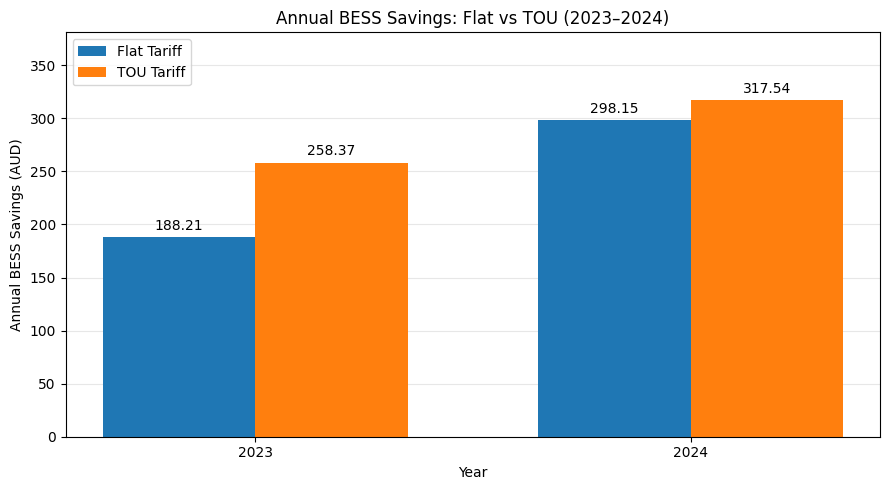

In [187]:
# Prepare annual BESS savings data
annual_savings_plot = (
    two_year_bess_summary["BESS savings (AUD)"]
    .unstack("Tariff")
    .loc[[2023, 2024], ["Flat", "TOU"]]
)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(annual_savings_plot))
bar_width = 0.35

bars_flat = ax.bar(
    x - bar_width / 2,
    annual_savings_plot["Flat"],
    bar_width,
    label="Flat Tariff"
)

bars_tou = ax.bar(
    x + bar_width / 2,
    annual_savings_plot["TOU"],
    bar_width,
    label="TOU Tariff"
)

# Add value labels
ax.bar_label(bars_flat, fmt="%.2f", padding=3)
ax.bar_label(bars_tou, fmt="%.2f", padding=3)

# Format chart
ax.set_xticks(x)
ax.set_xticklabels(annual_savings_plot.index.astype(str))
ax.set_xlabel("Year")
ax.set_ylabel("Annual BESS Savings (AUD)")
ax.set_title("Annual BESS Savings: Flat vs TOU (2023–2024)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, annual_savings_plot.to_numpy().max() * 1.2)

plt.tight_layout()
plt.show()


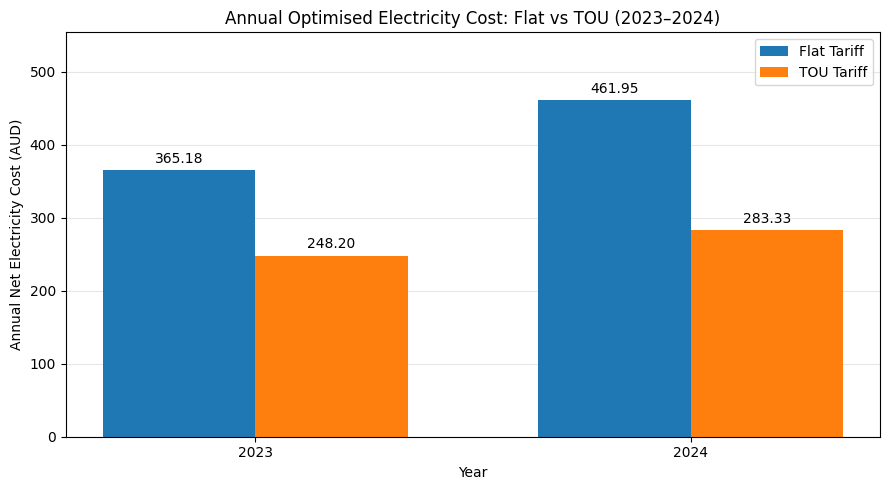

In [188]:
# Prepare annual optimised electricity cost data
annual_cost_plot = (
    two_year_bess_summary["Optimised cost (AUD)"]
    .unstack("Tariff")
    .loc[[2023, 2024], ["Flat", "TOU"]]
)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(annual_cost_plot))
bar_width = 0.35

bars_flat = ax.bar(
    x - bar_width / 2,
    annual_cost_plot["Flat"],
    bar_width,
    label="Flat Tariff"
)

bars_tou = ax.bar(
    x + bar_width / 2,
    annual_cost_plot["TOU"],
    bar_width,
    label="TOU Tariff"
)

# Add value labels
ax.bar_label(bars_flat, fmt="%.2f", padding=3)
ax.bar_label(bars_tou, fmt="%.2f", padding=3)

# Format chart
ax.set_xticks(x)
ax.set_xticklabels(annual_cost_plot.index.astype(str))
ax.set_xlabel("Year")
ax.set_ylabel("Annual Net Electricity Cost (AUD)")
ax.set_title("Annual Optimised Electricity Cost: Flat vs TOU (2023–2024)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, annual_cost_plot.to_numpy().max() * 1.2)

plt.tight_layout()
plt.show()


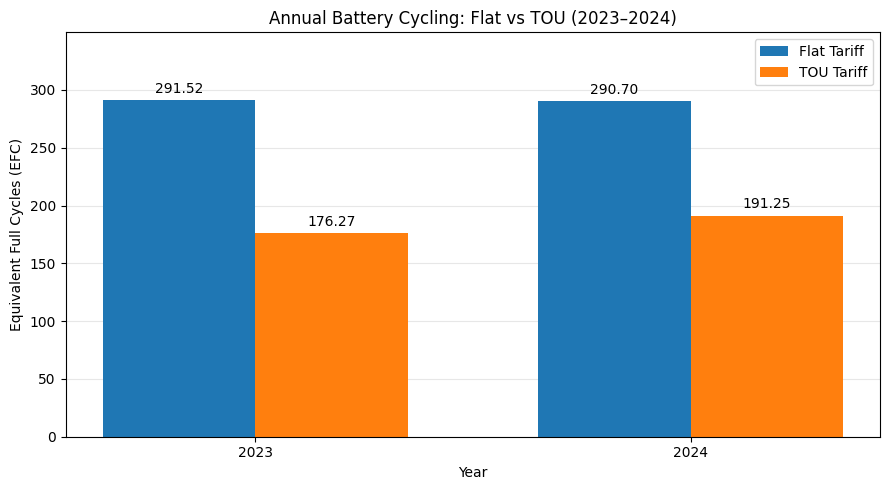

In [189]:
# Prepare annual equivalent full cycle data
annual_efc_plot = (
    two_year_bess_summary["Equivalent full cycles"]
    .unstack("Tariff")
    .loc[[2023, 2024], ["Flat", "TOU"]]
)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(annual_efc_plot))
bar_width = 0.35

bars_flat = ax.bar(
    x - bar_width / 2,
    annual_efc_plot["Flat"],
    bar_width,
    label="Flat Tariff"
)

bars_tou = ax.bar(
    x + bar_width / 2,
    annual_efc_plot["TOU"],
    bar_width,
    label="TOU Tariff"
)

# Add value labels
ax.bar_label(bars_flat, fmt="%.2f", padding=3)
ax.bar_label(bars_tou, fmt="%.2f", padding=3)

# Format chart
ax.set_xticks(x)
ax.set_xticklabels(annual_efc_plot.index.astype(str))
ax.set_xlabel("Year")
ax.set_ylabel("Equivalent Full Cycles (EFC)")
ax.set_title("Annual Battery Cycling: Flat vs TOU (2023–2024)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, annual_efc_plot.to_numpy().max() * 1.2)

plt.tight_layout()
plt.show()


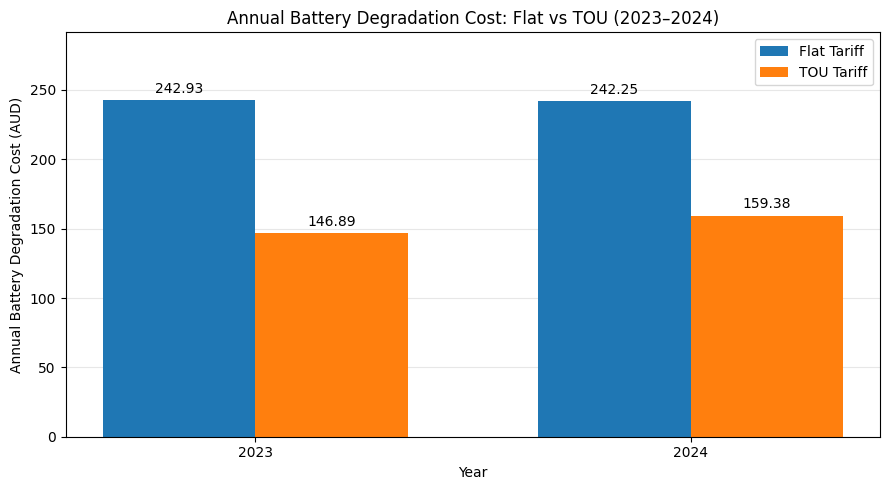

In [190]:
# Prepare annual battery degradation cost data
annual_degradation_plot = (
    two_year_bess_summary["Degradation cost (AUD)"]
    .unstack("Tariff")
    .loc[[2023, 2024], ["Flat", "TOU"]]
)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(annual_degradation_plot))
bar_width = 0.35

bars_flat = ax.bar(
    x - bar_width / 2,
    annual_degradation_plot["Flat"],
    bar_width,
    label="Flat Tariff"
)

bars_tou = ax.bar(
    x + bar_width / 2,
    annual_degradation_plot["TOU"],
    bar_width,
    label="TOU Tariff"
)

# Add value labels
ax.bar_label(bars_flat, fmt="%.2f", padding=3)
ax.bar_label(bars_tou, fmt="%.2f", padding=3)

# Format chart
ax.set_xticks(x)
ax.set_xticklabels(annual_degradation_plot.index.astype(str))
ax.set_xlabel("Year")
ax.set_ylabel("Annual Battery Degradation Cost (AUD)")
ax.set_title("Annual Battery Degradation Cost: Flat vs TOU (2023–2024)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, annual_degradation_plot.to_numpy().max() * 1.2)

plt.tight_layout()
plt.show()


In [191]:
# Prepare 2023 wholesale optimisation data
wholesale_2023 = optimisation_input_2023[
    ["timestamp", "pv_kW", "load_kW"]
].copy()

# Add actual wholesale electricity prices
wholesale_2023["wholesale_price_AUD/kWh"] = (
    df_clean.loc[
        df_clean["timestamp"].dt.year == 2023,
        "spot_price_AUD/kWh"
    ].to_numpy()
)

# Display wholesale price summary
print("2023 wholesale optimisation records:", len(wholesale_2023))

display(
    wholesale_2023[
        ["wholesale_price_AUD/kWh"]
    ].describe().round(4)
)

2023 wholesale optimisation records: 105120


,wholesale_price_AUD/kWh
count,105120.0000
mean,0.0801
std,0.3967
min,-0.9990
25%,0.0000
50%,0.0591
75%,0.1151
max,16.6000


In [192]:
# Assumed time-dependent network charges (AUD/kWh)
network_peak_rate = 0.15
network_shoulder_rate = 0.08
network_offpeak_rate = 0.04

# Use the existing TOU time periods
hours = wholesale_2023["timestamp"].dt.hour

wholesale_2023["network_cost_AUD/kWh"] = np.select(
    [
        hours.isin(tou_peak_hours),
        hours.isin(tou_offpeak_hours)
    ],
    [network_peak_rate, network_offpeak_rate],
    default=network_shoulder_rate
)

# Summarise network charges
network_cost_summary = (
    wholesale_2023.groupby("network_cost_AUD/kWh")
    .size()
    .to_frame("Records")
)

network_cost_summary["Hours"] = (
    network_cost_summary["Records"] / 12
)

print("2023 assumed time-dependent network charges:")
display(network_cost_summary)

2023 assumed time-dependent network charges:


,Records,Hours
network_cost_AUD/kWh,,
0.04,39420,3285.0
0.08,48180,4015.0
0.15,17520,1460.0


In [193]:
# Assumed additional wholesale passthrough costs (AUD/kWh)
market_fee_rate = 0.005
environmental_cost_rate = 0.012
hedging_cost_rate = 0.008
regulatory_cost_rate = 0.005

# Calculate total additional variable cost
additional_wholesale_cost = (
    market_fee_rate
    + environmental_cost_rate
    + hedging_cost_rate
    + regulatory_cost_rate
)

# Add costs to wholesale data
wholesale_2023["additional_cost_AUD/kWh"] = additional_wholesale_cost

# Display cost components
additional_cost_summary = pd.DataFrame({
    "Component": [
        "Market fees",
        "Environmental certificates",
        "Hedging costs",
        "Other regulatory costs",
        "Total additional cost"
    ],
    "AUD/kWh": [
        market_fee_rate,
        environmental_cost_rate,
        hedging_cost_rate,
        regulatory_cost_rate,
        additional_wholesale_cost
    ]
})

display(additional_cost_summary)

,Component,AUD/kWh
0,Market fees,0.005
1,Environmental certificates,0.012
2,Hedging costs,0.008
3,Other regulatory costs,0.005
4,Total additional cost,0.030


In [194]:
# Calculate dynamic wholesale passthrough import prices
wholesale_2023["spot_import_AUD/kWh"] = (
    wholesale_2023["wholesale_price_AUD/kWh"]
    + wholesale_2023["network_cost_AUD/kWh"]
    + wholesale_2023["additional_cost_AUD/kWh"]
)

# Set export settlement at wholesale market prices
wholesale_2023["spot_export_AUD/kWh"] = (
    wholesale_2023["wholesale_price_AUD/kWh"]
)

# Summarise dynamic electricity prices
dynamic_price_summary = wholesale_2023[
    [
        "wholesale_price_AUD/kWh",
        "spot_import_AUD/kWh",
        "spot_export_AUD/kWh"
    ]
].agg(["mean", "min", "max"])

print("2023 dynamic wholesale passthrough prices (AUD/kWh):")
display(dynamic_price_summary.round(4))

2023 dynamic wholesale passthrough prices (AUD/kWh):


,wholesale_price_AUD/kWh,spot_import_AUD/kWh,spot_export_AUD/kWh
mean,0.0801,0.1867,0.0801
min,-0.9990,-0.9172,-0.9990
max,16.6000,16.7800,16.6000


In [195]:
# VPP service fee (AUD)
vpp_monthly_fee = 25.0
vpp_annual_fee = vpp_monthly_fee * 12

# Display VPP service fees
vpp_fee_summary = pd.DataFrame({
    "Fee": ["Monthly VPP fee", "Annual VPP fee"],
    "AUD": [vpp_monthly_fee, vpp_annual_fee]
})

display(vpp_fee_summary)

,Fee,AUD
0,Monthly VPP fee,25.0
1,Annual VPP fee,300.0


In [196]:
# Summarise wholesale passthrough assumptions
wholesale_assumptions = pd.DataFrame({
    "Parameter": [
        "Peak network charge",
        "Shoulder network charge",
        "Off-peak network charge",
        "Market fees",
        "Environmental certificates",
        "Hedging costs",
        "Other regulatory costs",
        "Export settlement",
        "Monthly VPP service fee"
    ],
    "Value": [
        network_peak_rate,
        network_shoulder_rate,
        network_offpeak_rate,
        market_fee_rate,
        environmental_cost_rate,
        hedging_cost_rate,
        regulatory_cost_rate,
        "Wholesale spot price",
        vpp_monthly_fee
    ],
    "Unit": [
        "AUD/kWh"
    ] * 7 + ["Method", "AUD/month"],
    "Basis": [
        "Assumption"
    ] * 7 + ["Assumption", "Assignment brief"]
})

print("Wholesale passthrough model assumptions:")
display(wholesale_assumptions)

Wholesale passthrough model assumptions:


,Parameter,Value,Unit,Basis
0,Peak network charge,0.15,AUD/kWh,Assumption
1,Shoulder network charge,0.08,AUD/kWh,Assumption
2,Off-peak network charge,0.04,AUD/kWh,Assumption
3,Market fees,0.005,AUD/kWh,Assumption
4,Environmental certificates,0.012,AUD/kWh,Assumption
5,Hedging costs,0.008,AUD/kWh,Assumption
6,Other regulatory costs,0.005,AUD/kWh,Assumption
7,Export settlement,Wholesale spot price,Method,Assumption
8,Monthly VPP service fee,25.0,AUD/month,Assignment brief


In [197]:
# Prepare 2023 wholesale BESS optimisation input
year_2023_wholesale_data = year_2023_data.copy()

# Replace previous spot price assumptions
year_2023_wholesale_data["spot_import_AUD/kWh"] = (
    wholesale_2023["spot_import_AUD/kWh"].to_numpy()
)

year_2023_wholesale_data["spot_export_AUD/kWh"] = (
    wholesale_2023["spot_export_AUD/kWh"].to_numpy()
)

# Display prepared optimisation inputs
print("2023 wholesale BESS optimisation input:")
display(
    year_2023_wholesale_data[
        [
            "timestamp", "pv_kW", "load_kW",
            "spot_import_AUD/kWh",
            "spot_export_AUD/kWh"
        ]
    ].head()
)

2023 wholesale BESS optimisation input:


,timestamp,pv_kW,load_kW,spot_import_AUD/kWh,spot_export_AUD/kWh
0,2023-01-01 00:00:00,0.0,0.43,0.15292,0.08292
1,2023-01-01 00:05:00,0.0,0.29,0.19757,0.12757
2,2023-01-01 00:10:00,0.0,0.29,0.19285,0.12285
3,2023-01-01 00:15:00,0.0,0.31,0.18114,0.11114
4,2023-01-01 00:20:00,0.0,0.36,0.18025,0.11025


In [198]:
# Select the first 24 hours of 2023
wholesale_test_data = year_2023_wholesale_data.loc[
    (year_2023_wholesale_data["timestamp"] >= "2023-01-01") &
    (year_2023_wholesale_data["timestamp"] < "2023-01-02")
].copy()

# Run wholesale BESS optimisation
wholesale_test_status, wholesale_test_results, wholesale_test_summary = (
    optimise_bess_period(
        wholesale_test_data,
        tariff="spot",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic"
    )
)

# Display optimisation results
print("Wholesale optimisation status:", wholesale_test_status)

if wholesale_test_status == "Optimal":
    display(wholesale_test_summary.round(4))

Wholesale optimisation status: Optimal


Records                 288.0000
Initial energy (kWh)      5.0000
Final energy (kWh)        5.0000
Baseline cost (AUD)       0.5021
Optimised cost (AUD)     -0.8728
Savings (AUD)             1.3749
dtype: float64

In [199]:
# Identify negative wholesale price intervals
wholesale_2023["negative_price"] = (
    wholesale_2023["wholesale_price_AUD/kWh"] < 0
)

# Calculate annual negative price statistics
negative_intervals = wholesale_2023["negative_price"].sum()
negative_hours = negative_intervals / 12
negative_percentage = (
    negative_intervals / len(wholesale_2023) * 100
)

print("2023 negative wholesale price statistics:")
print("Negative intervals:", negative_intervals)
print("Negative hours:", round(negative_hours, 2))
print("Percentage of year (%):", round(negative_percentage, 2))

# Calculate monthly negative price intervals
negative_monthly = (
    wholesale_2023.groupby(
        wholesale_2023["timestamp"].dt.month
    )["negative_price"]
    .sum()
    .to_frame("Negative intervals")
)

negative_monthly.index.name = "Month"

display(negative_monthly)

2023 negative wholesale price statistics:
Negative intervals: 25929
Negative hours: 2160.75
Percentage of year (%): 24.67


,Negative intervals
Month,
1,2549
2,2160
3,2146
4,1558
5,811
6,1848
7,2012
8,1724
9,2670


In [200]:
# Update MILP optimisation with negative-price zero export

def optimise_bess_period(
    period_data,
    tariff="tou",
    initial_energy=None,
    terminal_mode="free",
    terminal_energy=None,
    zero_export_negative=False
):

    # Prepare input data
    data = period_data.copy().reset_index(drop=True)
    n = len(data)
    steps = range(n)

    if n == 0:
        raise ValueError("Input data is empty.")

    # Read operating parameters
    dt_local = bess_parameters["time_step_hours"]
    eta_c = bess_parameters["charge_efficiency"]
    eta_d = bess_parameters["discharge_efficiency"]

    max_charge = bess_parameters["max_charge_kW"]
    max_discharge = bess_parameters["max_discharge_kW"]

    max_import = grid_parameters["max_import_kW"]
    max_export = grid_parameters["max_export_kW"]

    if initial_energy is None:
        initial_energy = bess_initial_energy

    if not bess_min_energy <= initial_energy <= bess_max_energy:
        raise ValueError("Initial energy is outside SOC limits.")

    if terminal_mode not in ["free", "cyclic", "fixed"]:
        raise ValueError("Invalid terminal SOC mode.")

    if terminal_mode == "fixed":
        if terminal_energy is None:
            raise ValueError("Fixed terminal energy is required.")

        if not bess_min_energy <= terminal_energy <= bess_max_energy:
            raise ValueError("Terminal energy is outside SOC limits.")

    # Define tariff columns
    import_col = f"{tariff}_import_AUD/kWh"
    export_col = f"{tariff}_export_AUD/kWh"

    required_columns = [
        "timestamp", "pv_kW", "load_kW",
        import_col, export_col
    ]

    if data[required_columns].isna().any().any():
        raise ValueError("Missing optimisation input values.")

    # Create MILP model
    model = pulp.LpProblem(
        "BESS_Period_Optimisation",
        pulp.LpMinimize
    )

    # Define decision variables
    ch = pulp.LpVariable.dicts("Charge", steps, lowBound=0)
    dis = pulp.LpVariable.dicts("Discharge", steps, lowBound=0)

    soc = pulp.LpVariable.dicts(
        "Stored_Energy",
        range(n + 1),
        lowBound=bess_min_energy,
        upBound=bess_max_energy
    )

    imp = pulp.LpVariable.dicts("Grid_Import", steps, lowBound=0)
    exp = pulp.LpVariable.dicts("Grid_Export", steps, lowBound=0)
    curt = pulp.LpVariable.dicts("PV_Curtailment", steps, lowBound=0)

    b_mode = pulp.LpVariable.dicts(
        "Battery_Mode", steps, cat="Binary"
    )

    g_mode = pulp.LpVariable.dicts(
        "Grid_Mode", steps, cat="Binary"
    )

    # Initial and terminal SOC constraints
    model += soc[0] == initial_energy

    if terminal_mode == "cyclic":
        model += soc[n] == soc[0]

    elif terminal_mode == "fixed":
        model += soc[n] == terminal_energy

    # Operating constraints
    for t in steps:

        pv = float(data.loc[t, "pv_kW"])
        load = float(data.loc[t, "load_kW"])

        model += (
            soc[t + 1] ==
            soc[t] + eta_c * ch[t] * dt_local
            - dis[t] * dt_local / eta_d
        )

        model += ch[t] <= max_charge * b_mode[t]
        model += dis[t] <= max_discharge * (1 - b_mode[t])

        model += imp[t] <= max_import * g_mode[t]
        model += exp[t] <= max_export * (1 - g_mode[t])

        model += curt[t] <= pv

        # Zero export during negative wholesale prices
        if zero_export_negative and tariff == "spot":
            if float(data.loc[t, export_col]) < 0:
                model += exp[t] == 0

        # Power balance
        model += (
            pv + imp[t] + dis[t] ==
            load + ch[t] + exp[t] + curt[t]
        )

    # Objective function
    model += pulp.lpSum(
        (
            imp[t] * float(data.loc[t, import_col])
            - exp[t] * float(data.loc[t, export_col])
            + dis[t] * degradation_cost_per_AC_kWh
        ) * dt_local
        for t in steps
    )

    # Solve MILP
    model.solve(pulp.PULP_CBC_CMD(msg=False))

    status = pulp.LpStatus[model.status]

    if status != "Optimal":
        return status, None, None

    # Extract results
    results = data[["timestamp", "pv_kW", "load_kW"]].copy()

    for name, variables in {
        "charge_kW": ch,
        "discharge_kW": dis,
        "grid_import_kW": imp,
        "grid_export_kW": exp,
        "curtailment_kW": curt
    }.items():
        results[name] = [
            pulp.value(variables[t]) for t in steps
        ]

    results["soc_kWh"] = [
        pulp.value(soc[t + 1]) for t in steps
    ]

    # Baseline electricity cost
    baseline_import = (
        data["load_kW"] - data["pv_kW"]
    ).clip(lower=0) * dt_local

    baseline_export = (
        data["pv_kW"] - data["load_kW"]
    ).clip(lower=0) * dt_local

    baseline_cost = (
        (baseline_import * data[import_col]).sum()
        - (baseline_export * data[export_col]).sum()
    )

    optimised_cost = pulp.value(model.objective)

    # Summary
    summary = pd.Series({
        "Records": n,
        "Initial energy (kWh)": initial_energy,
        "Final energy (kWh)": pulp.value(soc[n]),
        "Baseline cost (AUD)": baseline_cost,
        "Optimised cost (AUD)": optimised_cost,
        "Savings (AUD)": baseline_cost - optimised_cost
    })

    return status, results, summary


print("MILP optimisation updated with optional zero export.")

MILP optimisation updated with optional zero export.


In [201]:
# Select a day with negative prices and surplus PV
test_mask = (
    (wholesale_2023["negative_price"]) &
    (wholesale_2023["pv_kW"] > wholesale_2023["load_kW"])
)

test_date = wholesale_2023.loc[
    test_mask, "timestamp"
].iloc[0].normalize()

zero_export_test_data = year_2023_wholesale_data.loc[
    year_2023_wholesale_data["timestamp"].dt.normalize() == test_date
].copy()

# Run optimisation with zero export enabled
zero_export_status, zero_export_results, zero_export_summary = (
    optimise_bess_period(
        zero_export_test_data,
        tariff="spot",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic",
        zero_export_negative=True
    )
)

print("Test date:", test_date.date())
print("Solver status:", zero_export_status)

if zero_export_status == "Optimal":

    negative_mask = (
        zero_export_test_data["spot_export_AUD/kWh"].to_numpy() < 0
    )

    negative_export = zero_export_results.loc[
        negative_mask, "grid_export_kW"
    ]

    print("Negative price intervals:", negative_mask.sum())
    print("Maximum export during negative prices (kW):",
          round(negative_export.max(), 6))
    print("PV curtailed (kWh):",
          round(zero_export_results["curtailment_kW"].sum() / 12, 4))

    display(zero_export_summary.round(4))

Test date: 2023-01-01
Solver status: Optimal
Negative price intervals: 60
Maximum export during negative prices (kW): 0.0
PV curtailed (kWh): 10.7398


Records                 288.0000
Initial energy (kWh)      5.0000
Final energy (kWh)        5.0000
Baseline cost (AUD)       0.5021
Optimised cost (AUD)     -0.8728
Savings (AUD)             1.3749
dtype: float64

In [202]:
# Run full-year 2023 wholesale BESS optimisation
import time

start_time = time.perf_counter()

year_2023_wholesale_status, year_2023_wholesale_results, year_2023_wholesale_summary = (
    optimise_bess_period(
        year_2023_wholesale_data,
        tariff="spot",
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic",
        zero_export_negative=True
    )
)

runtime_2023_wholesale = time.perf_counter() - start_time

# Display annual optimisation results
print("2023 Wholesale optimisation status:", year_2023_wholesale_status)
print("Runtime (seconds):", round(runtime_2023_wholesale, 2))

if year_2023_wholesale_status == "Optimal":
    display(year_2023_wholesale_summary.round(4))

2023 Wholesale optimisation status: Optimal
Runtime (seconds): 1381.38


Records                 105120.0000
Initial energy (kWh)         5.0000
Final energy (kWh)           5.0000
Baseline cost (AUD)       1156.0671
Optimised cost (AUD)      -308.0326
Savings (AUD)             1464.0998
dtype: float64

In [203]:
# Calculate annual PV curtailment
dt_hours = 5 / 60

curtailment_analysis = year_2023_wholesale_results[
    ["timestamp", "curtailment_kW"]
].merge(
    wholesale_2023[
        ["timestamp", "wholesale_price_AUD/kWh"]
    ],
    on="timestamp",
    how="left"
)

curtailment_analysis["curtailed_kWh"] = (
    curtailment_analysis["curtailment_kW"] * dt_hours
)

# Identify curtailment during negative prices
negative_curtailment = curtailment_analysis[
    curtailment_analysis["wholesale_price_AUD/kWh"] < 0
]

# Calculate avoided negative-price export charges
avoided_export_cost = -(
    negative_curtailment["curtailed_kWh"]
    * negative_curtailment["wholesale_price_AUD/kWh"]
).sum()

# Summarise annual curtailment
curtailment_summary = pd.DataFrame({
    "Metric": [
        "Annual PV curtailment",
        "Curtailment during negative prices",
        "Avoided negative-price export charges"
    ],
    "Value": [
        curtailment_analysis["curtailed_kWh"].sum(),
        negative_curtailment["curtailed_kWh"].sum(),
        avoided_export_cost
    ],
    "Unit": ["kWh", "kWh", "AUD"]
})

display(curtailment_summary.round(4))

,Metric,Value,Unit
0,Annual PV curtailment,5250.8290,kWh
1,Curtailment during negative prices,5187.7527,kWh
2,Avoided negative-price export charges,340.4350,AUD


In [204]:
# Calculate No-BESS electricity flows
dt_hours = 5 / 60

baseline_import_kWh = (
    wholesale_2023["load_kW"] - wholesale_2023["pv_kW"]
).clip(lower=0) * dt_hours

baseline_export_kWh = (
    wholesale_2023["pv_kW"] - wholesale_2023["load_kW"]
).clip(lower=0) * dt_hours

# Apply zero export during negative wholesale prices
baseline_export_zero_kWh = baseline_export_kWh.where(
    ~wholesale_2023["negative_price"], 0
)

# Calculate annual electricity costs
import_cost = (
    baseline_import_kWh * wholesale_2023["spot_import_AUD/kWh"]
).sum()

bill_without_curtailment = import_cost - (
    baseline_export_kWh * wholesale_2023["spot_export_AUD/kWh"]
).sum()

bill_with_curtailment = import_cost - (
    baseline_export_zero_kWh * wholesale_2023["spot_export_AUD/kWh"]
).sum()

# Compare annual costs
baseline_curtailment_comparison = pd.DataFrame({
    "Strategy": [
        "No BESS - Without curtailment",
        "No BESS - Zero export",
        "BESS Optimisation - Zero export"
    ],
    "Annual cost (AUD)": [
        bill_without_curtailment,
        bill_with_curtailment,
        year_2023_wholesale_summary["Optimised cost (AUD)"]
    ]
})

print("2023 wholesale electricity cost comparison:")
display(baseline_curtailment_comparison.round(2))

print(
    "No-BESS benefit from zero export (AUD):",
    round(bill_without_curtailment - bill_with_curtailment, 2)
)

print(
    "BESS savings against zero-export baseline (AUD):",
    round(
        bill_with_curtailment
        - year_2023_wholesale_summary["Optimised cost (AUD)"], 2
    )
)

2023 wholesale electricity cost comparison:


,Strategy,Annual cost (AUD)
0,No BESS - Without curtailment,1156.07
1,No BESS - Zero export,766.36
2,BESS Optimisation - Zero export,-308.03


No-BESS benefit from zero export (AUD): 389.7
BESS savings against zero-export baseline (AUD): 1074.4


In [205]:
# Simulate simple self-consumption BESS operation for 2023
simple_data = year_2023_wholesale_data.reset_index(drop=True)

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

energy = bess_initial_energy
simple_records = []

for pv, load, export_price in simple_data[
    ["pv_kW", "load_kW", "spot_export_AUD/kWh"]
].itertuples(index=False, name=None):

    charge = 0.0
    discharge = 0.0
    curtailment = 0.0

    surplus = max(pv - load, 0)
    deficit = max(load - pv, 0)

    # Charge battery using surplus PV
    if surplus > 0:
        charge = min(
            surplus,
            bess_parameters["max_charge_kW"],
            max(0, (bess_max_energy - energy) / (eta_c * dt))
        )

    # Discharge battery to meet household demand
    elif deficit > 0:
        discharge = min(
            deficit,
            bess_parameters["max_discharge_kW"],
            max(0, (energy - bess_min_energy) * eta_d / dt)
        )

    # Update stored energy
    energy = (
        energy + eta_c * charge * dt
        - discharge * dt / eta_d
    )

    # Calculate grid electricity flows
    grid_power = pv + discharge - load - charge

    grid_import = max(-grid_power, 0)
    grid_export = max(grid_power, 0)

    # Curtail surplus PV during negative wholesale prices
    if export_price < 0:
        curtailment = grid_export
        grid_export = 0.0

    simple_records.append([
        charge,
        discharge,
        energy,
        grid_import,
        grid_export,
        curtailment
    ])

# Store simulation results
simple_self_results = simple_data[
    ["timestamp", "pv_kW", "load_kW"]
].copy()

simple_self_results[
    [
        "charge_kW",
        "discharge_kW",
        "soc_kWh",
        "grid_import_kW",
        "grid_export_kW",
        "curtailment_kW"
    ]
] = simple_records

# Display results
print("Simple self-consumption simulation completed.")
print("Records:", len(simple_self_results))
print("Final energy (kWh):", round(energy, 4))

display(simple_self_results.head())

Simple self-consumption simulation completed.
Records: 105120
Final energy (kWh): 4.3656


,timestamp,pv_kW,load_kW,charge_kW,discharge_kW,soc_kWh,grid_import_kW,grid_export_kW,curtailment_kW
0,2023-01-01 00:00:00,0.0,0.43,0.0,0.43,4.962281,-0.0,0.0,0.0
1,2023-01-01 00:05:00,0.0,0.29,0.0,0.29,4.936842,-0.0,0.0,0.0
2,2023-01-01 00:10:00,0.0,0.29,0.0,0.29,4.911404,-0.0,0.0,0.0
3,2023-01-01 00:15:00,0.0,0.31,0.0,0.31,4.884211,-0.0,0.0,0.0
4,2023-01-01 00:20:00,0.0,0.36,0.0,0.36,4.852632,-0.0,0.0,0.0


In [206]:
# Calculate annual bills for simple self-consumption
dt = bess_parameters["time_step_hours"]

simple_import_kWh = simple_self_results["grid_import_kW"] * dt

simple_export_kWh = simple_self_results["grid_export_kW"] * dt

# Restore curtailed exports for Flat and TOU tariffs
simple_export_no_curtail_kWh = (
    simple_self_results["grid_export_kW"]
    + simple_self_results["curtailment_kW"]
) * dt

# Battery degradation cost
simple_degradation_cost = (
    simple_self_results["discharge_kW"].sum()
    * dt * degradation_cost_per_AC_kWh
)

simple_bill_records = []

for tariff in ["flat", "tou", "spot"]:

    import_price = year_2023_wholesale_data[
        f"{tariff}_import_AUD/kWh"
    ].to_numpy()

    export_price = year_2023_wholesale_data[
        f"{tariff}_export_AUD/kWh"
    ].to_numpy()

    export_energy = (
        simple_export_kWh
        if tariff == "spot"
        else simple_export_no_curtail_kWh
    )

    electricity_cost = (
        (simple_import_kWh.to_numpy() * import_price).sum()
        - (export_energy.to_numpy() * export_price).sum()
    )

    service_fee = vpp_annual_fee if tariff == "spot" else 0.0

    annual_bill = (
        electricity_cost
        + simple_degradation_cost
        + service_fee
    )

    simple_bill_records.append({
        "Tariff": tariff.upper(),
        "Electricity cost (AUD)": electricity_cost,
        "Degradation cost (AUD)": simple_degradation_cost,
        "VPP fee (AUD)": service_fee,
        "Annual bill (AUD)": annual_bill
    })

simple_annual_bills = pd.DataFrame(simple_bill_records)

print("2023 Simple Self-consumption Annual Bills:")
display(simple_annual_bills.round(2))

2023 Simple Self-consumption Annual Bills:


,Tariff,Electricity cost (AUD),Degradation cost (AUD),VPP fee (AUD),Annual bill (AUD)
0,FLAT,122.09,243.0,0.0,365.09
1,TOU,35.96,243.0,0.0,278.96
2,SPOT,293.50,243.0,300.0,836.50


In [207]:
# Collect 2023 No-BESS annual electricity costs
no_bess_bills = {
    "FLAT": year_2023_flat_summary["Baseline cost (AUD)"],
    "TOU": year_2023_summary["Baseline cost (AUD)"],
    "SPOT": bill_with_curtailment
}

# Collect Perfect Foresight optimisation costs
perfect_optimisation_bills = {
    "FLAT": year_2023_flat_summary["Optimised cost (AUD)"],
    "TOU": year_2023_summary["Optimised cost (AUD)"],
    "SPOT": (
        year_2023_wholesale_summary["Optimised cost (AUD)"]
        + vpp_annual_fee
    )
}

# Combine annual bills
annual_tariff_comparison = pd.DataFrame({
    "Tariff": ["FLAT", "TOU", "SPOT"],
    "No BESS (AUD)": [
        no_bess_bills[t] for t in ["FLAT", "TOU", "SPOT"]
    ],
    "Simple self-consumption (AUD)": [
        simple_annual_bills.loc[
            simple_annual_bills["Tariff"] == t,
            "Annual bill (AUD)"
        ].iloc[0]
        for t in ["FLAT", "TOU", "SPOT"]
    ],
    "Perfect Foresight (AUD)": [
        perfect_optimisation_bills[t]
        for t in ["FLAT", "TOU", "SPOT"]
    ]
})

print("2023 annual electricity bill comparison:")
display(annual_tariff_comparison.round(2))

2023 annual electricity bill comparison:


,Tariff,No BESS (AUD),Simple self-consumption (AUD),Perfect Foresight (AUD)
0,FLAT,553.39,365.09,365.18
1,TOU,506.57,278.96,248.20
2,SPOT,766.36,836.50,-8.03


In [208]:
# Calculate annual savings between operating strategies
annual_savings_comparison = annual_tariff_comparison[
    ["Tariff"]
].copy()

# Savings from simple self-consumption
annual_savings_comparison["Simple vs No BESS (AUD)"] = (
    annual_tariff_comparison["No BESS (AUD)"]
    - annual_tariff_comparison["Simple self-consumption (AUD)"]
)

# Savings from perfect foresight
annual_savings_comparison["Perfect vs No BESS (AUD)"] = (
    annual_tariff_comparison["No BESS (AUD)"]
    - annual_tariff_comparison["Perfect Foresight (AUD)"]
)

# Additional value of perfect foresight optimisation
annual_savings_comparison["Perfect vs Simple (AUD)"] = (
    annual_tariff_comparison["Simple self-consumption (AUD)"]
    - annual_tariff_comparison["Perfect Foresight (AUD)"]
)

print("2023 annual savings comparison:")
display(annual_savings_comparison.round(2))

2023 annual savings comparison:


,Tariff,Simple vs No BESS (AUD),Perfect vs No BESS (AUD),Perfect vs Simple (AUD)
0,FLAT,188.29,188.21,-0.08
1,TOU,227.62,258.37,30.75
2,SPOT,-70.14,774.40,844.53


In [209]:
# Calculate PV local utilisation for different strategies
dt = bess_parameters["time_step_hours"]

pv_annual_kWh = year_2023_wholesale_data["pv_kW"].sum() * dt

# Direct PV consumption
pv_direct_kWh = (
    np.minimum(
        year_2023_wholesale_data["pv_kW"],
        year_2023_wholesale_data["load_kW"]
    ).sum() * dt
)

pv_surplus = (
    year_2023_wholesale_data["pv_kW"]
    - year_2023_wholesale_data["load_kW"]
).clip(lower=0).to_numpy()

# Compare operating strategies
pv_utilisation_records = []

strategies = {
    "No BESS": None,
    "Simple self-consumption": simple_self_results,
    "Flat Perfect Foresight": year_2023_flat_results,
    "TOU Perfect Foresight": year_2023_results,
    "Wholesale Perfect Foresight": year_2023_wholesale_results
}

for strategy, results in strategies.items():

    if results is None:
        pv_charge_kWh = 0.0
    else:
        pv_charge_kWh = (
            np.minimum(
                pv_surplus,
                results["charge_kW"].to_numpy()
            ).sum() * dt
        )

    pv_local_kWh = pv_direct_kWh + pv_charge_kWh

    pv_utilisation_records.append({
        "Strategy": strategy,
        "Direct PV use (kWh)": pv_direct_kWh,
        "PV battery charging (kWh)": pv_charge_kWh,
        "PV local utilisation (%)": (
            pv_local_kWh / pv_annual_kWh * 100
        )
    })

pv_utilisation_comparison = pd.DataFrame(pv_utilisation_records)

print("2023 PV local utilisation comparison:")
display(pv_utilisation_comparison.round(2))

2023 PV local utilisation comparison:


,Strategy,Direct PV use (kWh),PV battery charging (kWh),PV local utilisation (%)
0,No BESS,5023.42,0.00,29.85
1,Simple self-consumption,5023.42,2454.90,44.44
2,Flat Perfect Foresight,5023.42,2454.90,44.44
3,TOU Perfect Foresight,5023.42,1447.05,38.45
4,Wholesale Perfect Foresight,5023.42,2699.12,45.89


In [210]:
# Calculate annual grid import and export
dt = bess_parameters["time_step_hours"]

# No-BESS grid flows
no_bess_import = (
    year_2023_wholesale_data["load_kW"]
    - year_2023_wholesale_data["pv_kW"]
).clip(lower=0).sum() * dt

no_bess_export = (
    year_2023_wholesale_data["pv_kW"]
    - year_2023_wholesale_data["load_kW"]
).clip(lower=0).sum() * dt

# Compare operating strategies
grid_records = []

strategies = {
    "No BESS": None,
    "Simple self-consumption": simple_self_results,
    "Flat Perfect Foresight": year_2023_flat_results,
    "TOU Perfect Foresight": year_2023_results,
    "Wholesale Perfect Foresight": year_2023_wholesale_results
}

for strategy, results in strategies.items():

    if results is None:
        import_kWh = no_bess_import
        export_kWh = no_bess_export

    else:
        import_kWh = results["grid_import_kW"].sum() * dt
        export_kWh = results["grid_export_kW"].sum() * dt

        # Restore exports for Flat and TOU simple operation
        if strategy == "Simple self-consumption":
            export_kWh += (
                results["curtailment_kW"].sum() * dt
            )

    grid_records.append({
        "Strategy": strategy,
        "Grid import (kWh)": import_kWh,
        "Grid export (kWh)": export_kWh
    })

grid_energy_comparison = pd.DataFrame(grid_records)

print("2023 annual grid energy comparison:")
display(grid_energy_comparison.round(2))

2023 annual grid energy comparison:


,Strategy,Grid import (kWh),Grid export (kWh)
0,No BESS,4574.39,11804.21
1,Simple self-consumption,2358.24,9349.31
2,Flat Perfect Foresight,2358.84,9349.31
3,TOU Perfect Foresight,3272.07,10357.16
4,Wholesale Perfect Foresight,3795.24,5445.65


In [211]:
# Compare annual BESS operation across strategies
dt = bess_parameters["time_step_hours"]

bess_operation_records = []

bess_strategies = {
    "Simple self-consumption": simple_self_results,
    "Flat Perfect Foresight": year_2023_flat_results,
    "TOU Perfect Foresight": year_2023_results,
    "Wholesale Perfect Foresight": year_2023_wholesale_results
}

for strategy, results in bess_strategies.items():

    bess_operation_records.append({
        "Strategy": strategy,
        "Charging (kWh)": results["charge_kW"].sum() * dt,
        "Discharging (kWh)": results["discharge_kW"].sum() * dt,
        "Average SOC (kWh)": results["soc_kWh"].mean(),
        "Minimum SOC (kWh)": results["soc_kWh"].min(),
        "Maximum SOC (kWh)": results["soc_kWh"].max()
    })

bess_operation_comparison = pd.DataFrame(bess_operation_records)

print("2023 BESS operational comparison:")
display(bess_operation_comparison.round(2))

2023 BESS operational comparison:


,Strategy,Charging (kWh),Discharging (kWh),Average SOC (kWh),Minimum SOC (kWh),Maximum SOC (kWh)
0,Simple self-consumption,2454.90,2216.15,5.86,1.0,9.0
1,Flat Perfect Foresight,2454.90,2215.55,3.28,1.0,9.0
2,TOU Perfect Foresight,1484.39,1339.66,1.94,1.0,9.0
3,Wholesale Perfect Foresight,3370.10,3041.51,3.78,1.0,9.0


In [212]:
# Calculate BESS equivalent full cycles and degradation costs
eta_d = bess_parameters["discharge_efficiency"]
usable_capacity = bess_max_energy - bess_min_energy

bess_cycle_comparison = bess_operation_comparison[
    ["Strategy", "Charging (kWh)", "Discharging (kWh)"]
].copy()

# Convert AC discharge energy to battery internal energy
bess_cycle_comparison["Battery discharge (kWh)"] = (
    bess_cycle_comparison["Discharging (kWh)"] / eta_d
)

# Calculate equivalent full cycles
bess_cycle_comparison["Equivalent full cycles"] = (
    bess_cycle_comparison["Battery discharge (kWh)"]
    / usable_capacity
)

# Calculate degradation cost
bess_cycle_comparison["Degradation cost (AUD)"] = (
    bess_cycle_comparison["Discharging (kWh)"]
    * degradation_cost_per_AC_kWh
)

print("2023 BESS cycling and degradation comparison:")
display(bess_cycle_comparison.round(2))

2023 BESS cycling and degradation comparison:


,Strategy,Charging (kWh),Discharging (kWh),Battery discharge (kWh),Equivalent full cycles,Degradation cost (AUD)
0,Simple self-consumption,2454.90,2216.15,2332.79,291.60,243.00
1,Flat Perfect Foresight,2454.90,2215.55,2332.15,291.52,242.93
2,TOU Perfect Foresight,1484.39,1339.66,1410.17,176.27,146.89
3,Wholesale Perfect Foresight,3370.10,3041.51,3201.59,400.20,333.50


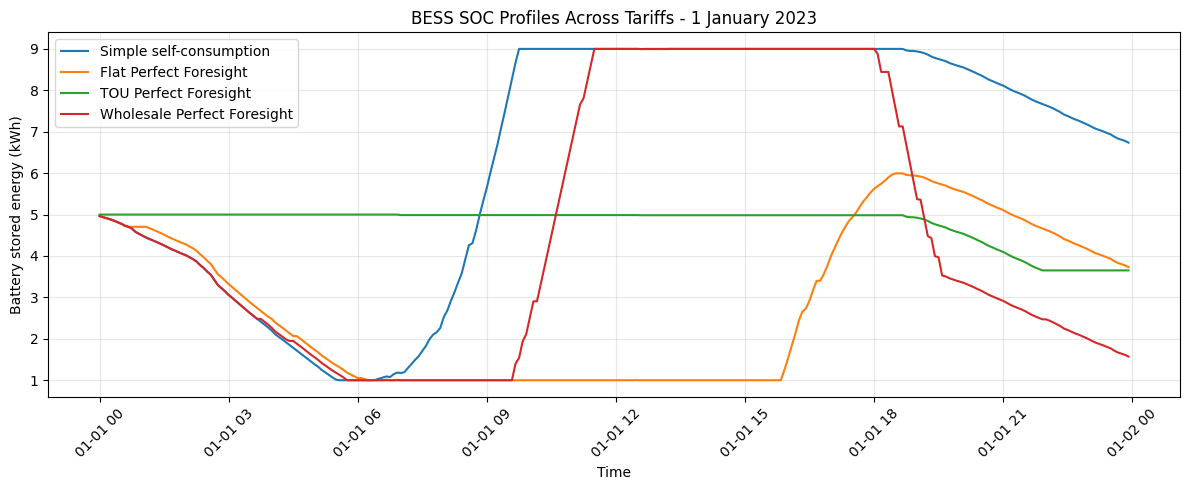

In [213]:
# Compare BESS SOC profiles on a representative day
selected_date = "2023-01-01"

soc_profiles = {
    "Simple self-consumption": simple_self_results,
    "Flat Perfect Foresight": year_2023_flat_results,
    "TOU Perfect Foresight": year_2023_results,
    "Wholesale Perfect Foresight": year_2023_wholesale_results
}

plt.figure(figsize=(12, 5))

for strategy, results in soc_profiles.items():

    daily = results.loc[
        results["timestamp"].dt.strftime("%Y-%m-%d") == selected_date
    ]

    plt.plot(
        daily["timestamp"],
        daily["soc_kWh"],
        label=strategy,
        linewidth=1.5
    )

plt.xlabel("Time")
plt.ylabel("Battery stored energy (kWh)")
plt.title("BESS SOC Profiles Across Tariffs - 1 January 2023")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

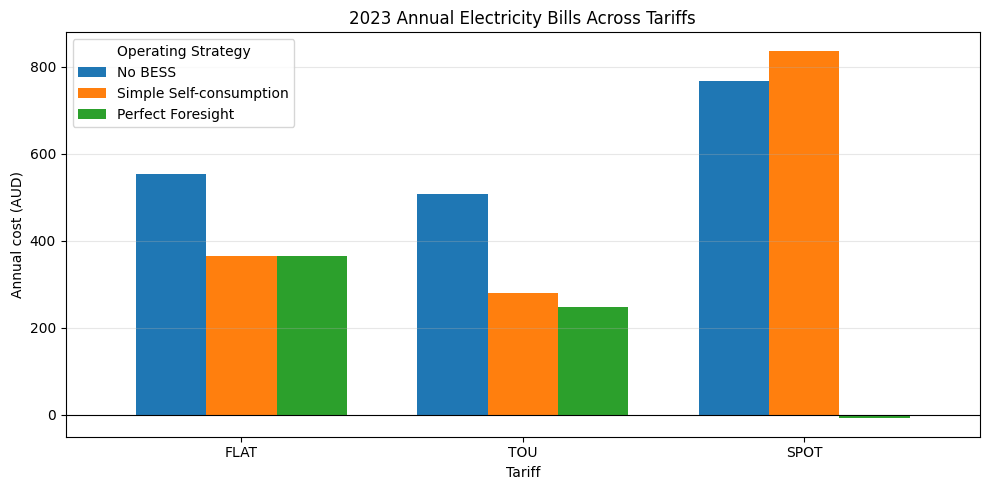

In [214]:
# Plot annual electricity bills across tariffs
bill_plot = annual_tariff_comparison.set_index("Tariff")[
    [
        "No BESS (AUD)",
        "Simple self-consumption (AUD)",
        "Perfect Foresight (AUD)"
    ]
]

ax = bill_plot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

# Add zero reference line
ax.axhline(0, color="black", linewidth=0.8)

# Chart labels
ax.set_title("2023 Annual Electricity Bills Across Tariffs")
ax.set_xlabel("Tariff")
ax.set_ylabel("Annual cost (AUD)")
ax.tick_params(axis="x", rotation=0)

# Use the correct bar labels
ax.legend(
    title="Operating Strategy",
    labels=[
        "No BESS",
        "Simple Self-consumption",
        "Perfect Foresight"
    ],
    handles=ax.containers
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("2023 Annual Electricity Bills Across Tariffs", dpi=300, bbox_inches="tight")
plt.show()

In [215]:
# Compare gross savings and battery degradation costs
economic_records = []

for tariff, strategy in [
    ("FLAT", "Flat Perfect Foresight"),
    ("TOU", "TOU Perfect Foresight"),
    ("SPOT", "Wholesale Perfect Foresight")
]:

    no_bess_bill = no_bess_bills[tariff]

    optimised_bill = perfect_optimisation_bills[tariff]

    degradation_cost = bess_cycle_comparison.loc[
        bess_cycle_comparison["Strategy"] == strategy,
        "Degradation cost (AUD)"
    ].iloc[0]

    service_fee = vpp_annual_fee if tariff == "SPOT" else 0.0

    # Remove degradation and service fees from optimised bill
    optimised_electricity_cost = (
        optimised_bill - degradation_cost - service_fee
    )

    # Calculate gross and net savings
    gross_savings = no_bess_bill - optimised_electricity_cost

    net_savings = (
        gross_savings - degradation_cost - service_fee
    )

    economic_records.append({
        "Tariff": tariff,
        "Gross savings (AUD)": gross_savings,
        "Degradation cost (AUD)": degradation_cost,
        "VPP fee (AUD)": service_fee,
        "Net savings (AUD)": net_savings
    })

economic_feasibility_summary = pd.DataFrame(economic_records)

print("2023 BESS economic feasibility:")
display(economic_feasibility_summary.round(2))

2023 BESS economic feasibility:


,Tariff,Gross savings (AUD),Degradation cost (AUD),VPP fee (AUD),Net savings (AUD)
0,FLAT,431.14,242.93,0.0,188.21
1,TOU,405.26,146.89,0.0,258.37
2,SPOT,1407.89,333.50,300.0,774.40


In [216]:
# Calculate additional value of VPP optimisation

simple_spot_bill = simple_annual_bills.loc[
    simple_annual_bills["Tariff"] == "SPOT",
    "Annual bill (AUD)"
].iloc[0]

perfect_spot_bill = perfect_optimisation_bills["SPOT"]

# Remove VPP fee from the simple operating strategy
simple_without_vpp_fee = simple_spot_bill - vpp_annual_fee

# Calculate additional optimisation value
vpp_value_before_fee = (
    simple_without_vpp_fee
    - (perfect_spot_bill - vpp_annual_fee)
)

vpp_value_after_fee = (
    simple_without_vpp_fee - perfect_spot_bill
)

# Summarise results
vpp_value_summary = pd.DataFrame({
    "Metric": [
        "Simple self-consumption without VPP fee",
        "Perfect Foresight with VPP fee",
        "Additional optimisation value before fee",
        "Annual VPP service fee",
        "Additional optimisation value after fee"
    ],
    "AUD/year": [
        simple_without_vpp_fee,
        perfect_spot_bill,
        vpp_value_before_fee,
        vpp_annual_fee,
        vpp_value_after_fee
    ]
})

print("2023 VPP optimisation service value:")
display(vpp_value_summary.round(2))

2023 VPP optimisation service value:


,Metric,AUD/year
0,Simple self-consumption without VPP fee,536.50
1,Perfect Foresight with VPP fee,-8.03
2,Additional optimisation value before fee,844.53
3,Annual VPP service fee,300.00
4,Additional optimisation value after fee,544.53


In [217]:
# Prepare 2023 PV forecasting training data
pv_training_2023 = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    [
        "timestamp",
        "solar_filled_kW",
        "irradiance_W/m^2",
        "temperature_C"
    ]
].copy()

# Rename target variable
pv_training_2023 = pv_training_2023.rename(
    columns={"solar_filled_kW": "pv_actual_kW"}
)

# Create time-based features
pv_training_2023["hour"] = (
    pv_training_2023["timestamp"].dt.hour
    + pv_training_2023["timestamp"].dt.minute / 60
)

pv_training_2023["day_of_year"] = (
    pv_training_2023["timestamp"].dt.dayofyear
)

# Define forecasting features and target
pv_feature_columns = [
    "irradiance_W/m^2",
    "temperature_C",
    "hour",
    "day_of_year"
]

pv_target_column = "pv_actual_kW"

# Display training data
print("2023 PV forecasting training records:", len(pv_training_2023))

display(
    pv_training_2023[
        ["timestamp"] + pv_feature_columns + [pv_target_column]
    ].head()
)

2023 PV forecasting training records: 105120


,timestamp,irradiance_W/m^2,temperature_C,hour,day_of_year,pv_actual_kW
0,2023-01-01 00:00:00,0.0,26.8,0.000000,1,0.0
1,2023-01-01 00:05:00,0.0,26.7,0.083333,1,0.0
2,2023-01-01 00:10:00,0.0,26.7,0.166667,1,0.0
3,2023-01-01 00:15:00,0.0,26.6,0.250000,1,0.0
4,2023-01-01 00:20:00,0.0,26.6,0.333333,1,0.0


In [218]:
# Split 2023 PV data chronologically
pv_train = pv_training_2023.loc[
    pv_training_2023["timestamp"] < "2023-10-01"
].copy()

pv_validation = pv_training_2023.loc[
    pv_training_2023["timestamp"] >= "2023-10-01"
].copy()

# Prepare input features and target values
X_train = pv_train[pv_feature_columns]
y_train = pv_train[pv_target_column]

X_val = pv_validation[pv_feature_columns]
y_val = pv_validation[pv_target_column]

# Summarise training and validation periods
pv_split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Start": [
        pv_train["timestamp"].min(),
        pv_validation["timestamp"].min()
    ],
    "End": [
        pv_train["timestamp"].max(),
        pv_validation["timestamp"].max()
    ],
    "Records": [
        len(pv_train),
        len(pv_validation)
    ]
})

print("2023 PV forecasting data split:")
display(pv_split_summary)

2023 PV forecasting data split:


,Dataset,Start,End,Records
0,Training,2023-01-01,2023-09-30 23:55:00,78624
1,Validation,2023-10-01,2023-12-31 23:55:00,26496


In [219]:
from sklearn.ensemble import RandomForestRegressor
import time

# Define PV forecasting model
pv_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train model using 2023 training data
start_time = time.perf_counter()

pv_rf_model.fit(X_train, y_train)

pv_training_time = time.perf_counter() - start_time

# Display training information
print("PV Random Forest model trained successfully.")
print("Training records:", len(X_train))
print("Number of features:", len(pv_feature_columns))
print("Training time (seconds):", round(pv_training_time, 2))

PV Random Forest model trained successfully.
Training records: 78624
Number of features: 4
Training time (seconds): 0.41


In [220]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict PV generation for the validation period
pv_val_pred = pv_rf_model.predict(X_val)

# Prevent negative PV predictions
pv_val_pred = np.maximum(pv_val_pred, 0)

# Calculate validation errors
pv_val_mae = mean_absolute_error(y_val, pv_val_pred)

pv_val_rmse = np.sqrt(
    mean_squared_error(y_val, pv_val_pred)
)

# Use observed training peak for normalisation
pv_training_peak_kW = y_train.max()

# Calculate normalised RMSE
pv_val_nrmse = (
    pv_val_rmse / pv_training_peak_kW * 100
)

# Summarise validation results
pv_validation_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "nRMSE",
        "Observed training PV peak"
    ],
    "Value": [
        pv_val_mae,
        pv_val_rmse,
        pv_val_nrmse,
        pv_training_peak_kW
    ],
    "Unit": ["kW", "kW", "%", "kW"]
})

print("2023 PV forecast validation results:")
print("nRMSE basis: Maximum observed PV power in training data")

display(pv_validation_summary.round(4))

2023 PV forecast validation results:
nRMSE basis: Maximum observed PV power in training data


,Metric,Value,Unit
0,MAE,0.2890,kW
1,RMSE,0.6442,kW
2,nRMSE,5.7777,%
3,Observed training PV peak,11.1500,kW


In [221]:
# Train final PV model using all 2023 data
from sklearn.ensemble import RandomForestRegressor

# Prepare full-year training features and target
X_full_2023 = pv_training_2023[pv_feature_columns]
y_full_2023 = pv_training_2023[pv_target_column]

# Create final forecasting model
pv_final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train model with complete 2023 data
pv_final_model.fit(X_full_2023, y_full_2023)

# Display training summary
print("Final PV forecasting model trained successfully.")
print("Training year: 2023")
print("Training records:", len(X_full_2023))
print("Number of features:", len(pv_feature_columns))
print("Model: Random Forest Regressor")

Final PV forecasting model trained successfully.
Training year: 2023
Training records: 105120
Number of features: 4
Model: Random Forest Regressor


In [222]:
# Prepare 2024 PV forecasting data
pv_forecast_2024 = data_2024[
    ["timestamp", "irradiance_W/m^2", "temperature_C"]
].copy().reset_index(drop=True)

# Create time features
pv_forecast_2024["hour"] = (
    pv_forecast_2024["timestamp"].dt.hour
    + pv_forecast_2024["timestamp"].dt.minute / 60
)

pv_forecast_2024["day_of_year"] = (
    pv_forecast_2024["timestamp"].dt.dayofyear
)

# Prepare model inputs
X_2024 = pv_forecast_2024[pv_feature_columns]

# Generate PV forecasts
pv_forecast_2024["pv_predicted_kW"] = (
    pv_final_model.predict(X_2024)
)

# Display forecast results
print("2024 PV forecast generated successfully.")
print("Forecast records:", len(pv_forecast_2024))

display(
    pv_forecast_2024[
        ["timestamp", "irradiance_W/m^2",
         "temperature_C", "pv_predicted_kW"]
    ].head()
)

2024 PV forecast generated successfully.
Forecast records: 105408


,timestamp,irradiance_W/m^2,temperature_C,pv_predicted_kW
0,2024-01-01 00:00:00,0.0,26.1,0.0
1,2024-01-01 00:05:00,0.0,26.0,0.0
2,2024-01-01 00:10:00,0.0,26.0,0.0
3,2024-01-01 00:15:00,0.0,25.9,0.0
4,2024-01-01 00:20:00,0.0,25.8,0.0


In [223]:
# Check 2024 PV forecast physical limits
pv_limit_kW = pv_training_peak_kW

# Count predictions outside physical limits
negative_predictions = (
    pv_forecast_2024["pv_predicted_kW"] < 0
).sum()

zero_irradiance_mask = (
    pv_forecast_2024["irradiance_W/m^2"] <= 0
)

night_predictions = (
    (pv_forecast_2024["pv_predicted_kW"] > 0)
    & zero_irradiance_mask
).sum()

high_predictions = (
    pv_forecast_2024["pv_predicted_kW"] > pv_limit_kW
).sum()

# Apply physical constraints
pv_forecast_2024["pv_forecast_kW"] = (
    pv_forecast_2024["pv_predicted_kW"]
    .clip(lower=0, upper=pv_limit_kW)
)

pv_forecast_2024.loc[
    zero_irradiance_mask, "pv_forecast_kW"
] = 0.0

# Summarise corrections
pv_forecast_checks = pd.DataFrame({
    "Check": [
        "Negative predictions",
        "Positive predictions at zero irradiance",
        "Predictions above assumed PV limit",
        "Maximum corrected forecast (kW)"
    ],
    "Value": [
        negative_predictions,
        night_predictions,
        high_predictions,
        pv_forecast_2024["pv_forecast_kW"].max()
    ]
})

print("2024 PV forecast physical constraint checks:")
print("Assumed PV upper limit (kW):", pv_limit_kW)

display(pv_forecast_checks)

2024 PV forecast physical constraint checks:
Assumed PV upper limit (kW): 11.15


,Check,Value
0,Negative predictions,0.000000
1,Positive predictions at zero irradiance,0.000000
2,Predictions above assumed PV limit,0.000000
3,Maximum corrected forecast (kW),9.291214


In [224]:
# Prepare commercial PV forecast for 2024
commercial_pv_2024 = forecast_2024[
    ["timestamp", "commercial_forecasted_solar_output_kW"]
].copy()

# Align model and commercial forecasts by timestamp
pv_forecast_comparison_2024 = pv_forecast_2024[
    ["timestamp", "pv_forecast_kW"]
].merge(
    commercial_pv_2024,
    on="timestamp",
    how="inner",
    validate="one_to_one"
)

# Rename columns for comparison
pv_forecast_comparison_2024 = pv_forecast_comparison_2024.rename(
    columns={
        "commercial_forecasted_solar_output_kW": "commercial_pv_kW"
    }
)

# Display aligned forecast data
print("2024 aligned PV forecast records:",
      len(pv_forecast_comparison_2024))

display(pv_forecast_comparison_2024.head())

2024 aligned PV forecast records: 105408


,timestamp,pv_forecast_kW,commercial_pv_kW
0,2024-01-01 00:00:00,0.0,0.0
1,2024-01-01 00:05:00,0.0,0.0
2,2024-01-01 00:10:00,0.0,0.0
3,2024-01-01 00:15:00,0.0,0.0
4,2024-01-01 00:20:00,0.0,0.0


In [225]:
# Calculate 2024 PV forecast errors
commercial_pv = pv_forecast_comparison_2024["commercial_pv_kW"]
model_pv = pv_forecast_comparison_2024["pv_forecast_kW"]

# Calculate forecast errors
pv_2024_mae = mean_absolute_error(commercial_pv, model_pv)

pv_2024_rmse = np.sqrt(
    mean_squared_error(commercial_pv, model_pv)
)

pv_2024_nrmse = (
    pv_2024_rmse / pv_training_peak_kW * 100
)

# Summarise forecast performance
pv_2024_error_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "nRMSE"],
    "Value": [
        pv_2024_mae,
        pv_2024_rmse,
        pv_2024_nrmse
    ],
    "Unit": ["kW", "kW", "%"]
})

print("2024 PV forecast comparison:")
print("Reference: Commercial PV Forecast")
print("nRMSE basis: 2023 observed training peak")

display(pv_2024_error_summary.round(4))

2024 PV forecast comparison:
Reference: Commercial PV Forecast
nRMSE basis: 2023 observed training peak


,Metric,Value,Unit
0,MAE,0.0650,kW
1,RMSE,0.1383,kW
2,nRMSE,1.2407,%


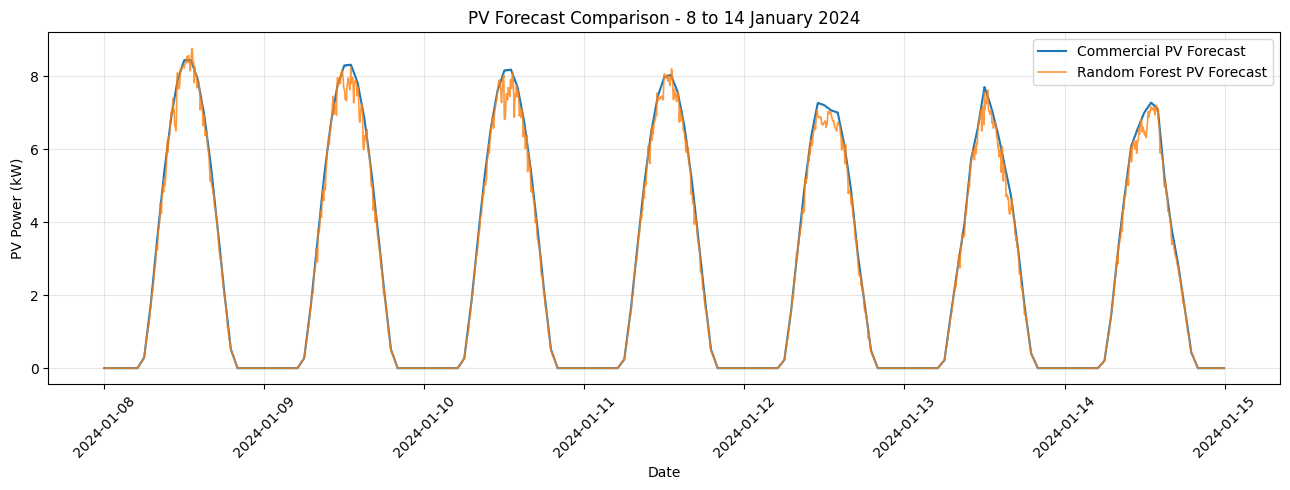

In [226]:
# Select one week for PV forecast comparison
plot_start = "2024-01-08"
plot_end = "2024-01-15"

pv_plot_data = pv_forecast_comparison_2024.loc[
    (pv_forecast_comparison_2024["timestamp"] >= plot_start) &
    (pv_forecast_comparison_2024["timestamp"] < plot_end)
].copy()

# Plot model and commercial PV forecasts
plt.figure(figsize=(13, 5))

plt.plot(
    pv_plot_data["timestamp"],
    pv_plot_data["commercial_pv_kW"],
    label="Commercial PV Forecast",
    linewidth=1.5
)

plt.plot(
    pv_plot_data["timestamp"],
    pv_plot_data["pv_forecast_kW"],
    label="Random Forest PV Forecast",
    linewidth=1.2,
    alpha=0.8
)

plt.title("PV Forecast Comparison - 8 to 14 January 2024")
plt.xlabel("Date")
plt.ylabel("PV Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("PV Forecast Comparison - 8 to 14 January 2024", dpi=300, bbox_inches="tight")
plt.show()

In [227]:
# Calculate monthly PV forecast errors
pv_monthly_data = pv_forecast_comparison_2024.copy()

pv_monthly_data["month"] = (
    pv_monthly_data["timestamp"].dt.month
)

monthly_error_records = []

for month, data in pv_monthly_data.groupby("month"):

    commercial = data["commercial_pv_kW"]
    predicted = data["pv_forecast_kW"]

    mae = mean_absolute_error(commercial, predicted)

    rmse = np.sqrt(
        mean_squared_error(commercial, predicted)
    )

    nrmse = rmse / pv_training_peak_kW * 100

    monthly_error_records.append({
        "Month": month,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse,
        "nRMSE (%)": nrmse
    })

pv_monthly_error_summary = pd.DataFrame(
    monthly_error_records
)

print("2024 monthly PV forecast errors:")
display(pv_monthly_error_summary.round(4))

2024 monthly PV forecast errors:


,Month,MAE (kW),RMSE (kW),nRMSE (%)
0,1,0.0916,0.1802,1.6163
1,2,0.0746,0.1451,1.3011
2,3,0.0602,0.1241,1.1126
3,4,0.0596,0.1242,1.1140
4,5,0.0457,0.0964,0.8648
5,6,0.0325,0.0724,0.6492
6,7,0.0463,0.1036,0.9288
7,8,0.0509,0.1061,0.9518
8,9,0.0619,0.1279,1.1467
9,10,0.0705,0.1424,1.2771


In [228]:
# Prepare 2023 wholesale price forecasting data
price_training_2023 = wholesale_2023[
    ["timestamp", "wholesale_price_AUD/kWh"]
].copy()

# Convert 5-minute prices to hourly average prices
price_hourly_2023 = (
    price_training_2023
    .set_index("timestamp")
    .resample("1h")
    .mean()
    .reset_index()
)

# Display hourly price data
print("2023 wholesale price forecasting data:")
print("5-minute records:", len(price_training_2023))
print("Hourly records:", len(price_hourly_2023))

display(price_hourly_2023.head())

2023 wholesale price forecasting data:
5-minute records: 105120
Hourly records: 8760


,timestamp,wholesale_price_AUD/kWh
0,2023-01-01 00:00:00,0.105191
1,2023-01-01 01:00:00,0.092998
2,2023-01-01 02:00:00,0.083248
3,2023-01-01 03:00:00,0.075554
4,2023-01-01 04:00:00,0.070152


In [229]:
# Create wholesale price forecasting features
import numpy as np

price_hourly_2023["hour"] = (
    price_hourly_2023["timestamp"].dt.hour
)

price_hourly_2023["day_of_week"] = (
    price_hourly_2023["timestamp"].dt.dayofweek
)

price_hourly_2023["month"] = (
    price_hourly_2023["timestamp"].dt.month
)

# Cyclical time features
price_hourly_2023["hour_sin"] = np.sin(
    2 * np.pi * price_hourly_2023["hour"] / 24
)

price_hourly_2023["hour_cos"] = np.cos(
    2 * np.pi * price_hourly_2023["hour"] / 24
)

price_hourly_2023["day_sin"] = np.sin(
    2 * np.pi * price_hourly_2023["day_of_week"] / 7
)

price_hourly_2023["day_cos"] = np.cos(
    2 * np.pi * price_hourly_2023["day_of_week"] / 7
)

# Define forecasting features
price_feature_columns = [
    "month",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

# Display prepared features
print("2023 wholesale price forecasting features:")
print("Records:", len(price_hourly_2023))

display(
    price_hourly_2023[
        ["timestamp"] + price_feature_columns
        + ["wholesale_price_AUD/kWh"]
    ].head()
)

2023 wholesale price forecasting features:
Records: 8760


,timestamp,month,hour_sin,hour_cos,day_sin,day_cos,wholesale_price_AUD/kWh
0,2023-01-01 00:00:00,1,0.000000,1.000000,-0.781831,0.62349,0.105191
1,2023-01-01 01:00:00,1,0.258819,0.965926,-0.781831,0.62349,0.092998
2,2023-01-01 02:00:00,1,0.500000,0.866025,-0.781831,0.62349,0.083248
3,2023-01-01 03:00:00,1,0.707107,0.707107,-0.781831,0.62349,0.075554
4,2023-01-01 04:00:00,1,0.866025,0.500000,-0.781831,0.62349,0.070152


In [230]:
# Split wholesale price data chronologically
price_train = price_hourly_2023.loc[
    price_hourly_2023["timestamp"] < "2023-10-01"
].copy()

price_validation = price_hourly_2023.loc[
    price_hourly_2023["timestamp"] >= "2023-10-01"
].copy()

# Prepare features and target values
X_price_train = price_train[price_feature_columns]
y_price_train = price_train["wholesale_price_AUD/kWh"]

X_price_val = price_validation[price_feature_columns]
y_price_val = price_validation["wholesale_price_AUD/kWh"]

# Summarise training and validation periods
price_split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Start": [
        price_train["timestamp"].min(),
        price_validation["timestamp"].min()
    ],
    "End": [
        price_train["timestamp"].max(),
        price_validation["timestamp"].max()
    ],
    "Records": [
        len(price_train),
        len(price_validation)
    ]
})

print("2023 wholesale price forecasting data split:")
display(price_split_summary)

2023 wholesale price forecasting data split:


,Dataset,Start,End,Records
0,Training,2023-01-01,2023-09-30 23:00:00,6552
1,Validation,2023-10-01,2023-12-31 23:00:00,2208


In [231]:
from sklearn.ensemble import RandomForestRegressor
import time

# Define wholesale price forecasting model
price_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train using 2023 historical wholesale prices
start_time = time.perf_counter()

price_rf_model.fit(X_price_train, y_price_train)

price_training_time = time.perf_counter() - start_time

# Display training information
print("Wholesale price Random Forest model trained successfully.")
print("Training records:", len(X_price_train))
print("Number of features:", len(price_feature_columns))
print("Training time (seconds):", round(price_training_time, 2))

Wholesale price Random Forest model trained successfully.
Training records: 6552
Number of features: 5
Training time (seconds): 0.07


In [232]:
# Predict wholesale prices for the validation period
price_val_pred = price_rf_model.predict(X_price_val)

# Calculate validation errors
price_val_mae = mean_absolute_error(
    y_price_val, price_val_pred
)

price_val_rmse = np.sqrt(
    mean_squared_error(y_price_val, price_val_pred)
)

# Calculate negative price statistics
actual_negative_hours = (y_price_val < 0).sum()
predicted_negative_hours = (price_val_pred < 0).sum()

# Summarise validation results
price_validation_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "Actual negative-price hours",
        "Predicted negative-price hours"
    ],
    "Value": [
        price_val_mae,
        price_val_rmse,
        actual_negative_hours,
        predicted_negative_hours
    ],
    "Unit": [
        "AUD/kWh",
        "AUD/kWh",
        "hours",
        "hours"
    ]
})

print("2023 wholesale price forecast validation:")
display(price_validation_summary.round(4))

2023 wholesale price forecast validation:


,Metric,Value,Unit
0,MAE,0.0600,AUD/kWh
1,RMSE,0.1837,AUD/kWh
2,Actual negative-price hours,745.0000,hours
3,Predicted negative-price hours,645.0000,hours


In [233]:
# Analyse forecast errors under different price conditions
price_error_data = price_validation[
    ["timestamp", "wholesale_price_AUD/kWh"]
].copy()

price_error_data["predicted_price_AUD/kWh"] = price_val_pred

# Define price categories using actual wholesale prices
price_error_data["Price condition"] = np.select(
    [
        price_error_data["wholesale_price_AUD/kWh"] < 0,
        price_error_data["wholesale_price_AUD/kWh"] > 0.30
    ],
    [
        "Negative price",
        "High price"
    ],
    default="Normal price"
)

# Calculate errors for each price condition
price_condition_records = []

for condition in ["Negative price", "Normal price", "High price"]:

    subset = price_error_data.loc[
        price_error_data["Price condition"] == condition
    ]

    if len(subset) == 0:
        continue

    actual = subset["wholesale_price_AUD/kWh"]
    predicted = subset["predicted_price_AUD/kWh"]

    price_condition_records.append({
        "Price condition": condition,
        "Hours": len(subset),
        "MAE (AUD/kWh)": mean_absolute_error(actual, predicted),
        "RMSE (AUD/kWh)": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    })

price_condition_summary = pd.DataFrame(price_condition_records)

print("2023 wholesale price forecast errors by price condition:")
display(price_condition_summary.round(4))

2023 wholesale price forecast errors by price condition:


,Price condition,Hours,MAE (AUD/kWh),RMSE (AUD/kWh)
0,Negative price,745,0.0550,0.0785
1,Normal price,1455,0.0527,0.0701
2,High price,8,1.8686,2.8006


In [234]:
# Train final wholesale price model using all 2023 data
from sklearn.ensemble import RandomForestRegressor

# Prepare full-year training data
X_price_full_2023 = price_hourly_2023[price_feature_columns]
y_price_full_2023 = price_hourly_2023["wholesale_price_AUD/kWh"]

# Define final wholesale price forecasting model
price_final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train using complete 2023 hourly prices
price_final_model.fit(X_price_full_2023, y_price_full_2023)

# Display training information
print("Final wholesale price forecast model trained successfully.")
print("Training year: 2023")
print("Training records:", len(X_price_full_2023))
print("Number of features:", len(price_feature_columns))
print("Model: Random Forest Regressor")

Final wholesale price forecast model trained successfully.
Training year: 2023
Training records: 8760
Number of features: 5
Model: Random Forest Regressor


In [235]:
# Prepare 2024 hourly timestamps
price_forecast_2024 = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2024-01-01",
        end="2025-01-01",
        freq="1h",
        inclusive="left"
    )
})

# Create time features
price_forecast_2024["hour"] = (
    price_forecast_2024["timestamp"].dt.hour
)

price_forecast_2024["day_of_week"] = (
    price_forecast_2024["timestamp"].dt.dayofweek
)

price_forecast_2024["month"] = (
    price_forecast_2024["timestamp"].dt.month
)

price_forecast_2024["hour_sin"] = np.sin(
    2 * np.pi * price_forecast_2024["hour"] / 24
)

price_forecast_2024["hour_cos"] = np.cos(
    2 * np.pi * price_forecast_2024["hour"] / 24
)

price_forecast_2024["day_sin"] = np.sin(
    2 * np.pi * price_forecast_2024["day_of_week"] / 7
)

price_forecast_2024["day_cos"] = np.cos(
    2 * np.pi * price_forecast_2024["day_of_week"] / 7
)

# Generate hourly wholesale price forecasts
price_forecast_2024["forecast_price_AUD/kWh"] = (
    price_final_model.predict(
        price_forecast_2024[price_feature_columns]
    )
)

# Display forecast results
print("2024 wholesale price forecast generated successfully.")
print("Forecast records:", len(price_forecast_2024))
print("Start:", price_forecast_2024["timestamp"].min())
print("End:", price_forecast_2024["timestamp"].max())

display(
    price_forecast_2024[
        ["timestamp", "forecast_price_AUD/kWh"]
    ].head()
)

2024 wholesale price forecast generated successfully.
Forecast records: 8784
Start: 2024-01-01 00:00:00
End: 2024-12-31 23:00:00


,timestamp,forecast_price_AUD/kWh
0,2024-01-01 00:00:00,0.098205
1,2024-01-01 01:00:00,0.086648
2,2024-01-01 02:00:00,0.083185
3,2024-01-01 03:00:00,0.084123
4,2024-01-01 04:00:00,0.093902


In [236]:
# Align hourly wholesale price forecasts with 5-minute timestamps
price_forecast_5min_2024 = pv_forecast_2024[
    ["timestamp"]
].copy()

# Match each 5-minute interval to its forecast hour
price_forecast_5min_2024["forecast_hour"] = (
    price_forecast_5min_2024["timestamp"].dt.floor("h")
)

# Merge hourly price forecasts
price_forecast_5min_2024 = price_forecast_5min_2024.merge(
    price_forecast_2024[
        ["timestamp", "forecast_price_AUD/kWh"]
    ].rename(columns={"timestamp": "forecast_hour"}),
    on="forecast_hour",
    how="left",
    validate="many_to_one"
)

# Display aligned forecast data
print("2024 price forecast alignment:")
print("5-minute records:", len(price_forecast_5min_2024))
print(
    "Missing forecast prices:",
    price_forecast_5min_2024["forecast_price_AUD/kWh"].isna().sum()
)

display(price_forecast_5min_2024.head(15))

2024 price forecast alignment:
5-minute records: 105408
Missing forecast prices: 0


,timestamp,forecast_hour,forecast_price_AUD/kWh
0,2024-01-01 00:00:00,2024-01-01 00:00:00,0.098205
1,2024-01-01 00:05:00,2024-01-01 00:00:00,0.098205
2,2024-01-01 00:10:00,2024-01-01 00:00:00,0.098205
3,2024-01-01 00:15:00,2024-01-01 00:00:00,0.098205
4,2024-01-01 00:20:00,2024-01-01 00:00:00,0.098205
5,2024-01-01 00:25:00,2024-01-01 00:00:00,0.098205
6,2024-01-01 00:30:00,2024-01-01 00:00:00,0.098205
7,2024-01-01 00:35:00,2024-01-01 00:00:00,0.098205
8,2024-01-01 00:40:00,2024-01-01 00:00:00,0.098205
9,2024-01-01 00:45:00,2024-01-01 00:00:00,0.098205


In [237]:
# Prepare 2024 forecast-based dynamic electricity prices
forecast_tariff_2024 = price_forecast_5min_2024[
    ["timestamp", "forecast_price_AUD/kWh"]
].copy()

# Apply existing time-dependent network charges
forecast_hours = forecast_tariff_2024["timestamp"].dt.hour

forecast_tariff_2024["network_cost_AUD/kWh"] = np.select(
    [
        forecast_hours.isin(tou_peak_hours),
        forecast_hours.isin(tou_offpeak_hours)
    ],
    [
        network_peak_rate,
        network_offpeak_rate
    ],
    default=network_shoulder_rate
)

# Apply existing additional wholesale costs
forecast_tariff_2024["additional_cost_AUD/kWh"] = (
    additional_wholesale_cost
)

# Calculate forecast-based import and export prices
forecast_tariff_2024["spot_import_AUD/kWh"] = (
    forecast_tariff_2024["forecast_price_AUD/kWh"]
    + forecast_tariff_2024["network_cost_AUD/kWh"]
    + forecast_tariff_2024["additional_cost_AUD/kWh"]
)

forecast_tariff_2024["spot_export_AUD/kWh"] = (
    forecast_tariff_2024["forecast_price_AUD/kWh"]
)

# Display forecast-based tariff data
print("2024 forecast-based wholesale tariff prepared.")
print("Records:", len(forecast_tariff_2024))

display(
    forecast_tariff_2024[
        [
            "timestamp",
            "forecast_price_AUD/kWh",
            "network_cost_AUD/kWh",
            "spot_import_AUD/kWh",
            "spot_export_AUD/kWh"
        ]
    ].head()
)

2024 forecast-based wholesale tariff prepared.
Records: 105408


,timestamp,forecast_price_AUD/kWh,network_cost_AUD/kWh,spot_import_AUD/kWh,spot_export_AUD/kWh
0,2024-01-01 00:00:00,0.098205,0.04,0.168205,0.098205
1,2024-01-01 00:05:00,0.098205,0.04,0.168205,0.098205
2,2024-01-01 00:10:00,0.098205,0.04,0.168205,0.098205
3,2024-01-01 00:15:00,0.098205,0.04,0.168205,0.098205
4,2024-01-01 00:20:00,0.098205,0.04,0.168205,0.098205


In [238]:
# Prepare 2024 rolling horizon optimisation inputs
rolling_input_2024 = pv_forecast_comparison_2024[
    ["timestamp", "pv_forecast_kW", "commercial_pv_kW"]
].copy()

# Add household load
rolling_input_2024 = rolling_input_2024.merge(
    data_2024[["timestamp", "load_kW"]],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Add forecast-based dynamic electricity prices
rolling_input_2024 = rolling_input_2024.merge(
    forecast_tariff_2024[
        [
            "timestamp",
            "forecast_price_AUD/kWh",
            "spot_import_AUD/kWh",
            "spot_export_AUD/kWh"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Rename columns to distinguish forecast and actual data
rolling_input_2024 = rolling_input_2024.rename(
    columns={
        "load_kW": "load_forecast_kW",
        "spot_import_AUD/kWh": "forecast_import_AUD/kWh",
        "spot_export_AUD/kWh": "forecast_export_AUD/kWh"
    }
)

# Display prepared data
print("2024 rolling horizon input prepared.")
print("Records:", len(rolling_input_2024))

display(rolling_input_2024.head())

2024 rolling horizon input prepared.
Records: 105408


,timestamp,pv_forecast_kW,commercial_pv_kW,load_forecast_kW,forecast_price_AUD/kWh,forecast_import_AUD/kWh,forecast_export_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.0,0.43,0.098205,0.168205,0.098205
1,2024-01-01 00:05:00,0.0,0.0,0.29,0.098205,0.168205,0.098205
2,2024-01-01 00:10:00,0.0,0.0,0.29,0.098205,0.168205,0.098205
3,2024-01-01 00:15:00,0.0,0.0,0.31,0.098205,0.168205,0.098205
4,2024-01-01 00:20:00,0.0,0.0,0.36,0.098205,0.168205,0.098205


In [239]:
# Define 48-hour rolling optimisation windows
rolling_horizon_hours = 48
rolling_update_hours = 1

steps_per_hour = int(
    1 / bess_parameters["time_step_hours"]
)

horizon_steps = rolling_horizon_hours * steps_per_hour
update_steps = rolling_update_hours * steps_per_hour

total_steps = len(rolling_input_2024)

# Build rolling window index
rolling_windows = []

for start_idx in range(0, total_steps, update_steps):

    end_idx = min(
        start_idx + horizon_steps,
        total_steps
    )

    rolling_windows.append({
        "start_idx": start_idx,
        "end_idx": end_idx,
        "start_time": rolling_input_2024.loc[start_idx, "timestamp"],
        "end_time": rolling_input_2024.loc[end_idx - 1, "timestamp"],
        "planning_steps": end_idx - start_idx
    })

rolling_windows_2024 = pd.DataFrame(rolling_windows)

# Display window information
print("Rolling horizon windows prepared.")
print("Total windows:", len(rolling_windows_2024))
print("Planning horizon (hours):", rolling_horizon_hours)
print("Update interval (hours):", rolling_update_hours)

display(rolling_windows_2024.head())
display(rolling_windows_2024.tail(3))

Rolling horizon windows prepared.
Total windows: 8784
Planning horizon (hours): 48
Update interval (hours): 1


,start_idx,end_idx,start_time,end_time,planning_steps
0,0,576,2024-01-01 00:00:00,2024-01-02 23:55:00,576
1,12,588,2024-01-01 01:00:00,2024-01-03 00:55:00,576
2,24,600,2024-01-01 02:00:00,2024-01-03 01:55:00,576
3,36,612,2024-01-01 03:00:00,2024-01-03 02:55:00,576
4,48,624,2024-01-01 04:00:00,2024-01-03 03:55:00,576


,start_idx,end_idx,start_time,end_time,planning_steps
8781,105372,105408,2024-12-31 21:00:00,2024-12-31 23:55:00,36
8782,105384,105408,2024-12-31 22:00:00,2024-12-31 23:55:00,24
8783,105396,105408,2024-12-31 23:00:00,2024-12-31 23:55:00,12


In [240]:
# Prepare the first 48-hour rolling optimisation window
first_window = rolling_windows_2024.iloc[0]

start_idx = int(first_window["start_idx"])
end_idx = int(first_window["end_idx"])

# Extract forecast data for the planning horizon
rolling_test_input = rolling_input_2024.iloc[
    start_idx:end_idx
][
    [
        "timestamp",
        "pv_forecast_kW",
        "load_forecast_kW",
        "forecast_import_AUD/kWh",
        "forecast_export_AUD/kWh"
    ]
].copy()

# Match existing MILP input column names
rolling_test_input = rolling_test_input.rename(
    columns={
        "pv_forecast_kW": "pv_kW",
        "load_forecast_kW": "load_kW",
        "forecast_import_AUD/kWh": "spot_import_AUD/kWh",
        "forecast_export_AUD/kWh": "spot_export_AUD/kWh"
    }
)

# Display prepared window
print("48-hour MILP input prepared.")
print("Records:", len(rolling_test_input))
print("Start:", rolling_test_input["timestamp"].min())
print("End:", rolling_test_input["timestamp"].max())

display(rolling_test_input.head())

48-hour MILP input prepared.
Records: 576
Start: 2024-01-01 00:00:00
End: 2024-01-02 23:55:00


,timestamp,pv_kW,load_kW,spot_import_AUD/kWh,spot_export_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.43,0.168205,0.098205
1,2024-01-01 00:05:00,0.0,0.29,0.168205,0.098205
2,2024-01-01 00:10:00,0.0,0.29,0.168205,0.098205
3,2024-01-01 00:15:00,0.0,0.31,0.168205,0.098205
4,2024-01-01 00:20:00,0.0,0.36,0.168205,0.098205


In [241]:
# Convert 5-minute forecast data to hourly planning inputs
rolling_test_hourly = (
    rolling_test_input
    .set_index("timestamp")
    .resample("1h")
    .agg({
        "pv_kW": "mean",
        "load_kW": "mean",
        "spot_import_AUD/kWh": "mean",
        "spot_export_AUD/kWh": "mean"
    })
    .reset_index()
)

# Display hourly planning data
print("48-hour hourly optimisation input prepared.")
print("Original 5-minute records:", len(rolling_test_input))
print("Hourly planning records:", len(rolling_test_hourly))
print("Planning time step (hours):", 1.0)

display(rolling_test_hourly.head())

48-hour hourly optimisation input prepared.
Original 5-minute records: 576
Hourly planning records: 48
Planning time step (hours): 1.0


,timestamp,pv_kW,load_kW,spot_import_AUD/kWh,spot_export_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.440000,0.168205,0.098205
1,2024-01-01 01:00:00,0.0,0.458333,0.156648,0.086648
2,2024-01-01 02:00:00,0.0,0.864167,0.153185,0.083185
3,2024-01-01 03:00:00,0.0,0.826667,0.154123,0.084123
4,2024-01-01 04:00:00,0.0,0.785833,0.163902,0.093902


In [242]:
# Define hourly MILP optimisation wrapper
def optimise_bess_hourly(
    hourly_data,
    initial_energy,
    terminal_mode="free",
    terminal_energy=None,
    zero_export_negative=True
):

    # Save the original 5-minute time step
    original_dt = bess_parameters["time_step_hours"]

    try:
        # Use a 1-hour planning time step
        bess_parameters["time_step_hours"] = 1.0

        # Reuse the existing MILP optimisation model
        status, results, summary = optimise_bess_period(
            hourly_data,
            tariff="spot",
            initial_energy=initial_energy,
            terminal_mode=terminal_mode,
            terminal_energy=terminal_energy,
            zero_export_negative=zero_export_negative
        )

    finally:
        # Restore the original time step
        bess_parameters["time_step_hours"] = original_dt

    return status, results, summary


print("Hourly MILP optimisation wrapper defined.")
print(
    "Original BESS time step (hours):",
    bess_parameters["time_step_hours"]
)

Hourly MILP optimisation wrapper defined.
Original BESS time step (hours): 0.08333333333333333


In [243]:
# Test the first 48-hour rolling optimisation window
import time

start_time = time.perf_counter()

rolling_test_status, rolling_test_results, rolling_test_summary = (
    optimise_bess_hourly(
        rolling_test_hourly,
        initial_energy=bess_initial_energy,
        terminal_mode="free",
        zero_export_negative=True
    )
)

rolling_test_runtime = time.perf_counter() - start_time

# Display optimisation results
print("48-hour rolling optimisation status:", rolling_test_status)
print("Runtime (seconds):", round(rolling_test_runtime, 3))

if rolling_test_status == "Optimal":

    print("Planning records:", len(rolling_test_results))

    print(
        "Minimum stored energy (kWh):",
        round(rolling_test_results["soc_kWh"].min(), 4)
    )

    print(
        "Maximum stored energy (kWh):",
        round(rolling_test_results["soc_kWh"].max(), 4)
    )

    display(rolling_test_summary.round(4))

    display(
        rolling_test_results[
            [
                "timestamp",
                "charge_kW",
                "discharge_kW",
                "soc_kWh",
                "grid_import_kW",
                "grid_export_kW",
                "curtailment_kW"
            ]
        ].head()
    )

48-hour rolling optimisation status: Optimal
Runtime (seconds): 0.053
Planning records: 48
Minimum stored energy (kWh): 1.0
Maximum stored energy (kWh): 9.0


Records                 48.0000
Initial energy (kWh)     5.0000
Final energy (kWh)       1.8298
Baseline cost (AUD)      1.0059
Optimised cost (AUD)    -0.1761
Savings (AUD)            1.1820
dtype: float64

,timestamp,charge_kW,discharge_kW,soc_kWh,grid_import_kW,grid_export_kW,curtailment_kW
0,2024-01-01 00:00:00,0.0,0.440000,4.536842,0.000000,0.0,0.0
1,2024-01-01 01:00:00,0.0,0.458333,4.054386,0.000000,0.0,0.0
2,2024-01-01 02:00:00,0.0,0.659511,3.360164,0.204656,0.0,0.0
3,2024-01-01 03:00:00,0.0,0.826667,2.489988,0.000000,0.0,0.0
4,2024-01-01 04:00:00,0.0,0.785833,1.662795,0.000000,0.0,0.0


In [244]:
# Extract the first hour of the 48-hour optimisation plan
first_hour_plan = rolling_test_results.iloc[0]

# Select the corresponding 12 five-minute intervals
dispatch_plan_5min = rolling_input_2024.loc[
    (rolling_input_2024["timestamp"] >= first_hour_plan["timestamp"]) &
    (rolling_input_2024["timestamp"] <
     first_hour_plan["timestamp"] + pd.Timedelta(hours=1)),
    ["timestamp"]
].copy()

# Apply hourly charge and discharge setpoints
dispatch_plan_5min["planned_charge_kW"] = (
    first_hour_plan["charge_kW"]
)

dispatch_plan_5min["planned_discharge_kW"] = (
    first_hour_plan["discharge_kW"]
)

# Calculate planned energy for each five-minute interval
dispatch_plan_5min["planned_charge_kWh"] = (
    dispatch_plan_5min["planned_charge_kW"]
    * bess_parameters["time_step_hours"]
)

dispatch_plan_5min["planned_discharge_kWh"] = (
    dispatch_plan_5min["planned_discharge_kW"]
    * bess_parameters["time_step_hours"]
)

print("First-hour BESS dispatch plan:")
print("5-minute intervals:", len(dispatch_plan_5min))

print(
    "Planned charging energy (kWh):",
    round(dispatch_plan_5min["planned_charge_kWh"].sum(), 4)
)

print(
    "Planned discharging energy (kWh):",
    round(dispatch_plan_5min["planned_discharge_kWh"].sum(), 4)
)

display(dispatch_plan_5min.head())

First-hour BESS dispatch plan:
5-minute intervals: 12
Planned charging energy (kWh): 0.0
Planned discharging energy (kWh): 0.44


,timestamp,planned_charge_kW,planned_discharge_kW,planned_charge_kWh,planned_discharge_kWh
0,2024-01-01 00:00:00,0.0,0.44,0.0,0.036667
1,2024-01-01 00:05:00,0.0,0.44,0.0,0.036667
2,2024-01-01 00:10:00,0.0,0.44,0.0,0.036667
3,2024-01-01 00:15:00,0.0,0.44,0.0,0.036667
4,2024-01-01 00:20:00,0.0,0.44,0.0,0.036667


In [245]:
# Simulate the first hour of 5-minute BESS dispatch
dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

energy = bess_initial_energy
dispatch_records = []

for row in dispatch_plan_5min.itertuples(index=False):

    # Apply charging and discharging power limits
    charge = min(
        row.planned_charge_kW,
        bess_parameters["max_charge_kW"],
        max(0, (bess_max_energy - energy) / (eta_c * dt))
    )

    discharge = min(
        row.planned_discharge_kW,
        bess_parameters["max_discharge_kW"],
        max(0, (energy - bess_min_energy) * eta_d / dt)
    )

    # Update actual battery energy
    energy = (
        energy + eta_c * charge * dt
        - discharge * dt / eta_d
    )

    dispatch_records.append({
        "timestamp": row.timestamp,
        "actual_charge_kW": charge,
        "actual_discharge_kW": discharge,
        "actual_soc_kWh": energy
    })

# Store actual dispatch results
actual_dispatch_5min = pd.DataFrame(dispatch_records)

print("First-hour 5-minute BESS dispatch completed.")
print("Dispatch intervals:", len(actual_dispatch_5min))

print(
    "Actual charging energy (kWh):",
    round(actual_dispatch_5min["actual_charge_kW"].sum() * dt, 4)
)

print(
    "Actual discharging energy (kWh):",
    round(actual_dispatch_5min["actual_discharge_kW"].sum() * dt, 4)
)

print(
    "Final battery energy (kWh):",
    round(energy, 4)
)

display(actual_dispatch_5min.head())

First-hour 5-minute BESS dispatch completed.
Dispatch intervals: 12
Actual charging energy (kWh): 0.0
Actual discharging energy (kWh): 0.44
Final battery energy (kWh): 4.5368


,timestamp,actual_charge_kW,actual_discharge_kW,actual_soc_kWh
0,2024-01-01 00:00:00,0.0,0.44,4.961404
1,2024-01-01 00:05:00,0.0,0.44,4.922807
2,2024-01-01 00:10:00,0.0,0.44,4.884211
3,2024-01-01 00:15:00,0.0,0.44,4.845614
4,2024-01-01 00:20:00,0.0,0.44,4.807018


In [246]:
# Prepare actual PV, load and forecast price data
actual_grid_5min = actual_dispatch_5min.merge(
    rolling_input_2024[
        [
            "timestamp",
            "commercial_pv_kW",
            "load_forecast_kW",
            "forecast_export_AUD/kWh"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Calculate actual grid power balance
actual_grid_5min["net_grid_kW"] = (
    actual_grid_5min["commercial_pv_kW"]
    + actual_grid_5min["actual_discharge_kW"]
    - actual_grid_5min["load_forecast_kW"]
    - actual_grid_5min["actual_charge_kW"]
)

# Calculate grid import and export
actual_grid_5min["grid_import_kW"] = (
    (-actual_grid_5min["net_grid_kW"]).clip(lower=0)
)

actual_grid_5min["grid_export_kW"] = (
    actual_grid_5min["net_grid_kW"].clip(lower=0)
)

# Apply zero export based on forecast negative prices
negative_forecast = (
    actual_grid_5min["forecast_export_AUD/kWh"] < 0
)

actual_grid_5min["curtailment_kW"] = 0.0

actual_grid_5min.loc[
    negative_forecast, "curtailment_kW"
] = actual_grid_5min.loc[
    negative_forecast, "grid_export_kW"
]

actual_grid_5min.loc[
    negative_forecast, "grid_export_kW"
] = 0.0

# Calculate actual grid energy
actual_import_kWh = (
    actual_grid_5min["grid_import_kW"].sum() * dt
)

actual_export_kWh = (
    actual_grid_5min["grid_export_kW"].sum() * dt
)

print("First-hour actual grid energy:")
print("Grid import (kWh):", round(actual_import_kWh, 4))
print("Grid export (kWh):", round(actual_export_kWh, 4))

display(
    actual_grid_5min[
        [
            "timestamp",
            "commercial_pv_kW",
            "load_forecast_kW",
            "actual_discharge_kW",
            "grid_import_kW",
            "grid_export_kW",
            "curtailment_kW"
        ]
    ].head()
)

First-hour actual grid energy:
Grid import (kWh): 0.0567
Grid export (kWh): 0.0567


,timestamp,commercial_pv_kW,load_forecast_kW,actual_discharge_kW,grid_import_kW,grid_export_kW,curtailment_kW
0,2024-01-01 00:00:00,0.0,0.43,0.44,0.0,0.01,0.0
1,2024-01-01 00:05:00,0.0,0.29,0.44,0.0,0.15,0.0
2,2024-01-01 00:10:00,0.0,0.29,0.44,0.0,0.15,0.0
3,2024-01-01 00:15:00,0.0,0.31,0.44,0.0,0.13,0.0
4,2024-01-01 00:20:00,0.0,0.36,0.44,0.0,0.08,0.0


In [247]:
# Check physical constraints for the first-hour dispatch
dispatch_constraint_checks = []

for row in actual_grid_5min.itertuples(index=False, name=None):

    # Extract values by column name
    record = dict(zip(actual_grid_5min.columns, row))

    balance_ok = check_ac_power_balance(
        pv_power=record["commercial_pv_kW"],
        load_power=record["load_forecast_kW"],
        battery_charge=record["actual_charge_kW"],
        battery_discharge=record["actual_discharge_kW"],
        grid_import=record["grid_import_kW"],
        grid_export=record["grid_export_kW"],
        pv_curtailment=record["curtailment_kW"],
        parameters=grid_parameters
    )

    soc_ok = (
        bess_min_energy - 1e-6
        <= record["actual_soc_kWh"]
        <= bess_max_energy + 1e-6
    )

    battery_power_ok = (
        record["actual_charge_kW"]
        <= bess_parameters["max_charge_kW"] + 1e-6
        and record["actual_discharge_kW"]
        <= bess_parameters["max_discharge_kW"] + 1e-6
    )

    dispatch_constraint_checks.append({
        "timestamp": record["timestamp"],
        "Power balance OK": balance_ok,
        "SOC limits OK": soc_ok,
        "Battery power OK": battery_power_ok
    })

dispatch_constraint_results = pd.DataFrame(
    dispatch_constraint_checks
)

print("First-hour dispatch constraint checks:")

display(
    dispatch_constraint_results[
        [
            "Power balance OK",
            "SOC limits OK",
            "Battery power OK"
        ]
    ].all().to_frame("All intervals valid")
)

First-hour dispatch constraint checks:


,All intervals valid
Power balance OK,True
SOC limits OK,True
Battery power OK,True


In [248]:
# Define reusable 5-minute BESS dispatch function
def dispatch_bess_5min(
    planned_charge,
    planned_discharge,
    current_energy,
    temperature,
    actual_pv,
    actual_load,
    forecast_export_price
):
    dt = bess_parameters["time_step_hours"]
    eta_c = bess_parameters["charge_efficiency"]
    eta_d = bess_parameters["discharge_efficiency"]

    # Apply temperature-dependent battery power limits
    temp_factor = bess_temperature_factor(temperature)

    max_charge = (
        bess_parameters["max_charge_kW"] * temp_factor
    )
    max_discharge = (
        bess_parameters["max_discharge_kW"] * temp_factor
    )

    # Apply battery power and SOC limits
    charge = min(
        max(planned_charge, 0),
        max_charge,
        max(0, (bess_max_energy - current_energy) / (eta_c * dt))
    )

    discharge = min(
        max(planned_discharge, 0),
        max_discharge,
        max(0, (current_energy - bess_min_energy) * eta_d / dt)
    )

    # Prevent simultaneous charging and discharging
    if charge > 0:
        discharge = 0.0

    # Real-time safety control for zero export
    # Actual PV and load are used only for physical balancing
    if forecast_export_price < 0:
        discharge = min(
            discharge,
            max(actual_load + charge - actual_pv, 0)
        )

    # Calculate net grid power
    net_grid = (
        actual_load + charge - actual_pv - discharge
    )

    # Reduce charging if grid import exceeds its limit
    if net_grid > grid_parameters["max_import_kW"]:
        reduction = min(
            charge,
            net_grid - grid_parameters["max_import_kW"]
        )
        charge -= reduction
        net_grid -= reduction

    # Calculate export limit
    export_limit = (
        0.0 if forecast_export_price < 0
        else grid_parameters["max_export_kW"]
    )

    # Curtail PV if export exceeds its limit
    curtailment = max(0.0, -net_grid - export_limit)

    if curtailment > actual_pv + 1e-6:
        raise ValueError("PV curtailment exceeds available PV.")

    # Final grid import and export
    grid_import = max(net_grid + curtailment, 0.0)
    grid_export = max(-net_grid - curtailment, 0.0)

    if grid_import > grid_parameters["max_import_kW"] + 1e-6:
        raise ValueError("Grid import limit cannot be satisfied.")

    # Update actual stored energy
    next_energy = (
        current_energy
        + eta_c * charge * dt
        - discharge * dt / eta_d
    )

    return {
        "actual_charge_kW": charge,
        "actual_discharge_kW": discharge,
        "actual_soc_kWh": next_energy,
        "grid_import_kW": grid_import,
        "grid_export_kW": grid_export,
        "curtailment_kW": curtailment
    }


print("5-minute BESS dispatch function defined.")

5-minute BESS dispatch function defined.


In [249]:
# Prepare first-hour actual dispatch inputs
dispatch_test_data = dispatch_plan_5min.merge(
    data_2024[["timestamp", "temperature_C"]],
    on="timestamp",
    how="left",
    validate="one_to_one"
).merge(
    rolling_input_2024[
        [
            "timestamp",
            "commercial_pv_kW",
            "load_forecast_kW",
            "forecast_export_AUD/kWh"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Simulate 5-minute BESS dispatch
current_energy = bess_initial_energy
dispatch_test_records = []

for row in dispatch_test_data.itertuples(index=False, name=None):

    record = dict(zip(dispatch_test_data.columns, row))

    result = dispatch_bess_5min(
        planned_charge=record["planned_charge_kW"],
        planned_discharge=record["planned_discharge_kW"],
        current_energy=current_energy,
        temperature=record["temperature_C"],
        actual_pv=record["commercial_pv_kW"],
        actual_load=record["load_forecast_kW"],
        forecast_export_price=record["forecast_export_AUD/kWh"]
    )

    current_energy = result["actual_soc_kWh"]

    dispatch_test_records.append({
        "timestamp": record["timestamp"],
        **result
    })

# Store dispatch results
dispatch_test_results = pd.DataFrame(dispatch_test_records)

# Display results
print("Complete 5-minute dispatch test:")
print("Dispatch intervals:", len(dispatch_test_results))
print("Final battery energy (kWh):", round(current_energy, 4))

print(
    "Grid import (kWh):",
    round(
        dispatch_test_results["grid_import_kW"].sum()
        * bess_parameters["time_step_hours"], 4
    )
)

print(
    "Grid export (kWh):",
    round(
        dispatch_test_results["grid_export_kW"].sum()
        * bess_parameters["time_step_hours"], 4
    )
)

display(dispatch_test_results.head())

Complete 5-minute dispatch test:
Dispatch intervals: 12
Final battery energy (kWh): 4.5368
Grid import (kWh): 0.0567
Grid export (kWh): 0.0567


,timestamp,actual_charge_kW,actual_discharge_kW,actual_soc_kWh,grid_import_kW,grid_export_kW,curtailment_kW
0,2024-01-01 00:00:00,0.0,0.44,4.961404,0.0,0.01,0.0
1,2024-01-01 00:05:00,0.0,0.44,4.922807,0.0,0.15,0.0
2,2024-01-01 00:10:00,0.0,0.44,4.884211,0.0,0.15,0.0
3,2024-01-01 00:15:00,0.0,0.44,4.845614,0.0,0.13,0.0
4,2024-01-01 00:20:00,0.0,0.44,4.807018,0.0,0.08,0.0


In [250]:
# Select the second rolling optimisation window
second_window = rolling_windows_2024.iloc[1]

start_idx = int(second_window["start_idx"])
end_idx = int(second_window["end_idx"])

# Prepare forecast data for the next 48 hours
second_window_input = rolling_input_2024.iloc[
    start_idx:end_idx
][
    [
        "timestamp",
        "pv_forecast_kW",
        "load_forecast_kW",
        "forecast_import_AUD/kWh",
        "forecast_export_AUD/kWh"
    ]
].copy()

# Convert to hourly planning data
second_window_hourly = (
    second_window_input
    .set_index("timestamp")
    .resample("1h")
    .mean()
    .reset_index()
)

# Match existing MILP input columns
second_window_hourly = second_window_hourly.rename(
    columns={
        "pv_forecast_kW": "pv_kW",
        "load_forecast_kW": "load_kW",
        "forecast_import_AUD/kWh": "spot_import_AUD/kWh",
        "forecast_export_AUD/kWh": "spot_export_AUD/kWh"
    }
)

# Re-optimise using actual SOC from previous dispatch
second_window_initial_energy = current_energy

second_rolling_status, second_rolling_results, second_rolling_summary = (
    optimise_bess_hourly(
        second_window_hourly,
        initial_energy=second_window_initial_energy,
        terminal_mode="free",
        zero_export_negative=True
    )
)

# Display results
print("Second rolling window status:", second_rolling_status)
print("Planning records:", len(second_window_hourly))
print("Initial battery energy (kWh):",
      round(second_window_initial_energy, 4))

if second_rolling_status == "Optimal":
    display(second_rolling_summary.round(4))
    display(second_rolling_results.head(3))

Second rolling window status: Optimal
Planning records: 48
Initial battery energy (kWh): 4.5368


Records                 48.0000
Initial energy (kWh)     4.5368
Final energy (kWh)       1.4123
Baseline cost (AUD)      0.9951
Optimised cost (AUD)    -0.1808
Savings (AUD)            1.1759
dtype: float64

,timestamp,pv_kW,load_kW,charge_kW,discharge_kW,grid_import_kW,grid_export_kW,curtailment_kW,soc_kWh
0,2024-01-01 01:00:00,0.0,0.458333,0.0,0.458333,0.000000,0.0,0.0,4.054386
1,2024-01-01 02:00:00,0.0,0.864167,0.0,0.659511,0.204656,0.0,0.0,3.360164
2,2024-01-01 03:00:00,0.0,0.826667,0.0,0.826667,0.000000,0.0,0.0,2.489988


In [251]:
# Define rolling horizon optimisation and dispatch function
def run_rolling_horizon(
    rolling_data,
    temperature_data,
    initial_energy,
    max_hours=None
):
    data = rolling_data.reset_index(drop=True).copy()

    # Add actual temperature for dispatch
    data = data.merge(
        temperature_data[["timestamp", "temperature_C"]],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    dt = bess_parameters["time_step_hours"]
    steps_per_hour = int(round(1 / dt))
    horizon_steps = 48 * steps_per_hour

    total_hours = int(np.ceil(len(data) / steps_per_hour))

    if max_hours is not None:
        total_hours = min(total_hours, max_hours)

    current_soc = initial_energy
    dispatch_records = []
    optimisation_records = []

    for hour_idx in range(total_hours):

        start_idx = hour_idx * steps_per_hour
        end_idx = min(start_idx + horizon_steps, len(data))

        # Prepare the next 48-hour forecast window
        forecast_window = data.iloc[start_idx:end_idx][
            [
                "timestamp",
                "pv_forecast_kW",
                "load_forecast_kW",
                "forecast_import_AUD/kWh",
                "forecast_export_AUD/kWh"
            ]
        ].copy()

        hourly_input = (
            forecast_window
            .set_index("timestamp")
            .resample("1h")
            .mean()
            .reset_index()
        )

        hourly_input = hourly_input.rename(columns={
            "pv_forecast_kW": "pv_kW",
            "load_forecast_kW": "load_kW",
            "forecast_import_AUD/kWh": "spot_import_AUD/kWh",
            "forecast_export_AUD/kWh": "spot_export_AUD/kWh"
        })

        initial_soc = current_soc

        # Re-optimise using the latest actual SOC
        status, plan, summary = optimise_bess_hourly(
            hourly_input,
            initial_energy=current_soc,
            terminal_mode="free",
            zero_export_negative=True
        )

        if status != "Optimal":
            raise RuntimeError(
                f"Optimisation failed at hour {hour_idx}: {status}"
            )

        # Execute only the first hour of the plan
        first_plan = plan.iloc[0]

        actual_hour = data.iloc[
            start_idx:min(start_idx + steps_per_hour, len(data))
        ]

        for row in actual_hour.itertuples(index=False, name=None):

            record = dict(zip(actual_hour.columns, row))

            result = dispatch_bess_5min(
                planned_charge=first_plan["charge_kW"],
                planned_discharge=first_plan["discharge_kW"],
                current_energy=current_soc,
                temperature=record["temperature_C"],
                actual_pv=record["commercial_pv_kW"],
                actual_load=record["load_forecast_kW"],
                forecast_export_price=record["forecast_export_AUD/kWh"]
            )

            current_soc = result["actual_soc_kWh"]

            dispatch_records.append({
                "timestamp": record["timestamp"],
                "hour_index": hour_idx,
                "planned_charge_kW": first_plan["charge_kW"],
                "planned_discharge_kW": first_plan["discharge_kW"],
                "commercial_pv_kW": record["commercial_pv_kW"],
                "load_kW": record["load_forecast_kW"],
                **result
            })

        optimisation_records.append({
            "timestamp": hourly_input["timestamp"].iloc[0],
            "initial_soc_kWh": initial_soc,
            "final_soc_kWh": current_soc,
            "planning_hours": len(hourly_input),
            "solver_status": status
        })

    dispatch_results = pd.DataFrame(dispatch_records)
    optimisation_log = pd.DataFrame(optimisation_records)

    return dispatch_results, optimisation_log


print("Rolling horizon optimisation and dispatch function defined.")

Rolling horizon optimisation and dispatch function defined.


In [252]:
# Test 24-hour rolling horizon optimisation
import time

start_time = time.perf_counter()

rolling_24h_dispatch, rolling_24h_log = run_rolling_horizon(
    rolling_data=rolling_input_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy,
    max_hours=24
)

rolling_24h_runtime = time.perf_counter() - start_time

# Display test summary
print("24-hour rolling horizon test completed.")
print("Optimisation windows:", len(rolling_24h_log))
print("5-minute dispatch records:", len(rolling_24h_dispatch))
print("Runtime (seconds):", round(rolling_24h_runtime, 2))

print(
    "Initial battery energy (kWh):",
    round(rolling_24h_log["initial_soc_kWh"].iloc[0], 4)
)

print(
    "Final battery energy (kWh):",
    round(rolling_24h_dispatch["actual_soc_kWh"].iloc[-1], 4)
)

print(
    "All solver statuses optimal:",
    rolling_24h_log["solver_status"].eq("Optimal").all()
)

display(rolling_24h_log.head())

24-hour rolling horizon test completed.
Optimisation windows: 24
5-minute dispatch records: 288
Runtime (seconds): 1.17
Initial battery energy (kWh): 5.0
Final battery energy (kWh): 3.665
All solver statuses optimal: True


,timestamp,initial_soc_kWh,final_soc_kWh,planning_hours,solver_status
0,2024-01-01 00:00:00,5.000000,4.536842,48,Optimal
1,2024-01-01 01:00:00,4.536842,4.054386,48,Optimal
2,2024-01-01 02:00:00,4.054386,3.360164,48,Optimal
3,2024-01-01 03:00:00,3.360164,2.489988,48,Optimal
4,2024-01-01 04:00:00,2.489988,1.662795,48,Optimal


In [253]:
# Validate 24-hour rolling horizon dispatch

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

# 1. Check SOC continuity between hourly windows
soc_difference = (
    rolling_24h_log["initial_soc_kWh"].iloc[1:].to_numpy()
    - rolling_24h_log["final_soc_kWh"].iloc[:-1].to_numpy()
)

max_soc_gap = np.abs(soc_difference).max()

# 2. Check battery energy balance
previous_soc = np.r_[
    bess_initial_energy,
    rolling_24h_dispatch["actual_soc_kWh"].to_numpy()[:-1]
]

expected_soc = (
    previous_soc
    + eta_c * rolling_24h_dispatch["actual_charge_kW"].to_numpy() * dt
    - rolling_24h_dispatch["actual_discharge_kW"].to_numpy() * dt / eta_d
)

max_energy_error = np.max(np.abs(
    expected_soc - rolling_24h_dispatch["actual_soc_kWh"].to_numpy()
))

# 3. Check power balance
power_balance_error = (
    rolling_24h_dispatch["commercial_pv_kW"]
    + rolling_24h_dispatch["actual_discharge_kW"]
    + rolling_24h_dispatch["grid_import_kW"]
    - rolling_24h_dispatch["load_kW"]
    - rolling_24h_dispatch["actual_charge_kW"]
    - rolling_24h_dispatch["grid_export_kW"]
    - rolling_24h_dispatch["curtailment_kW"]
)

max_power_error = power_balance_error.abs().max()

# 4. Check operational limits
soc_valid = rolling_24h_dispatch["actual_soc_kWh"].between(
    bess_min_energy - 1e-6,
    bess_max_energy + 1e-6
).all()

charge_valid = (
    rolling_24h_dispatch["actual_charge_kW"]
    <= bess_parameters["max_charge_kW"] + 1e-6
).all()

discharge_valid = (
    rolling_24h_dispatch["actual_discharge_kW"]
    <= bess_parameters["max_discharge_kW"] + 1e-6
).all()

curtailment_valid = (
    rolling_24h_dispatch["curtailment_kW"]
    <= rolling_24h_dispatch["commercial_pv_kW"] + 1e-6
).all()

# Display validation summary
rolling_validation_summary = pd.DataFrame({
    "Check": [
        "Hourly SOC continuity",
        "Battery energy balance",
        "AC power balance",
        "SOC limits",
        "Charging power limit",
        "Discharging power limit",
        "PV curtailment limit"
    ],
    "Passed": [
        max_soc_gap < 1e-6,
        max_energy_error < 1e-6,
        max_power_error < 1e-6,
        soc_valid,
        charge_valid,
        discharge_valid,
        curtailment_valid
    ]
})

print("24-hour rolling horizon validation:")
display(rolling_validation_summary)

24-hour rolling horizon validation:


,Check,Passed
0,Hourly SOC continuity,True
1,Battery energy balance,True
2,AC power balance,True
3,SOC limits,True
4,Charging power limit,True
5,Discharging power limit,True
6,PV curtailment limit,True


In [254]:
# Compare terminal SOC strategies for a 48-hour horizon
terminal_records = []

for terminal_mode in ["free", "cyclic"]:

    status, results, summary = optimise_bess_hourly(
        rolling_test_hourly,
        initial_energy=bess_initial_energy,
        terminal_mode=terminal_mode,
        zero_export_negative=True
    )

    if status != "Optimal":
        raise RuntimeError(
            f"Optimisation failed for {terminal_mode}: {status}"
        )

    terminal_records.append({
        "Terminal strategy": terminal_mode,
        "Initial energy (kWh)": bess_initial_energy,
        "Final energy (kWh)": summary["Final energy (kWh)"],
        "Optimised cost (AUD)": summary["Optimised cost (AUD)"],
        "First-hour charge (kW)": results["charge_kW"].iloc[0],
        "First-hour discharge (kW)": results["discharge_kW"].iloc[0]
    })

terminal_soc_comparison = pd.DataFrame(terminal_records)

print("48-hour terminal SOC strategy comparison:")
display(terminal_soc_comparison.round(4))

48-hour terminal SOC strategy comparison:


,Terminal strategy,Initial energy (kWh),Final energy (kWh),Optimised cost (AUD),First-hour charge (kW),First-hour discharge (kW)
0,free,5.0,1.8298,-0.1761,0.0,0.44
1,cyclic,5.0,5.0000,-0.1684,0.0,0.44


In [255]:
# Update rolling horizon function with cyclic terminal SOC
def run_rolling_horizon(
    rolling_data,
    temperature_data,
    initial_energy,
    max_hours=None
):
    data = rolling_data.reset_index(drop=True).copy()

    # Add actual temperature for dispatch
    data = data.merge(
        temperature_data[["timestamp", "temperature_C"]],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    dt = bess_parameters["time_step_hours"]
    steps_per_hour = int(round(1 / dt))
    horizon_steps = 48 * steps_per_hour

    total_hours = int(np.ceil(len(data) / steps_per_hour))

    if max_hours is not None:
        total_hours = min(total_hours, max_hours)

    current_soc = initial_energy
    dispatch_records = []
    optimisation_records = []

    for hour_idx in range(total_hours):

        start_idx = hour_idx * steps_per_hour
        end_idx = min(start_idx + horizon_steps, len(data))

        # Prepare the next 48-hour forecast window
        forecast_window = data.iloc[start_idx:end_idx][
            [
                "timestamp",
                "pv_forecast_kW",
                "load_forecast_kW",
                "forecast_import_AUD/kWh",
                "forecast_export_AUD/kWh"
            ]
        ].copy()

        hourly_input = (
            forecast_window
            .set_index("timestamp")
            .resample("1h")
            .mean()
            .reset_index()
        )

        hourly_input = hourly_input.rename(columns={
            "pv_forecast_kW": "pv_kW",
            "load_forecast_kW": "load_kW",
            "forecast_import_AUD/kWh": "spot_import_AUD/kWh",
            "forecast_export_AUD/kWh": "spot_export_AUD/kWh"
        })

        initial_soc = current_soc

        # Re-optimise using cyclic terminal SOC
        status, plan, summary = optimise_bess_hourly(
            hourly_input,
            initial_energy=current_soc,
            terminal_mode="cyclic",
            zero_export_negative=True
        )

        if status != "Optimal":
            raise RuntimeError(
                f"Optimisation failed at hour {hour_idx}: {status}"
            )

        # Execute only the first hour
        first_plan = plan.iloc[0]

        actual_hour = data.iloc[
            start_idx:min(start_idx + steps_per_hour, len(data))
        ]

        for row in actual_hour.itertuples(index=False, name=None):

            record = dict(zip(actual_hour.columns, row))

            result = dispatch_bess_5min(
                planned_charge=first_plan["charge_kW"],
                planned_discharge=first_plan["discharge_kW"],
                current_energy=current_soc,
                temperature=record["temperature_C"],
                actual_pv=record["commercial_pv_kW"],
                actual_load=record["load_forecast_kW"],
                forecast_export_price=record["forecast_export_AUD/kWh"]
            )

            current_soc = result["actual_soc_kWh"]

            dispatch_records.append({
                "timestamp": record["timestamp"],
                "hour_index": hour_idx,
                "planned_charge_kW": first_plan["charge_kW"],
                "planned_discharge_kW": first_plan["discharge_kW"],
                "commercial_pv_kW": record["commercial_pv_kW"],
                "load_kW": record["load_forecast_kW"],
                **result
            })

        optimisation_records.append({
            "timestamp": hourly_input["timestamp"].iloc[0],
            "initial_soc_kWh": initial_soc,
            "final_soc_kWh": current_soc,
            "planning_hours": len(hourly_input),
            "solver_status": status,
            "terminal_mode": "cyclic"
        })

    dispatch_results = pd.DataFrame(dispatch_records)
    optimisation_log = pd.DataFrame(optimisation_records)

    return dispatch_results, optimisation_log


print("Rolling horizon function updated.")
print("Terminal SOC strategy: cyclic")

Rolling horizon function updated.
Terminal SOC strategy: cyclic


In [256]:
# Run 24-hour rolling optimisation with cyclic terminal SOC
import time

start_time = time.perf_counter()

rolling_24h_cyclic_dispatch, rolling_24h_cyclic_log = (
    run_rolling_horizon(
        rolling_data=rolling_input_2024,
        temperature_data=data_2024,
        initial_energy=bess_initial_energy,
        max_hours=24
    )
)

rolling_24h_cyclic_runtime = time.perf_counter() - start_time

# Compare free and cyclic terminal SOC strategies
terminal_24h_comparison = pd.DataFrame({
    "Terminal strategy": ["Free", "Cyclic"],
    "Optimisation windows": [
        len(rolling_24h_log),
        len(rolling_24h_cyclic_log)
    ],
    "Dispatch records": [
        len(rolling_24h_dispatch),
        len(rolling_24h_cyclic_dispatch)
    ],
    "Final energy (kWh)": [
        rolling_24h_dispatch["actual_soc_kWh"].iloc[-1],
        rolling_24h_cyclic_dispatch["actual_soc_kWh"].iloc[-1]
    ],
    "Charging energy (kWh)": [
        rolling_24h_dispatch["actual_charge_kW"].sum()
        * bess_parameters["time_step_hours"],
        rolling_24h_cyclic_dispatch["actual_charge_kW"].sum()
        * bess_parameters["time_step_hours"]
    ],
    "Discharging energy (kWh)": [
        rolling_24h_dispatch["actual_discharge_kW"].sum()
        * bess_parameters["time_step_hours"],
        rolling_24h_cyclic_dispatch["actual_discharge_kW"].sum()
        * bess_parameters["time_step_hours"]
    ]
})

print("24-hour rolling horizon terminal SOC comparison:")
print("Cyclic runtime (seconds):", round(rolling_24h_cyclic_runtime, 2))
print(
    "All cyclic solver statuses optimal:",
    rolling_24h_cyclic_log["solver_status"].eq("Optimal").all()
)

display(terminal_24h_comparison.round(4))

24-hour rolling horizon terminal SOC comparison:
Cyclic runtime (seconds): 1.29
All cyclic solver statuses optimal: True


,Terminal strategy,Optimisation windows,Dispatch records,Final energy (kWh),Charging energy (kWh),Discharging energy (kWh)
0,Free,24,288,3.665,8.4211,8.8683
1,Cyclic,24,288,3.665,8.4211,8.8683


In [257]:
# Run full-year 2024 rolling horizon optimisation
import time

start_time = time.perf_counter()

rolling_2024_dispatch, rolling_2024_log = run_rolling_horizon(
    rolling_data=rolling_input_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy
)

rolling_2024_runtime = time.perf_counter() - start_time

# Save full-year results
rolling_2024_dispatch.to_csv(
    "rolling_2024_dispatch.csv",
    index=False
)

rolling_2024_log.to_csv(
    "rolling_2024_optimisation_log.csv",
    index=False
)

# Display annual simulation summary
print("2024 full-year rolling horizon simulation completed.")
print("Optimisation windows:", len(rolling_2024_log))
print("5-minute dispatch records:", len(rolling_2024_dispatch))
print("Runtime (minutes):", round(rolling_2024_runtime / 60, 2))

print(
    "All solver statuses optimal:",
    rolling_2024_log["solver_status"].eq("Optimal").all()
)

print(
    "Final battery energy (kWh):",
    round(rolling_2024_dispatch["actual_soc_kWh"].iloc[-1], 4)
)

print("Results saved to CSV files.")

2024 full-year rolling horizon simulation completed.
Optimisation windows: 8784
5-minute dispatch records: 105408
Runtime (minutes): 37.98
All solver statuses optimal: True
Final battery energy (kWh): 9.0
Results saved to CSV files.


In [258]:
# Validate full-year rolling horizon dispatch
dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]
tol = 1e-6

# Check SOC continuity between hourly optimisation windows
soc_gap = (
    rolling_2024_log["initial_soc_kWh"].iloc[1:].to_numpy()
    - rolling_2024_log["final_soc_kWh"].iloc[:-1].to_numpy()
)

max_soc_gap = np.abs(soc_gap).max()

# Check battery energy balance
previous_energy = np.r_[
    bess_initial_energy,
    rolling_2024_dispatch["actual_soc_kWh"].to_numpy()[:-1]
]

expected_energy = (
    previous_energy
    + eta_c * rolling_2024_dispatch["actual_charge_kW"].to_numpy() * dt
    - rolling_2024_dispatch["actual_discharge_kW"].to_numpy() * dt / eta_d
)

max_energy_error = np.max(np.abs(
    expected_energy
    - rolling_2024_dispatch["actual_soc_kWh"].to_numpy()
))

# Check AC power balance
power_error = (
    rolling_2024_dispatch["commercial_pv_kW"]
    + rolling_2024_dispatch["actual_discharge_kW"]
    + rolling_2024_dispatch["grid_import_kW"]
    - rolling_2024_dispatch["load_kW"]
    - rolling_2024_dispatch["actual_charge_kW"]
    - rolling_2024_dispatch["grid_export_kW"]
    - rolling_2024_dispatch["curtailment_kW"]
)

max_power_error = power_error.abs().max()

# Check operating limits
checks = {
    "Hourly SOC continuity": max_soc_gap <= tol,
    "Battery energy balance": max_energy_error <= tol,
    "AC power balance": max_power_error <= tol,
    "SOC limits": rolling_2024_dispatch["actual_soc_kWh"].between(
        bess_min_energy - tol, bess_max_energy + tol
    ).all(),
    "Charging power limit": (
        rolling_2024_dispatch["actual_charge_kW"]
        <= bess_parameters["max_charge_kW"] + tol
    ).all(),
    "Discharging power limit": (
        rolling_2024_dispatch["actual_discharge_kW"]
        <= bess_parameters["max_discharge_kW"] + tol
    ).all(),
    "Grid import limit": (
        rolling_2024_dispatch["grid_import_kW"]
        <= grid_parameters["max_import_kW"] + tol
    ).all(),
    "Grid export limit": (
        rolling_2024_dispatch["grid_export_kW"]
        <= grid_parameters["max_export_kW"] + tol
    ).all(),
    "PV curtailment limit": (
        rolling_2024_dispatch["curtailment_kW"]
        <= rolling_2024_dispatch["commercial_pv_kW"] + tol
    ).all()
}

rolling_2024_validation = pd.DataFrame({
    "Check": list(checks.keys()),
    "Passed": list(checks.values())
})

print("2024 full-year rolling horizon validation:")
display(rolling_2024_validation)

2024 full-year rolling horizon validation:


,Check,Passed
0,Hourly SOC continuity,True
1,Battery energy balance,True
2,AC power balance,True
3,SOC limits,True
4,Charging power limit,True
5,Discharging power limit,True
6,Grid import limit,True
7,Grid export limit,True
8,PV curtailment limit,True


In [259]:
# Prepare actual 2024 wholesale prices for settlement
actual_price_2024 = data_2024[
    ["timestamp", "spot_price_AUD/kWh"]
].copy().reset_index(drop=True)

# Summarise actual price availability
total_records = len(actual_price_2024)
available_records = actual_price_2024[
    "spot_price_AUD/kWh"
].notna().sum()

missing_records = total_records - available_records

actual_price_availability = pd.DataFrame({
    "Metric": [
        "Total 5-minute records",
        "Available actual prices",
        "Missing actual prices",
        "Actual price coverage (%)"
    ],
    "Value": [
        total_records,
        available_records,
        missing_records,
        available_records / total_records * 100
    ]
})

print("2024 actual wholesale price availability:")
display(actual_price_availability.round(2))

# Prepare settlement data only when actual prices are complete
if missing_records == 0:
    actual_settlement_prices_2024 = actual_price_2024.copy()
    print("Actual wholesale prices are ready for settlement.")
else:
    actual_settlement_prices_2024 = None
    print("Actual wholesale price data is incomplete.")
    print("Additional 2024 market price data is required.")

2024 actual wholesale price availability:


,Metric,Value
0,Total 5-minute records,105408.0
1,Available actual prices,0.0
2,Missing actual prices,105408.0
3,Actual price coverage (%),0.0


Actual wholesale price data is incomplete.
Additional 2024 market price data is required.


In [260]:
# Group 260 - Load complete 2024 wholesale prices

aemo_prices_2024 = pd.read_csv(
    "SA1_Wholesale_Prices_2024.csv",
    parse_dates=["timestamp"]
)

# Convert AEST to fixed ACST
aemo_prices_2024["timestamp"] -= pd.Timedelta(minutes=30)

# Load the six missing prices (already in ACST)
missing_prices = pd.read_csv(
    "SA1_Missing_6_Prices.csv",
    parse_dates=["timestamp"]
)

# Combine both datasets
aemo_prices_2024 = pd.concat(
    [aemo_prices_2024, missing_prices],
    ignore_index=True
)

aemo_prices_2024 = (
    aemo_prices_2024
    .sort_values("timestamp")
    .drop_duplicates("timestamp")
    .reset_index(drop=True)
)

# Keep only the 2024 site time range
aemo_prices_2024 = aemo_prices_2024[
    (aemo_prices_2024["timestamp"] >= "2024-01-01")
    & (aemo_prices_2024["timestamp"] < "2025-01-01")
].reset_index(drop=True)

# Verify completeness
matched = data_2024["timestamp"].isin(aemo_prices_2024["timestamp"])

print("Total price records:", len(aemo_prices_2024))
print("Matched site records:", matched.sum())
print("Missing site records:", (~matched).sum())
print("Duplicate timestamps:", aemo_prices_2024["timestamp"].duplicated().sum())
print("Missing price values:", aemo_prices_2024["spot_price_AUD/kWh"].isna().sum())

assert len(aemo_prices_2024) == 105408
assert matched.all()
assert not aemo_prices_2024["timestamp"].duplicated().any()
assert aemo_prices_2024["spot_price_AUD/kWh"].notna().all()


Total price records: 105408
Matched site records: 105408
Missing site records: 0
Duplicate timestamps: 0
Missing price values: 0


In [261]:
# Compare 2024 timestamp ranges across data sources
timestamp_summary = pd.DataFrame({
    "Dataset": [
        "AEMO actual wholesale prices",
        "Site load and weather data",
        "PV forecast data",
        "Rolling dispatch results"
    ],
    "Records": [
        len(aemo_prices_2024),
        len(data_2024),
        len(pv_forecast_2024),
        len(rolling_2024_dispatch)
    ],
    "Start": [
        aemo_prices_2024["timestamp"].min(),
        data_2024["timestamp"].min(),
        pv_forecast_2024["timestamp"].min(),
        rolling_2024_dispatch["timestamp"].min()
    ],
    "End": [
        aemo_prices_2024["timestamp"].max(),
        data_2024["timestamp"].max(),
        pv_forecast_2024["timestamp"].max(),
        rolling_2024_dispatch["timestamp"].max()
    ]
})

# Check timestamp matches without modifying source data
timestamp_matches = rolling_2024_dispatch[
    ["timestamp"]
].merge(
    aemo_prices_2024[["timestamp"]],
    on="timestamp",
    how="left",
    indicator=True,
    validate="one_to_one"
)

matched_records = (
    timestamp_matches["_merge"] == "both"
).sum()

print("2024 timestamp alignment summary:")
display(timestamp_summary)

print("Matched timestamps:", matched_records)
print(
    "Unmatched timestamps:",
    len(timestamp_matches) - matched_records
)

2024 timestamp alignment summary:


,Dataset,Records,Start,End
0,AEMO actual wholesale prices,105408,2024-01-01,2024-12-31 23:55:00
1,Site load and weather data,105408,2024-01-01,2024-12-31 23:55:00
2,PV forecast data,105408,2024-01-01,2024-12-31 23:55:00
3,Rolling dispatch results,105408,2024-01-01,2024-12-31 23:55:00


Matched timestamps: 105408
Unmatched timestamps: 0


In [262]:
# Prepare actual 2024 wholesale settlement data
settlement_2024 = rolling_2024_dispatch.merge(
    aemo_prices_2024[
        ["timestamp", "spot_price_AUD/kWh"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Rename actual wholesale price column
settlement_2024 = settlement_2024.rename(
    columns={
        "spot_price_AUD/kWh": "actual_wholesale_AUD/kWh"
    }
)

# Summarise settlement data
print("2024 actual settlement data prepared.")
print("Records:", len(settlement_2024))
print(
    "Missing actual prices:",
    settlement_2024["actual_wholesale_AUD/kWh"].isna().sum()
)

# Display settlement inputs
display(
    settlement_2024[
        [
            "timestamp",
            "commercial_pv_kW",
            "load_kW",
            "actual_charge_kW",
            "actual_discharge_kW",
            "grid_import_kW",
            "grid_export_kW",
            "actual_wholesale_AUD/kWh"
        ]
    ].head()
)

2024 actual settlement data prepared.
Records: 105408
Missing actual prices: 0


,timestamp,commercial_pv_kW,load_kW,actual_charge_kW,actual_discharge_kW,grid_import_kW,grid_export_kW,actual_wholesale_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.43,0.0,0.44,0.0,0.01,0.054378
1,2024-01-01 00:05:00,0.0,0.29,0.0,0.44,0.0,0.15,0.052213
2,2024-01-01 00:10:00,0.0,0.29,0.0,0.44,0.0,0.15,0.052433
3,2024-01-01 00:15:00,0.0,0.31,0.0,0.44,0.0,0.13,0.052391
4,2024-01-01 00:20:00,0.0,0.36,0.0,0.44,0.0,0.08,0.052147


In [263]:
# Calculate actual 2024 wholesale passthrough prices

# Apply time-dependent network costs
settlement_hours = settlement_2024["timestamp"].dt.hour

settlement_2024["network_cost_AUD/kWh"] = np.select(
    [
        settlement_hours.isin(tou_peak_hours),
        settlement_hours.isin(tou_offpeak_hours)
    ],
    [
        network_peak_rate,
        network_offpeak_rate
    ],
    default=network_shoulder_rate
)

# Apply additional market and environmental costs
settlement_2024["additional_cost_AUD/kWh"] = (
    additional_wholesale_cost
)

# Calculate actual dynamic import and export prices
settlement_2024["actual_import_AUD/kWh"] = (
    settlement_2024["actual_wholesale_AUD/kWh"]
    + settlement_2024["network_cost_AUD/kWh"]
    + settlement_2024["additional_cost_AUD/kWh"]
)

settlement_2024["actual_export_AUD/kWh"] = (
    settlement_2024["actual_wholesale_AUD/kWh"]
)

# Display actual settlement price summary
actual_price_summary = settlement_2024[
    [
        "actual_wholesale_AUD/kWh",
        "actual_import_AUD/kWh",
        "actual_export_AUD/kWh"
    ]
].agg(["mean", "min", "max"])

print("2024 actual wholesale passthrough prices:")
display(actual_price_summary.round(4))

2024 actual wholesale passthrough prices:


,actual_wholesale_AUD/kWh,actual_import_AUD/kWh,actual_export_AUD/kWh
mean,0.1001,0.2068,0.1001
min,-1.0000,-0.8900,-1.0000
max,17.5000,17.6800,17.5000


In [264]:
# Calculate 2024 actual electricity settlement

dt = 5 / 60  # hours

# Calculate 5-minute electricity costs and revenues
settlement_2024["import_cost_AUD"] = (
    settlement_2024["grid_import_kW"]
    * settlement_2024["actual_import_AUD/kWh"]
    * dt
)

settlement_2024["export_revenue_AUD"] = (
    settlement_2024["grid_export_kW"]
    * settlement_2024["actual_export_AUD/kWh"]
    * dt
)

settlement_2024["net_electricity_cost_AUD"] = (
    settlement_2024["import_cost_AUD"]
    - settlement_2024["export_revenue_AUD"]
)

# Calculate annual totals
annual_import_cost = settlement_2024["import_cost_AUD"].sum()
annual_export_revenue = settlement_2024["export_revenue_AUD"].sum()
annual_net_electricity_cost = (
    settlement_2024["net_electricity_cost_AUD"].sum()
)

print("2024 Rolling Horizon actual settlement:")
print(f"Import cost: AUD {annual_import_cost:.2f}")
print(f"Export revenue: AUD {annual_export_revenue:.2f}")
print(f"Net electricity cost: AUD {annual_net_electricity_cost:.2f}")

2024 Rolling Horizon actual settlement:
Import cost: AUD 878.62
Export revenue: AUD 547.65
Net electricity cost: AUD 330.97


In [265]:
# Calculate 2024 battery degradation and annual net cost
dt = 5 / 60

# Calculate annual battery discharge energy
annual_discharge_kWh = (
    settlement_2024["actual_discharge_kW"].sum() * dt
)

# Calculate equivalent full cycles and degradation cost
annual_efc_2024 = (
    annual_discharge_kWh
    / bess_parameters["discharge_efficiency"]
    / bess_usable_energy
)

annual_degradation_cost = (
    annual_discharge_kWh * degradation_cost_per_AC_kWh
)

# Add annual VPP fee
annual_vpp_fee = 25.0 * 12

# Calculate final annual cost
annual_net_cost_2024 = (
    annual_net_electricity_cost
    + annual_degradation_cost
    + annual_vpp_fee
)

print("2024 Rolling Horizon annual cost summary:")
print(f"Battery discharge: {annual_discharge_kWh:.2f} kWh")
print(f"Equivalent full cycles: {annual_efc_2024:.2f}")
print(f"Battery degradation cost: AUD {annual_degradation_cost:.2f}")
print(f"VPP annual fee: AUD {annual_vpp_fee:.2f}")
print(f"Final annual net cost: AUD {annual_net_cost_2024:.2f}")

2024 Rolling Horizon annual cost summary:
Battery discharge: 2948.82 kWh
Equivalent full cycles: 388.00
Battery degradation cost: AUD 323.34
VPP annual fee: AUD 300.00
Final annual net cost: AUD 954.30


In [266]:

# Calculate 2024 PV-only baseline using forecast-based export control

dt = bess_parameters["time_step_hours"]

# Use the same forecast information as the Simple BESS strategy
pv_baseline_forecast = rolling_input_2024[
    ["timestamp", "forecast_export_AUD/kWh"]
].copy()

# Remove previously calculated baseline columns if present
settlement_2024 = settlement_2024.drop(
    columns=[
        "baseline_import_kW",
        "baseline_export_kW",
        "baseline_curtailment_kW",
        "forecast_export_AUD/kWh"
    ],
    errors="ignore"
).merge(
    pv_baseline_forecast,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

assert settlement_2024["forecast_export_AUD/kWh"].notna().all()

# Calculate grid exchange without a battery
settlement_2024["baseline_import_kW"] = (
    settlement_2024["load_kW"]
    - settlement_2024["commercial_pv_kW"]
).clip(lower=0)

available_export = (
    settlement_2024["commercial_pv_kW"]
    - settlement_2024["load_kW"]
).clip(lower=0)

# Zero export during forecast negative prices
export_limit = np.where(
    settlement_2024["forecast_export_AUD/kWh"] < 0,
    0.0,
    grid_parameters["max_export_kW"]
)

settlement_2024["baseline_export_kW"] = np.minimum(
    available_export,
    export_limit
)

settlement_2024["baseline_curtailment_kW"] = (
    available_export
    - settlement_2024["baseline_export_kW"]
)

# Calculate electricity costs using actual prices
baseline_import_cost_2024 = (
    settlement_2024["baseline_import_kW"]
    * settlement_2024["actual_import_AUD/kWh"]
    * dt
).sum()

baseline_export_revenue_2024 = (
    settlement_2024["baseline_export_kW"]
    * settlement_2024["actual_export_AUD/kWh"]
    * dt
).sum()

baseline_net_cost_2024 = (
    baseline_import_cost_2024
    - baseline_export_revenue_2024
)

print("2024 PV-only baseline:")
print(f"Import cost: AUD {baseline_import_cost_2024:.2f}")
print(f"Export revenue: AUD {baseline_export_revenue_2024:.2f}")
print(f"Net electricity cost: AUD {baseline_net_cost_2024:.2f}")
print(
    "PV curtailment (kWh):",
    round(settlement_2024["baseline_curtailment_kW"].sum() * dt, 2)
)


2024 PV-only baseline:
Import cost: AUD 1311.17
Export revenue: AUD 231.12
Net electricity cost: AUD 1080.05
PV curtailment (kWh): 6591.26


In [267]:
# Compare 2024 PV-only and Rolling Horizon costs

annual_savings_2024 = (
    baseline_net_cost_2024 - annual_net_cost_2024
)

savings_percentage_2024 = (
    annual_savings_2024 / baseline_net_cost_2024 * 100
)

cost_comparison_2024 = pd.DataFrame({
    "Scenario": [
        "PV-only baseline",
        "Rolling Horizon"
    ],
    "Electricity cost (AUD)": [
        baseline_net_cost_2024,
        annual_net_electricity_cost
    ],
    "Battery degradation (AUD)": [
        0,
        annual_degradation_cost
    ],
    "VPP fee (AUD)": [
        0,
        annual_vpp_fee
    ],
    "Total annual cost (AUD)": [
        baseline_net_cost_2024,
        annual_net_cost_2024
    ]
})

print("2024 annual cost comparison:")
display(cost_comparison_2024.round(2))

print(f"Annual savings: AUD {annual_savings_2024:.2f}")
print(f"Savings percentage: {savings_percentage_2024:.2f}%")

2024 annual cost comparison:


,Scenario,Electricity cost (AUD),Battery degradation (AUD),VPP fee (AUD),Total annual cost (AUD)
0,PV-only baseline,1080.05,0.00,0.0,1080.05
1,Rolling Horizon,330.97,323.34,300.0,954.30


Annual savings: AUD 125.74
Savings percentage: 11.64%


In [268]:
# Prepare hourly actual data for perfect foresight

perfect_foresight_hourly_2024 = (
    settlement_2024.set_index("timestamp")
    [
        [
            "commercial_pv_kW",
            "load_kW",
            "actual_import_AUD/kWh",
            "actual_export_AUD/kWh"
        ]
    ]
    .resample("1h")
    .mean()
    .reset_index()
)

# Rename columns for perfect foresight modelling
perfect_foresight_hourly_2024 = (
    perfect_foresight_hourly_2024.rename(
        columns={
            "commercial_pv_kW": "actual_pv_kW",
            "actual_import_AUD/kWh": "import_price_AUD/kWh",
            "actual_export_AUD/kWh": "export_price_AUD/kWh"
        }
    )
)

print("2024 perfect foresight data prepared.")
print("Hourly records:", len(perfect_foresight_hourly_2024))

display(perfect_foresight_hourly_2024.head())

2024 perfect foresight data prepared.
Hourly records: 8784


,timestamp,actual_pv_kW,load_kW,import_price_AUD/kWh,export_price_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.440000,0.118783,0.048783
1,2024-01-01 01:00:00,0.0,0.458333,0.114350,0.044350
2,2024-01-01 02:00:00,0.0,0.864167,0.117247,0.047247
3,2024-01-01 03:00:00,0.0,0.826667,0.115059,0.045059
4,2024-01-01 04:00:00,0.0,0.785833,0.106319,0.036319


In [269]:
# Prepare the first 48-hour perfect foresight window
pf_horizon_hours = 48

pf_first_window = (
    perfect_foresight_hourly_2024
    .iloc[:pf_horizon_hours]
    .copy()
)

# Prepare optimisation inputs
pf_pv = pf_first_window["actual_pv_kW"].to_numpy()
pf_load = pf_first_window["load_kW"].to_numpy()
pf_import_price = pf_first_window["import_price_AUD/kWh"].to_numpy()
pf_export_price = pf_first_window["export_price_AUD/kWh"].to_numpy()

print("Perfect foresight optimisation window:")
print("Hours:", len(pf_first_window))
print("Start:", pf_first_window["timestamp"].min())
print("End:", pf_first_window["timestamp"].max())

display(pf_first_window.head())

Perfect foresight optimisation window:
Hours: 48
Start: 2024-01-01 00:00:00
End: 2024-01-02 23:00:00


,timestamp,actual_pv_kW,load_kW,import_price_AUD/kWh,export_price_AUD/kWh
0,2024-01-01 00:00:00,0.0,0.440000,0.118783,0.048783
1,2024-01-01 01:00:00,0.0,0.458333,0.114350,0.044350
2,2024-01-01 02:00:00,0.0,0.864167,0.117247,0.047247
3,2024-01-01 03:00:00,0.0,0.826667,0.115059,0.045059
4,2024-01-01 04:00:00,0.0,0.785833,0.106319,0.036319


In [270]:
# Check the existing hourly BESS optimisation function
import inspect

print("Function signature:")
print(inspect.signature(optimise_bess_hourly))

print("\nFunction source:")
print(inspect.getsource(optimise_bess_hourly))

Function signature:
(hourly_data, initial_energy, terminal_mode='free', terminal_energy=None, zero_export_negative=True)

Function source:
def optimise_bess_hourly(
    hourly_data,
    initial_energy,
    terminal_mode="free",
    terminal_energy=None,
    zero_export_negative=True
):

    # Save the original 5-minute time step
    original_dt = bess_parameters["time_step_hours"]

    try:
        # Use a 1-hour planning time step
        bess_parameters["time_step_hours"] = 1.0

        # Reuse the existing MILP optimisation model
        status, results, summary = optimise_bess_period(
            hourly_data,
            tariff="spot",
            initial_energy=initial_energy,
            terminal_mode=terminal_mode,
            terminal_energy=terminal_energy,
            zero_export_negative=zero_export_negative
        )

    finally:
        # Restore the original time step
        bess_parameters["time_step_hours"] = original_dt

    return status, results, summary



In [271]:
# Test the first 48-hour perfect foresight optimisation

# Prepare input columns required by the existing MILP model
pf_test_data = pf_first_window.rename(
    columns={
        "actual_pv_kW": "pv_kW",
        "import_price_AUD/kWh": "spot_import_AUD/kWh",
        "export_price_AUD/kWh": "spot_export_AUD/kWh"
    }
)

# Run the existing hourly optimisation
pf_test_status, pf_test_results, pf_test_summary = (
    optimise_bess_hourly(
        hourly_data=pf_test_data,
        initial_energy=bess_initial_energy,
        terminal_mode="cyclic",
        zero_export_negative=True
    )
)

print("Perfect Foresight test status:", pf_test_status)

if pf_test_status == "Optimal":
    display(pf_test_summary)
    display(pf_test_results.head())
else:
    print("Optimisation did not find an optimal solution.")

Perfect Foresight test status: Optimal


Records                 48.000000
Initial energy (kWh)     5.000000
Final energy (kWh)       5.000000
Baseline cost (AUD)      4.692746
Optimised cost (AUD)     0.766059
Savings (AUD)            3.926687
dtype: float64

,timestamp,pv_kW,load_kW,charge_kW,discharge_kW,grid_import_kW,grid_export_kW,curtailment_kW,soc_kWh
0,2024-01-01 00:00:00,0.0,0.440000,0.0,0.440000,0.000000,0.0,0.0,4.536842
1,2024-01-01 01:00:00,0.0,0.458333,0.0,0.458333,0.000000,0.0,0.0,4.054386
2,2024-01-01 02:00:00,0.0,0.864167,0.0,0.864167,0.000000,0.0,0.0,3.144737
3,2024-01-01 03:00:00,0.0,0.826667,0.0,0.826667,0.000000,0.0,0.0,2.274561
4,2024-01-01 04:00:00,0.0,0.785833,0.0,0.000000,0.785833,0.0,0.0,2.274561


In [272]:
# Check the existing Rolling Horizon function
import inspect

print("Function signature:")
print(inspect.signature(run_rolling_horizon))

print("\nFunction source:")
print(inspect.getsource(run_rolling_horizon))

Function signature:
(rolling_data, temperature_data, initial_energy, max_hours=None)

Function source:
def run_rolling_horizon(
    rolling_data,
    temperature_data,
    initial_energy,
    max_hours=None
):
    data = rolling_data.reset_index(drop=True).copy()

    # Add actual temperature for dispatch
    data = data.merge(
        temperature_data[["timestamp", "temperature_C"]],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    dt = bess_parameters["time_step_hours"]
    steps_per_hour = int(round(1 / dt))
    horizon_steps = 48 * steps_per_hour

    total_hours = int(np.ceil(len(data) / steps_per_hour))

    if max_hours is not None:
        total_hours = min(total_hours, max_hours)

    current_soc = initial_energy
    dispatch_records = []
    optimisation_records = []

    for hour_idx in range(total_hours):

        start_idx = hour_idx * steps_per_hour
        end_idx = min(start_idx + horizon_steps, len(data))

        # Prepare the next 

In [273]:
# Prepare full-year perfect foresight inputs
perfect_foresight_2024 = settlement_2024[
    [
        "timestamp",
        "commercial_pv_kW",
        "load_kW",
        "actual_import_AUD/kWh",
        "actual_export_AUD/kWh"
    ]
].copy()

# Match the existing Rolling Horizon input names
perfect_foresight_2024 = perfect_foresight_2024.rename(
    columns={
        "commercial_pv_kW": "pv_forecast_kW",
        "load_kW": "load_forecast_kW",
        "actual_import_AUD/kWh": "forecast_import_AUD/kWh",
        "actual_export_AUD/kWh": "forecast_export_AUD/kWh"
    }
)

# Keep the actual PV column required by 5-minute dispatch
perfect_foresight_2024["commercial_pv_kW"] = (
    perfect_foresight_2024["pv_forecast_kW"]
)

print("2024 Perfect Foresight inputs prepared.")
print("Records:", len(perfect_foresight_2024))
print("Missing values:", perfect_foresight_2024.isna().sum().sum())

display(perfect_foresight_2024.head())

2024 Perfect Foresight inputs prepared.
Records: 105408
Missing values: 0


,timestamp,pv_forecast_kW,load_forecast_kW,forecast_import_AUD/kWh,forecast_export_AUD/kWh,commercial_pv_kW
0,2024-01-01 00:00:00,0.0,0.43,0.124378,0.054378,0.0
1,2024-01-01 00:05:00,0.0,0.29,0.122213,0.052213,0.0
2,2024-01-01 00:10:00,0.0,0.29,0.122433,0.052433,0.0
3,2024-01-01 00:15:00,0.0,0.31,0.122391,0.052391,0.0
4,2024-01-01 00:20:00,0.0,0.36,0.122147,0.052147,0.0


In [274]:
# Test one hour of Perfect Foresight rolling dispatch

pf_test_dispatch, pf_test_log = run_rolling_horizon(
    rolling_data=perfect_foresight_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy,
    max_hours=1
)

print("Perfect Foresight dispatch test:")
print("Dispatch records:", len(pf_test_dispatch))
print("Optimisation records:", len(pf_test_log))
print("Solver status:", pf_test_log["solver_status"].iloc[0])

display(
    pf_test_dispatch[
        [
            "timestamp",
            "planned_charge_kW",
            "planned_discharge_kW",
            "actual_charge_kW",
            "actual_discharge_kW",
            "actual_soc_kWh"
        ]
    ].head()
)

Perfect Foresight dispatch test:
Dispatch records: 12
Optimisation records: 1
Solver status: Optimal


,timestamp,planned_charge_kW,planned_discharge_kW,actual_charge_kW,actual_discharge_kW,actual_soc_kWh
0,2024-01-01 00:00:00,0.0,0.44,0.0,0.44,4.961404
1,2024-01-01 00:05:00,0.0,0.44,0.0,0.44,4.922807
2,2024-01-01 00:10:00,0.0,0.44,0.0,0.44,4.884211
3,2024-01-01 00:15:00,0.0,0.44,0.0,0.44,4.845614
4,2024-01-01 00:20:00,0.0,0.44,0.0,0.44,4.807018


In [275]:
# Run full-year 2024 Perfect Foresight optimisation
import time

start_time = time.time()

perfect_2024_dispatch, perfect_2024_log = run_rolling_horizon(
    rolling_data=perfect_foresight_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy
)

runtime_minutes = (time.time() - start_time) / 60

# Save results
perfect_2024_dispatch.to_csv(
    "perfect_2024_dispatch.csv", index=False
)

perfect_2024_log.to_csv(
    "perfect_2024_optimisation_log.csv", index=False
)

print("2024 Perfect Foresight optimisation completed.")
print("Dispatch records:", len(perfect_2024_dispatch))
print("Optimisation windows:", len(perfect_2024_log))
print(
    "All optimal:",
    perfect_2024_log["solver_status"].eq("Optimal").all()
)
print(f"Runtime: {runtime_minutes:.2f} minutes")
print(
    "Final battery energy:",
    round(perfect_2024_dispatch["actual_soc_kWh"].iloc[-1], 2),
    "kWh"
)

2024 Perfect Foresight optimisation completed.
Dispatch records: 105408
Optimisation windows: 8784
All optimal: True
Runtime: 7.77 minutes
Final battery energy: 9.0 kWh


In [276]:
# Validate full-year Perfect Foresight dispatch
pf = perfect_2024_dispatch

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]
tolerance = 1e-5

# Check AC power balance
power_error = (
    pf["commercial_pv_kW"]
    + pf["actual_discharge_kW"]
    + pf["grid_import_kW"]
    - pf["load_kW"]
    - pf["actual_charge_kW"]
    - pf["grid_export_kW"]
    - pf["curtailment_kW"]
)

# Check battery energy balance
previous_soc = pf["actual_soc_kWh"].shift(1)
previous_soc.iloc[0] = bess_initial_energy

expected_soc = (
    previous_soc
    + pf["actual_charge_kW"] * eta_c * dt
    - pf["actual_discharge_kW"] / eta_d * dt
)

soc_error = pf["actual_soc_kWh"] - expected_soc

# Summarise validation results
pf_checks = pd.Series({
    "AC power balance": power_error.abs().max() < tolerance,
    "Battery energy balance": soc_error.abs().max() < tolerance,
    "Non-negative charging": (pf["actual_charge_kW"] >= -tolerance).all(),
    "Non-negative discharging": (pf["actual_discharge_kW"] >= -tolerance).all(),
    "Non-negative grid import": (pf["grid_import_kW"] >= -tolerance).all(),
    "Non-negative grid export": (pf["grid_export_kW"] >= -tolerance).all(),
    "Non-negative PV curtailment": (pf["curtailment_kW"] >= -tolerance).all(),
    "No simultaneous charge/discharge": (
        (pf["actual_charge_kW"] * pf["actual_discharge_kW"])
        < tolerance
    ).all()
})

print("2024 Perfect Foresight dispatch validation:")
display(pf_checks)

print(f"Maximum power balance error: {power_error.abs().max():.8f} kW")
print(f"Maximum SOC balance error: {soc_error.abs().max():.8f} kWh")
print("All checks passed:", pf_checks.all())

2024 Perfect Foresight dispatch validation:


AC power balance                    True
Battery energy balance              True
Non-negative charging               True
Non-negative discharging            True
Non-negative grid import            True
Non-negative grid export            True
Non-negative PV curtailment         True
No simultaneous charge/discharge    True
dtype: bool

Maximum power balance error: 0.00000000 kW
Maximum SOC balance error: 0.00000000 kWh
All checks passed: True


In [277]:
# Calculate Perfect Foresight actual electricity settlement
dt = bess_parameters["time_step_hours"]

# Merge actual settlement prices
pf_settlement_2024 = perfect_2024_dispatch.merge(
    settlement_2024[
        [
            "timestamp",
            "actual_import_AUD/kWh",
            "actual_export_AUD/kWh"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Calculate actual electricity costs and revenues
pf_settlement_2024["import_cost_AUD"] = (
    pf_settlement_2024["grid_import_kW"]
    * pf_settlement_2024["actual_import_AUD/kWh"]
    * dt
)

pf_settlement_2024["export_revenue_AUD"] = (
    pf_settlement_2024["grid_export_kW"]
    * pf_settlement_2024["actual_export_AUD/kWh"]
    * dt
)

# Calculate annual totals
pf_import_cost_2024 = pf_settlement_2024["import_cost_AUD"].sum()
pf_export_revenue_2024 = pf_settlement_2024["export_revenue_AUD"].sum()

pf_net_electricity_cost_2024 = (
    pf_import_cost_2024 - pf_export_revenue_2024
)

print("2024 Perfect Foresight actual settlement:")
print(f"Records: {len(pf_settlement_2024)}")
print(
    "Missing prices:",
    pf_settlement_2024["actual_import_AUD/kWh"].isna().sum()
)
print(f"Import cost: AUD {pf_import_cost_2024:.2f}")
print(f"Export revenue: AUD {pf_export_revenue_2024:.2f}")
print(f"Net electricity cost: AUD {pf_net_electricity_cost_2024:.2f}")

2024 Perfect Foresight actual settlement:
Records: 105408
Missing prices: 0
Import cost: AUD 738.00
Export revenue: AUD 1216.00
Net electricity cost: AUD -478.01


In [278]:
# Calculate Perfect Foresight battery degradation and annual cost

dt = bess_parameters["time_step_hours"]

# Calculate annual battery discharge energy
pf_annual_discharge_kWh = (
    pf_settlement_2024["actual_discharge_kW"].sum() * dt
)

# Calculate equivalent full cycles
pf_annual_efc_2024 = (
    pf_annual_discharge_kWh
    / bess_parameters["discharge_efficiency"]
    / bess_usable_energy
)

# Calculate battery degradation cost
pf_annual_degradation_cost = (
    pf_annual_discharge_kWh
    * degradation_cost_per_AC_kWh
)

# Apply the same VPP fee as the Forecast-based scenario
pf_annual_vpp_fee = annual_vpp_fee

# Calculate final annual net cost
pf_annual_net_cost_2024 = (
    pf_net_electricity_cost_2024
    + pf_annual_degradation_cost
    + pf_annual_vpp_fee
)

print("2024 Perfect Foresight annual cost summary:")
print(f"Battery discharge: {pf_annual_discharge_kWh:.2f} kWh")
print(f"Equivalent full cycles: {pf_annual_efc_2024:.2f}")
print(f"Battery degradation cost: AUD {pf_annual_degradation_cost:.2f}")
print(f"VPP annual fee: AUD {pf_annual_vpp_fee:.2f}")
print(f"Final annual net cost: AUD {pf_annual_net_cost_2024:.2f}")

2024 Perfect Foresight annual cost summary:
Battery discharge: 2660.53 kWh
Equivalent full cycles: 350.07
Battery degradation cost: AUD 291.72
VPP annual fee: AUD 300.00
Final annual net cost: AUD 113.72


In [279]:
# Compare Forecast-based and Perfect Foresight annual costs

forecasting_cost_gap_2024 = (
    annual_net_cost_2024 - pf_annual_net_cost_2024
)

forecasting_electricity_gap_2024 = (
    annual_net_electricity_cost - pf_net_electricity_cost_2024
)

forecast_comparison_2024 = pd.DataFrame({
    "Scenario": [
        "Forecast-based Rolling Horizon",
        "Perfect Foresight"
    ],
    "Electricity cost (AUD)": [
        annual_net_electricity_cost,
        pf_net_electricity_cost_2024
    ],
    "Battery degradation (AUD)": [
        annual_degradation_cost,
        pf_annual_degradation_cost
    ],
    "VPP fee (AUD)": [
        annual_vpp_fee,
        pf_annual_vpp_fee
    ],
    "Total annual cost (AUD)": [
        annual_net_cost_2024,
        pf_annual_net_cost_2024
    ]
})

print("2024 Forecast-based vs Perfect Foresight:")
display(forecast_comparison_2024.round(2))

print(
    f"Electricity cost gap: AUD {forecasting_electricity_gap_2024:.2f}"
)
print(
    f"Total forecasting cost gap: AUD {forecasting_cost_gap_2024:.2f}"
)

2024 Forecast-based vs Perfect Foresight:


,Scenario,Electricity cost (AUD),Battery degradation (AUD),VPP fee (AUD),Total annual cost (AUD)
0,Forecast-based Rolling Horizon,330.97,323.34,300.0,954.30
1,Perfect Foresight,-478.01,291.72,300.0,113.72


Electricity cost gap: AUD 808.98
Total forecasting cost gap: AUD 840.59


In [280]:
# Find existing Rolling Horizon forecast datasets

required_columns = {
    "timestamp",
    "pv_forecast_kW",
    "load_forecast_kW",
    "forecast_import_AUD/kWh",
    "forecast_export_AUD/kWh",
    "commercial_pv_kW"
}

for name, value in list(globals().items()):

    if isinstance(value, pd.DataFrame):

        if required_columns.issubset(value.columns):

            print(
                f"{name}: {len(value)} records"
            )

rolling_input_2024: 105408 records
perfect_foresight_2024: 105408 records


In [281]:
# Prepare PV forecast error scenario
pv_error_input_2024 = perfect_foresight_2024.copy()

# Replace actual PV planning data with the original PV forecast
pv_error_input_2024["pv_forecast_kW"] = (
    rolling_input_2024["pv_forecast_kW"].to_numpy()
)

# Keep actual PV for 5-minute dispatch
pv_error_input_2024["commercial_pv_kW"] = (
    perfect_foresight_2024["commercial_pv_kW"]
)

print("PV forecast error scenario prepared.")
print("Records:", len(pv_error_input_2024))
print("Missing values:", pv_error_input_2024.isna().sum().sum())

display(pv_error_input_2024.head())

PV forecast error scenario prepared.
Records: 105408
Missing values: 0


,timestamp,pv_forecast_kW,load_forecast_kW,forecast_import_AUD/kWh,forecast_export_AUD/kWh,commercial_pv_kW
0,2024-01-01 00:00:00,0.0,0.43,0.124378,0.054378,0.0
1,2024-01-01 00:05:00,0.0,0.29,0.122213,0.052213,0.0
2,2024-01-01 00:10:00,0.0,0.29,0.122433,0.052433,0.0
3,2024-01-01 00:15:00,0.0,0.31,0.122391,0.052391,0.0
4,2024-01-01 00:20:00,0.0,0.36,0.122147,0.052147,0.0


In [282]:
# Prepare wholesale price forecast error scenario
price_error_input_2024 = perfect_foresight_2024.copy()

# Replace actual prices with original forecast prices
price_error_input_2024[
    ["forecast_import_AUD/kWh", "forecast_export_AUD/kWh"]
] = rolling_input_2024[
    ["forecast_import_AUD/kWh", "forecast_export_AUD/kWh"]
].to_numpy()

print("Wholesale price forecast error scenario prepared.")
print("Records:", len(price_error_input_2024))
print("Missing values:", price_error_input_2024.isna().sum().sum())

display(price_error_input_2024.head())


Wholesale price forecast error scenario prepared.
Records: 105408
Missing values: 0


,timestamp,pv_forecast_kW,load_forecast_kW,forecast_import_AUD/kWh,forecast_export_AUD/kWh,commercial_pv_kW
0,2024-01-01 00:00:00,0.0,0.43,0.168205,0.098205,0.0
1,2024-01-01 00:05:00,0.0,0.29,0.168205,0.098205,0.0
2,2024-01-01 00:10:00,0.0,0.29,0.168205,0.098205,0.0
3,2024-01-01 00:15:00,0.0,0.31,0.168205,0.098205,0.0
4,2024-01-01 00:20:00,0.0,0.36,0.168205,0.098205,0.0


In [283]:
# Run full-year PV forecast error scenario
import time

start_time = time.time()

pv_error_2024_dispatch, pv_error_2024_log = run_rolling_horizon(
    rolling_data=pv_error_input_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy
)

runtime_minutes = (time.time() - start_time) / 60

# Save results
pv_error_2024_dispatch.to_csv(
    "pv_error_2024_dispatch.csv",
    index=False
)

pv_error_2024_log.to_csv(
    "pv_error_2024_optimisation_log.csv",
    index=False
)

print("2024 PV Forecast Error optimisation completed.")
print("Dispatch records:", len(pv_error_2024_dispatch))
print("Optimisation windows:", len(pv_error_2024_log))
print(
    "All optimal:",
    pv_error_2024_log["solver_status"].eq("Optimal").all()
)
print(f"Runtime: {runtime_minutes:.2f} minutes")
print(
    "Final battery energy:",
    round(pv_error_2024_dispatch["actual_soc_kWh"].iloc[-1], 2),
    "kWh"
)

2024 PV Forecast Error optimisation completed.
Dispatch records: 105408
Optimisation windows: 8784
All optimal: True
Runtime: 7.63 minutes
Final battery energy: 9.0 kWh


In [284]:
# Run full-year Wholesale Price Forecast Error scenario
import time

start_time = time.time()

price_error_2024_dispatch, price_error_2024_log = run_rolling_horizon(
    rolling_data=price_error_input_2024,
    temperature_data=data_2024,
    initial_energy=bess_initial_energy
)

runtime_minutes = (time.time() - start_time) / 60

# Save results
price_error_2024_dispatch.to_csv(
    "price_error_2024_dispatch.csv",
    index=False
)

price_error_2024_log.to_csv(
    "price_error_2024_optimisation_log.csv",
    index=False
)

print("2024 Wholesale Price Forecast Error optimisation completed.")
print("Dispatch records:", len(price_error_2024_dispatch))
print("Optimisation windows:", len(price_error_2024_log))
print(
    "All optimal:",
    price_error_2024_log["solver_status"].eq("Optimal").all()
)
print(f"Runtime: {runtime_minutes:.2f} minutes")
print(
    "Final battery energy:",
    round(price_error_2024_dispatch["actual_soc_kWh"].iloc[-1], 2),
    "kWh"
)

2024 Wholesale Price Forecast Error optimisation completed.
Dispatch records: 105408
Optimisation windows: 8784
All optimal: True
Runtime: 7.58 minutes
Final battery energy: 9.0 kWh


In [285]:
# Calculate actual electricity costs for both error scenarios
dt = bess_parameters["time_step_hours"]

error_settlement_results = []

for scenario, dispatch in [
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch)
]:

    # Merge actual import and export prices
    actual_settlement = dispatch.merge(
        settlement_2024[
            [
                "timestamp",
                "actual_import_AUD/kWh",
                "actual_export_AUD/kWh"
            ]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    # Calculate annual electricity costs
    import_cost = (
        actual_settlement["grid_import_kW"]
        * actual_settlement["actual_import_AUD/kWh"]
        * dt
    ).sum()

    export_revenue = (
        actual_settlement["grid_export_kW"]
        * actual_settlement["actual_export_AUD/kWh"]
        * dt
    ).sum()

    error_settlement_results.append({
        "Scenario": scenario,
        "Import cost (AUD)": import_cost,
        "Export revenue (AUD)": export_revenue,
        "Net electricity cost (AUD)": import_cost - export_revenue,
        "Missing prices": actual_settlement[
            "actual_import_AUD/kWh"
        ].isna().sum()
    })

error_electricity_costs_2024 = pd.DataFrame(
    error_settlement_results
)

print("2024 actual electricity settlement for error scenarios:")
display(error_electricity_costs_2024.round(2))

2024 actual electricity settlement for error scenarios:


,Scenario,Import cost (AUD),Export revenue (AUD),Net electricity cost (AUD),Missing prices
0,PV Error Only,735.87,1215.40,-479.53,0
1,Price Error Only,882.54,548.19,334.35,0


In [286]:
# Calculate annual costs for both forecast error scenarios
dt = bess_parameters["time_step_hours"]

error_annual_results = []

for scenario, dispatch in [
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch)
]:

    # Calculate annual battery discharge
    discharge_kWh = dispatch["actual_discharge_kW"].sum() * dt

    # Calculate equivalent full cycles
    efc = (
        discharge_kWh
        / bess_parameters["discharge_efficiency"]
        / bess_usable_energy
    )

    # Calculate battery degradation cost
    degradation_cost = (
        discharge_kWh * degradation_cost_per_AC_kWh
    )

    # Reuse actual electricity settlement from Group 285
    electricity_cost = error_electricity_costs_2024.loc[
        error_electricity_costs_2024["Scenario"] == scenario,
        "Net electricity cost (AUD)"
    ].iloc[0]

    total_cost = (
        electricity_cost
        + degradation_cost
        + annual_vpp_fee
    )

    error_annual_results.append({
        "Scenario": scenario,
        "Discharge (kWh)": discharge_kWh,
        "EFC": efc,
        "Degradation (AUD)": degradation_cost,
        "Electricity cost (AUD)": electricity_cost,
        "VPP fee (AUD)": annual_vpp_fee,
        "Total annual cost (AUD)": total_cost
    })

error_annual_costs_2024 = pd.DataFrame(error_annual_results)

print("2024 annual costs for forecast error scenarios:")
display(error_annual_costs_2024.round(2))

2024 annual costs for forecast error scenarios:


,Scenario,Discharge (kWh),EFC,Degradation (AUD),Electricity cost (AUD),VPP fee (AUD),Total annual cost (AUD)
0,PV Error Only,2659.10,349.88,291.57,-479.53,300.0,112.04
1,Price Error Only,2949.02,388.03,323.36,334.35,300.0,957.71


In [287]:
# Compare annual costs across four optimisation scenarios
scenario_comparison_2024 = pd.DataFrame({
    "Scenario": [
        "Forecast-based",
        "PV Error Only",
        "Price Error Only",
        "Perfect Foresight"
    ],
    "Electricity cost (AUD)": [
        annual_net_electricity_cost,
        error_annual_costs_2024.loc[0, "Electricity cost (AUD)"],
        error_annual_costs_2024.loc[1, "Electricity cost (AUD)"],
        pf_net_electricity_cost_2024
    ],
    "Degradation cost (AUD)": [
        annual_degradation_cost,
        error_annual_costs_2024.loc[0, "Degradation (AUD)"],
        error_annual_costs_2024.loc[1, "Degradation (AUD)"],
        pf_annual_degradation_cost
    ],
    "Total annual cost (AUD)": [
        annual_net_cost_2024,
        error_annual_costs_2024.loc[0, "Total annual cost (AUD)"],
        error_annual_costs_2024.loc[1, "Total annual cost (AUD)"],
        pf_annual_net_cost_2024
    ]
})

# Calculate cost differences relative to Perfect Foresight
scenario_comparison_2024["Gap to Perfect Foresight (AUD)"] = (
    scenario_comparison_2024["Total annual cost (AUD)"]
    - pf_annual_net_cost_2024
)

print("2024 optimisation scenario comparison:")
display(scenario_comparison_2024.round(2))

2024 optimisation scenario comparison:


,Scenario,Electricity cost (AUD),Degradation cost (AUD),Total annual cost (AUD),Gap to Perfect Foresight (AUD)
0,Forecast-based,330.97,323.34,954.30,840.59
1,PV Error Only,-479.53,291.57,112.04,-1.68
2,Price Error Only,334.35,323.36,957.71,844.00
3,Perfect Foresight,-478.01,291.72,113.72,0.00


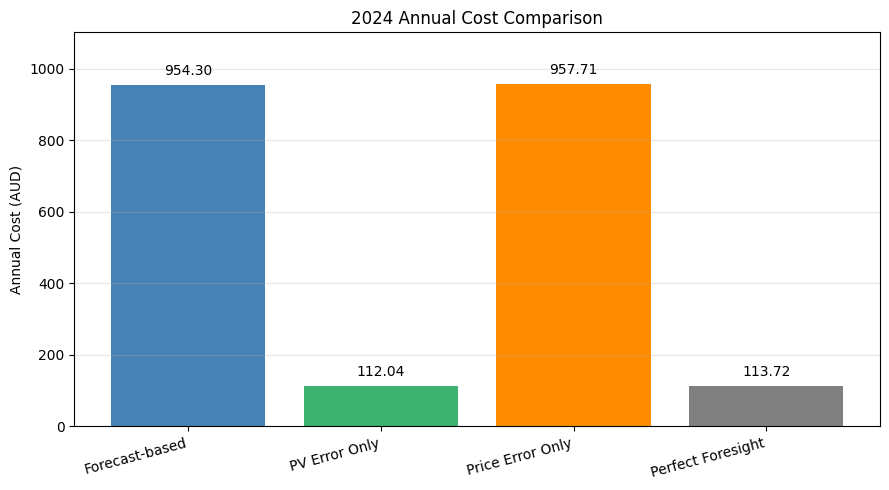

In [288]:
# Plot annual cost comparison
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    scenario_comparison_2024["Scenario"],
    scenario_comparison_2024["Total annual cost (AUD)"],
    color=["steelblue", "mediumseagreen", "darkorange", "grey"]
)

# Display cost values above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_ylabel("Annual Cost (AUD)")
ax.set_title("2024 Annual Cost Comparison")
ax.set_ylim(
    0,
    scenario_comparison_2024["Total annual cost (AUD)"].max() * 1.15
)

ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("2024 Annual Cost Comparison", dpi=300, bbox_inches="tight")
plt.show()

In [289]:
# Calculate interaction between PV and price forecast errors

cost_ff = annual_net_cost_2024
cost_fa = error_annual_costs_2024.loc[0, "Total annual cost (AUD)"]
cost_af = error_annual_costs_2024.loc[1, "Total annual cost (AUD)"]
cost_aa = pf_annual_net_cost_2024

# Calculate individual and combined forecast error effects
pv_error_effect = cost_fa - cost_aa
price_error_effect = cost_af - cost_aa
combined_error_effect = cost_ff - cost_aa

interaction_effect = (
    combined_error_effect
    - pv_error_effect
    - price_error_effect
)

print("2024 forecast error contribution analysis:")
print(f"PV error effect: AUD {pv_error_effect:.2f}")
print(f"Price error effect: AUD {price_error_effect:.2f}")
print(f"Combined error effect: AUD {combined_error_effect:.2f}")
print(f"Interaction effect: AUD {interaction_effect:.2f}")

2024 forecast error contribution analysis:
PV error effect: AUD -1.68
Price error effect: AUD 844.00
Combined error effect: AUD 840.59
Interaction effect: AUD -1.73


In [290]:
# Compare annual battery operation across four scenarios
dt = bess_parameters["time_step_hours"]

battery_operation_results = []

for scenario, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:

    charge_kWh = dispatch["actual_charge_kW"].sum() * dt
    discharge_kWh = dispatch["actual_discharge_kW"].sum() * dt

    efc = (
        discharge_kWh
        / bess_parameters["discharge_efficiency"]
        / bess_usable_energy
    )

    battery_operation_results.append({
        "Scenario": scenario,
        "Charge (kWh)": charge_kWh,
        "Discharge (kWh)": discharge_kWh,
        "EFC": efc
    })

battery_operation_2024 = pd.DataFrame(
    battery_operation_results
)

print("2024 battery operation comparison:")
display(battery_operation_2024.round(2))

2024 battery operation comparison:


,Scenario,Charge (kWh),Discharge (kWh),EFC
0,Forecast-based,3271.60,2948.82,388.00
1,PV Error Only,2950.58,2659.10,349.88
2,Price Error Only,3271.82,2949.02,388.03
3,Perfect Foresight,2952.16,2660.53,350.07


In [291]:
# Compare annual grid exchange and PV curtailment
dt = bess_parameters["time_step_hours"]

grid_operation_results = []

for scenario, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:

    grid_operation_results.append({
        "Scenario": scenario,
        "Grid import (kWh)": (
            dispatch["grid_import_kW"].sum() * dt
        ),
        "Grid export (kWh)": (
            dispatch["grid_export_kW"].sum() * dt
        ),
        "PV curtailment (kWh)": (
            dispatch["curtailment_kW"].sum() * dt
        )
    })

grid_operation_2024 = pd.DataFrame(grid_operation_results)

print("2024 grid operation comparison:")
display(grid_operation_2024.round(2))

2024 grid operation comparison:


,Scenario,Grid import (kWh),Grid export (kWh),PV curtailment (kWh)
0,Forecast-based,3459.16,6044.66,4573.02
1,PV Error Only,3470.66,4989.72,5670.76
2,Price Error Only,3484.33,6054.31,4588.52
3,Perfect Foresight,3489.41,4999.68,5679.40


In [292]:
# Compare realised export prices and revenues
dt = bess_parameters["time_step_hours"]

export_analysis_results = []

for scenario, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:

    # Match dispatch with actual wholesale prices
    export_data = dispatch[
        ["timestamp", "grid_export_kW"]
    ].merge(
        settlement_2024[
            ["timestamp", "actual_export_AUD/kWh"]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    export_kWh = export_data["grid_export_kW"].sum() * dt

    export_revenue = (
        export_data["grid_export_kW"]
        * export_data["actual_export_AUD/kWh"]
        * dt
    ).sum()

    export_analysis_results.append({
        "Scenario": scenario,
        "Grid export (kWh)": export_kWh,
        "Export revenue (AUD)": export_revenue,
        "Realised export price (AUD/kWh)": (
            export_revenue / export_kWh
            if export_kWh > 0 else 0
        )
    })

export_analysis_2024 = pd.DataFrame(export_analysis_results)

print("2024 actual export price and revenue comparison:")
display(export_analysis_2024.round(4))

2024 actual export price and revenue comparison:


,Scenario,Grid export (kWh),Export revenue (AUD),Realised export price (AUD/kWh)
0,Forecast-based,6044.6646,547.6533,0.0906
1,PV Error Only,4989.7249,1215.3989,0.2436
2,Price Error Only,6054.3072,548.1855,0.0905
3,Perfect Foresight,4999.6759,1216.0047,0.2432


In [293]:
# Analyse battery discharge during high-price periods
dt = bess_parameters["time_step_hours"]
high_price_threshold = 0.30  # AUD/kWh

high_price_results = []

for scenario, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:

    # Match actual wholesale prices with battery dispatch
    analysis_data = dispatch[
        ["timestamp", "actual_discharge_kW", "grid_export_kW"]
    ].merge(
        settlement_2024[
            ["timestamp", "actual_wholesale_AUD/kWh"]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    # Identify actual high-price intervals
    high_price_data = analysis_data.loc[
        analysis_data["actual_wholesale_AUD/kWh"]
        >= high_price_threshold
    ]

    high_price_results.append({
        "Scenario": scenario,
        "High-price intervals": len(high_price_data),
        "Battery discharge (kWh)": (
            high_price_data["actual_discharge_kW"].sum() * dt
        ),
        "Grid export (kWh)": (
            high_price_data["grid_export_kW"].sum() * dt
        )
    })

high_price_comparison_2024 = pd.DataFrame(high_price_results)

print("2024 high-price battery operation comparison:")
display(high_price_comparison_2024.round(2))

2024 high-price battery operation comparison:


,Scenario,High-price intervals,Battery discharge (kWh),Grid export (kWh)
0,Forecast-based,2926,220.39,162.54
1,Perfect Foresight,2926,347.19,321.54


In [294]:
# Calculate export revenue during high-price intervals
high_price_revenue_results = []

for scenario, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:

    # Match dispatch with actual wholesale prices
    analysis_data = dispatch[
        ["timestamp", "grid_export_kW"]
    ].merge(
        settlement_2024[
            ["timestamp", "actual_wholesale_AUD/kWh"]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one"
    )

    # Select actual high-price intervals
    high_price_data = analysis_data.loc[
        analysis_data["actual_wholesale_AUD/kWh"]
        >= high_price_threshold
    ]

    export_kWh = (
        high_price_data["grid_export_kW"].sum() * dt
    )

    export_revenue = (
        high_price_data["grid_export_kW"]
        * high_price_data["actual_wholesale_AUD/kWh"]
        * dt
    ).sum()

    high_price_revenue_results.append({
        "Scenario": scenario,
        "High-price export (kWh)": export_kWh,
        "High-price revenue (AUD)": export_revenue,
        "Average export price (AUD/kWh)": (
            export_revenue / export_kWh
            if export_kWh > 0 else 0
        )
    })

high_price_revenue_2024 = pd.DataFrame(
    high_price_revenue_results
)

print("2024 high-price export revenue comparison:")
display(high_price_revenue_2024.round(2))

2024 high-price export revenue comparison:


,Scenario,High-price export (kWh),High-price revenue (AUD),Average export price (AUD/kWh)
0,Forecast-based,162.54,269.60,1.66
1,Perfect Foresight,321.54,741.47,2.31


In [295]:
# Calculate high-price revenue contribution

revenue_contribution_2024 = high_price_revenue_2024[
    ["Scenario", "High-price revenue (AUD)"]
].merge(
    export_analysis_2024[
        ["Scenario", "Export revenue (AUD)"]
    ],
    on="Scenario"
)

# Calculate contribution percentage
revenue_contribution_2024["Contribution (%)"] = (
    revenue_contribution_2024["High-price revenue (AUD)"]
    / revenue_contribution_2024["Export revenue (AUD)"]
    * 100
)

print("2024 high-price revenue contribution:")
display(revenue_contribution_2024.round(2))

2024 high-price revenue contribution:


,Scenario,High-price revenue (AUD),Export revenue (AUD),Contribution (%)
0,Forecast-based,269.60,547.65,49.23
1,Perfect Foresight,741.47,1216.00,60.98


In [296]:
# Calculate monthly electricity costs for both scenarios

monthly_cost_results = []

for scenario, data in [
    ("Forecast-based", settlement_2024),
    ("Perfect Foresight", pf_settlement_2024)
]:

    monthly_data = data.copy()

    # Calculate five-minute net electricity cost
    monthly_data["monthly_net_cost_AUD"] = (
        monthly_data["grid_import_kW"]
        * monthly_data["actual_import_AUD/kWh"]
        - monthly_data["grid_export_kW"]
        * monthly_data["actual_export_AUD/kWh"]
    ) * dt

    # Group costs by month
    monthly_cost = (
        monthly_data
        .groupby(monthly_data["timestamp"].dt.month)[
            "monthly_net_cost_AUD"
        ]
        .sum()
    )

    for month, cost in monthly_cost.items():
        monthly_cost_results.append({
            "Month": month,
            "Scenario": scenario,
            "Net electricity cost (AUD)": cost
        })

monthly_electricity_costs_2024 = pd.DataFrame(
    monthly_cost_results
)

# Compare monthly costs
monthly_cost_comparison_2024 = (
    monthly_electricity_costs_2024
    .pivot(
        index="Month",
        columns="Scenario",
        values="Net electricity cost (AUD)"
    )
)

monthly_cost_comparison_2024["Cost gap (AUD)"] = (
    monthly_cost_comparison_2024["Forecast-based"]
    - monthly_cost_comparison_2024["Perfect Foresight"]
)

print("2024 monthly electricity cost comparison:")
display(monthly_cost_comparison_2024.round(2))

print("\nAnnual totals:")
display(monthly_cost_comparison_2024.sum().round(2))

2024 monthly electricity cost comparison:


Scenario,Forecast-based,Perfect Foresight,Cost gap (AUD)
Month,,,
1,4.99,-31.58,36.57
2,-42.76,-115.54,72.78
3,-10.86,-59.59,48.73
4,-27.77,-52.04,24.27
5,66.57,55.96,10.61
6,149.85,109.91,39.94
7,122.40,-67.71,190.11
8,148.82,12.04,136.78
9,-75.28,-127.26,51.97



Annual totals:


Scenario
Forecast-based       330.97
Perfect Foresight   -478.01
Cost gap (AUD)       808.98
dtype: float64

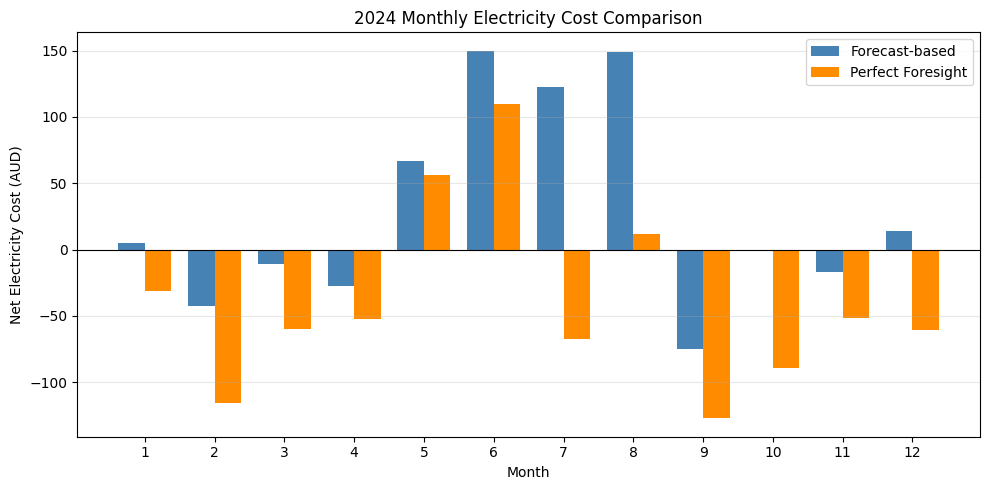

In [297]:
# Plot monthly electricity cost comparison
import matplotlib.pyplot as plt
import numpy as np

months = monthly_cost_comparison_2024.index.to_numpy()
x = np.arange(len(months))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    monthly_cost_comparison_2024["Forecast-based"],
    width,
    label="Forecast-based",
    color="steelblue"
)

ax.bar(
    x + width / 2,
    monthly_cost_comparison_2024["Perfect Foresight"],
    width,
    label="Perfect Foresight",
    color="darkorange"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_xlabel("Month")
ax.set_ylabel("Net Electricity Cost (AUD)")
ax.set_title("2024 Monthly Electricity Cost Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [298]:
# Identify the highest wholesale price event in July 2024

# Select July wholesale prices
july_prices = settlement_2024.loc[
    settlement_2024["timestamp"].dt.month == 7,
    ["timestamp", "actual_wholesale_AUD/kWh"]
].copy()

# Find the highest-price interval
peak_idx = july_prices["actual_wholesale_AUD/kWh"].idxmax()
peak_time = july_prices.loc[peak_idx, "timestamp"]
peak_price = july_prices.loc[peak_idx, "actual_wholesale_AUD/kWh"]

# Select 6 hours before and after the event
event_start = peak_time - pd.Timedelta(hours=6)
event_end = peak_time + pd.Timedelta(hours=6)

# Prepare dispatch comparison
event_comparison_2024 = (
    rolling_2024_dispatch[
        ["timestamp", "actual_discharge_kW", "actual_soc_kWh"]
    ]
    .rename(columns={
        "actual_discharge_kW": "forecast_discharge_kW",
        "actual_soc_kWh": "forecast_soc_kWh"
    })
    .merge(
        perfect_2024_dispatch[
            ["timestamp", "actual_discharge_kW", "actual_soc_kWh"]
        ].rename(columns={
            "actual_discharge_kW": "perfect_discharge_kW",
            "actual_soc_kWh": "perfect_soc_kWh"
        }),
        on="timestamp",
        validate="one_to_one"
    )
    .merge(
        july_prices,
        on="timestamp",
        how="inner",
        validate="one_to_one"
    )
)

event_comparison_2024 = event_comparison_2024.loc[
    event_comparison_2024["timestamp"].between(
        event_start, event_end
    )
].copy()

print("July 2024 highest wholesale price event:")
print("Peak time:", peak_time)
print(f"Peak price: AUD {peak_price:.4f}/kWh")
print("Event records:", len(event_comparison_2024))

display(event_comparison_2024.head())

July 2024 highest wholesale price event:
Peak time: 2024-07-19 21:55:00
Peak price: AUD 17.5000/kWh
Event records: 145


,timestamp,forecast_discharge_kW,forecast_soc_kWh,perfect_discharge_kW,perfect_soc_kWh,actual_wholesale_AUD/kWh
5375,2024-07-19 15:55:00,0.0,9.0,0.0,9.0,0.02065
5376,2024-07-19 16:00:00,0.0,9.0,0.0,9.0,-0.03599
5377,2024-07-19 16:05:00,0.0,9.0,0.0,9.0,-0.03599
5378,2024-07-19 16:10:00,0.0,9.0,0.0,9.0,-0.04665
5379,2024-07-19 16:15:00,0.0,9.0,0.0,9.0,0.00000


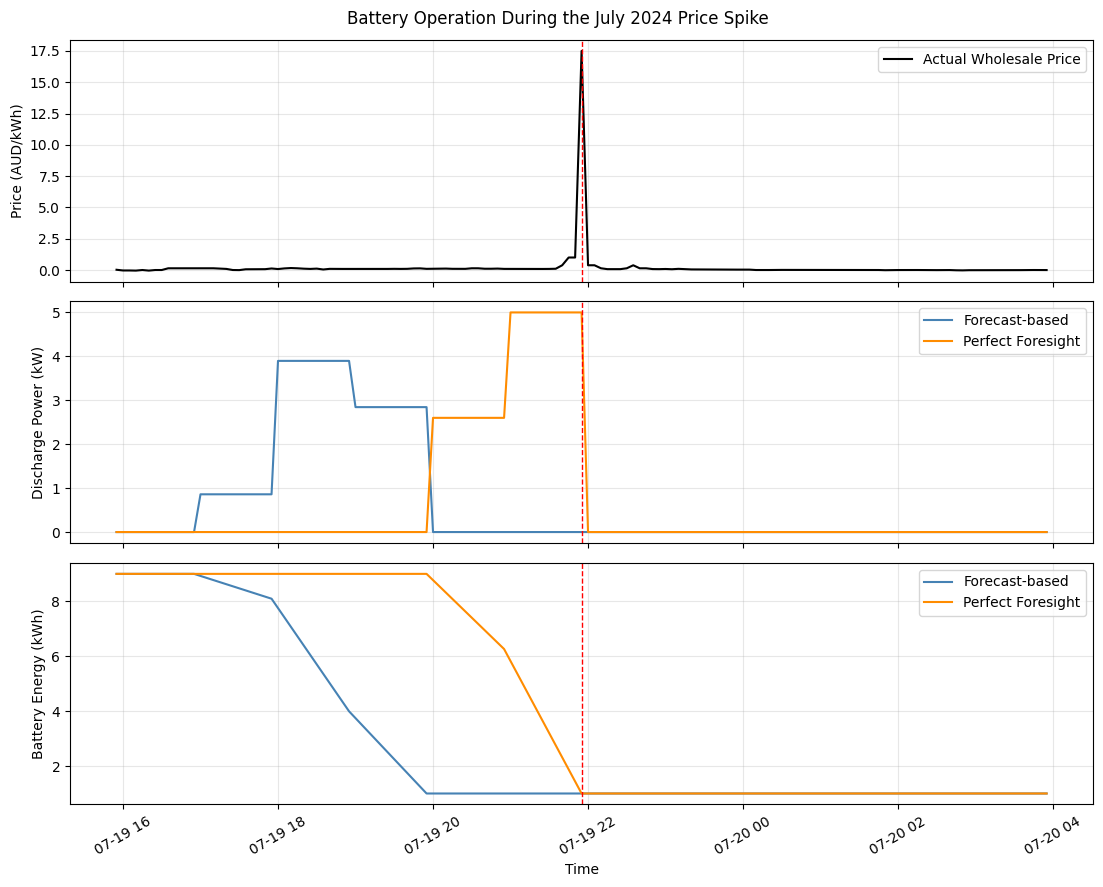

In [299]:
# Plot battery operation during the July 2024 price spike
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1, figsize=(11, 9), sharex=True
)

# Actual wholesale price
axes[0].plot(
    event_comparison_2024["timestamp"],
    event_comparison_2024["actual_wholesale_AUD/kWh"],
    color="black",
    label="Actual Wholesale Price"
)
axes[0].set_ylabel("Price (AUD/kWh)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Battery discharge comparison
axes[1].plot(
    event_comparison_2024["timestamp"],
    event_comparison_2024["forecast_discharge_kW"],
    label="Forecast-based",
    color="steelblue"
)
axes[1].plot(
    event_comparison_2024["timestamp"],
    event_comparison_2024["perfect_discharge_kW"],
    label="Perfect Foresight",
    color="darkorange"
)
axes[1].set_ylabel("Discharge Power (kW)")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Battery SOC comparison
axes[2].plot(
    event_comparison_2024["timestamp"],
    event_comparison_2024["forecast_soc_kWh"],
    label="Forecast-based",
    color="steelblue"
)
axes[2].plot(
    event_comparison_2024["timestamp"],
    event_comparison_2024["perfect_soc_kWh"],
    label="Perfect Foresight",
    color="darkorange"
)
axes[2].set_ylabel("Battery Energy (kWh)")
axes[2].set_xlabel("Time")
axes[2].legend()
axes[2].grid(alpha=0.3)

# Mark the highest-price interval
for ax in axes:
    ax.axvline(
        peak_time,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Price Peak"
    )

fig.suptitle(
    "Battery Operation During the July 2024 Price Spike"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [300]:
# Original timestamp and solar-time check

# Read original timestamp strings
raw_time = pd.read_csv(
    "Data_SA_Coober Pedy - Hot Dry Summer, Cool Winter_2023-2024_partial.csv",
    usecols=["timestamp"],
    nrows=5,
    dtype=str
)

print("Original timestamp examples:")
display(raw_time)

print("Parsed timestamp dtype:", df["timestamp"].dtype)
print("Parsed timezone:", df["timestamp"].dt.tz)

# Calculate hourly irradiance patterns for each year
solar_hourly = df.groupby([
    df["timestamp"].dt.year.rename("Year"),
    df["timestamp"].dt.hour.rename("Hour")
])["irradiance_W/m^2"].mean().unstack(0)

print("\nMean hourly irradiance (W/m2):")
display(solar_hourly.round(2))

print("\nPeak irradiance hour:")
display(solar_hourly.idxmax())


Original timestamp examples:


,timestamp
0,2023-01-01 00:00:00
1,2023-01-01 00:05:00
2,2023-01-01 00:10:00
3,2023-01-01 00:15:00
4,2023-01-01 00:20:00


Parsed timestamp dtype: datetime64[ns]
Parsed timezone: None

Mean hourly irradiance (W/m2):


Year,2023,2024
Hour,,
0,0.00,0.00
1,0.00,0.00
2,0.00,0.00
3,0.00,0.00
4,0.00,0.00
5,6.12,5.91
6,49.93,47.80
7,169.38,163.32
8,348.80,338.52



Peak irradiance hour:


Year
2023    12
2024    12
dtype: int32

In [301]:
# AEMO timestamp inspection

raw_aemo = pd.read_csv(
    "SA1_Wholesale_Prices_2024.csv",
    nrows=5,
    dtype=str
)

print("Original AEMO records:")
display(raw_aemo)

aemo_time = aemo_prices_2024["timestamp"].sort_values()

print("\nTimestamp dtype:", aemo_time.dtype)
print("Timezone:", aemo_time.dt.tz)
print("First timestamp:", aemo_time.min())
print("Last timestamp:", aemo_time.max())
print("Duplicate timestamps:", aemo_time.duplicated().sum())

# Check dates near South Australian daylight saving transitions
for date in ["2024-04-07", "2024-10-06"]:
    day = aemo_time[aemo_time.dt.strftime("%Y-%m-%d") == date]
    print(f"\n{date}: {len(day)} records")
    print("First:", day.min())
    print("Last:", day.max())
    print("Non-5-minute gaps:", (day.diff().dropna() != pd.Timedelta(minutes=5)).sum())


Original AEMO records:


,timestamp,spot_price_AUD/kWh
0,2024-01-01 00:00:00,0.05442061
1,2024-01-01 00:05:00,0.06820377000000001
2,2024-01-01 00:10:00,0.056168579999999996
3,2024-01-01 00:15:00,0.05228684
4,2024-01-01 00:20:00,0.05193813



Timestamp dtype: datetime64[ns]
Timezone: None
First timestamp: 2024-01-01 00:00:00
Last timestamp: 2024-12-31 23:55:00
Duplicate timestamps: 0

2024-04-07: 288 records
First: 2024-04-07 00:00:00
Last: 2024-04-07 23:55:00
Non-5-minute gaps: 0

2024-10-06: 288 records
First: 2024-10-06 00:00:00
Last: 2024-10-06 23:55:00
Non-5-minute gaps: 0


In [302]:
# Solar noon and time basis check

solar = df.loc[
    df["timestamp"].dt.year == 2024,
    ["timestamp", "irradiance_W/m^2"]
].copy()

solar["Date"] = solar["timestamp"].dt.date
solar["Month"] = solar["timestamp"].dt.month

# Identify daylight intervals
daylight = solar.loc[solar["irradiance_W/m^2"] > 20]

daily = daylight.groupby("Date").agg(
    sunrise=("timestamp", "min"),
    sunset=("timestamp", "max"),
    Month=("Month", "first")
)

# Estimate solar noon from the daylight midpoint
daily["solar_noon"] = daily["sunrise"] + (
    daily["sunset"] - daily["sunrise"]
) / 2

daily["noon_hour"] = (
    daily["solar_noon"].dt.hour
    + daily["solar_noon"].dt.minute / 60
)

monthly_noon = daily.groupby("Month")["noon_hour"].median()

print("Monthly median solar noon (timestamp clock hours):")
display(monthly_noon.round(2).to_frame("Solar noon hour"))

print("\nAnnual median solar noon:", round(daily["noon_hour"].median(), 2))
print("Days analysed:", len(daily))


Monthly median solar noon (timestamp clock hours):


,Solar noon hour
Month,
1,12.70
2,12.75
3,12.58
4,12.50
5,12.45
6,12.53
7,12.53
8,12.53
9,12.45



Annual median solar noon: 12.53
Days analysed: 366


In [303]:
# Solar noon timezone comparison

dates = pd.to_datetime(daily.index)
day_number = dates.dayofyear.to_numpy()

# Equation of Time (minutes)
B = np.deg2rad(360 * (day_number - 81) / 364)
eot = 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B)

longitude = 134.75
observed = daily["noon_hour"].to_numpy()

# Expected solar noon for fixed timezones
acst = 12 + 9.5 - longitude / 15 - eot / 60
aest = 12 + 10.0 - longitude / 15 - eot / 60

# South Australian daylight saving in 2024
dst = (dates < pd.Timestamp("2024-04-07")) | (
    dates >= pd.Timestamp("2024-10-06")
)
local_time = acst + dst.astype(float)

comparison = pd.DataFrame({
    "Time basis": ["Fixed ACST", "Fixed AEST", "SA local time with DST"],
    "Median absolute error (min)": [
        np.median(np.abs(observed - acst)) * 60,
        np.median(np.abs(observed - aest)) * 60,
        np.median(np.abs(observed - local_time)) * 60
    ]
})

display(comparison.round(2))


,Time basis,Median absolute error (min)
0,Fixed ACST,3.74
1,Fixed AEST,30.49
2,SA local time with DST,43.96


In [304]:
# Actual PV dispatch dependency check

dispatch_audit = rolling_2024_dispatch.merge(
    rolling_input_2024[
        ["timestamp", "forecast_export_AUD/kWh"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

negative_price = dispatch_audit["forecast_export_AUD/kWh"] < 0

planned_discharge = dispatch_audit["planned_discharge_kW"] > 1e-6

actual_pv_limit = (
    dispatch_audit["load_kW"]
    + dispatch_audit["actual_charge_kW"]
    - dispatch_audit["commercial_pv_kW"]
).clip(lower=0)

pv_limit_binding = (
    negative_price
    & planned_discharge
    & (actual_pv_limit < dispatch_audit["planned_discharge_kW"] - 1e-6)
)

print("Total dispatch intervals:", len(dispatch_audit))
print("Negative forecast price intervals:", negative_price.sum())
print("Planned discharge during negative prices:",
      (negative_price & planned_discharge).sum())
print("Potential actual-PV discharge restrictions:",
      pv_limit_binding.sum())

print("\nActual discharge energy in affected intervals (kWh):")
print(round(
    dispatch_audit.loc[
        pv_limit_binding, "actual_discharge_kW"
    ].sum() * bess_parameters["time_step_hours"], 3
))


Total dispatch intervals: 105408
Negative forecast price intervals: 19080
Planned discharge during negative prices: 0
Potential actual-PV discharge restrictions: 0

Actual discharge energy in affected intervals (kWh):
0.0


In [305]:
# BESS capacity screening - one full charge per day

capacity_options = [5, 10, 15]

soc_range = (
    bess_parameters["soc_max"]
    - bess_parameters["soc_min"]
)

eta_c = bess_parameters["charge_efficiency"]

capacity_results = []

for capacity in capacity_options:
    usable_energy = capacity * soc_range

    # Assume at most one full usable-capacity charge per day
    daily_storage_limit = usable_energy / eta_c

    daily_charge_estimate = np.minimum(
        daily_pv_surplus_energy,
        daily_storage_limit
    )

    annual_charge_estimate = daily_charge_estimate.sum()

    capacity_results.append({
        "BESS capacity (kWh)": capacity,
        "Usable capacity (kWh)": usable_energy,
        "Annual charging estimate (kWh)": annual_charge_estimate,
        "PV surplus captured estimate (%)": (
            annual_charge_estimate / annual_pv_surplus * 100
        )
    })

capacity_pv_comparison = pd.DataFrame(capacity_results)

print("2023 PV charging capacity screening:")
print("Assumption: maximum one full usable-capacity charge per day.")
print("This is a screening estimate, not a physical upper bound.")

display(capacity_pv_comparison.round(2))


2023 PV charging capacity screening:
Assumption: maximum one full usable-capacity charge per day.
This is a screening estimate, not a physical upper bound.


,BESS capacity (kWh),Usable capacity (kWh),Annual charging estimate (kWh),PV surplus captured estimate (%)
0,5,4.0,1518.08,12.86
1,10,8.0,3005.62,25.46
2,15,12.0,4453.80,37.73


In [306]:
# Nighttime load coverage by battery capacity

night_data = df_clean.loc[
    (df_clean["timestamp"] >= "2023-01-01 18:00")
    & (df_clean["timestamp"] < "2024-01-01 06:00")
    & ((df_clean["timestamp"].dt.hour >= 18)
       | (df_clean["timestamp"].dt.hour < 6)),
    ["timestamp", "load_kWh"]
].copy()

night_data["Night"] = night_data["timestamp"].dt.normalize()
night_data.loc[
    night_data["timestamp"].dt.hour < 6, "Night"
] -= pd.Timedelta(days=1)

# Keep complete 12-hour nights
nightly_load = night_data.groupby("Night").agg(
    load_kWh=("load_kWh", "sum"),
    intervals=("load_kWh", "count")
)

nightly_load = nightly_load[nightly_load["intervals"] == 144]

results = []

for capacity in [5, 10, 15]:
    delivered_energy = (
        capacity
        * (bess_parameters["soc_max"] - bess_parameters["soc_min"])
        * bess_parameters["discharge_efficiency"]
    )

    results.append({
        "BESS capacity (kWh)": capacity,
        "Maximum delivered energy (kWh)": delivered_energy,
        "Nights fully covered (%)": (
            (nightly_load["load_kWh"] <= delivered_energy).mean() * 100
        )
    })

print("Complete nights analysed:", len(nightly_load))
print("Average nighttime load (kWh):", round(nightly_load["load_kWh"].mean(), 2))
display(pd.DataFrame(results).round(2))


Complete nights analysed: 365
Average nighttime load (kWh): 10.4


,BESS capacity (kWh),Maximum delivered energy (kWh),Nights fully covered (%)
0,5,3.8,0.00
1,10,7.6,57.26
2,15,11.4,66.30


In [307]:
# BESS power rating assessment

dt = bess_parameters["time_step_hours"]

# Reuse existing PV charging potential
charge_5kw = pv_charging_potential.loc[5]
charge_10kw = pv_charging_potential.loc[10]

# Household demand remaining after direct PV use
load_deficit_kW = (
    pv_self_consumption_data["grid_import_kWh"] / dt
)

# Compare maximum discharge power limits
power_results = pd.DataFrame({
    "Metric": [
        "PV surplus captured at 5 kW (kWh)",
        "PV surplus captured at 10 kW (kWh)",
        "Additional PV charging potential above 5 kW (kWh)",
        "PV charging potential retained at 5 kW (%)",
        "Load deficit intervals above 5 kW (%)",
        "Load deficit energy coverable at 5 kW (%)"
    ],
    "Value": [
        charge_5kw,
        charge_10kw,
        charge_10kw - charge_5kw,
        charge_5kw / charge_10kw * 100,
        (load_deficit_kW > 5).mean() * 100,
        load_deficit_kW.clip(upper=5).sum()
        / load_deficit_kW.sum() * 100
    ]
})

print("2023 BESS power rating assessment:")
display(power_results.round(2))


2023 BESS power rating assessment:


,Metric,Value
0,PV surplus captured at 5 kW (kWh),10884.80
1,PV surplus captured at 10 kW (kWh),11804.09
2,Additional PV charging potential above 5 kW (kWh),919.29
3,PV charging potential retained at 5 kW (%),92.21
4,Load deficit intervals above 5 kW (%),0.32
5,Load deficit energy coverable at 5 kW (%),99.75


In [308]:
# BESS capacity sensitivity simulation

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

# Use cleaned 2023 data
source = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["solar_filled_kW", "load_kW", "temperature_C"]
].copy()

assert source.notna().all().all(), "Missing input values detected"

capacity_records = []

for capacity in [5, 10, 15]:
    energy = capacity * bess_parameters["soc_initial"]
    minimum = capacity * bess_parameters["soc_min"]
    maximum = capacity * bess_parameters["soc_max"]

    total_charge = 0.0
    total_discharge = 0.0
    total_import = 0.0

    for pv, load, temp in source.itertuples(index=False, name=None):
        power_limit = 5.0 * bess_temperature_factor(temp)

        charge = min(
            max(pv - load, 0),
            power_limit,
            max((maximum - energy) / (eta_c * dt), 0)
        )

        discharge = min(
            max(load - pv, 0),
            power_limit,
            max((energy - minimum) * eta_d / dt, 0)
        )

        energy += (charge * eta_c - discharge / eta_d) * dt

        total_charge += charge * dt
        total_discharge += discharge * dt
        total_import += max(load + charge - pv - discharge, 0) * dt

    capacity_records.append({
        "Capacity (kWh)": capacity,
        "PV charging (kWh)": total_charge,
        "Battery discharge (kWh)": total_discharge,
        "Grid import (kWh)": total_import,
        "Import reduction (kWh)": annual_grid_import - total_import
    })

capacity_dispatch_comparison = pd.DataFrame(capacity_records)

print("2023 BESS capacity sensitivity - Simple self-consumption:")
display(capacity_dispatch_comparison.round(2))


2023 BESS capacity sensitivity - Simple self-consumption:


,Capacity (kWh),PV charging (kWh),Battery discharge (kWh),Grid import (kWh),Import reduction (kWh)
0,5,1560.34,1410.10,3164.28,1410.10
1,10,2454.90,2216.15,2358.24,2216.15
2,15,3008.78,2714.13,1860.26,2714.13


In [309]:
# BESS capacity economic comparison

economic_source = df_clean.loc[
    df_clean["timestamp"].dt.year == 2023,
    ["timestamp", "solar_filled_kW", "load_kW", "temperature_C"]
].merge(
    tariff_data[[
        "timestamp", "tou_import_AUD/kWh", "tou_export_AUD/kWh"
    ]],
    on="timestamp",
    validate="one_to_one"
)

assert economic_source.notna().all().all()

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

pv = economic_source["solar_filled_kW"].to_numpy()
load = economic_source["load_kW"].to_numpy()
temp = economic_source["temperature_C"].to_numpy()
buy = economic_source["tou_import_AUD/kWh"].to_numpy()
sell = economic_source["tou_export_AUD/kWh"].to_numpy()

baseline_bill = np.sum(
    np.maximum(load - pv, 0) * buy * dt
    - np.maximum(pv - load, 0) * sell * dt
)

economic_results = []

for capacity in [5, 10, 15]:
    energy = capacity * bess_parameters["soc_initial"]
    minimum = capacity * bess_parameters["soc_min"]
    maximum = capacity * bess_parameters["soc_max"]

    bill = 0.0
    discharged = 0.0

    for p, l, t, import_rate, export_rate in zip(
        pv, load, temp, buy, sell
    ):
        power_limit = 5.0 * bess_temperature_factor(t)

        charge = min(
            max(p - l, 0),
            power_limit,
            max((maximum - energy) / (eta_c * dt), 0)
        )

        discharge = min(
            max(l - p, 0),
            power_limit,
            max((energy - minimum) * eta_d / dt, 0)
        )

        energy += (charge * eta_c - discharge / eta_d) * dt
        grid = l + charge - p - discharge

        bill += (
            max(grid, 0) * import_rate
            - max(-grid, 0) * export_rate
        ) * dt

        discharged += discharge * dt

    degradation = discharged * degradation_cost_per_AC_kWh

    economic_results.append({
        "Capacity (kWh)": capacity,
        "Energy bill (AUD)": bill,
        "Degradation (AUD)": degradation,
        "Gross savings (AUD)": baseline_bill - bill,
        "Net savings (AUD)": baseline_bill - bill - degradation
    })

capacity_economic_comparison = pd.DataFrame(economic_results)

print("PV-only TOU bill (AUD):", round(baseline_bill, 2))
display(capacity_economic_comparison.round(2))


PV-only TOU bill (AUD): 506.57


,Capacity (kWh),Energy bill (AUD),Degradation (AUD),Gross savings (AUD),Net savings (AUD)
0,5,190.15,154.62,316.43,161.81
1,10,35.96,243.00,470.62,227.62
2,15,-53.75,297.60,560.33,262.73


In [310]:
# BESS Capacity Economic Assessment

import numpy as np
import pandas as pd

# Use existing capacity comparison results
capacity_assessment = capacity_economic_comparison.copy()

# Reference BESS cost assumptions from Group 150
reference_capacity = bess_parameters["capacity_kWh"]
reference_cost = bess_degradation_parameters["replacement_cost_AUD"]

# Estimate capacity-dependent battery costs
cost_per_kWh = reference_cost / reference_capacity

capacity_assessment["Estimated battery cost (AUD)"] = (
    capacity_assessment["Capacity (kWh)"] * cost_per_kWh
)

# Calculate marginal economic benefits
capacity_assessment = (
    capacity_assessment
    .sort_values("Capacity (kWh)")
    .reset_index(drop=True)
)

capacity_assessment["Additional capacity (kWh)"] = (
    capacity_assessment["Capacity (kWh)"].diff()
)

capacity_assessment["Additional annual savings (AUD)"] = (
    capacity_assessment["Net savings (AUD)"].diff()
)

capacity_assessment["Additional investment (AUD)"] = (
    capacity_assessment["Estimated battery cost (AUD)"].diff()
)

# Marginal simple payback period
capacity_assessment["Marginal payback (years)"] = (
    capacity_assessment["Additional investment (AUD)"]
    / capacity_assessment["Additional annual savings (AUD)"]
)

# Annual net savings per unit of battery capacity
capacity_assessment["Savings per kWh (AUD/year/kWh)"] = (
    capacity_assessment["Net savings (AUD)"]
    / capacity_assessment["Capacity (kWh)"]
)

# Display results
print("BESS Capacity Economic Assessment:")
display(capacity_assessment.round(2))

# Identify capacity with highest annual savings
best_savings = capacity_assessment.loc[
    capacity_assessment["Net savings (AUD)"].idxmax()
]

# Identify capacity with highest annual savings per kWh
best_efficiency = capacity_assessment.loc[
    capacity_assessment["Savings per kWh (AUD/year/kWh)"].idxmax()
]

print(
    "Highest annual net savings:",
    best_savings["Capacity (kWh)"], "kWh"
)

print(
    "Highest annual net savings per kWh:",
    best_efficiency["Capacity (kWh)"], "kWh"
)

BESS Capacity Economic Assessment:


,Capacity (kWh),Energy bill (AUD),Degradation (AUD),Gross savings (AUD),Net savings (AUD),Estimated battery cost (AUD),Additional capacity (kWh),Additional annual savings (AUD),Additional investment (AUD),Marginal payback (years),Savings per kWh (AUD/year/kWh)
0,5,190.15,154.62,316.43,161.81,2500.0,NaN,NaN,NaN,NaN,32.36
1,10,35.96,243.00,470.62,227.62,5000.0,5.0,65.81,2500.0,37.99,22.76
2,15,-53.75,297.60,560.33,262.73,7500.0,5.0,35.11,2500.0,71.21,17.52


Highest annual net savings: 15.0 kWh
Highest annual net savings per kWh: 5.0 kWh


In [311]:
# 2024 PV-only self-consumption rate

dt = bess_parameters["time_step_hours"]

pv_only_2024 = settlement_2024[
    ["timestamp", "commercial_pv_kW", "load_kW"]
].copy()

# Calculate direct PV consumption
pv_only_2024["pv_generation_kWh"] = (
    pv_only_2024["commercial_pv_kW"] * dt
)

pv_only_2024["direct_pv_use_kWh"] = (
    pv_only_2024[["commercial_pv_kW", "load_kW"]]
    .min(axis=1) * dt
)

pv_generation_2024 = pv_only_2024["pv_generation_kWh"].sum()
direct_pv_use_2024 = pv_only_2024["direct_pv_use_kWh"].sum()

pv_only_scr_2024 = (
    direct_pv_use_2024 / pv_generation_2024 * 100
)

print("2024 PV-only self-consumption:")
print("Total PV generation (kWh):", round(pv_generation_2024, 2))
print("Direct PV consumption (kWh):", round(direct_pv_use_2024, 2))
print("PV-only self-consumption rate (%):", round(pv_only_scr_2024, 2))


2024 PV-only self-consumption:
Total PV generation (kWh): 17088.41
Direct PV consumption (kWh): 5070.46
PV-only self-consumption rate (%): 29.67


In [312]:
# Battery charging source assessment

dt = bess_parameters["time_step_hours"]

charging_results = []

for name, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:
    pv_surplus = (
        dispatch["commercial_pv_kW"] - dispatch["load_kW"]
    ).clip(lower=0)

    battery_charge = dispatch["actual_charge_kW"].clip(lower=0)

    # Preliminary PV-first charging allocation
    pv_charge = np.minimum(pv_surplus, battery_charge)
    grid_charge = (battery_charge - pv_charge).clip(lower=0)

    charging_results.append({
        "Scenario": name,
        "Total charge (kWh)": battery_charge.sum() * dt,
        "PV charge estimate (kWh)": pv_charge.sum() * dt,
        "Grid charge estimate (kWh)": grid_charge.sum() * dt,
        "Grid charge share (%)": (
            grid_charge.sum() / battery_charge.sum() * 100
            if battery_charge.sum() > 0 else 0
        )
    })

charging_source_comparison = pd.DataFrame(charging_results)

print("2024 preliminary BESS charging source assessment:")
display(charging_source_comparison.round(2))


2024 preliminary BESS charging source assessment:


,Scenario,Total charge (kWh),PV charge estimate (kWh),Grid charge estimate (kWh),Grid charge share (%)
0,Forecast-based,3271.60,2768.67,502.93,15.37
1,PV Error Only,2950.58,2483.64,466.94,15.83
2,Price Error Only,3271.82,2743.70,528.12,16.14
3,Perfect Foresight,2952.16,2465.40,486.76,16.49


In [313]:
# Forecast-based battery energy origin tracking

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

dispatch = rolling_2024_dispatch

pv_stored = 0.0
other_stored = bess_initial_energy - bess_min_energy

pv_battery_to_home = 0.0
pv_direct_to_home = 0.0

for row in dispatch.itertuples(index=False):
    pv = max(row.commercial_pv_kW - row.curtailment_kW, 0)
    load = row.load_kW
    charge = row.actual_charge_kW
    discharge = row.actual_discharge_kW

    direct_pv = min(pv, load)
    pv_charge = min(charge, max(pv - direct_pv, 0))
    grid_charge = charge - pv_charge

    pv_direct_to_home += direct_pv * dt

    pv_stored += pv_charge * eta_c * dt
    other_stored += grid_charge * eta_c * dt

    stored_total = pv_stored + other_stored

    if discharge > 0 and stored_total > 0:
        pv_fraction = pv_stored / stored_total
        removed = discharge * dt / eta_d

        pv_stored -= removed * pv_fraction
        other_stored -= removed * (1 - pv_fraction)

        home_discharge = min(
            discharge, max(load - direct_pv, 0)
        )

        pv_battery_to_home += (
            home_discharge * dt * pv_fraction
        )

    pv_stored = max(pv_stored, 0)
    other_stored = max(other_stored, 0)

pv_scr_forecast_2024 = (
    (pv_direct_to_home + pv_battery_to_home)
    / pv_generation_2024 * 100
)

print("Forecast-based PV energy tracking:")
print("Direct PV to home (kWh):", round(pv_direct_to_home, 2))
print("PV battery discharge to home (kWh):",
      round(pv_battery_to_home, 2))
print("PV self-consumption rate (%):",
      round(pv_scr_forecast_2024, 2))
print("Remaining PV energy in battery (kWh):",
      round(pv_stored, 2))


Forecast-based PV energy tracking:
Direct PV to home (kWh): 5070.46
PV battery discharge to home (kWh): 1316.63
PV self-consumption rate (%): 37.38
Remaining PV energy in battery (kWh): 7.5


In [314]:
# PV self-consumption comparison

def calculate_pv_self_consumption(dispatch):
    dt = bess_parameters["time_step_hours"]
    eta_c = bess_parameters["charge_efficiency"]
    eta_d = bess_parameters["discharge_efficiency"]

    pv_stored = 0.0
    other_stored = bess_initial_energy - bess_min_energy
    direct_total = 0.0
    battery_home_total = 0.0
    max_soc_error = 0.0

    for row in dispatch.itertuples(index=False):
        pv = max(row.commercial_pv_kW - row.curtailment_kW, 0)
        direct = min(pv, row.load_kW)
        pv_charge = min(row.actual_charge_kW, max(pv - direct, 0))

        direct_total += direct * dt

        pv_stored += pv_charge * eta_c * dt
        other_stored += (row.actual_charge_kW - pv_charge) * eta_c * dt

        total = pv_stored + other_stored

        if row.actual_discharge_kW > 0 and total > 0:
            fraction = pv_stored / total
            removed = row.actual_discharge_kW * dt / eta_d

            pv_stored -= removed * fraction
            other_stored -= removed * (1 - fraction)

            home_power = min(
                row.actual_discharge_kW,
                max(row.load_kW - direct, 0)
            )
            battery_home_total += home_power * dt * fraction

        soc_error = abs(
            pv_stored + other_stored
            - (row.actual_soc_kWh - bess_min_energy)
        )
        max_soc_error = max(max_soc_error, soc_error)

    return {
        "Direct PV use (kWh)": direct_total,
        "PV battery to home (kWh)": battery_home_total,
        "PV self-consumption (%)": (
            (direct_total + battery_home_total)
            / pv_generation_2024 * 100
        ),
        "Maximum energy tracking error (kWh)": max_soc_error
    }

results = []

for name, dispatch in [
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:
    results.append({
        "Scenario": name,
        **calculate_pv_self_consumption(dispatch)
    })

pv_scr_comparison_2024 = pd.DataFrame(results)

print("2024 PV self-consumption comparison:")
display(pv_scr_comparison_2024.round(3))


2024 PV self-consumption comparison:


,Scenario,Direct PV use (kWh),PV battery to home (kWh),PV self-consumption (%),Maximum energy tracking error (kWh)
0,Forecast-based,5070.461,1316.630,37.377,0.0
1,PV Error Only,5070.461,1263.597,37.066,0.0
2,Price Error Only,5070.461,1304.817,37.308,0.0
3,Perfect Foresight,5070.461,1254.905,37.016,0.0


In [315]:
# 2024 Simple self-consumption dispatch

simple_2024 = rolling_input_2024[
    [
        "timestamp",
        "commercial_pv_kW",
        "load_forecast_kW",
        "forecast_export_AUD/kWh"
    ]
].merge(
    data_2024[["timestamp", "temperature_C"]],
    on="timestamp",
    validate="one_to_one"
).rename(columns={"load_forecast_kW": "load_kW"})

dt = bess_parameters["time_step_hours"]

energy = bess_initial_energy
records = []

for pv, load, temp, forecast_price in simple_2024[
    [
        "commercial_pv_kW",
        "load_kW",
        "temperature_C",
        "forecast_export_AUD/kWh"
    ]
].itertuples(index=False, name=None):

    # Simple strategy: charge from PV surplus only
    planned_charge = max(pv - load, 0.0)

    # Discharge to meet household demand only
    planned_discharge = max(load - pv, 0.0)

    # Apply the existing physical dispatch constraints
    result = dispatch_bess_5min(
        planned_charge=planned_charge,
        planned_discharge=planned_discharge,
        current_energy=energy,
        temperature=temp,
        actual_pv=pv,
        actual_load=load,
        forecast_export_price=forecast_price
    )

    energy = result["actual_soc_kWh"]
    records.append(result)

# Store dispatch results
simple_dispatch_results = pd.DataFrame(records)

simple_2024 = pd.concat(
    [
        simple_2024.reset_index(drop=True),
        simple_dispatch_results
    ],
    axis=1
)

# Validate operation
assert len(simple_2024) == 105408

assert simple_2024[
    [
        "actual_charge_kW",
        "actual_discharge_kW",
        "actual_soc_kWh",
        "grid_import_kW",
        "grid_export_kW",
        "curtailment_kW"
    ]
].notna().all().all()

print("2024 Simple self-consumption dispatch completed.")
print("Records:", len(simple_2024))

print(
    "Battery charge (kWh):",
    round(simple_2024["actual_charge_kW"].sum() * dt, 2)
)

print(
    "Battery discharge (kWh):",
    round(simple_2024["actual_discharge_kW"].sum() * dt, 2)
)

print(
    "Final battery energy (kWh):",
    round(energy, 3)
)


2024 Simple self-consumption dispatch completed.
Records: 105408
Battery charge (kWh): 2448.0
Battery discharge (kWh): 2209.9
Final battery energy (kWh): 4.391


In [316]:
# Complete 2024 PV self-consumption comparison

simple_scr = calculate_pv_self_consumption(simple_2024)

pv_scr_final_2024 = pd.concat([
    pd.DataFrame([{
        "Scenario": "PV-only",
        "Direct PV use (kWh)": direct_pv_use_2024,
        "PV battery to home (kWh)": 0.0,
        "PV self-consumption (%)": pv_only_scr_2024,
        "Maximum energy tracking error (kWh)": 0.0
    }]),
    pd.DataFrame([{
        "Scenario": "Simple Self-consumption",
        **simple_scr
    }]),
    pv_scr_comparison_2024
], ignore_index=True)

print("2024 PV self-consumption comparison:")
display(pv_scr_final_2024.round(3))

print("\nSimple energy tracking error (kWh):",
      round(simple_scr["Maximum energy tracking error (kWh)"], 6))


2024 PV self-consumption comparison:


,Scenario,Direct PV use (kWh),PV battery to home (kWh),PV self-consumption (%),Maximum energy tracking error (kWh)
0,PV-only,5070.461,0.000,29.672,0.0
1,Simple Self-consumption,5070.461,2206.101,42.582,0.0
2,Forecast-based,5070.461,1316.630,37.377,0.0
3,PV Error Only,5070.461,1263.597,37.066,0.0
4,Price Error Only,5070.461,1304.817,37.308,0.0
5,Perfect Foresight,5070.461,1254.905,37.016,0.0



Simple energy tracking error (kWh): 0.0


In [317]:
# Simple self-consumption annual electricity cost

dt = bess_parameters["time_step_hours"]

simple_settlement_2024 = simple_2024.merge(
    settlement_2024[
        [
            "timestamp",
            "actual_import_AUD/kWh",
            "actual_export_AUD/kWh"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

assert len(simple_settlement_2024) == 105408
assert simple_settlement_2024[
    ["actual_import_AUD/kWh", "actual_export_AUD/kWh"]
].notna().all().all()

# Calculate electricity costs
simple_import_kWh_2024 = (
    simple_settlement_2024["grid_import_kW"].sum() * dt
)

simple_export_kWh_2024 = (
    simple_settlement_2024["grid_export_kW"].sum() * dt
)

simple_import_cost_2024 = (
    simple_settlement_2024["grid_import_kW"]
    * simple_settlement_2024["actual_import_AUD/kWh"]
    * dt
).sum()

simple_export_revenue_2024 = (
    simple_settlement_2024["grid_export_kW"]
    * simple_settlement_2024["actual_export_AUD/kWh"]
    * dt
).sum()

simple_electricity_cost_2024 = (
    simple_import_cost_2024 - simple_export_revenue_2024
)

simple_electricity_summary_2024 = pd.DataFrame({
    "Metric": [
        "Grid import (kWh)",
        "Grid export (kWh)",
        "Import cost (AUD)",
        "Export revenue (AUD)",
        "Net electricity cost (AUD)"
    ],
    "Value": [
        simple_import_kWh_2024,
        simple_export_kWh_2024,
        simple_import_cost_2024,
        simple_export_revenue_2024,
        simple_electricity_cost_2024
    ]
})

print("2024 Simple self-consumption electricity settlement:")
display(simple_electricity_summary_2024.round(2))


2024 Simple self-consumption electricity settlement:


,Metric,Value
0,Grid import (kWh),2326.74
1,Grid export (kWh),3768.38
2,Import cost (AUD),670.95
3,Export revenue (AUD),150.76
4,Net electricity cost (AUD),520.19


In [318]:
# Simple annual cost including battery degradation

dt = bess_parameters["time_step_hours"]

simple_discharge_kWh_2024 = (
    simple_settlement_2024["actual_discharge_kW"].sum() * dt
)

# Reuse the existing degradation model
simple_efc_2024, simple_degradation_cost_2024 = (
    calculate_bess_degradation(simple_discharge_kWh_2024)
)

# Simple operation does not pay the VPP service fee
simple_vpp_fee_2024 = 0.0

simple_annual_total_cost_2024 = (
    simple_electricity_cost_2024
    + simple_degradation_cost_2024
)

simple_annual_summary_2024 = pd.DataFrame({
    "Metric": [
        "Battery discharge (kWh)",
        "Equivalent full cycles",
        "Electricity cost (AUD)",
        "Battery degradation cost (AUD)",
        "VPP service fee (AUD)",
        "Total annual cost (AUD)"
    ],
    "Value": [
        simple_discharge_kWh_2024,
        simple_efc_2024,
        simple_electricity_cost_2024,
        simple_degradation_cost_2024,
        simple_vpp_fee_2024,
        simple_annual_total_cost_2024
    ]
})

print("2024 Simple self-consumption annual cost:")
display(simple_annual_summary_2024.round(2))


2024 Simple self-consumption annual cost:


,Metric,Value
0,Battery discharge (kWh),2209.90
1,Equivalent full cycles,290.78
2,Electricity cost (AUD),520.19
3,Battery degradation cost (AUD),242.31
4,VPP service fee (AUD),0.00
5,Total annual cost (AUD),762.50


In [319]:
# Incremental VPP optimisation benefits

simple_cost_before_fee = simple_annual_total_cost_2024

vpp_benefits_2024 = scenario_comparison_2024[
    [
        "Scenario",
        "Electricity cost (AUD)",
        "Degradation cost (AUD)"
    ]
].copy()

vpp_benefits_2024["Cost before fee (AUD)"] = (
    vpp_benefits_2024["Electricity cost (AUD)"]
    + vpp_benefits_2024["Degradation cost (AUD)"]
)

vpp_benefits_2024["Gross savings vs Simple (AUD)"] = (
    simple_cost_before_fee
    - vpp_benefits_2024["Cost before fee (AUD)"]
)

vpp_benefits_2024["VPP fee (AUD)"] = annual_vpp_fee

vpp_benefits_2024["Net savings vs Simple (AUD)"] = (
    vpp_benefits_2024["Gross savings vs Simple (AUD)"]
    - vpp_benefits_2024["VPP fee (AUD)"]
)

print("Simple annual cost (AUD):",
      round(simple_cost_before_fee, 2))

print("\n2024 incremental VPP optimisation benefits:")
display(vpp_benefits_2024[
    [
        "Scenario",
        "Gross savings vs Simple (AUD)",
        "VPP fee (AUD)",
        "Net savings vs Simple (AUD)"
    ]
].round(2))


Simple annual cost (AUD): 762.5

2024 incremental VPP optimisation benefits:


,Scenario,Gross savings vs Simple (AUD),VPP fee (AUD),Net savings vs Simple (AUD)
0,Forecast-based,108.20,300.0,-191.80
1,PV Error Only,950.47,300.0,650.47
2,Price Error Only,104.79,300.0,-195.21
3,Perfect Foresight,948.79,300.0,648.79


In [320]:
# Verify EFC definitions and degradation costs

dt = bess_parameters["time_step_hours"]
eta_d = bess_parameters["discharge_efficiency"]

cases = [
    ("Simple", simple_2024),
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]

results = []

for name, dispatch in cases:
    discharge = dispatch["actual_discharge_kW"].sum() * dt
    internal_energy = discharge / eta_d

    rated_efc = internal_energy / bess_capacity
    usable_efc = internal_energy / bess_usable_energy

    efc_cost = usable_efc * degradation_cost_per_cycle
    throughput_cost = discharge * degradation_cost_per_AC_kWh

    results.append({
        "Scenario": name,
        "Rated EFC": rated_efc,
        "Usable EFC": usable_efc,
        "Degradation (AUD)": efc_cost,
        "Cost difference (AUD)": abs(efc_cost - throughput_cost)
    })

efc_validation_2024 = pd.DataFrame(results)

print("2024 EFC and degradation consistency:")
display(efc_validation_2024.round(4))

assert efc_validation_2024["Cost difference (AUD)"].max() < 1e-6


2024 EFC and degradation consistency:


,Scenario,Rated EFC,Usable EFC,Degradation (AUD),Cost difference (AUD)
0,Simple,232.6211,290.7764,242.3137,0.0
1,Forecast-based,310.4018,388.0022,323.3352,0.0
2,PV Error Only,279.9054,349.8818,291.5682,0.0
3,Price Error Only,310.4232,388.0290,323.3575,0.0
4,Perfect Foresight,280.0554,350.0692,291.7244,0.0


In [321]:
# Verify annual cost components without double-counting

audit_cases = [
    ("Simple", simple_electricity_cost_2024,
     simple_degradation_cost_2024, 0.0,
     simple_annual_total_cost_2024),
    ("Forecast-based", annual_net_electricity_cost,
     annual_degradation_cost, annual_vpp_fee,
     annual_net_cost_2024),
    ("PV Error Only",
     error_annual_costs_2024.loc[0, "Electricity cost (AUD)"],
     error_annual_costs_2024.loc[0, "Degradation (AUD)"],
     annual_vpp_fee,
     error_annual_costs_2024.loc[0, "Total annual cost (AUD)"]),
    ("Price Error Only",
     error_annual_costs_2024.loc[1, "Electricity cost (AUD)"],
     error_annual_costs_2024.loc[1, "Degradation (AUD)"],
     annual_vpp_fee,
     error_annual_costs_2024.loc[1, "Total annual cost (AUD)"]),
    ("Perfect Foresight", pf_net_electricity_cost_2024,
     pf_annual_degradation_cost, annual_vpp_fee,
     pf_annual_net_cost_2024)
]

audit_results = []

for name, electricity, degradation, fee, reported in audit_cases:
    reconstructed = electricity + degradation + fee

    audit_results.append({
        "Scenario": name,
        "Reconstructed cost (AUD)": reconstructed,
        "Reported cost (AUD)": reported,
        "Difference (AUD)": reconstructed - reported
    })

degradation_cost_audit = pd.DataFrame(audit_results)

print("Annual cost double-counting audit:")
display(degradation_cost_audit.round(4))

assert degradation_cost_audit["Difference (AUD)"].abs().max() < 0.01


Annual cost double-counting audit:


,Scenario,Reconstructed cost (AUD),Reported cost (AUD),Difference (AUD)
0,Simple,762.5041,762.5041,0.0
1,Forecast-based,954.3046,954.3046,0.0
2,PV Error Only,112.0376,112.0376,0.0
3,Price Error Only,957.7122,957.7122,0.0
4,Perfect Foresight,113.7151,113.7151,0.0


In [322]:
# Validate actual dispatch efficiency and temperature limits

dt = bess_parameters["time_step_hours"]
eta_c = bess_parameters["charge_efficiency"]
eta_d = bess_parameters["discharge_efficiency"]

validation_results = []

for name, dispatch in [
    ("Simple", simple_2024),
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:
    data = dispatch.copy()

    if "temperature_C" not in data.columns:
        data = data.merge(
            data_2024[["timestamp", "temperature_C"]],
            on="timestamp",
            validate="one_to_one"
        )

    factor = data["temperature_C"].apply(bess_temperature_factor)

    charge_limit = bess_parameters["max_charge_kW"] * factor
    discharge_limit = bess_parameters["max_discharge_kW"] * factor

    charge = data["actual_charge_kW"]
    discharge = data["actual_discharge_kW"]
    soc = data["actual_soc_kWh"]

    previous_soc = soc.shift(1)
    previous_soc.iloc[0] = bess_initial_energy

    expected_soc = previous_soc + (
        charge * eta_c - discharge / eta_d
    ) * dt

    validation_results.append({
        "Scenario": name,
        "Charge limit violations": int(
            (charge > charge_limit + 1e-6).sum()
        ),
        "Discharge limit violations": int(
            (discharge > discharge_limit + 1e-6).sum()
        ),
        "SOC limit violations": int((
            (soc < bess_min_energy - 1e-6)
            | (soc > bess_max_energy + 1e-6)
        ).sum()),
        "Max SOC balance error (kWh)": (
            soc - expected_soc
        ).abs().max()
    })

dispatch_constraint_validation = pd.DataFrame(validation_results)

print("2024 dispatch constraint validation:")
display(dispatch_constraint_validation.round(6))


2024 dispatch constraint validation:


,Scenario,Charge limit violations,Discharge limit violations,SOC limit violations,Max SOC balance error (kWh)
0,Simple,0,0,0,0.0
1,Forecast-based,0,0,0,0.0
2,PV Error Only,0,0,0,0.0
3,Price Error Only,0,0,0,0.0
4,Perfect Foresight,0,0,0,0.0


In [323]:
# Compare planned battery power with temperature limits

planning_check = rolling_2024_dispatch[
    [
        "timestamp",
        "planned_charge_kW",
        "planned_discharge_kW"
    ]
].merge(
    data_2024[["timestamp", "temperature_C"]],
    on="timestamp",
    validate="one_to_one"
)

factor = planning_check["temperature_C"].apply(
    bess_temperature_factor
)

charge_limit = bess_parameters["max_charge_kW"] * factor
discharge_limit = bess_parameters["max_discharge_kW"] * factor

charge_excess = (
    planning_check["planned_charge_kW"] - charge_limit
).clip(lower=0)

discharge_excess = (
    planning_check["planned_discharge_kW"] - discharge_limit
).clip(lower=0)

planning_temperature_summary = pd.Series({
    "Temperature derating intervals": int((factor < 1).sum()),
    "Planned charge above temperature limit": int((charge_excess > 1e-6).sum()),
    "Planned discharge above temperature limit": int((discharge_excess > 1e-6).sum()),
    "Maximum planned charge excess (kW)": charge_excess.max(),
    "Maximum planned discharge excess (kW)": discharge_excess.max(),
    "Potential charge reduction (kWh)": (
        charge_excess.sum() * bess_parameters["time_step_hours"]
    ),
    "Potential discharge reduction (kWh)": (
        discharge_excess.sum() * bess_parameters["time_step_hours"]
    )
})

print("2024 MILP planning versus temperature limits:")
display(planning_temperature_summary.round(3))


2024 MILP planning versus temperature limits:


Temperature derating intervals               1645.000
Planned charge above temperature limit        201.000
Planned discharge above temperature limit      24.000
Maximum planned charge excess (kW)              1.500
Maximum planned discharge excess (kW)           1.933
Potential charge reduction (kWh)               14.709
Potential discharge reduction (kWh)             3.072
dtype: float64

In [324]:
# Quantify dispatch deviations during temperature derating

data = rolling_2024_dispatch.copy()

if "temperature_C" not in data.columns:
    data = data.merge(
        data_2024[["timestamp", "temperature_C"]],
        on="timestamp",
        validate="one_to_one"
    )

factor = data["temperature_C"].apply(bess_temperature_factor)

charge_limit = bess_parameters["max_charge_kW"] * factor
discharge_limit = bess_parameters["max_discharge_kW"] * factor

charge_excess = (
    data["planned_charge_kW"] - charge_limit
).clip(lower=0)

discharge_excess = (
    data["planned_discharge_kW"] - discharge_limit
).clip(lower=0)

charge_reduction = (
    data["planned_charge_kW"] - data["actual_charge_kW"]
).clip(lower=0)

discharge_reduction = (
    data["planned_discharge_kW"] - data["actual_discharge_kW"]
).clip(lower=0)

dt = bess_parameters["time_step_hours"]

temperature_dispatch_summary = pd.Series({
    "Affected charge intervals": int((charge_excess > 1e-6).sum()),
    "Affected discharge intervals": int((discharge_excess > 1e-6).sum()),
    "Observed charge reduction in affected intervals (kWh)":
        charge_reduction[charge_excess > 1e-6].sum() * dt,
    "Observed discharge reduction in affected intervals (kWh)":
        discharge_reduction[discharge_excess > 1e-6].sum() * dt,
    "Temperature-only minimum charge reduction (kWh)":
        charge_excess.sum() * dt,
    "Temperature-only minimum discharge reduction (kWh)":
        discharge_excess.sum() * dt
})

print("Temperature-related dispatch deviations:")
display(temperature_dispatch_summary.round(3))


Temperature-related dispatch deviations:


Affected charge intervals                                   201.000
Affected discharge intervals                                 24.000
Observed charge reduction in affected intervals (kWh)        14.709
Observed discharge reduction in affected intervals (kWh)      3.072
Temperature-only minimum charge reduction (kWh)              14.709
Temperature-only minimum discharge reduction (kWh)            3.072
dtype: float64

In [325]:
# Validate AC power balance across 2024 scenarios

balance_results = []

for name, dispatch in [
    ("Simple", simple_2024),
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:
    balance_error = (
        dispatch["commercial_pv_kW"]
        + dispatch["grid_import_kW"]
        + dispatch["actual_discharge_kW"]
        - dispatch["load_kW"]
        - dispatch["actual_charge_kW"]
        - dispatch["grid_export_kW"]
        - dispatch["curtailment_kW"]
    )

    balance_results.append({
        "Scenario": name,
        "Max AC balance error (kW)": balance_error.abs().max(),
        "Intervals above tolerance": int(
            (balance_error.abs() > 1e-5).sum()
        )
    })

ac_balance_validation = pd.DataFrame(balance_results)

print("2024 AC power balance validation:")
display(ac_balance_validation.round(6))


2024 AC power balance validation:


,Scenario,Max AC balance error (kW),Intervals above tolerance
0,Simple,0.0,0
1,Forecast-based,0.0,0
2,PV Error Only,0.0,0
3,Price Error Only,0.0,0
4,Perfect Foresight,0.0,0


In [326]:
# Validate annual energy balance across all scenarios

dt = bess_parameters["time_step_hours"]

energy_results = []

for name, dispatch in [
    ("Simple", simple_2024),
    ("Forecast-based", rolling_2024_dispatch),
    ("PV Error Only", pv_error_2024_dispatch),
    ("Price Error Only", price_error_2024_dispatch),
    ("Perfect Foresight", perfect_2024_dispatch)
]:
    pv = dispatch["commercial_pv_kW"].sum() * dt
    load = dispatch["load_kW"].sum() * dt
    charge = dispatch["actual_charge_kW"].sum() * dt
    discharge = dispatch["actual_discharge_kW"].sum() * dt
    grid_import = dispatch["grid_import_kW"].sum() * dt
    grid_export = dispatch["grid_export_kW"].sum() * dt
    curtailment = dispatch["curtailment_kW"].sum() * dt

    residual = (
        pv + grid_import + discharge
        - load - charge - grid_export - curtailment
    )

    energy_results.append({
        "Scenario": name,
        "Grid import (kWh)": grid_import,
        "Grid export (kWh)": grid_export,
        "PV curtailment (kWh)": curtailment,
        "Curtailment (%)": curtailment / pv * 100,
        "Energy balance error (kWh)": residual
    })

annual_energy_validation = pd.DataFrame(energy_results)

print("2024 annual energy balance validation:")
display(annual_energy_validation.round(3))

assert annual_energy_validation[
    "Energy balance error (kWh)"
].abs().max() < 0.01


2024 annual energy balance validation:


,Scenario,Grid import (kWh),Grid export (kWh),PV curtailment (kWh),Curtailment (%),Energy balance error (kWh)
0,Simple,2326.742,3768.376,5801.570,33.950,-0.0
1,Forecast-based,3459.159,6044.665,4573.021,26.761,0.0
2,PV Error Only,3470.657,4989.725,5670.757,33.185,-0.0
3,Price Error Only,3484.328,6054.307,4588.524,26.852,-0.0
4,Perfect Foresight,3489.409,4999.676,5679.404,33.235,-0.0


In [327]:
# Verify PV curtailment under forecast price conditions

dt = bess_parameters["time_step_hours"]

negative_price = simple_2024["forecast_export_AUD/kWh"] < 0
curtailed = simple_2024["curtailment_kW"] * dt

curtailment_check = pd.DataFrame({
    "Condition": [
        "Negative forecast price",
        "Non-negative forecast price",
        "Total"
    ],
    "Curtailment (kWh)": [
        curtailed[negative_price].sum(),
        curtailed[~negative_price].sum(),
        curtailed.sum()
    ],
    "Affected intervals": [
        int(((curtailed > 1e-6) & negative_price).sum()),
        int(((curtailed > 1e-6) & ~negative_price).sum()),
        int((curtailed > 1e-6).sum())
    ]
})

print("2024 Simple PV curtailment by price condition:")
display(curtailment_check.round(2))


2024 Simple PV curtailment by price condition:


,Condition,Curtailment (kWh),Affected intervals
0,Negative forecast price,5801.57,15232
1,Non-negative forecast price,0.00,0
2,Total,5801.57,15232


In [328]:
# Verify forecast and actual export prices during curtailment

check = simple_settlement_2024.copy()

curtailed_kWh = check["curtailment_kW"] * dt
affected = curtailed_kWh > 1e-6

actual_negative = check["actual_export_AUD/kWh"] < 0
actual_positive = check["actual_export_AUD/kWh"] > 0

price_check = pd.DataFrame({
    "Metric": [
        "Total curtailed PV (kWh)",
        "Curtailment with actual negative price (kWh)",
        "Curtailment with actual positive price (kWh)",
        "Curtailment with actual zero price (kWh)",
        "Potential curtailed export value (AUD)"
    ],
    "Value": [
        curtailed_kWh.sum(),
        curtailed_kWh[affected & actual_negative].sum(),
        curtailed_kWh[affected & actual_positive].sum(),
        curtailed_kWh[affected & ~(actual_negative | actual_positive)].sum(),
        (
            curtailed_kWh * check["actual_export_AUD/kWh"]
        ).sum()
    ]
})

print("2024 Simple curtailment price accuracy:")
display(price_check.round(2))


2024 Simple curtailment price accuracy:


,Metric,Value
0,Total curtailed PV (kWh),5801.57
1,Curtailment with actual negative price (kWh),4395.12
2,Curtailment with actual positive price (kWh),1379.80
3,Curtailment with actual zero price (kWh),26.65
4,Potential curtailed export value (AUD),-140.93


In [329]:
# Summarise 2024 economic and operational results

# Combine existing VPP optimisation results
final_summary_2024 = scenario_comparison_2024[
    [
        "Scenario",
        "Electricity cost (AUD)",
        "Degradation cost (AUD)",
        "Total annual cost (AUD)"
    ]
].merge(
    battery_operation_2024[
        ["Scenario", "Discharge (kWh)", "EFC"]
    ],
    on="Scenario",
    validate="one_to_one"
)

# Add the Simple self-consumption benchmark
simple_row = pd.DataFrame([{
    "Scenario": "Simple Self-consumption",
    "Electricity cost (AUD)": simple_electricity_cost_2024,
    "Degradation cost (AUD)": simple_degradation_cost_2024,
    "Total annual cost (AUD)": simple_annual_total_cost_2024,
    "Discharge (kWh)": simple_discharge_kWh_2024,
    "EFC": simple_efc_2024
}])

# Add the PV-only benchmark
pv_only_row = pd.DataFrame([{
    "Scenario": "PV-only",
    "Electricity cost (AUD)": baseline_net_cost_2024,
    "Degradation cost (AUD)": 0.0,
    "Total annual cost (AUD)": baseline_net_cost_2024,
    "Discharge (kWh)": 0.0,
    "EFC": 0.0
}])

final_summary_2024 = pd.concat(
    [pv_only_row, simple_row, final_summary_2024],
    ignore_index=True
)

# VPP service fee applies only to advanced optimisation
final_summary_2024["VPP fee (AUD)"] = np.where(
    final_summary_2024["Scenario"].isin(
        ["PV-only", "Simple Self-consumption"]
    ),
    0.0,
    annual_vpp_fee
)

# Calculate annual savings
final_summary_2024["Savings vs PV-only (AUD)"] = (
    baseline_net_cost_2024
    - final_summary_2024["Total annual cost (AUD)"]
)

final_summary_2024["Savings vs Simple (AUD)"] = (
    simple_annual_total_cost_2024
    - final_summary_2024["Total annual cost (AUD)"]
)

# Include PV self-consumption results
final_summary_2024 = final_summary_2024.merge(
    pv_scr_final_2024[
        ["Scenario", "PV self-consumption (%)"]
    ],
    on="Scenario",
    validate="one_to_one"
)

# Compare terminal battery energy
scenario_dispatches = {
    "Simple Self-consumption": simple_2024,
    "Forecast-based": rolling_2024_dispatch,
    "PV Error Only": pv_error_2024_dispatch,
    "Price Error Only": price_error_2024_dispatch,
    "Perfect Foresight": perfect_2024_dispatch
}

final_energy = {
    name: dispatch["actual_soc_kWh"].iloc[-1]
    for name, dispatch in scenario_dispatches.items()
}

final_summary_2024["Final stored energy (kWh)"] = (
    final_summary_2024["Scenario"].map(final_energy)
)

# Verify final summary
assert len(final_summary_2024) == 6
assert final_summary_2024["Scenario"].is_unique
assert final_summary_2024[
    "Total annual cost (AUD)"
].notna().all()

print("2024 final economic and operational summary:")
display(final_summary_2024.round(2))


2024 final economic and operational summary:


,Scenario,Electricity cost (AUD),Degradation cost (AUD),Total annual cost (AUD),Discharge (kWh),EFC,VPP fee (AUD),Savings vs PV-only (AUD),Savings vs Simple (AUD),PV self-consumption (%),Final stored energy (kWh)
0,PV-only,1080.05,0.00,1080.05,0.00,0.00,0.0,0.00,-317.54,29.67,NaN
1,Simple Self-consumption,520.19,242.31,762.50,2209.90,290.78,0.0,317.54,0.00,42.58,4.39
2,Forecast-based,330.97,323.34,954.30,2948.82,388.00,300.0,125.74,-191.80,37.38,9.00
3,PV Error Only,-479.53,291.57,112.04,2659.10,349.88,300.0,968.01,650.47,37.07,9.00
4,Price Error Only,334.35,323.36,957.71,2949.02,388.03,300.0,122.33,-195.21,37.31,9.00
5,Perfect Foresight,-478.01,291.72,113.72,2660.53,350.07,300.0,966.33,648.79,37.02,9.00


In [330]:

# Final 2024 model and financial consistency validation

scenario_data = [
    ("Simple Self-consumption", simple_2024, None),
    ("Forecast-based", rolling_2024_dispatch, rolling_2024_log),
    ("PV Error Only", pv_error_2024_dispatch, pv_error_2024_log),
    ("Price Error Only", price_error_2024_dispatch, price_error_2024_log),
    ("Perfect Foresight", perfect_2024_dispatch, perfect_2024_log)
]

final_checks = []

# Check PV-only baseline
pv_row = final_summary_2024.loc[
    final_summary_2024["Scenario"] == "PV-only"
].iloc[0]

final_checks.append({
    "Scenario": "PV-only",
    "105408 records": len(settlement_2024) == 105408,
    "Optimisation valid": True,
    "No missing dispatch": True,
    "Unique timestamps": settlement_2024["timestamp"].is_unique,
    "Annual cost consistent": abs(
        pv_row["Total annual cost (AUD)"]
        - baseline_net_cost_2024
    ) < 0.01,
    "Self-consumption valid": (
        0 <= pv_row["PV self-consumption (%)"] <= 100
    )
})

# Check battery operation scenarios
for name, dispatch, log in scenario_data:

    cost_row = final_summary_2024.loc[
        final_summary_2024["Scenario"] == name
    ].iloc[0]

    calculated_total = (
        cost_row["Electricity cost (AUD)"]
        + cost_row["Degradation cost (AUD)"]
        + cost_row["VPP fee (AUD)"]
    )

    required_columns = [
        "timestamp",
        "actual_charge_kW",
        "actual_discharge_kW",
        "actual_soc_kWh",
        "grid_import_kW",
        "grid_export_kW",
        "curtailment_kW"
    ]

    if log is None:
        optimisation_valid = True
    else:
        optimisation_valid = (
            len(log) == 8784
            and log["solver_status"].eq("Optimal").all()
        )

    final_checks.append({
        "Scenario": name,
        "105408 records": len(dispatch) == 105408,
        "Optimisation valid": optimisation_valid,
        "No missing dispatch": (
            dispatch[required_columns].notna().all().all()
        ),
        "Unique timestamps": dispatch["timestamp"].is_unique,
        "Annual cost consistent": abs(
            calculated_total
            - cost_row["Total annual cost (AUD)"]
        ) < 0.01,
        "Self-consumption valid": (
            0 <= cost_row["PV self-consumption (%)"] <= 100
        )
    })

final_validation_2024 = pd.DataFrame(final_checks)

print("2024 final consistency checks:")
display(final_validation_2024)

all_checks_passed = final_validation_2024.drop(
    columns="Scenario"
).all().all()

print("\nAll checks passed:", all_checks_passed)

assert all_checks_passed, "Final validation failed"


2024 final consistency checks:


,Scenario,105408 records,Optimisation valid,No missing dispatch,Unique timestamps,Annual cost consistent,Self-consumption valid
0,PV-only,True,True,True,True,True,True
1,Simple Self-consumption,True,True,True,True,True,True
2,Forecast-based,True,True,True,True,True,True
3,PV Error Only,True,True,True,True,True,True
4,Price Error Only,True,True,True,True,True,True
5,Perfect Foresight,True,True,True,True,True,True



All checks passed: True


In [331]:
# Part 2.1 - Site and System Overview Summary

import pandas as pd

# Site information
print("=== Site Information ===")
print("Location: Coober Pedy, South Australia")
print("Climate: Hot Dry Summer, Cool Winter")

# Dataset information
print("\n=== Dataset Information ===")
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())
print("Total records:", len(df))
print("Sampling interval: 5 minutes")

print("\nRecords by year:")
print(df["timestamp"].dt.year.value_counts().sort_index())

# PV system parameters
print("\n=== PV System ===")
print("Performance Ratio: Not confirmed")
print("Temperature Coefficient: Not confirmed")
print("2023 maximum recorded PV power (kW):",
      round(df["solar_output_kW"].max(), 2))

# Electricity tariffs
print("\n=== Electricity Tariffs ===")

tariff_summary = pd.DataFrame({
    "Tariff": ["Flat Rate", "ToU", "Wholesale Passthrough"],
    "Import Price (AUD/kWh)": [
        f"{df['tariff_import_flat_AUD/kWh'].iloc[0]:.2f}",
        " / ".join(
            f"{v:.2f}" for v in sorted(
                df["tariff_import_tou_AUD/kWh"].dropna().unique()
            )
        ),
        "Dynamic wholesale price + additional costs"
    ],
    "Export Price (AUD/kWh)": [
        f"{df['tariff_export_flat_AUD/kWh'].iloc[0]:.2f}",
        f"{df['tariff_export_tou_AUD/kWh'].iloc[0]:.2f}",
        "Based on wholesale settlement model"
    ]
})

display(tariff_summary)

=== Site Information ===
Location: Coober Pedy, South Australia
Climate: Hot Dry Summer, Cool Winter

=== Dataset Information ===
Start: 2023-01-01 00:00:00
End: 2024-12-31 23:55:00
Total records: 210528
Sampling interval: 5 minutes

Records by year:
timestamp
2023    105120
2024    105408
Name: count, dtype: int64

=== PV System ===
Performance Ratio: Not confirmed
Temperature Coefficient: Not confirmed
2023 maximum recorded PV power (kW): 11.54

=== Electricity Tariffs ===


,Tariff,Import Price (AUD/kWh),Export Price (AUD/kWh)
0,Flat Rate,0.30,0.05
1,ToU,0.15 / 0.25 / 0.40,0.05
2,Wholesale Passthrough,Dynamic wholesale price + additional costs,Based on wholesale settlement model
